# Lista 2 — Estatística Bayesiana · 2026/2
**Igor Stellet · Questões 1, 2, 3, 4, 5 e 6**

Este notebook reúne as contas, os gráficos e as tabelas da lista 2 de estatística. A ideia é entender de onde vem cada resultado e usar essas explicações como ponto de partida para minha escrita no Overleaf. 

In [1]:
# Imports e configuração básicas. 
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm, binom
from scipy.optimize import brentq
from scipy.integrate import quad
from IPython.display import display, Markdown

%config InlineBackend.figure_format = "retina"
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "legend.fontsize": 9, "lines.linewidth": 2, "grid.alpha": 0.22,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 115, "savefig.dpi": 250,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
np.set_printoptions(precision=8, suppress=True)
BLUE, GOLD, GREEN, PURPLE = "#2878B5", "#B58618", "#2A8C69", "#8055A3"
COLORS = [GOLD, BLUE, GREEN]

SALVAR_ARQUIVOS = True
BASE_DIR = Path.cwd()  # Pasta de trabalho do kernel; idealmente, a pasta do notebook.
FIG_DIR, TABLE_DIR = BASE_DIR / "figuras", BASE_DIR / "tabelas"
if SALVAR_ARQUIVOS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name):
    """PDF vetorial para o Overleaf; PNG para visualizar sem abrir o PDF."""
    if SALVAR_ARQUIVOS:
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
        fig.savefig(FIG_DIR / f"{name}.png", dpi=250, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def export_table(name, headers, rows, decimals):
    """Mostra a tabela e exporta tabular (booktabs) e CSV com precisão completa."""
    def formatted(value, col):
        if isinstance(value, (float, int, np.floating, np.integer)):
            return f"{value:.{decimals[col]}f}".replace(".", ",")
        return str(value)
    def escaped(value):
        return str(value).replace("%", r"\%").replace("_", r"\_").replace("&", r"\&")
    shown = [[formatted(v, j) for j, v in enumerate(row)] for row in rows]
    text = "| " + " | ".join(headers) + " |\n| " + " | ".join([":--"]*len(headers)) + " |\n"
    text += "\n".join("| " + " | ".join(row) + " |" for row in shown)
    display(Markdown(text))
    if SALVAR_ARQUIVOS:
        with (TABLE_DIR / f"{name}.csv").open("w", newline="", encoding="utf-8") as stream:
            writer = csv.writer(stream)
            writer.writerow(headers)
            writer.writerows(rows)
        lines = [r"\begin{tabular}{" + "l" + "r"*(len(headers)-1) + "}",
                 r"\toprule", " & ".join(escaped(h) for h in headers) + r" \\", r"\midrule"]
        lines += [" & ".join(escaped(v) for v in row) + r" \\" for row in shown]
        lines += [r"\bottomrule", r"\end{tabular}"]
        (TABLE_DIR / f"{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

print("Pasta de trabalho:", BASE_DIR) 

Pasta de trabalho: /home/igorstellet/Analise_Bayesiana/notebooks/listas


# Questão 1 · Experimento e notação

Lançamos **o mesmo dado** $N=1000$ vezes. Seja $Y$, variável aleatória, o número de resultados 6 obtidos após N lançamentos e seja $\theta$ a probabilidade de sair 6 em cada lançamento individual. O enunciado pede para aproximar $p(y\mid\theta)$ por uma gaussiana e pede os quantis de 5%, 25%, 50%, 75% e 95% da distribuição global $p(y)$:

- **(a)** Assumimos que o dado é justo: $\theta=1/6$ (nossa prior);
- **(b)** admitimos que o dado pode ser injusto, com os seguintes vieses $\theta\in\{1/8,1/6,1/4\}$, cada um desses vieses com probabilidades anteriores (priors) de $\{0{,}3;0{,}5;0{,}2\}$.

Vou estabelecer a notação que usaremos nas contas:

| Símbolo | O que representa |
|:--|:--|
| $X_i$ | Indicador do lançamento $i$: vale 1 se sair 6 e 0 caso contrário |
| $Y=\sum_{i=1}^N X_i$ | Contagem antes de observar os lançamentos |
| $y$ | Um valor possível dessa contagem; $y_{\rm obs}$ indicará um resultado efetivamente observado |
| $\theta$ | Probabilidade de sair 6; é um parâmetro comum aos 1000 lançamentos |
| $I$ | Informação assumida: protocolo, número de lançamentos e hipóteses do modelo |
| $\theta_j$, $w_j$ | Valor possível do parâmetro e seu peso anterior, utilizado no item (b): $w_j=P(\theta=\theta_j\mid I)$ |
| $\mu_j$, $\sigma_j$ | Média e desvio padrão da contagem condicionada a $\theta_j$ |
| $F(y)$, $q_\alpha$ | CDF da contagem e quantil associado à probabilidade acumulada $\alpha$ |

Assumimos lançamentos **independentes condicionados a $\theta$**, com o mesmo $\theta$ em todos eles. Um dado enviesado pode alterar as probabilidades das outras faces; para esta questão basta distinguir “6” de “não 6”. Não precisamos escolher como a probabilidade restante se reparte entre as cinco faces.

O enunciado **não fornece uma contagem observada**. Portanto, nossa tarefa principal é prever resultados possíveis, com base nas informações passadas

### Verossimilhança é likelihood. Prior, posterior e evidência.

As palavras *verossimilhança* e *likelihood* nomeiam o mesmo objeto. O ponto importante é o que mantemos fixo e sobre qual variável estamos perguntando.

Para um $\theta$ fixado, $p(y\mid\theta,I)$ descreve os possíveis dados. A distribuição é normalizada **nos dados**:

$$\sum_{y=0}^{N}p(y\mid\theta,I)=1.$$

Depois de observar $y_{\rm obs}$, podemos olhar para a mesma expressão como função do parâmetro:

$$L(\theta;y_{\rm obs})=p(y_{\rm obs}\mid\theta,I).$$

Essa é a função de verossimilhança. Seus valores comparam como diferentes hipóteses explicam o mesmo resultado; eles **não são automaticamente probabilidades sobre $\theta$**, nem precisam somar 1 nas hipóteses.

A **prior** $p(\theta\mid I)$ representa o que sabemos sobre $\theta$ antes desses dados. A regra do produto fornece a distribuição conjunta:

$$p(y,\theta\mid I)=p(y\mid\theta,I)p(\theta\mid I).$$

Somando sobre hipóteses mutuamente exclusivas e exaustivas, obtemos a distribuição dos dados sem fixar uma delas:

$$\boxed{p(y\mid I)=\sum_j p(y\mid\theta_j,I)w_j.}$$

No Gregory, essa distribuição é chamada de **prior predictive probability** ou **global likelihood**: a verossimilhança global do enunciado. Quando avaliada nos dados observados, $p(y_{\rm obs}\mid I)$ é também a **evidência**, ou verossimilhança marginal, que aparece no denominador de Bayes. Para um parâmetro contínuo, substituímos a soma por uma integral, $p(y\mid I)=\int p(y\mid\theta,I)p(\theta\mid I)\,d\theta$.

Por fim, a **posterior** responde qual hipótese fica mais plausível depois da observação:

$$\boxed{P(\theta_j\mid y_{\rm obs},I)=\frac{p(y_{\rm obs}\mid\theta_j,I)w_j}{p(y_{\rm obs}\mid I)}.}$$

| Objeto | Variável que exploramos | Normalização |
|:--|:--|:--|
| Distribuição amostral $p(y\mid\theta,I)$ | Dados possíveis, $\theta$ fixo | Nos dados |
| Likelihood $L(\theta;y_{\rm obs})$ | Hipóteses, dado observado fixo | Não é uma distribuição em $\theta$ |
| Prior $P(\theta_j\mid I)$ | Hipóteses antes dos dados | $\sum_j w_j=1$ |
| Preditiva a priori $p(y\mid I)$ | Dados possíveis, marginalizando $\theta$ | Nos dados |
| Posterior $P(\theta_j\mid y_{\rm obs},I)$ | Hipóteses depois dos dados | Nas hipóteses |

No modelo contínuo aproximado abaixo, usamos uma **densidade** $f(y)$: é a área sobre um intervalo que fornece a probabilidade. O valor $f(y_0)$ isolado não é $P(Y=y_0)$. Vamos manter essa distinção ao conferir a aproximação com a contagem discreta.

### Da sequência de lançamentos à binomial

Condicionado a $\theta$, temos $P(X_i=1\mid\theta,I)=\theta$ e $P(X_i=0\mid\theta,I)=1-\theta$. Uma sequência específica com $y$ resultados 6 e $N-y$ outros resultados tem probabilidade

$$\theta^y(1-\theta)^{N-y}.$$

Quantas sequências têm essa mesma contagem? Escolhemos as $y$ posições dos resultados 6 entre $N$ posições:

$$\binom Ny=\frac{N!}{y!(N-y)!}.$$

Somando a probabilidade dessas sequências, a distribuição exata é

$$\boxed{p(y\mid\theta,I)=\binom Ny\theta^y(1-\theta)^{N-y},\qquad y=0,\ldots,N.}$$

A normalização segue do binômio de Newton: $\sum_y\binom Ny\theta^y(1-\theta)^{N-y}=[\theta+(1-\theta)]^N=1$.

Podemos obter os momentos sem manipular todos os fatoriais. Como $X_i^2=X_i$,

$$\mathbb E[X_i\mid\theta]=\theta,\qquad\operatorname{Var}(X_i\mid\theta)=\mathbb E[X_i^2\mid\theta]-\mathbb E[X_i\mid\theta]^2=\theta(1-\theta).$$

A linearidade da média e a independência condicional dão

$$\boxed{\mathbb E[Y\mid\theta]=N\theta,\qquad \operatorname{Var}(Y\mid\theta)=N\theta(1-\theta).}$$

**Por que aparece uma gaussiana?** A soma de muitas Bernoullis independentes, centrada na média e dividida pelo desvio padrão, aproxima-se de uma normal padrão. Podemos enxergar a passagem usando a função característica, que é a média de $e^{ikZ}$, com $i^2=-1$ e $k$ real. Definindo $s=\sqrt{N\theta(1-\theta)}$ e $Z=(Y-N\theta)/s$,

$$\varphi_Z(k)=\mathbb E[e^{ikZ}\mid\theta]
=e^{-ikN\theta/s}\left(1-\theta+\theta e^{ik/s}\right)^N.$$

Para $\theta$ fixo no interior de $(0,1)$, $s\propto\sqrt N$. Expandimos $e^{ik/s}$ e depois $\log(1+u)=u-u^2/2+O(u^3)$:

$$\log(1-\theta+\theta e^{ik/s})
=\frac{ik\theta}{s}-\frac{k^2\theta(1-\theta)}{2s^2}+O(s^{-3}),$$

$$\log\varphi_Z(k)
=-\frac{ikN\theta}{s}+\frac{ikN\theta}{s}
-\frac{Nk^2\theta(1-\theta)}{2s^2}+O(Ns^{-3})
=-\frac{k^2}{2}+O(N^{-1/2}).$$

Logo $\varphi_Z(k)\to e^{-k^2/2}$, a função característica da normal padrão. Aqui $O(N^{-1/2})$ indica um resto que decresce nessa ordem para $k$ e $\theta$ fixos. A convergência das funções características para esse limite contínuo implica convergência em distribuição. Esta conta explica a aproximação falada no exercício:

$$\boxed{f_G(y\mid\theta)=\frac{1}{\sqrt{2\pi N\theta(1-\theta)}}\exp\left[-\frac{(y-N\theta)^2}{2N\theta(1-\theta)}\right].}$$

O regime exige que sucessos e fracassos não sejam raros demais. Nos três casos teremos $N\theta\geq125$ e $N(1-\theta)\geq750$. A gaussiana estende o suporte para valores reais, inclusive fora de $[0,N]$; essas caudas são desprezíveis aqui. Os resultados principais usarão essa aproximação, e depois faremos uma conferência independente com a binomial exata.

In [2]:
N = 1000
theta = np.array([1/8, 1/6, 1/4], dtype=float)
weights = np.array([0.3, 0.5, 0.2])
theta_labels = [r"$1/8$", r"$1/6$", r"$1/4$"]
mu = N * theta
sigma = np.sqrt(N * theta * (1 - theta))
alphas = np.array([0.05, 0.25, 0.50, 0.75, 0.95])
alpha_labels = ["5%", "25%", "50%", "75%", "95%"]

component_rows = [[theta_labels[j].replace("$", ""), weights[j], mu[j], sigma[j]] for j in range(3)]
export_table("q1_componentes", ["theta", "Prior", "Média de Y", "Desvio de Y"], component_rows, [0, 2, 6, 6])
print("N(1-theta):", N * (1-theta))

| theta | Prior | Média de Y | Desvio de Y |
| :-- | :-- | :-- | :-- |
| 1/8 | 0,30 | 125,000000 | 10,458250 |
| 1/6 | 0,50 | 166,666667 | 11,785113 |
| 1/4 | 0,20 | 250,000000 | 13,693064 |

N(1-theta): [875.         833.33333333 750.        ]


## Item (a) · Um dado justo

Saber que o dado é justo fixa $\theta=1/6$. Existe apenas uma hipótese admissível, com probabilidade 1. Assim, a marginalização não altera a distribuição:

$$p_a(y\mid I_a)=p(y\mid\theta=1/6,I_a).$$

Os parâmetros da gaussiana são

$$\mu_a=\frac{1000}{6}=166{,}666\ldots,\qquad
\sigma_a^2=1000\frac16\frac56=\frac{1250}{9}=138{,}888\ldots,$$
$$\sigma_a=\sqrt{\frac{1250}{9}}\simeq11{,}7851.$$

### O que significa um limiar de 5%?

A função de distribuição acumulada, ou CDF, é

$$F_a(y)=P(Y\leq y\mid I_a)\simeq\int_{-\infty}^{y}f_a(u)\,du.$$

O quantil $q_\alpha$ é o valor no qual essa probabilidade acumulada chega a $\alpha$. Para a gaussiana, $F_a(q_\alpha)=\alpha$. Definindo a CDF normal padrão

$$\Phi(z)=\int_{-\infty}^z\frac{e^{-u^2/2}}{\sqrt{2\pi}}\,du,$$

a mudança de variável $z=(y-\mu_a)/\sigma_a$ dá

$$F_a(y)=\Phi\!\left(\frac{y-\mu_a}{\sigma_a}\right),\qquad
\boxed{q_\alpha^{(a)}=\mu_a+\sigma_a\Phi^{-1}(\alpha).}$$

Por exemplo, $\Phi^{-1}(0{,}05)\simeq-1{,}64485$: em aproximadamente 5% dos experimentos a contagem fica abaixo de $\mu_a-1{,}64485\sigma_a$. O quantil 50% é a mediana. O intervalo entre os quantis 5% e 95% contém 90% da probabilidade; não é um intervalo central de 95%.

| Acumulada | z normal | Quantil (a) |
| :-- | :-- | :-- |
| 5% | -1,644854 | 147,281881 |
| 25% | -0,674490 | 158,717729 |
| 50% | 0,000000 | 166,666667 |
| 75% | 0,674490 | 174,615605 |
| 95% | 1,644854 | 186,051453 |

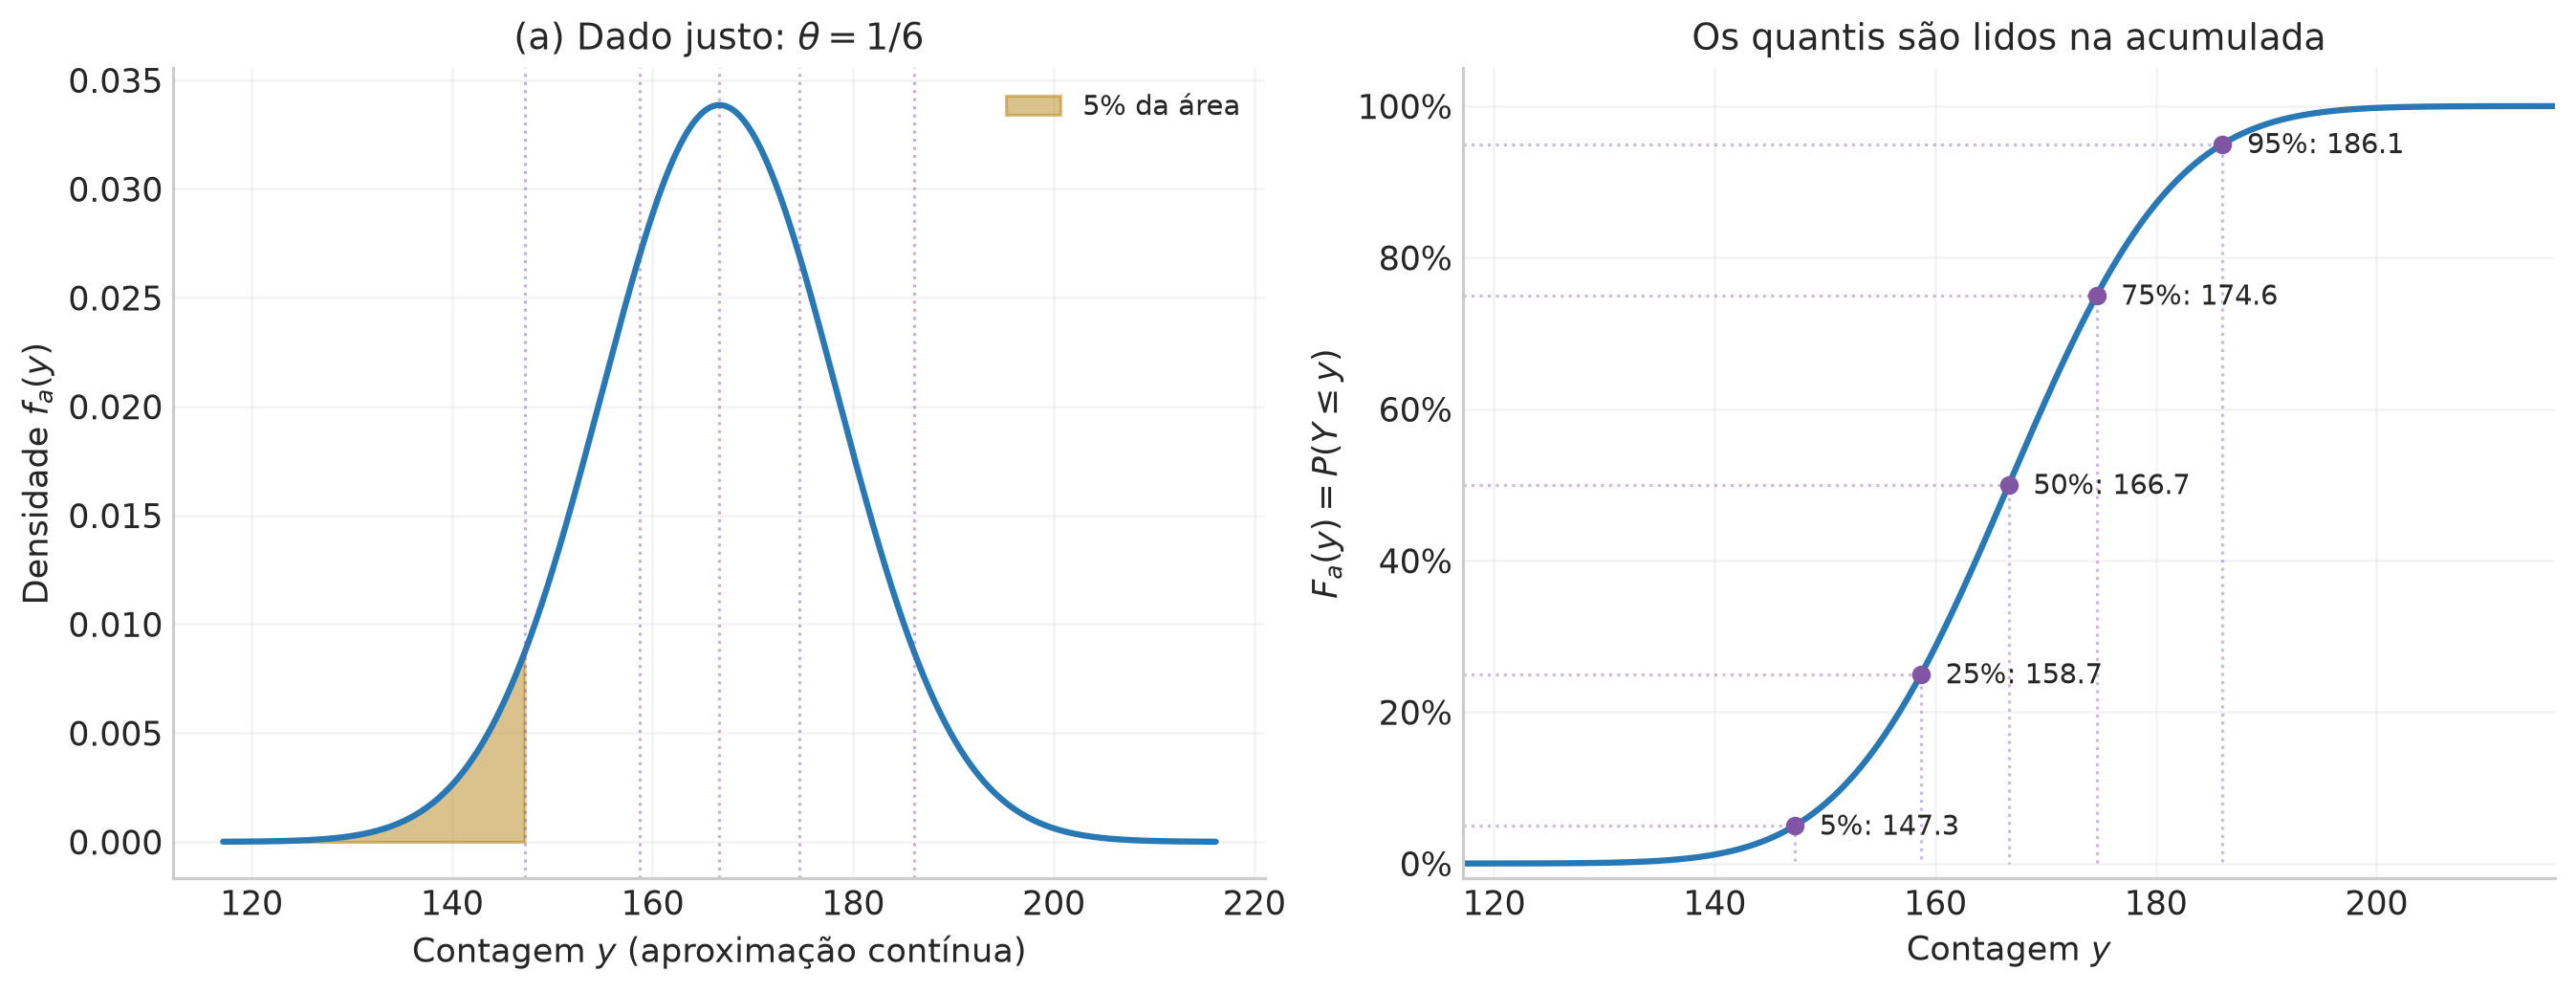

In [3]:
mu_a, sigma_a = mu[1], sigma[1]
qa = norm.ppf(alphas, loc=mu_a, scale=sigma_a)
z_alpha = norm.ppf(alphas)
export_table("q1_a_quantis", ["Acumulada", "z normal", "Quantil (a)"],
             [[label, z, q] for label, z, q in zip(alpha_labels, z_alpha, qa)], [0, 6, 6])

grid_a = np.linspace(mu_a - 4.2*sigma_a, mu_a + 4.2*sigma_a, 1500)
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
axes[0].plot(grid_a, norm.pdf(grid_a, mu_a, sigma_a), color=BLUE)
axes[0].fill_between(grid_a, 0, norm.pdf(grid_a, mu_a, sigma_a),
                     where=grid_a <= qa[0], color=GOLD, alpha=0.5, label="5% da área")
for q in qa:
    axes[0].axvline(q, color=PURPLE, alpha=0.45, lw=1, ls=":")
axes[0].set(xlabel=r"Contagem $y$ (aproximação contínua)", ylabel=r"Densidade $f_a(y)$",
            title=r"(a) Dado justo: $\theta=1/6$")
axes[0].legend(loc="upper right")
axes[1].plot(grid_a, norm.cdf(grid_a, mu_a, sigma_a), color=BLUE)
for q, a, label in zip(qa, alphas, alpha_labels):
    axes[1].plot([grid_a[0], q, q], [a, a, 0], color=PURPLE, alpha=0.4, lw=1, ls=":")
    axes[1].scatter(q, a, color=PURPLE, s=26, zorder=4)
    axes[1].annotate(f"{label}: {q:.1f}", (q, a), xytext=(8, -3), textcoords="offset points", fontsize=9)
axes[1].set(xlabel=r"Contagem $y$", ylabel=r"$F_a(y)=P(Y\leq y)$",
            ylim=(-0.02, 1.05), xlim=(grid_a[0], grid_a[-1]), title="Os quantis são lidos na acumulada")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, "q1_a_distribuicao_quantis")

### Interpretando (a)

A média descreve o centro da distribuição de muitas contagens possíveis. Nenhum experimento produz $166{,}67$ resultados 6; uma contagem real será inteira. Pela aproximação solicitada, encontramos

$$\boxed{q^{(a)}_{5,25,50,75,95\%}\simeq\{147{,}28;\ 158{,}72;\ 166{,}67;\ 174{,}62;\ 186{,}05\}.}$$

Esses limites descrevem resultados do experimento, com a probabilidade de sair 6 já conhecida. Não são limites sobre o parâmetro $\theta$.

## Item (b) · O que significa a prior sobre $\theta$?

Agora não sabemos qual das três possibilidades descreve o dado. Antes de observar a contagem, temos

$$P(\theta=1/8\mid I_b)=0{,}3,\quad
P(\theta=1/6\mid I_b)=0{,}5,\quad
P(\theta=1/4\mid I_b)=0{,}2.$$

Os números $1/8$, $1/6$ e $1/4$ são **probabilidades de sair 6 em um lançamento**, enquanto $0{,}3$, $0{,}5$ e $0{,}2$ são **probabilidades atribuídas às hipóteses sobre esse parâmetro**. São dois níveis diferentes.

A prior é discreta, não contínua, note isso, há apenas 3 hipóteses. Ela atribui 30% de plausibilidade à afirmação “este dado tem chance $1/8$ de produzir um 6”. O enunciado também atribui probabilidade zero a todos os outros valores de $\theta$, por isso temos uma prior discreta.

Para cada hipótese, a distribuição da contagem é uma gaussiana com parâmetros diferentes:

$$f_j(y)=\frac{1}{\sqrt{2\pi}\sigma_j}\exp\!\left[-\frac{(y-\mu_j)^2}{2\sigma_j^2}\right],
\quad\mu_j=N\theta_j,\quad\sigma_j^2=N\theta_j(1-\theta_j).$$

### Marginalização: somar as maneiras de obter a mesma contagem

Os eventos “$Y$ no intervalo $dy$ e $\theta=\theta_j$” são mutuamente exclusivos para diferentes $j$. Pela regra da soma e pela regra do produto,

$$P(Y\in[y,y+dy]\mid I_b)\simeq\sum_j f_j(y)\,dy\,w_j.$$

Portanto,

$$\boxed{f_b(y)=0{,}3\,\mathcal N(y;125,109{,}375)
+0{,}5\,\mathcal N(y;166{,}666\ldots,138{,}888\ldots)
+0{,}2\,\mathcal N(y;250,187{,}5).}$$

Aqui $\mathcal N(y;\mu,v)$ indica uma densidade normal com **variância** $v$. No código, `scale` recebe o **desvio padrão** $\sqrt v$.

A normalização fica explícita:

$$\int_{-\infty}^\infty f_b(y)\,dy
=\sum_j w_j\underbrace{\int_{-\infty}^\infty f_j(y)\,dy}_{1}
=0{,}3+0{,}5+0{,}2=1.$$

O peso de cada componente é sua **área**, não sua altura. Além disso, os máximos da mistura podem se deslocar ligeiramente em relação às médias das componentes, pois suas caudas se sobrepõem.

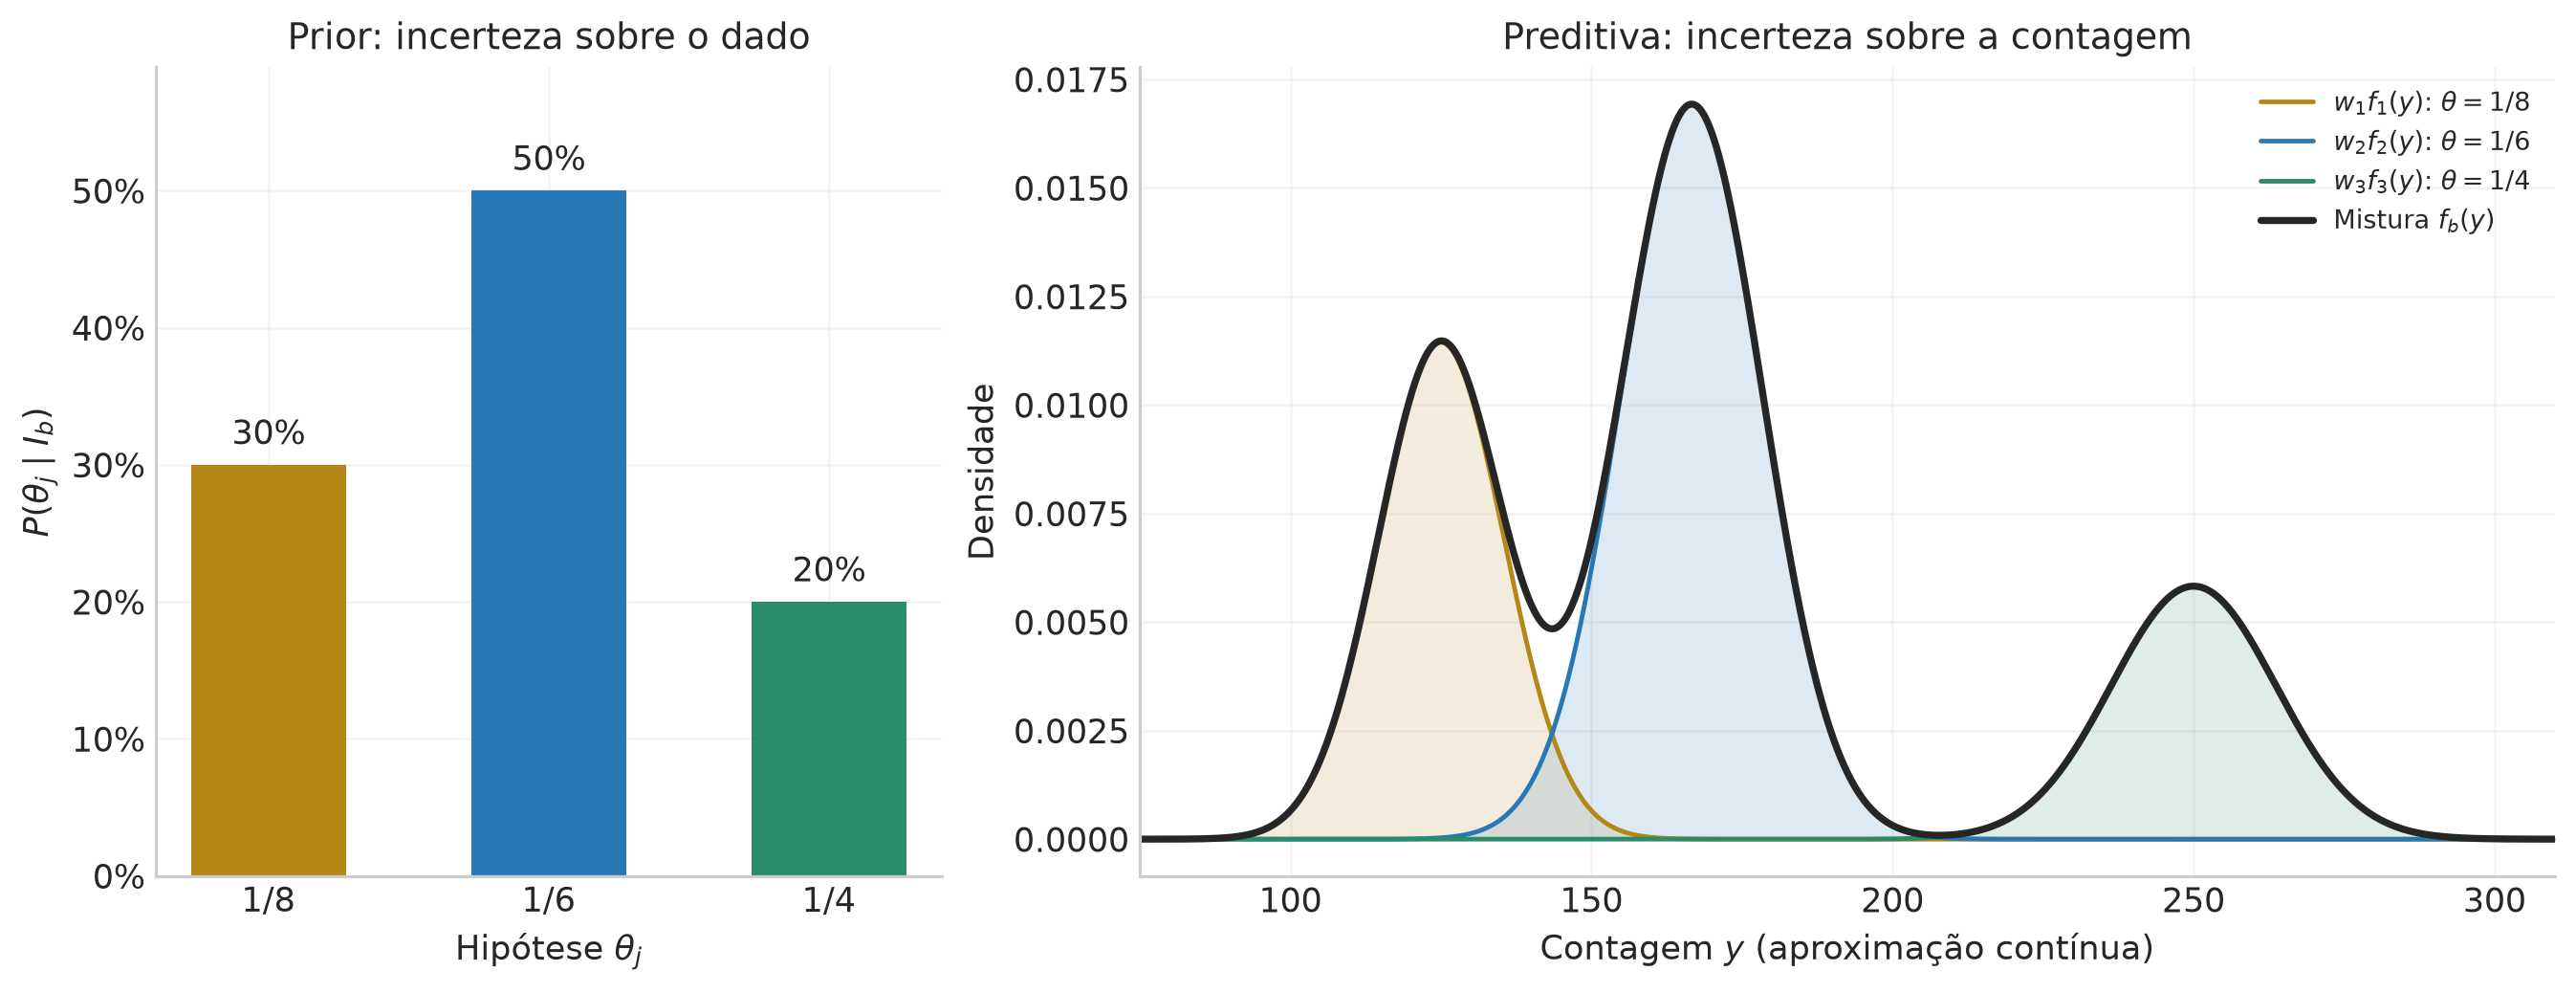

In [4]:
def mixture_pdf(y):
    """Densidade preditiva a priori: soma das três densidades ponderadas."""
    y = np.asarray(y, dtype=float)
    return np.sum(weights * norm.pdf(y[..., None], loc=mu, scale=sigma), axis=-1)

def mixture_cdf(y):
    """CDF da mistura: a integral é linear, então somamos as CDFs ponderadas."""
    y = np.asarray(y, dtype=float)
    return np.sum(weights * norm.cdf(y[..., None], loc=mu, scale=sigma), axis=-1)

grid = np.linspace(75, 310, 2400)
weighted_components = weights * norm.pdf(grid[:, None], loc=mu, scale=sigma)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1.8]})
axes[0].bar(theta_labels, weights, color=COLORS, width=0.55)
for j, w in enumerate(weights):
    axes[0].text(j, w+0.015, f"{w:.0%}", ha="center")
axes[0].set(xlabel=r"Hipótese $\theta_j$", ylabel=r"$P(\theta_j\mid I_b)$",
            ylim=(0, 0.59), title="Prior: incerteza sobre o dado")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
for j, color in enumerate(COLORS):
    axes[1].plot(grid, weighted_components[:, j], color=color, lw=1.5,
                 label=fr"$w_{j+1} f_{j+1}(y)$: $\theta={theta_labels[j][1:-1]}$")
    axes[1].fill_between(grid, 0, weighted_components[:, j], color=color, alpha=0.15)
axes[1].plot(grid, mixture_pdf(grid), color="0.15", lw=2.3, label=r"Mistura $f_b(y)$")
axes[1].set(xlabel=r"Contagem $y$ (aproximação contínua)", ylabel="Densidade",
            title="Preditiva: incerteza sobre a contagem", xlim=(75, 310))
axes[1].legend(loc="upper right", fontsize=8.5)
save_figure(fig, "q1_b_prior_componentes")

### Quantis da mistura: Encontrando CDF para mistura

Podemos integrar componente a componente:

$$F_b(y)=\int_{-\infty}^{y} f_b(u)\,du
=\sum_{j=1}^{3}w_j\Phi\!\left(\frac{y-\mu_j}{\sigma_j}\right).$$

Assim, cada quantil resolve a equação

$$\boxed{0{,}3\Phi\!\left(\frac{q_\alpha-125}{10{,}45825}\right)
+0{,}5\Phi\!\left(\frac{q_\alpha-166{,}66667}{11{,}78511}\right)
+0{,}2\Phi\!\left(\frac{q_\alpha-250}{13{,}69306}\right)=\alpha.}$$

Não podemos calcular o quantil fazendo a média dos quantis individuais: a inversão de uma soma de CDFs não é a soma de suas inversas. Também não podemos usar o quantil de uma única gaussiana com $\theta=\mathbb E[\theta]$.

**Antes do cálculo, podemos prever onde os quantis estarão.** A primeira componente carrega 30% da área e a segunda eleva a área acumulada para aproximadamente 80%. Logo os quantis 5% e 25% devem cair na região da primeira componente; 50% e 75%, na região da segunda; 95%, na terceira. A sobreposição modifica os valores, mas essa leitura fornece uma boa conferência.

Por exemplo, se desprezássemos as caudas das outras componentes no extremo inferior, teríamos $0{,}3\Phi(z)\simeq0{,}05$, ou seja, um quantil $0{,}05/0{,}3$ **dentro da primeira componente**. Para o quantil 50%, já acumulamos quase 0,3 na primeira: $0{,}3+0{,}5\Phi(z)\simeq0{,}5$, portanto $\Phi(z)\simeq0{,}4$ na segunda componente. Isso explica por que a mediana fica abaixo de $166{,}67$.

No código, buscamos a raiz de $g(q)=F_b(q)-\alpha$ com `brentq`: um método que mantém a raiz entre dois extremos. A CDF é contínua e estritamente crescente, e os extremos $0$ e $1000$ abrangem todos os cinco quantis pedidos. Não estamos estimando o quantil pela resolução do gráfico.

| Acumulada | Item (a): gaussiana | Item (b): mistura |
| :-- | :-- | :-- |
| 5% | 147,2819 | 114,8821 |
| 25% | 158,7177 | 134,8765 |
| 50% | 166,6667 | 163,6829 |
| 75% | 174,6156 | 181,7699 |
| 95% | 186,0515 | 259,2358 |

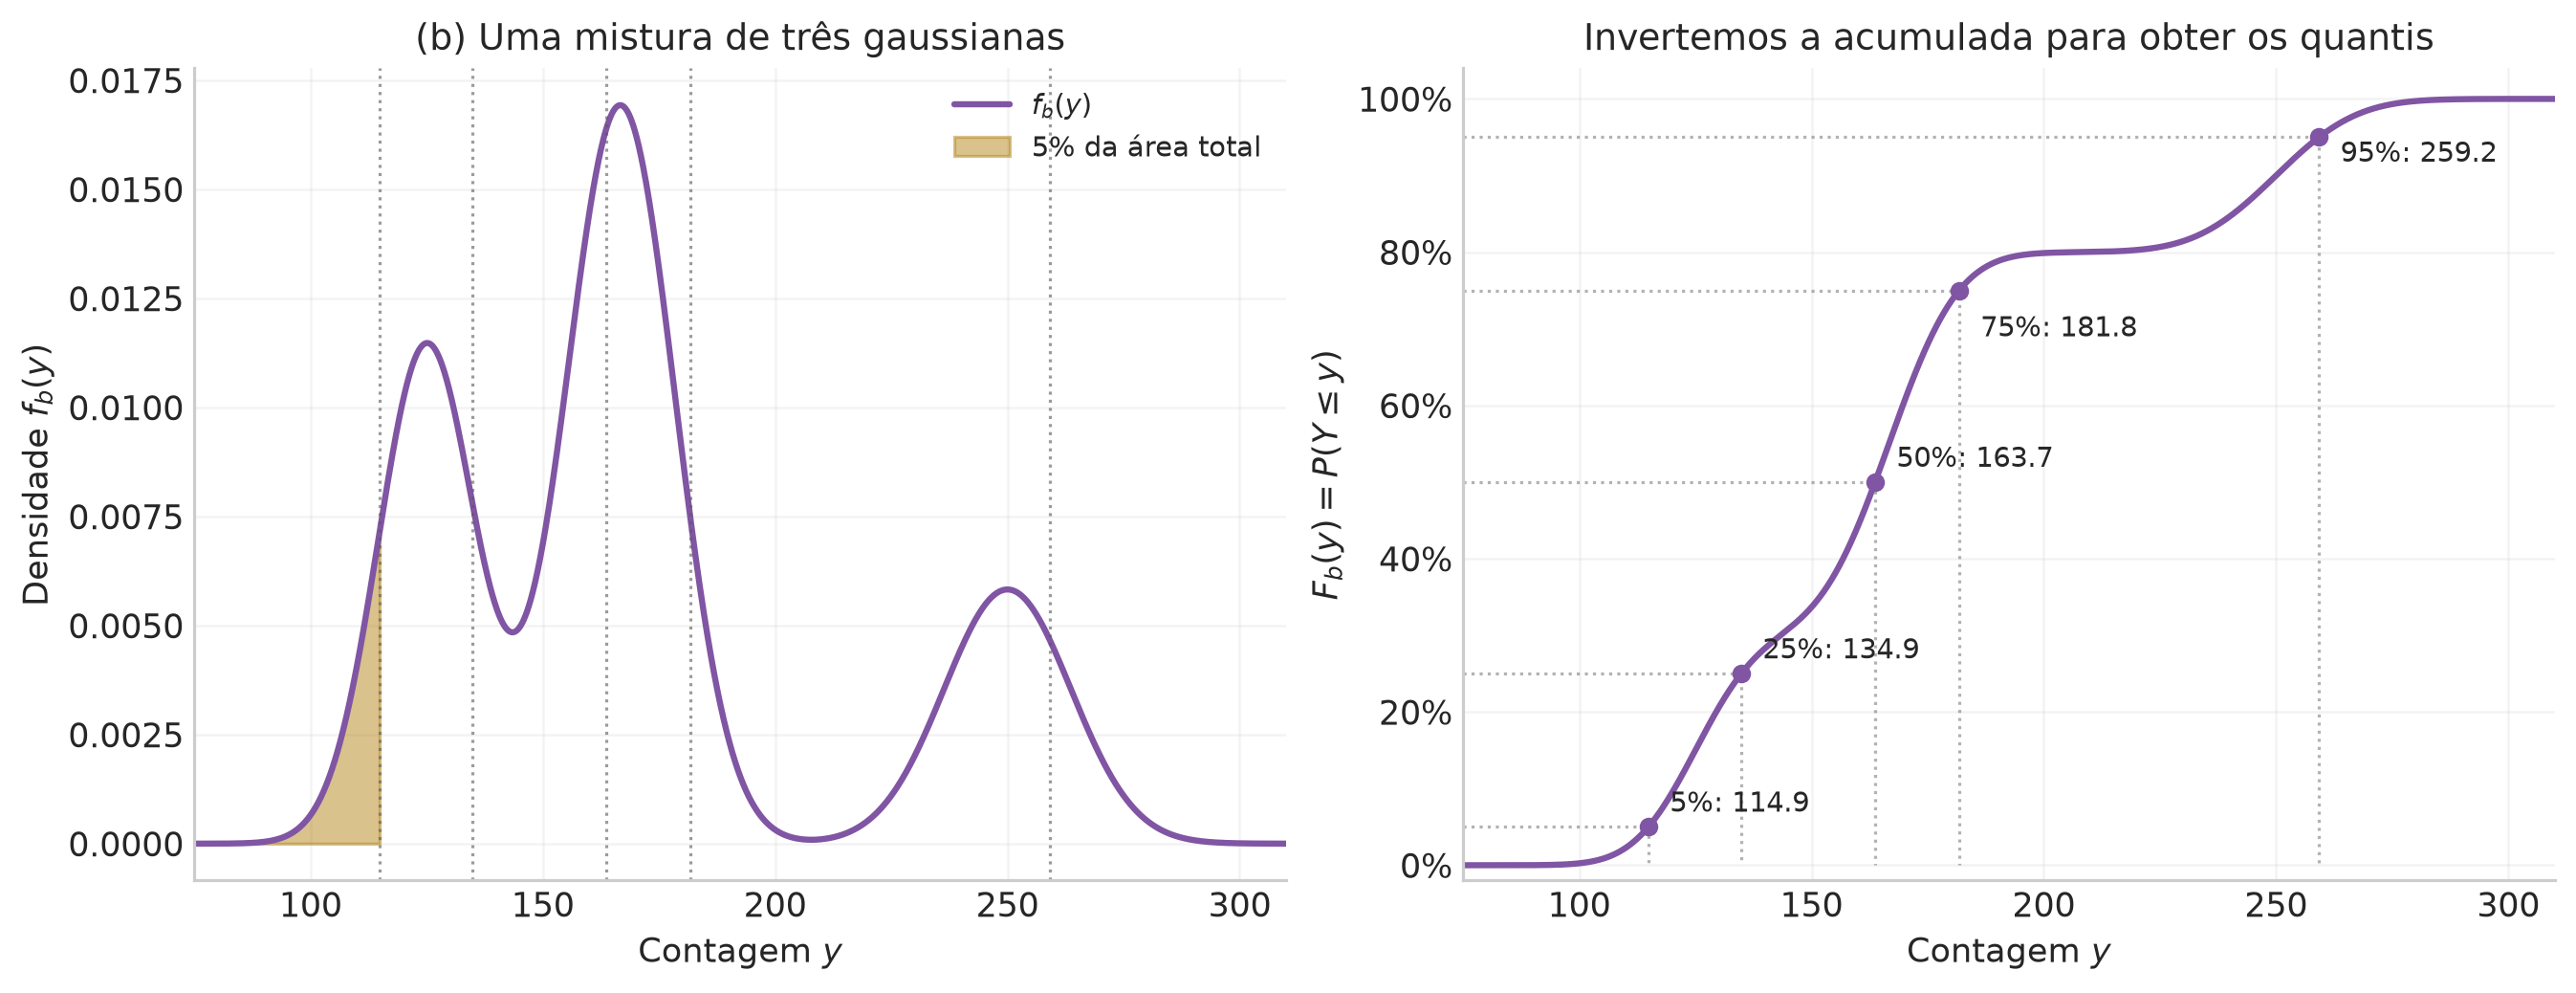

In [5]:
qb = np.array([brentq(lambda q: mixture_cdf(q) - a, 0, N, xtol=1e-11) for a in alphas])
quantile_rows = [[label, a, b] for label, a, b in zip(alpha_labels, qa, qb)]
export_table("q1_quantis_resumo", ["Acumulada", "Item (a): gaussiana", "Item (b): mistura"],
             quantile_rows, [0, 4, 4])

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
axes[0].plot(grid, mixture_pdf(grid), color=PURPLE, label=r"$f_b(y)$")
axes[0].fill_between(grid, 0, mixture_pdf(grid), where=grid <= qb[0],
                     color=GOLD, alpha=0.5, label="5% da área total")
for q in qb:
    axes[0].axvline(q, color="0.35", lw=1, ls=":", alpha=0.6)
axes[0].set(xlabel=r"Contagem $y$", ylabel=r"Densidade $f_b(y)$",
            title="(b) Uma mistura de três gaussianas", xlim=(75, 310))
axes[0].legend(loc="upper right")
axes[1].plot(grid, mixture_cdf(grid), color=PURPLE)
for q, a, label in zip(qb, alphas, alpha_labels):
    axes[1].plot([75, q, q], [a, a, 0], color="0.4", lw=1, ls=":", alpha=0.5)
    axes[1].scatter(q, a, color=PURPLE, s=26, zorder=4)
    axes[1].annotate(f"{label}: {q:.1f}", (q, a), xytext=(7, -15 if a==0.75 else (-8 if a==0.95 else 5)),
                     textcoords="offset points", fontsize=9)
axes[1].set(xlabel=r"Contagem $y$", ylabel=r"$F_b(y)=P(Y\leq y)$",
            ylim=(-0.02, 1.04), xlim=(75, 310), title="Invertemos a acumulada para obter os quantis")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, "q1_b_distribuicao_quantis")

### Interpretando (b)

Os limites pedidos são

$$\boxed{q^{(b)}_{5,25,50,75,95\%}\simeq\{114{,}88;\ 134{,}88;\ 163{,}68;\ 181{,}77;\ 259{,}24\}.}$$

A mediana é aproximadamente $163{,}68$: metade da probabilidade global está abaixo desse valor. Ela difere tanto da média da mistura quanto do centro de cada componente. O quantil 95% fica na terceira componente, apesar de sua prior ser apenas 20%: depois de acumular cerca de 80% nas duas primeiras, precisamos de mais 15 pontos percentuais, ou aproximadamente 75% da terceira.

Entre aproximadamente 210 e 220 ocorrências, a CDF cresce pouco porque a densidade é pequena. Esse comportamento corresponde ao vale entre a segunda e a terceira componentes. As curvas deixam visível uma informação que a média e o desvio padrão, sozinhos, não guardam.

Até aqui fizemos toda a discussão que vai para o overleaf, abaixo estão algumas conferências interessantes desse exercício.


## Conferindo a aproximação com a distribuição exata

A resolução pedida usa a gaussiana. Como conhecemos a binomial de origem, podemos avaliar o tamanho da aproximação sem depender de simulação.

Para (a), a distribuição exata é uma binomial; para (b), é uma **mistura de binomiais**:

$$p_b^{\rm exato}(y)=\sum_jw_j\binom Ny\theta_j^y(1-\theta_j)^{N-y}.$$

Para uma variável discreta, definimos o quantil como

$$q_\alpha^{\rm discreto}=\min\{m\in\{0,\ldots,N\}: F(m)\geq\alpha\}.$$

Não esperamos igualdade exata $F(q_\alpha)=\alpha$, pois a CDF tem saltos. Tampouco arredondar o quantil contínuo garante o quantil discreto correto.

### Massa de probabilidade e correção de continuidade

Para comparar uma **massa discreta** com uma gaussiana, integramos a densidade sobre uma classe de largura 1:

$$P(Y=m\mid\theta)\simeq\int_{m-1/2}^{m+1/2} f_G(u\mid\theta)\,du
=\Phi\!\left(\frac{m+1/2-\mu}{\sigma}\right)-\Phi\!\left(\frac{m-1/2-\mu}{\sigma}\right).$$

Consequentemente, $P(Y\leq m\mid\theta)\simeq\Phi[(m+1/2-\mu)/\sigma]$. Esta é a **correção de continuidade**. Para a mistura, somamos as mesmas expressões com os pesos $w_j$. A comparação abaixo usa áreas gaussianas por classe, em vez de tratar uma densidade pontual como uma probabilidade.

| Acumulada | (a) Gauss. | (a) Exato | (b) Mistura G. | (b) Exato |
| :-- | :-- | :-- | :-- | :-- |
| 5% | 147,2819 | 147 | 114,8821 | 115 |
| 25% | 158,7177 | 159 | 134,8765 | 135 |
| 50% | 166,6667 | 167 | 163,6829 | 164 |
| 75% | 174,6156 | 175 | 181,7699 | 182 |
| 95% | 186,0515 | 186 | 259,2358 | 259 |

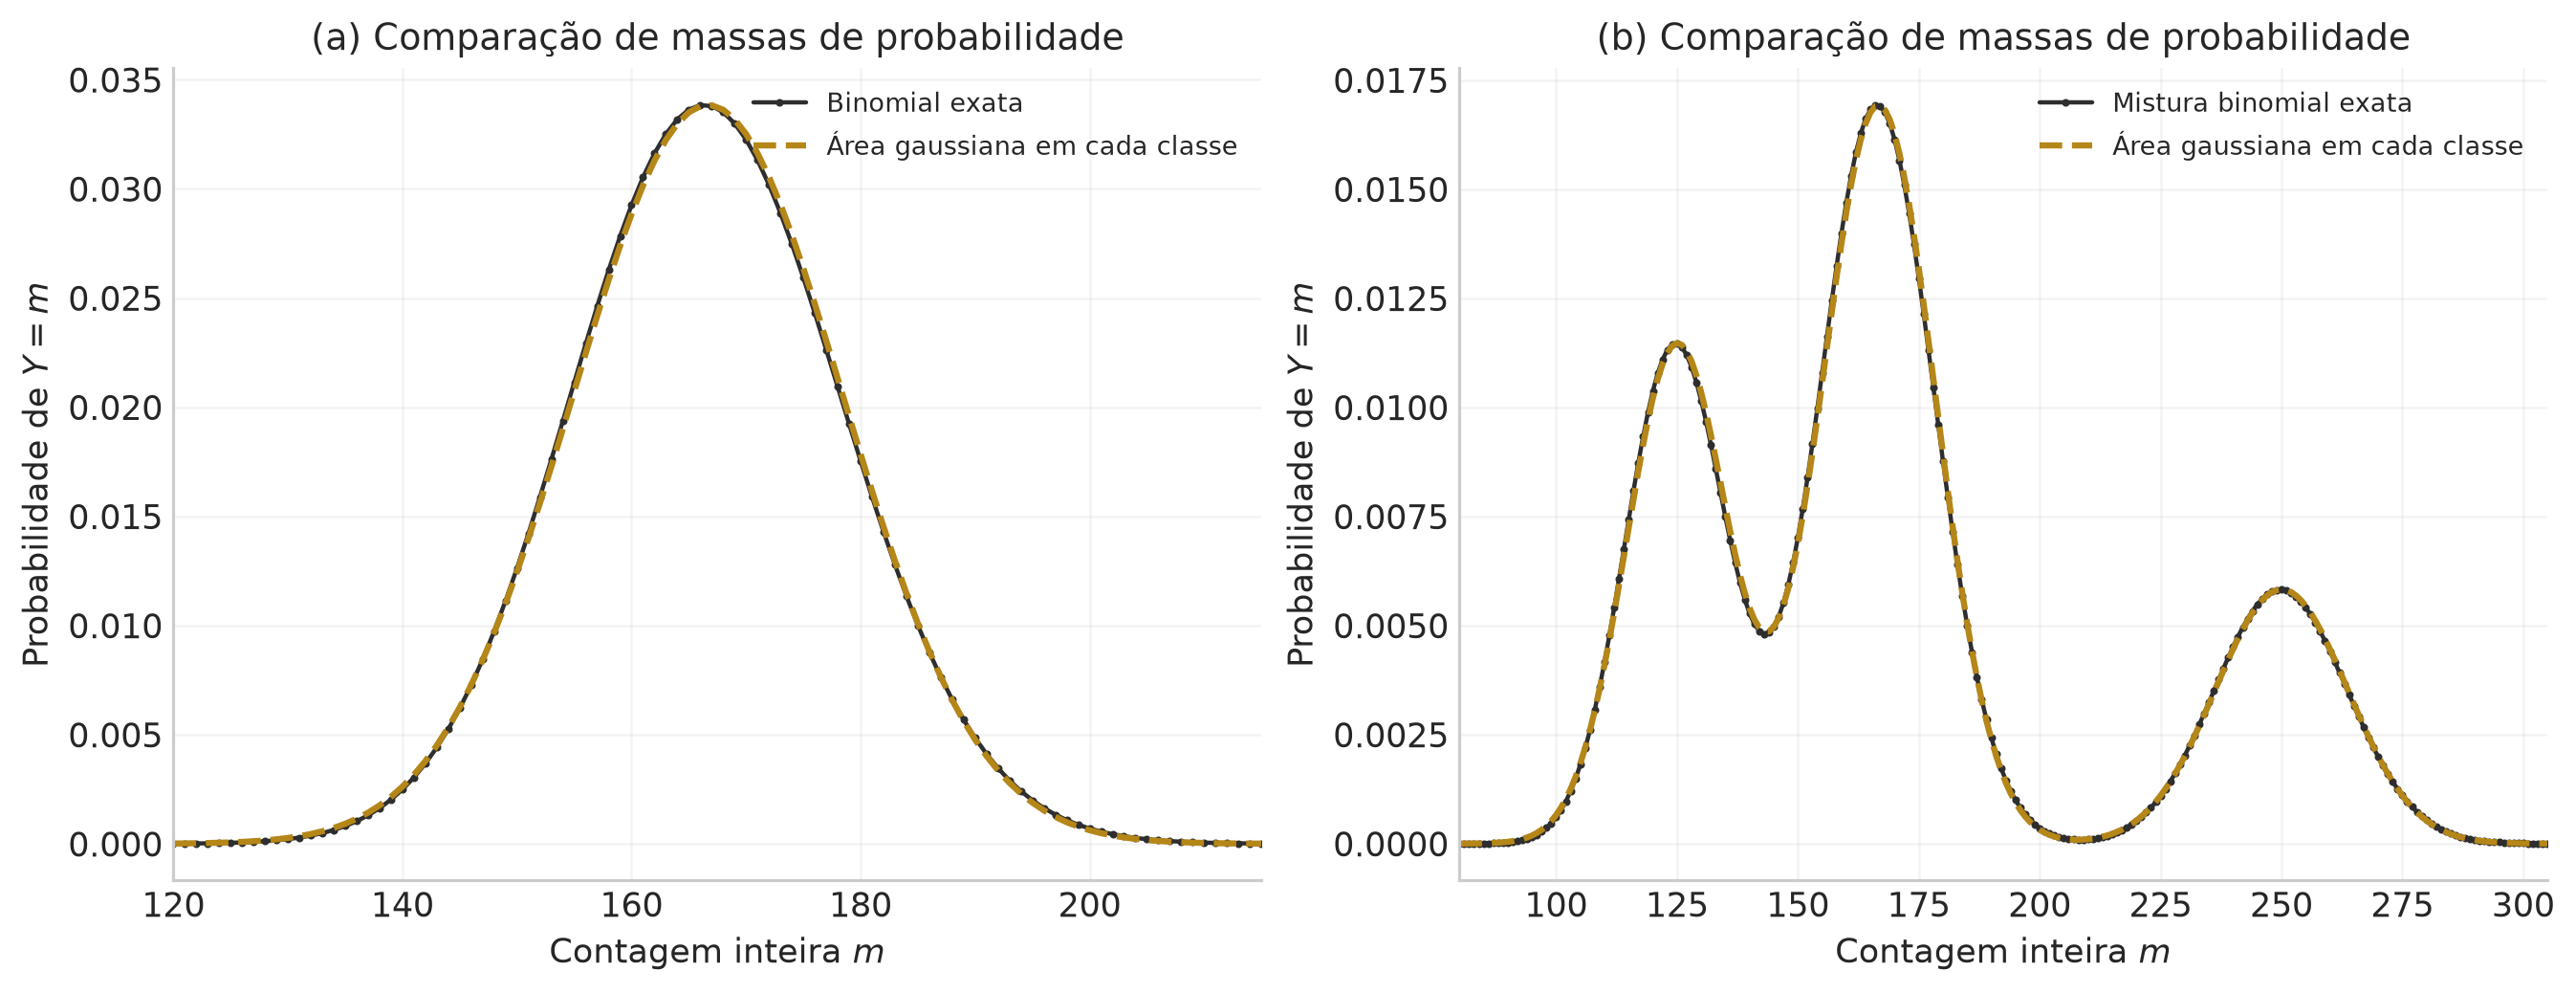

Maior diferença absoluta de CDF, com correção de continuidade: (a) 0.003764; (b) 0.001873


In [6]:
counts = np.arange(N + 1)
exact_a = binom.pmf(counts, N, theta[1])
exact_b = binom.pmf(counts[:, None], N, theta) @ weights
cdf_exact_a, cdf_exact_b = np.cumsum(exact_a), np.cumsum(exact_b)

# Não arredondamos os quantis gaussianos: buscamos a definição discreta diretamente.
qa_exact = counts[np.searchsorted(cdf_exact_a, alphas)]
qb_exact = counts[np.searchsorted(cdf_exact_b, alphas)]
mass_gauss_a = (norm.cdf(counts+0.5, mu_a, sigma_a)
                - norm.cdf(counts-0.5, mu_a, sigma_a))
mass_gauss_b = mixture_cdf(counts+0.5) - mixture_cdf(counts-0.5)

export_table("q1_quantis_exatos", ["Acumulada", "(a) Gauss.", "(a) Exato", "(b) Mistura G.", "(b) Exato"],
             [[label, a, ae, b, be] for label, a, ae, b, be in
              zip(alpha_labels, qa, qa_exact, qb, qb_exact)], [0, 4, 0, 4, 0])

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
for ax, exact, approx, bounds, label in zip(
    axes, [exact_a, exact_b], [mass_gauss_a, mass_gauss_b], [(120, 215), (80, 305)], ["(a)", "(b)"]):
    selection = (counts >= bounds[0]) & (counts <= bounds[1])
    ax.plot(counts[selection], exact[selection], color="0.18", lw=1.4, marker=".", ms=3,
            label="Binomial exata" if label == "(a)" else "Mistura binomial exata")
    ax.plot(counts[selection], approx[selection], color=GOLD, ls="--", lw=2,
            label="Área gaussiana em cada classe")
    ax.set(xlabel=r"Contagem inteira $m$", ylabel=r"Probabilidade de $Y=m$",
            title=f"{label} Comparação de massas de probabilidade", xlim=bounds)
    ax.legend(loc="upper right", fontsize=8.5)
save_figure(fig, "q1_ab_binomial_gaussiana")

err_a = np.max(np.abs(cdf_exact_a - norm.cdf(counts+0.5, mu_a, sigma_a)))
err_b = np.max(np.abs(cdf_exact_b - mixture_cdf(counts+0.5)))
print(f"Maior diferença absoluta de CDF, com correção de continuidade: (a) {err_a:.6f}; (b) {err_b:.6f}")

Os quantis discretos são $\{147,159,167,175,186\}$ em (a) e $\{115,135,164,182,259\}$ em (b). A comparação confirma a precisão adequada da aproximação para este exercício. Ainda assim, a resposta gaussiana e a resposta discreta são objetos diferentes: os números inteiros acima foram calculados pela CDF exata, não por arredondamento.

## Por que não basta substituir $\theta$ por sua média?

No item (b), há duas fontes de dispersão: a flutuação da contagem **para um $\theta$ dado** e a diferença entre as contagens esperadas **para diferentes hipóteses**.

Vamos deduzir a lei da variância total neste caso. Escrevendo $\bar\mu=\sum_jw_j\mu_j$, primeiro somamos as médias condicionais:

$$\mathbb E[Y]=\sum_jw_j\mathbb E[Y\mid\theta_j]=\sum_jw_j\mu_j=N\mathbb E[\theta].$$

Em cada hipótese, $\mathbb E[Y^2\mid\theta_j]=\sigma_j^2+\mu_j^2$. Assim,

$$\begin{aligned}
\operatorname{Var}(Y)
&=\mathbb E[Y^2]-\mathbb E[Y]^2\\
&=\sum_j w_j\sigma_j^2+\sum_jw_j\mu_j^2-\bar\mu^2\\
&=\underbrace{\sum_jw_j\sigma_j^2}_{\mathbb E_\theta[\operatorname{Var}(Y\mid\theta)]}
+\underbrace{\sum_jw_j(\mu_j-\bar\mu)^2}_{\operatorname{Var}_\theta(\mathbb E[Y\mid\theta])}.
\end{aligned}$$

Logo,

$$\boxed{\operatorname{Var}(Y)=N\mathbb E[\theta(1-\theta)]+N^2\operatorname{Var}(\theta).}$$

Com os pesos fornecidos, $\mathbb E[\theta]=41/240\simeq0{,}170833$, então

$$\mathbb E[Y]\simeq170{,}8333,\qquad
\operatorname{Var}(Y)\simeq139{,}7569+1892{,}3611=2032{,}1181,$$
$$\operatorname{sd}(Y)\simeq45{,}0790.$$

Se usássemos uma binomial com $\bar\theta=\mathbb E[\theta]$, sua variância seria somente $N\bar\theta(1-\bar\theta)\simeq141{,}6493$. A diferença pode ser escrita como

$$\operatorname{Var}(Y)-N\bar\theta(1-\bar\theta)=N(N-1)\operatorname{Var}(\theta).$$

**Onde entra a dependência?** Condicionados a $\theta$, os lançamentos são independentes. Depois de marginalizar o parâmetro comum,

$$\mathbb E[X_iX_\ell]=\mathbb E[\theta^2],\qquad
\operatorname{Cov}(X_i,X_\ell)=\mathbb E[\theta^2]-\mathbb E[\theta]^2=\operatorname{Var}(\theta),\quad i\neq\ell.$$

É a incerteza compartilhada sobre o dado que correlaciona nossas previsões. Se sorteássemos um novo $\theta$ independentemente **a cada lançamento**, a contagem seria binomial com parâmetro $\bar\theta$. Esse seria outro protocolo; nesta questão o mesmo $\theta$ vale nos 1000 lançamentos.

Mesmo uma gaussiana com a média **e a variância corretas** da mistura perde seus três picos. Vamos visualizar os dois tipos de simplificação.

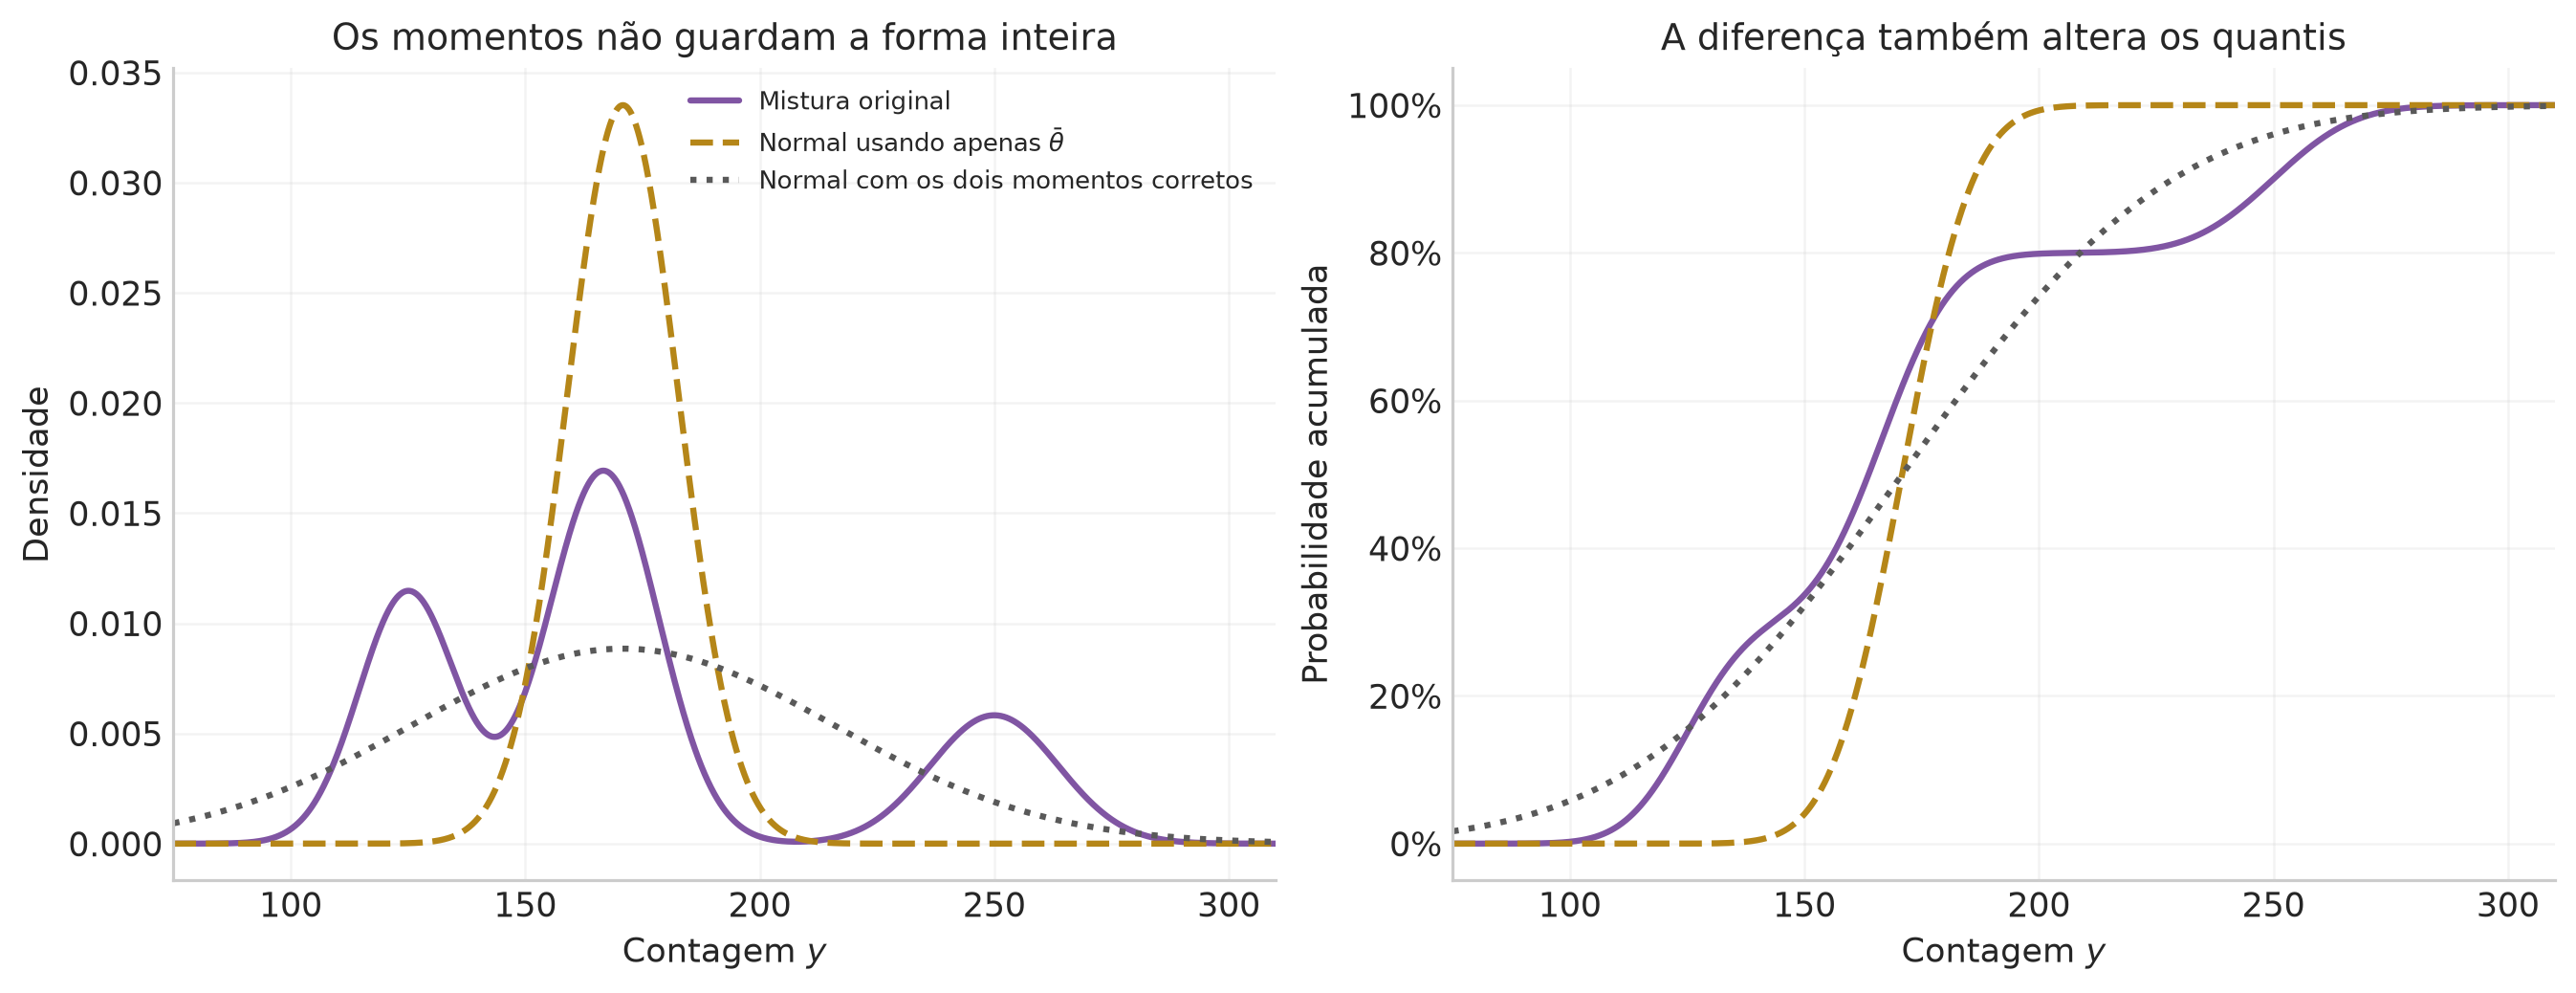

Média = 170.833333; variância interna = 139.756944; entre hipóteses = 1892.361111
Desvio da mistura = 45.079020; desvio ao substituir theta pela média = 11.901651


In [7]:
theta_mean = weights @ theta
mean_b = weights @ mu
var_within = weights @ sigma**2
var_between = weights @ (mu - mean_b)**2
var_b = var_within + var_between
sd_b = np.sqrt(var_b)
sd_plugin = np.sqrt(N * theta_mean * (1-theta_mean))

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
curves = [
    ("Mistura original", mixture_pdf(grid), mixture_cdf(grid), PURPLE, "-"),
    (r"Normal usando apenas $\bar\theta$", norm.pdf(grid, mean_b, sd_plugin),
     norm.cdf(grid, mean_b, sd_plugin), GOLD, "--"),
    ("Normal com os dois momentos corretos", norm.pdf(grid, mean_b, sd_b),
     norm.cdf(grid, mean_b, sd_b), "0.35", ":"),
]
for label, density, cdf, color, style in curves:
    axes[0].plot(grid, density, label=label, color=color, ls=style)
    axes[1].plot(grid, cdf, label=label, color=color, ls=style)
axes[0].set(xlabel=r"Contagem $y$", ylabel="Densidade", title="Os momentos não guardam a forma inteira")
axes[1].set(xlabel=r"Contagem $y$", ylabel="Probabilidade acumulada", title="A diferença também altera os quantis")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:
    ax.set_xlim(75, 310)
axes[0].legend(loc="upper right", fontsize=8)
save_figure(fig, "q1_b_mistura_momentos")
print(f"Média = {mean_b:.6f}; variância interna = {var_within:.6f}; entre hipóteses = {var_between:.6f}")
print(f"Desvio da mistura = {sd_b:.6f}; desvio ao substituir theta pela média = {sd_plugin:.6f}")

# Questão 2 · Farol: Item (a) construir a likelihood; Item (b) inferir a posição

Temos um farol em uma pequena ilha, a uma distância conhecida ou desconhecida de uma costa retilínea. Pulsos breves chegam a detectores ao longo da costa; cada pulso registrado fornece uma posição $x_i$, mas não fornece a direção de emissão.

No **item (a)** queremos construir a distribuição dessas posições medidas conhecendo a localização do farol. No **item (b)** conhecemos a distância perpendicular, $y_{\rm farol}=1\,\mathrm{km}$, e usamos três conjuntos de posições para inferir a coordenada do farol ao longo da costa, ou seja, sua posição $x_{\text{farol}}$

Vou separar o problema em duas perguntas: **como uma direção de emissão produz uma posição de chegada?** E, depois, **quais posições do farol explicam as chegadas observadas?** A primeira constrói a likelihood; a segunda usa Bayes, que iremos utilizar no item $

### Notação e hipóteses

| Símbolo | Significado |
|:--|:--|
| $a\equiv x_{\rm farol}$ | Coordenada do ponto da costa mais próximo do farol; parâmetro de localização |
| $b\equiv y_{\rm farol}>0$ | Distância perpendicular entre o farol e a costa; parâmetro de escala |
| $(a,b)$ | Posição do farol em um plano cuja costa é $y=0$ |
| $\alpha_i$ | Ângulo do pulso $i$ com a perpendicular orientada do farol para a costa |
| $X_i$ e $x_i$ | Posição de chegada antes da observação e seu valor registrado |
| $D=\{x_1,\ldots,x_N\}$ | Uma amostra com $N$ pulsos detectados |
| $I$ | Modelo geométrico, emissão e condições de seleção dos pulsos |

Precisamos tornar explícitas as hipóteses que permitem a distribuição pedida:

1. Trabalhamos no plano do desenho. A costa é uma linha reta idealmente extensa; a cobertura é efetivamente contínua ou densa, com eficiência uniforme ao longo dela. Tratamos os registros como posições contínuas.
2. As direções de emissão são **uniformes em ângulo**. “Direções arbitrárias” sozinho não determina uma distribuição; a uniformidade é a hipótese de ausência de direção privilegiada usada nesta construção.
3. Condicionamos nos pulsos que atingem a costa. Seus ângulos ficam em $(-\pi/2,\pi/2)$, medidos a partir da normal voltada para a costa.
4. Dada a posição fixa do farol, as direções dos diferentes pulsos são independentes. O pulso curto não produz vários registros do mesmo evento. Não inferimos aqui uma taxa de emissão a partir de $N$.
5. No item (b), $b=1\,\mathrm{km}$ é exato e os erros das posições são desprezíveis. A grande dispersão em $x$ vem da geometria, e não de um erro instrumental gaussiano.

A ilustração geométrica foi gerada **fora do notebook**, pelo script independente entregue na pasta `scripts/`. Os gráficos e cálculos abaixo não dependem desse arquivo externo.

### Item (a) · Da emissão angular à Lorentziana

**Primeiro, de onde vem a distribuição angular?** Se a emissão é uniforme no círculo completo, cada intervalo angular de tamanho $d\alpha$ tem probabilidade $d\alpha/(2\pi)$. Metade das direções aponta para a costa. Condicionando nessa metade,

$$p(\alpha\mid\text{atingiu a costa},I)
=\frac{1/(2\pi)}{1/2}=\frac1\pi,
\qquad -\frac\pi2<\alpha<\frac\pi2.$$

O intervalo angular é aberto: uma direção exatamente paralela à costa não a encontra em uma posição finita e tem probabilidade zero nesse modelo contínuo.

**Depois, usamos a geometria.** O triângulo retângulo formado pelo raio tem cateto perpendicular $b$ e deslocamento ao longo da costa $x-a$. Portanto,

$$\tan\alpha=\frac{x-a}{b},\qquad
\boxed{x=a+b\tan\alpha.}$$

Um ângulo negativo chega à esquerda de $a$; um positivo, à direita. A transformação é monótona e leva $(-\pi/2,\pi/2)$ em toda a reta. Não há soma de ramos, como havia no exemplo $X^2$ do capítulo 4.

**Por fim, conservamos a probabilidade.** A chance de o ângulo cair em $[\alpha,\alpha+d\alpha]$ é a mesma de sua posição de chegada cair no intervalo correspondente:

$$f_X(x\mid a,b,I)\,dx=p_\alpha(\alpha\mid I)\,|d\alpha|.$$

Invertendo a relação geométrica e calculando o jacobiano,

$$\alpha(x)=\arctan\!\left(\frac{x-a}{b}\right),$$
$$\left|\frac{d\alpha}{dx}\right|
=\frac{1}{1+[(x-a)/b]^2}\frac1b
=\frac{b}{b^2+(x-a)^2}.$$

Assim,

$$\boxed{f_X(x\mid a,b,I)=\frac{1}{\pi}\frac{b}{(x-a)^2+b^2},\qquad x\in\mathbb R,\ b>0.}$$

Esta é a **Lorentziana normalizada**, também chamada de distribuição de **Cauchy**, com localização $a$ e escala $b$. A notação do enunciado, $p(x_i\mid y_{\rm farol},x_{\rm farol},I)$, refere-se a esta densidade. Sua unidade é $\mathrm{km}^{-1}$ quando as posições são expressas em quilômetros.

A mesma expressão tem duas leituras: para $a,b$ fixos é uma distribuição dos dados possíveis; depois de observar $x_i$, é a likelihood dos parâmetros. Ainda não calculamos uma posterior sobre o farol.

### Normalização, acumulada e significado da escala

Fazendo $u=(x-a)/b$, com $dx=b\,du$, conferimos

$$\int_{-\infty}^\infty f_X(x\mid a,b)\,dx
=\frac1\pi\int_{-\infty}^\infty\frac{du}{1+u^2}
=\frac1\pi[\arctan u]_{-\infty}^{\infty}=1.$$

Integrando somente até $x$, obtemos a CDF e sua inversa:

$$F_X(x\mid a,b)=\frac12+\frac1\pi\arctan\!\left(\frac{x-a}{b}\right),$$
$$\boxed{q_p=a+b\tan[\pi(p-1/2)],\qquad0<p<1.}$$

O centro $a$ é a **moda e a mediana** da distribuição. Os quartis são $a-b$ e $a+b$: metade da probabilidade está a uma distância de até $b$ de $a$. O pico é $1/(\pi b)$ e a largura à meia altura é $2b$, pois $f(a\pm b)=f(a)/2$. **$b$ não é um desvio padrão.**

Por quê? Nas caudas, $f(x)\sim b/(\pi x^2)$. A parte positiva do primeiro momento em torno de $a$ diverge:

$$\int_a^\infty(x-a)f(x)\,dx
=\frac{b}{2\pi}\left[\log(b^2+t^2)\right]_{t=0}^{\infty}=\infty,\quad t=x-a.$$

A parte negativa também diverge em módulo. Logo a média usual não existe: o cancelamento obtido com limites simétricos é um **valor principal**, não uma esperança bem definida. O segundo momento também diverge. Não devemos atribuir média $a$ ou variância $b^2$ à Cauchy.

Isso tem uma leitura física: ângulos próximos de $\pm\pi/2$ são quase paralelos à costa e chegam muito longe do ponto mais próximo. Esses registros extremos são permitidos pelo próprio modelo. A probabilidade de estar fora de uma faixa central é

$$P(|X-a|>r)=1-\frac2\pi\arctan(r/b)
\sim\frac{2b}{\pi r}\quad(r\gg b).$$

Vamos visualizar a densidade e comparar essa cauda com a de uma normal de escala $\sigma=b$. Essa comparação **não** iguala variâncias: a variância da Lorentziana não existe.

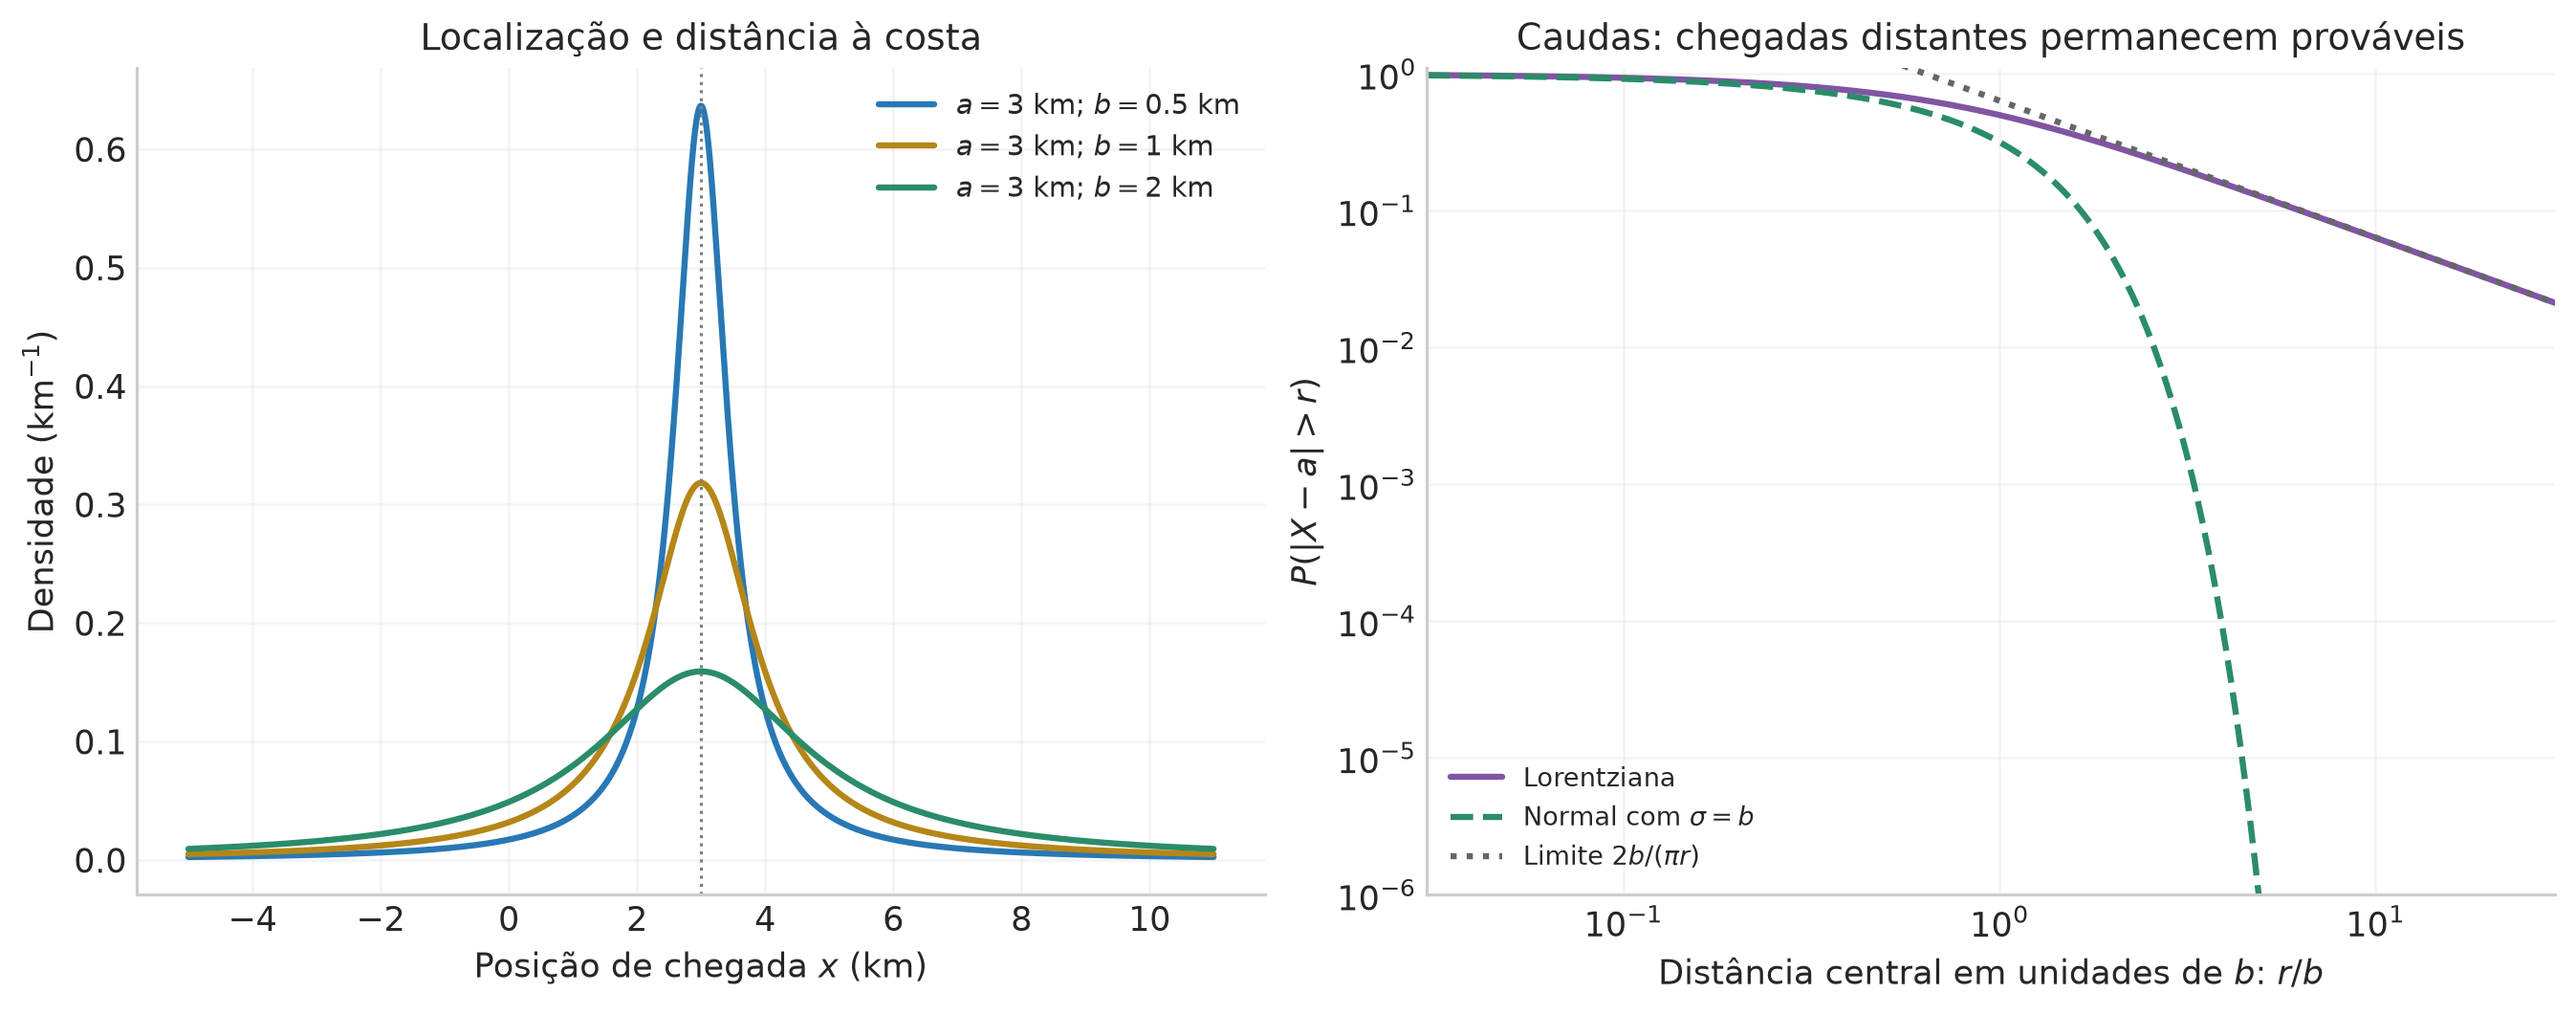

In [8]:
# Imports adicionais; as rotinas de exportação já foram definidas no início do notebook.
from scipy.stats import cauchy
from scipy.integrate import trapezoid
from scipy.optimize import minimize_scalar

def q2_cauchy_pdf(x, a, b):
    """Distribuição das posições de chegada, deduzida pela transformação angular."""
    if b <= 0:
        raise ValueError("A distância perpendicular b deve ser positiva.")
    return 1 / (np.pi*b*(1 + ((np.asarray(x)-a)/b)**2))

q2_xgrid = np.linspace(-5, 11, 3000)
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.5), layout="constrained")
for scale, color in zip([0.5, 1, 2], [BLUE, GOLD, GREEN]):
    axes[0].plot(q2_xgrid, q2_cauchy_pdf(q2_xgrid, 3, scale), color=color,
                 label=fr"$a=3$ km; $b={scale:g}$ km")
axes[0].axvline(3, color="0.5", ls=":", lw=1)
axes[0].set(xlabel=r"Posição de chegada $x$ (km)", ylabel=r"Densidade (km$^{-1}$)",
            title="Localização e distância à costa")
axes[0].legend(loc="upper right")
q2_r = np.geomspace(0.03, 30, 1200)
# arctan(1/r) evita subtrair dois números quase iguais na cauda.
axes[1].loglog(q2_r, 2/np.pi*np.arctan(1/q2_r), color=PURPLE, label="Lorentziana")
axes[1].loglog(q2_r, 2*norm.sf(q2_r), color=GREEN, ls="--", label=r"Normal com $\sigma=b$")
axes[1].loglog(q2_r, 2/(np.pi*q2_r), color="0.4", ls=":", label=r"Limite $2b/(\pi r)$")
axes[1].set(xlabel=r"Distância central em unidades de $b$: $r/b$",
            ylabel=r"$P(|X-a|>r)$", ylim=(1e-6, 1.1), xlim=(0.03, 30),
            title="Caudas: chegadas distantes permanecem prováveis")
axes[1].legend(loc="lower left", fontsize=8.5)
save_figure(fig, "q2_a_lorentziana")

### Uma conferência pela própria geometria

Podemos gerar posições de duas maneiras: amostrar diretamente uma Cauchy ou amostrar ângulos uniformes e usar $X=a+b\tan\alpha$. Vamos usar a segunda maneira, pois ela testa a interpretação geométrica sem chamar um gerador de Cauchy.

Tomamos $a=3\,\mathrm{km}$ e $b=1\,\mathrm{km}$ apenas para essa simulação. O histograma usa uma janela finita para tornar o pico visível, mas cada classe é dividida pelo **total de pulsos simulados**, incluindo os que ficaram fora da janela. Usar `density=True` em um histograma truncado renormalizaria somente os registros exibidos e inflaria a altura do pico. A densidade teórica é normalizada em toda a reta.

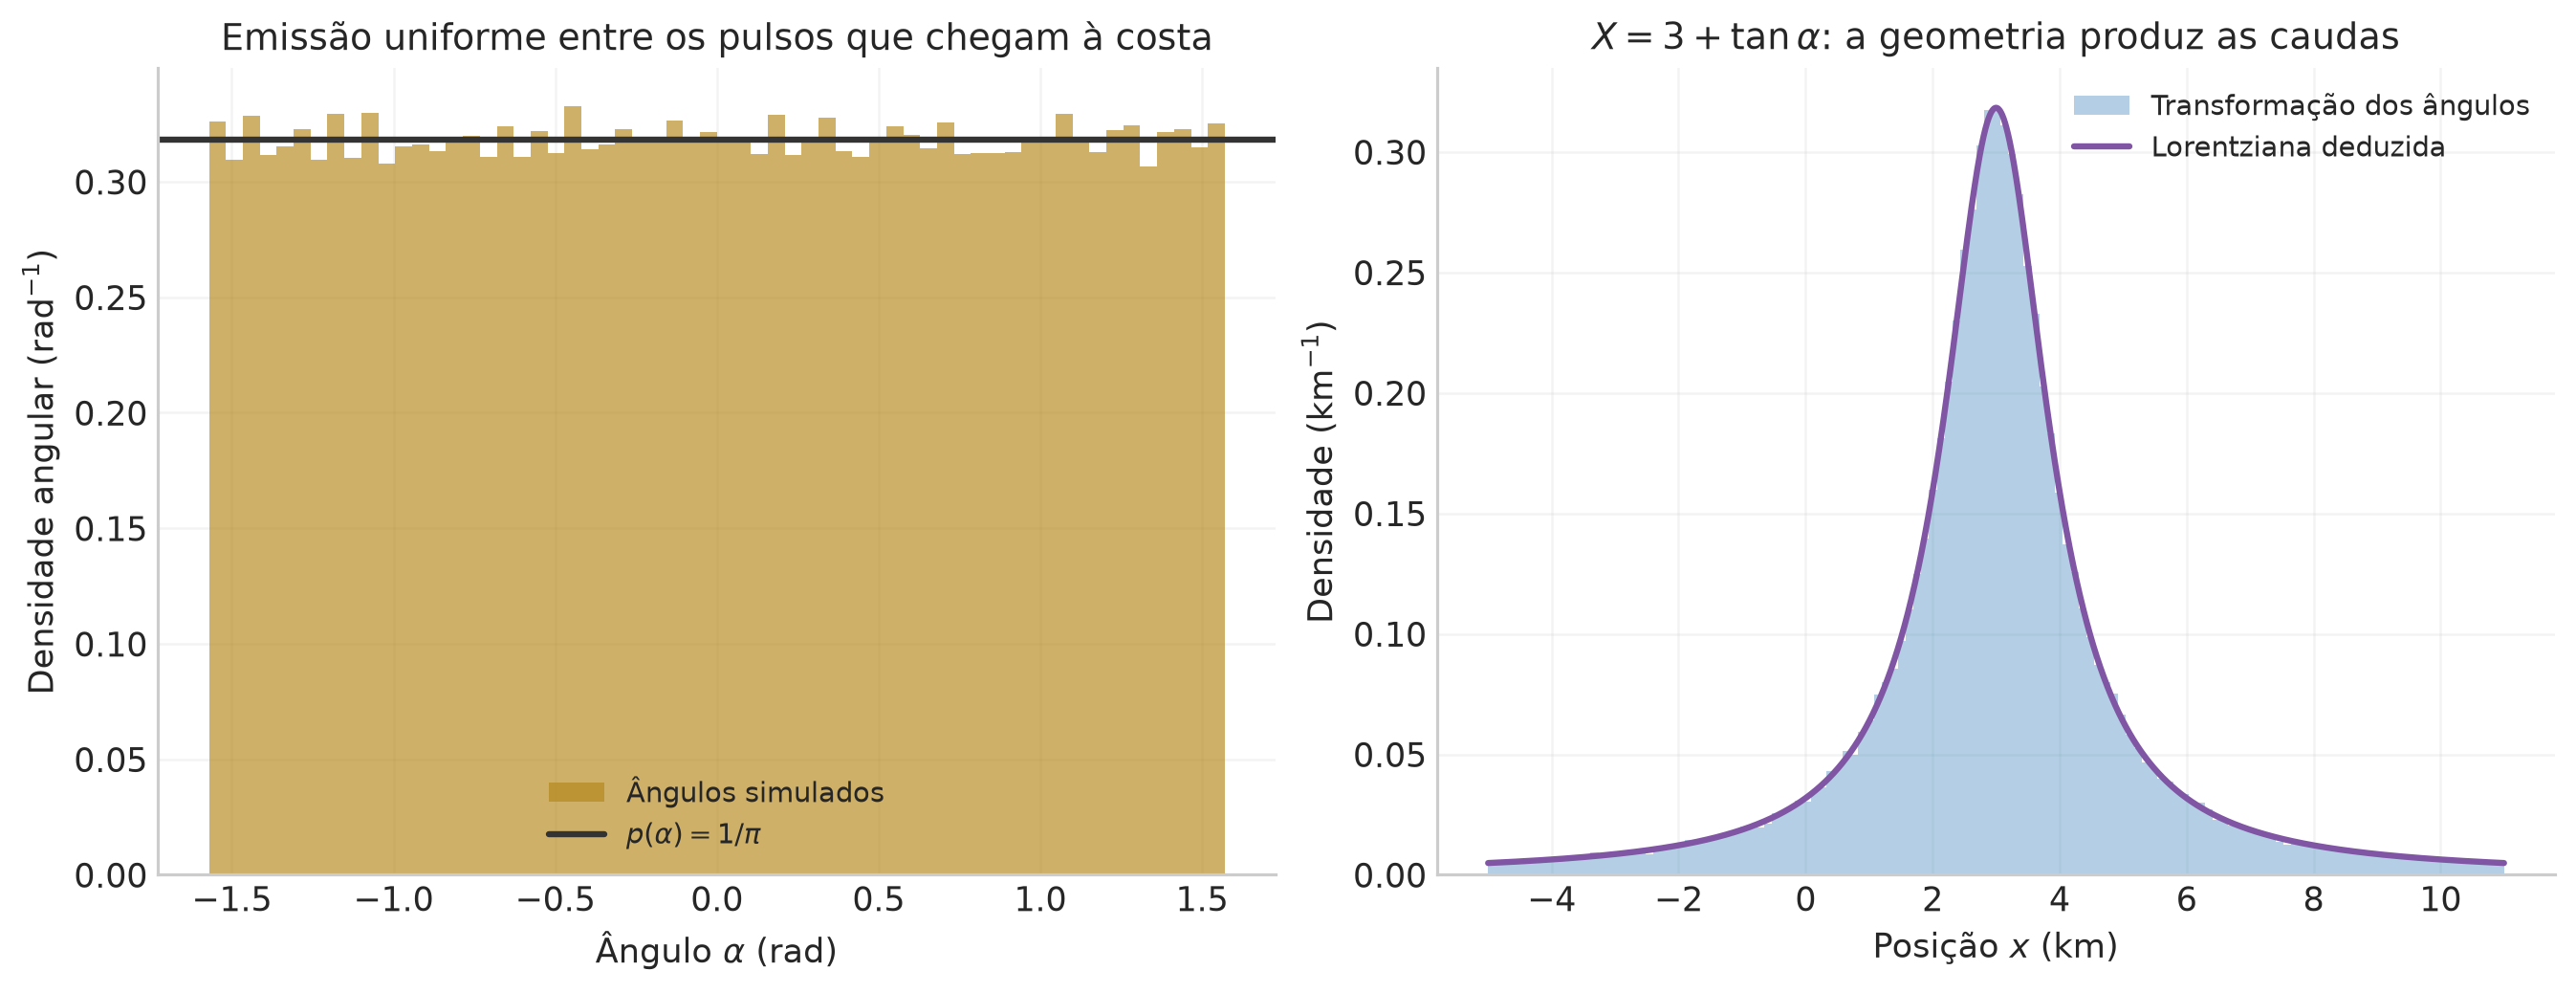

Fração dos pulsos na janela desenhada: 0.9205


In [9]:
q2_rng = np.random.default_rng(20261023)
q2_m = 200_000
q2_angles = q2_rng.uniform(-np.pi/2, np.pi/2, size=q2_m)
q2_sim_x = 3 + np.tan(q2_angles)
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
axes[0].hist(q2_angles, bins=60, density=True, color=GOLD, alpha=0.65, label="Ângulos simulados")
axes[0].axhline(1/np.pi, color="0.2", label=r"$p(\alpha)=1/\pi$")
axes[0].set(xlabel=r"Ângulo $\alpha$ (rad)", ylabel=r"Densidade angular (rad$^{-1}$)",
            title="Emissão uniforme entre os pulsos que chegam à costa")
axes[0].legend(loc="lower center")
q2_bins = np.linspace(-5, 11, 130)
q2_hist, _ = np.histogram(q2_sim_x, bins=q2_bins)
axes[1].stairs(q2_hist/(q2_m*np.diff(q2_bins)), q2_bins, color=BLUE,
               fill=True, alpha=0.35, label="Transformação dos ângulos")
axes[1].plot(q2_xgrid, q2_cauchy_pdf(q2_xgrid, 3, 1), color=PURPLE, label="Lorentziana deduzida")
axes[1].set(xlabel=r"Posição $x$ (km)", ylabel=r"Densidade (km$^{-1}$)",
            title=r"$X=3+\tan\alpha$: a geometria produz as caudas")
axes[1].legend(loc="upper right")
save_figure(fig, "q2_a_simulacao_angular")
print(f"Fração dos pulsos na janela desenhada: {np.mean((q2_sim_x>=-5)&(q2_sim_x<=11)):.4f}")

## Item (b) · Construindo a posterior da posição do farol

Agora $b=1\,\mathrm{km}$ é conhecido. Os valores $x_i$ são posições de **pulsos diferentes** medidas, que chegam a costa, desconhecemos a posição horizontal do farol. Para uma amostra $D$, a independência condicional de cada pulso permite apenas multiplicar as Likelihoods encotnradas no item anterior, que resulta em:

$$L(a;D,b)=\prod_{i=1}^N f_X(x_i\mid a,b)
=\left(\frac{b}{\pi}\right)^N\prod_{i=1}^N\frac{1}{b^2+(x_i-a)^2}.$$

Se os dados forem tratados como um conjunto sem ordem, pode surgir um fator combinatório que não depende de $a$; ele cancela na posterior ao considerarmos a evidência, por isso não vou colocá-lo aqui. 

### Precisamos de uma prior

O enunciado não especifica uma prior para $a$. Vou adotar a escolha uniforme de localização, por ser um parâmetro de posição, como discutido em sala, a prior uniforme é melhor nesse caso

$$\pi(a)\propto1,\qquad a\in\mathbb R.$$

Ela expressa invariância por translação: mudar a origem do eixo não deve privilegiar uma posição. É uma **prior imprópria**, porque sua integral na reta não é finita. Ainda assim, podemos obter uma posterior própria:

$$\boxed{p(a\mid D,b,I)=\frac{L(a;D,b)}{\int_{-\infty}^{\infty}L(u;D,b)\,du}.}$$

Para $|a|$ grande, $L(a)\propto|a|^{-2N}$, então a integral converge para $N\geq1$. A constante arbitrária da prior cancela na posterior; uma evidência absoluta para comparação de modelos não fica definida por essa escolha. Também vamos conferir o efeito de uma prior uniforme própria em intervalos amplos.

Aqui a prior é sobre a **coordenada do farol**, não sobre os dados. Permitir um registro em $x=-73{,}5\,\mathrm{km}$ não exige que a prior de $a$ inclua esse valor: um farol perto de $a=3$ também pode produzir uma chegada muito distante.

### O que chamaremos de posição determinada?

Usaremos como estimativa pontual a **moda da posterior**, ou MAP. Com esta prior uniforme, ela também maximiza a likelihood. Reportaremos ainda a mediana e a média posteriores e um **intervalo de credibilidade central de 95%**, definido pelos quantis 2,5% e 97,5%. A estimativa pontual não substitui a posterior inteira.

Condicionados ao modelo, à prior e aos dados observados, podemos atribuir 95% de probabilidade posterior a esse intervalo de $a$. Esta é a interpretação bayesiana. No capítulo 6, a cobertura de um intervalo de confiança se referia a possíveis repetições do experimento; são afirmações diferentes.

Tamanhos das amostras: {'(i)': 7, '(ii)': 29, '(iii)': 64}
Unidade de todas as posições e de b: km.


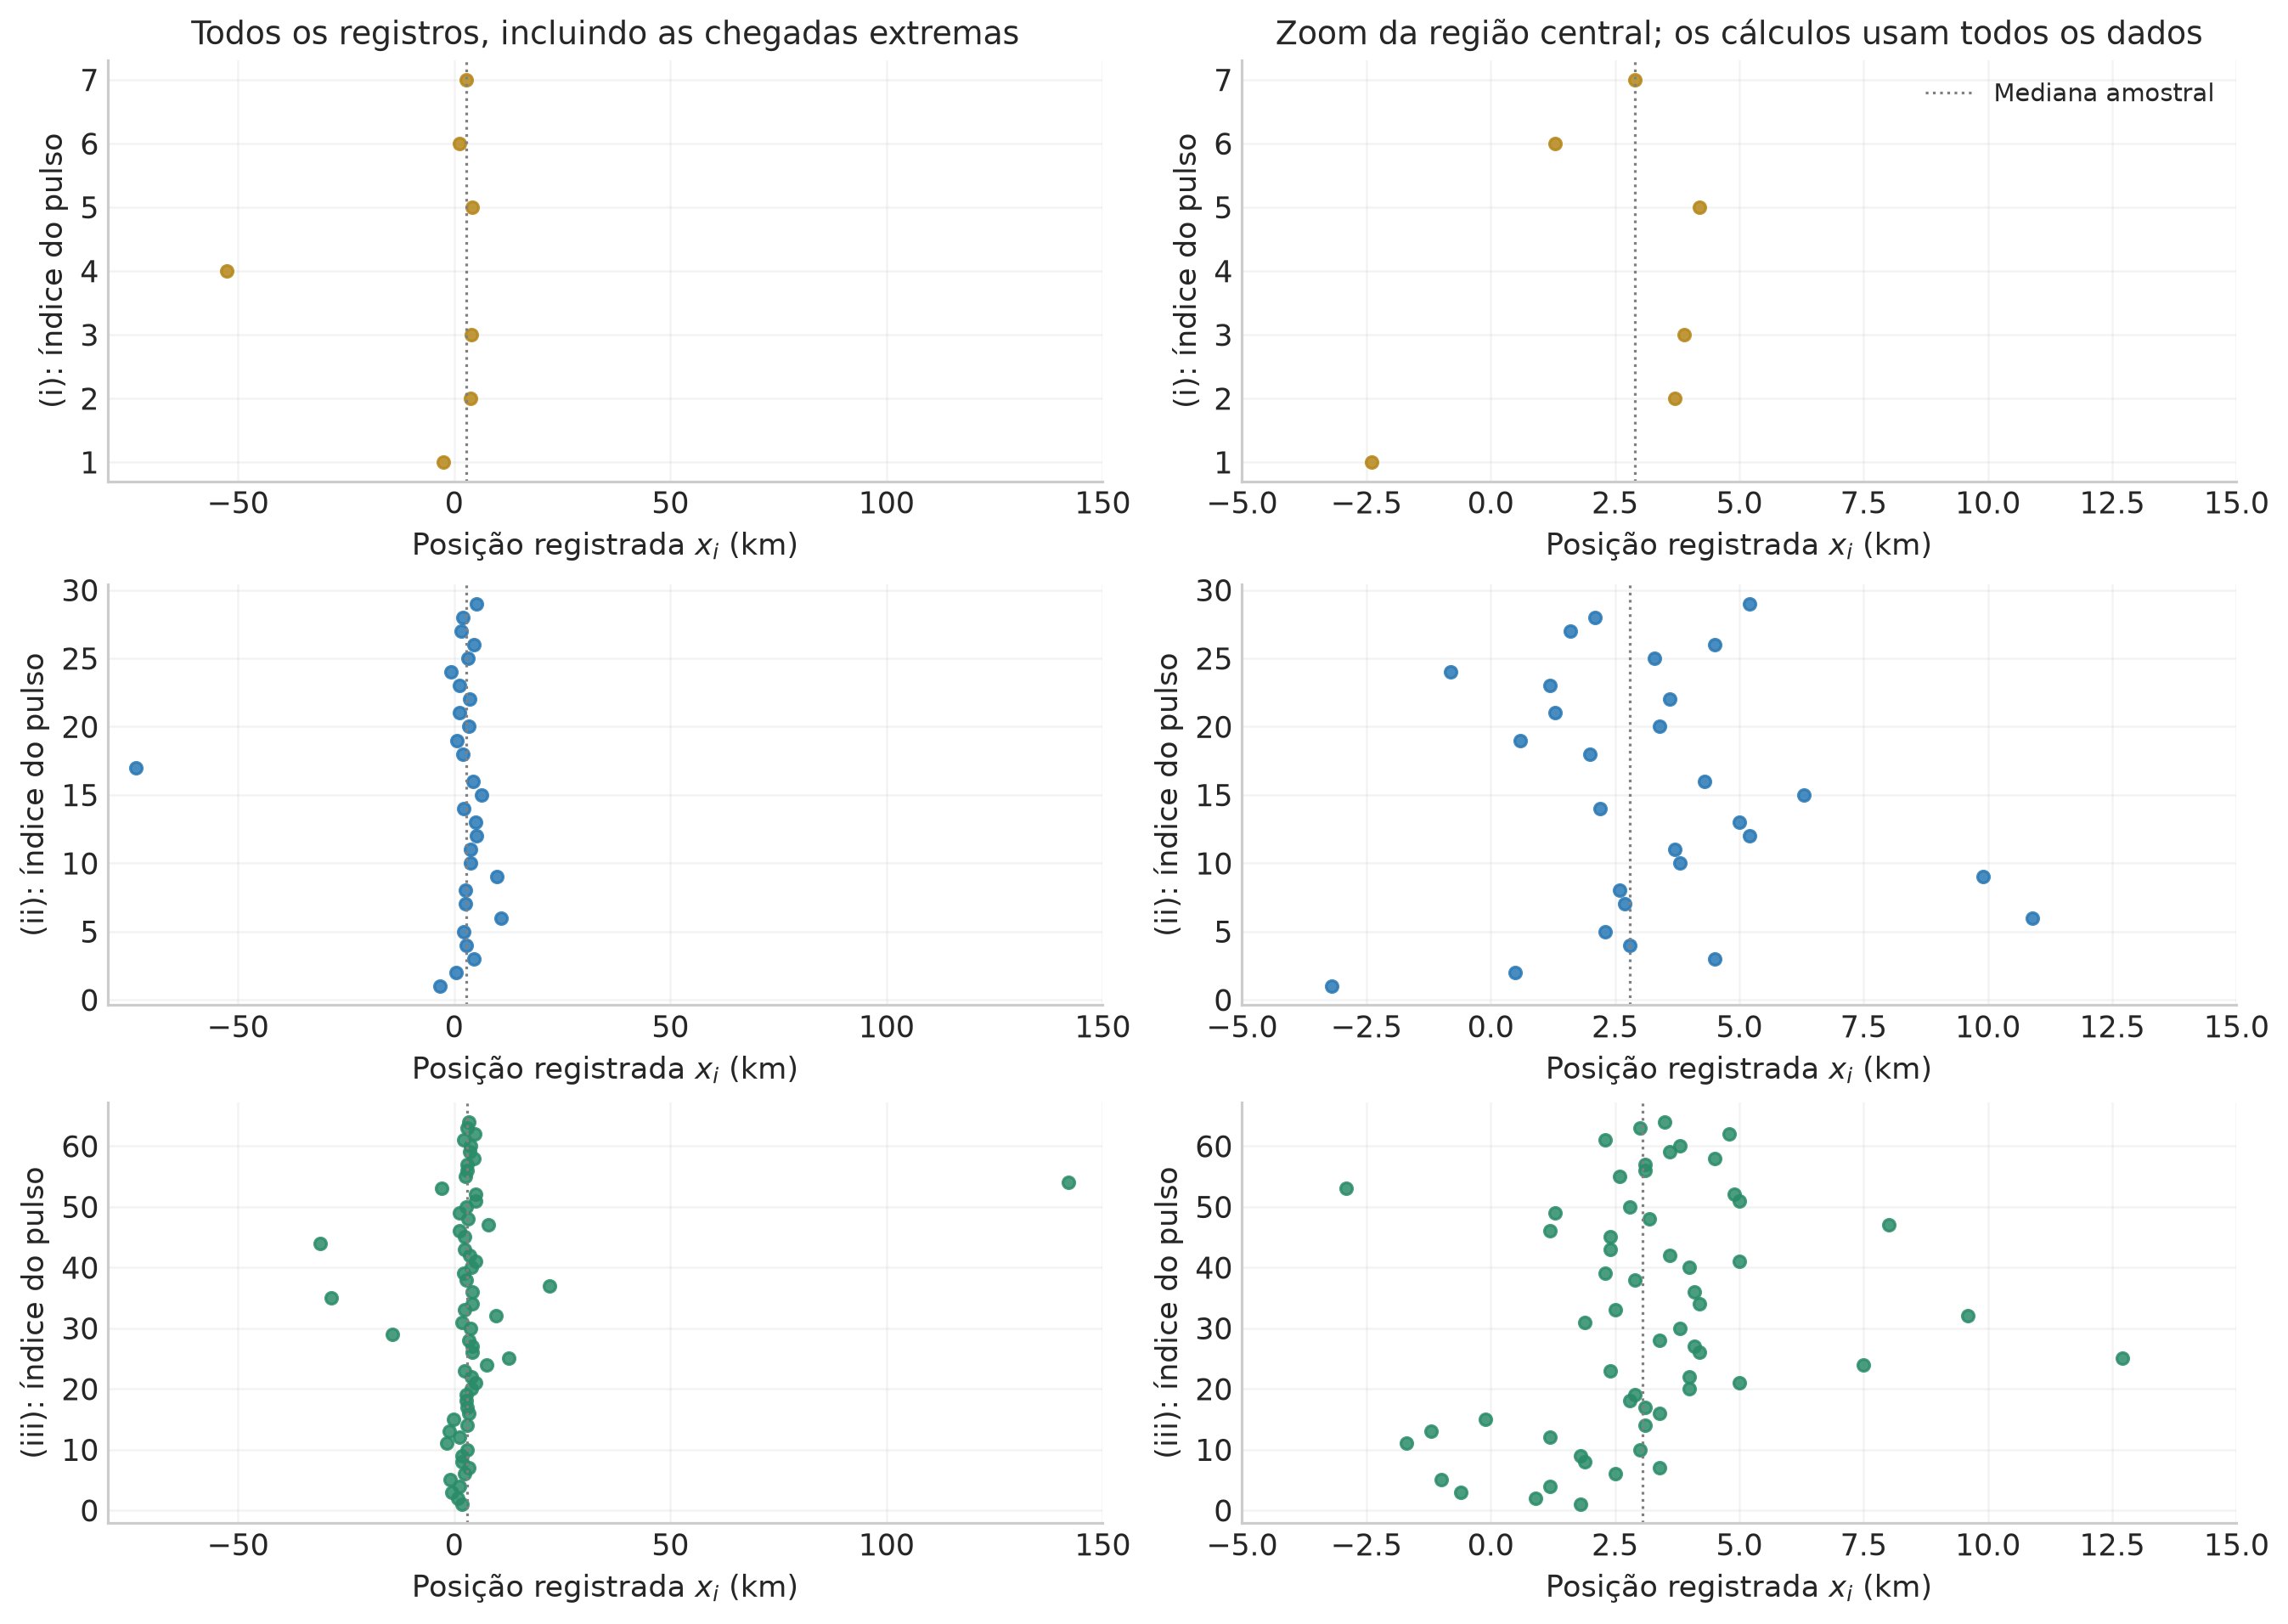

In [10]:
# Transcrição dos três conjuntos, em quilômetros. Nenhum registro é descartado.
q2_data = {
    "(i)": np.array([-2.4, 3.7, 3.9, -52.6, 4.2, 1.3, 2.9]),
    "(ii)": np.array([-3.2, .5, 4.5, 2.8, 2.3, 10.9, 2.7, 2.6, 9.9, 3.8, 3.7, 5.2, 5.0,
                       2.2, 6.3, 4.3, -73.5, 2.0, .6, 3.4, 1.3, 3.6, 1.2, -.8, 3.3,
                       4.5, 1.6, 2.1, 5.2]),
    "(iii)": np.array([1.8, .9, -.6, 1.2, -1.0, 2.5, 3.4, 1.9, 1.8, 3.0, -1.7, 1.2,
                        -1.2, 3.1, -.1, 3.4, 3.1, 2.8, 2.9, 4.0, 5.0, 4.0, 2.4, 7.5,
                        12.7, 4.2, 4.1, 3.4, -14.3, 3.8, 1.9, 9.6, 2.5, 4.2, -28.4,
                        4.1, 22.0, 2.9, 2.3, 4.0, 5.0, 3.6, 2.4, -30.9, 2.4, 1.2,
                        8.0, 3.2, 1.3, 2.8, 5.0, 4.9, -2.9, 142.1, 2.6, 3.1, 3.1,
                        4.5, 3.6, 3.8, 2.3, 4.8, 3.0, 3.5]),
}
q2_b = 1.0
print("Tamanhos das amostras:", {name: len(x) for name, x in q2_data.items()})
print("Unidade de todas as posições e de b: km.")

fig, axes = plt.subplots(3, 2, figsize=(11.6, 8.2), layout="constrained")
for row, ((name, data), color) in enumerate(zip(q2_data.items(), [GOLD, BLUE, GREEN])):
    pulse_index = np.arange(1, len(data)+1)
    for col in range(2):
        axes[row, col].scatter(data, pulse_index, color=color, s=19, alpha=.85)
        axes[row, col].axvline(np.median(data), color="0.5", ls=":", lw=1, label="Mediana amostral")
        axes[row, col].set(ylabel=f"{name}: índice do pulso", xlabel=r"Posição registrada $x_i$ (km)")
    axes[row, 0].set_xlim(-80, 150)
    axes[row, 1].set_xlim(-5, 15)
axes[0, 0].set_title("Todos os registros, incluindo as chegadas extremas")
axes[0, 1].set_title("Zoom da região central; os cálculos usam todos os dados")
axes[0, 1].legend(loc="upper right")
save_figure(fig, "q2_b_dados")

### Calcular em log: a constante de normalização vem depois

O produto de muitas densidades pode ficar extremamente pequeno. Vamos somar seus logaritmos:

$$\ell(a)=\log L(a)=-N\log(\pi b)-\sum_i\log\!\left[1+\left(\frac{x_i-a}{b}\right)^2\right].$$

O primeiro termo é constante em $a$, mas vamos mantê-lo na função da likelihood. Se $m=\max_a\ell(a)$, definimos

$$w(a)=e^{\ell(a)-m},\qquad C=\int_{-\infty}^{\infty}w(a)\,da,$$
$$\boxed{\log p(a\mid D,b)=\ell(a)-m-\log C,\qquad
p(a\mid D,b)=\frac{w(a)}{C}.}$$

Subtrair $m$ não modifica a posterior: o fator $e^{-m}$ aparece no numerador e no denominador e cancela. Agora o maior valor de $w$ é 1, em vez de um número minúsculo. $C$ é apenas a normalização da função reescalada; com a prior imprópria, não vamos chamá-lo de evidência absoluta.

### Localizar o máximo sem confundi-lo com um pico secundário

Derivando a log-likelihood,

$$\ell'(a)=2\sum_i\frac{x_i-a}{b^2+(x_i-a)^2}.$$

O MAP resolve $\ell'(a)=0$ e deve ser o máximo **global** da posterior. Não há uma solução geral dada pela média ou pela mediana amostral. Se $a<\min x_i$, todos os termos da derivada são positivos; se $a>\max x_i$, todos são negativos. Logo o máximo está entre os extremos observados.

Vamos percorrer essa região, procurar as mudanças de sinal da derivada, refinar as raízes e comparar seus valores de $\ell$. A malha localiza os intervalos; as raízes são refinadas com `brentq`. Na conferência, repetimos a busca com uma malha mais fina e usamos também uma otimização independente perto do máximo encontrado. Essa precaução é útil: estes dados produzem picos secundários muito pequenos perto de algumas chegadas distantes.

As integrais da posterior são feitas em **toda a reta**, separando intervalos em torno do pico para que a quadratura não deixe passar uma região estreita. Não normalizamos somente a janela desenhada nos gráficos.

In [11]:
def q2_loglike(a, data, b=1.0):
    """Log da densidade conjunta dos registros; aceita escalar ou array de a."""
    a = np.asarray(a, dtype=float)
    data = np.asarray(data, dtype=float)
    if b <= 0:
        raise ValueError("b deve ser positivo.")
    residual = (data - a[..., None]) / b
    return -len(data)*np.log(np.pi*b) - np.sum(np.log1p(residual**2), axis=-1)

def q2_score(a, data, b=1.0):
    """Derivada da log-likelihood em relação à posição do farol."""
    residual = np.asarray(data) - np.asarray(a)[..., None]
    return np.sum(2*residual/(b*b+residual**2), axis=-1)

def q2_second_derivative(a, data, b=1.0):
    residual = np.asarray(data) - a
    return np.sum(2*(residual**2-b*b)/(b*b+residual**2)**2)

def q2_find_map(data, b=1.0, grid_size=30001):
    """Busca os pontos estacionários e escolhe o de maior log-likelihood."""
    grid_a = np.linspace(np.min(data)-b, np.max(data)+b, grid_size)
    derivative = q2_score(grid_a, data, b)
    crossings = np.flatnonzero(derivative[:-1]*derivative[1:] < 0)
    roots = [brentq(lambda a: q2_score(a, data, b), grid_a[k], grid_a[k+1], xtol=1e-12)
             for k in crossings]
    roots += list(grid_a[derivative == 0])
    roots = np.unique(roots)
    if len(roots) == 0:
        raise RuntimeError("Nenhum máximo localizado; revise a malha de busca.")
    logvalues = q2_loglike(roots, data, b)
    return float(roots[np.argmax(logvalues)]), roots

def q2_build_posterior(data, b=1.0):
    """Posterior própria em toda a reta, para a prior uniforme de localização."""
    data = np.asarray(data, dtype=float)
    mode, roots = q2_find_map(data, b)
    logpeak = float(q2_loglike(mode, data, b))
    anchors = [mode-5*b, mode, mode+5*b]

    def weight(a):
        return np.exp(q2_loglike(a, data, b)-logpeak)

    def integral(left, right, power=0):
        # Momentos em torno do modo evitam cancelamentos desnecessários.
        cuts = [left] + [v for v in anchors if left < v < right] + [right]
        return sum(quad(lambda a: float(weight(a))*(a-mode)**power, lo, hi,
                        epsabs=2e-12, epsrel=2e-10, limit=250)[0]
                   for lo, hi in zip(cuts[:-1], cuts[1:]))

    constant = integral(-np.inf, np.inf)
    def pdf(a):
        return weight(a)/constant
    def cdf(a):
        return float(np.clip(integral(-np.inf, float(a))/constant, 0, 1))
    def quantile(probability):
        if not 0 < probability < 1:
            raise ValueError("O quantil deve ter probabilidade entre 0 e 1.")
        left, right = data.min()-20*b, data.max()+20*b
        while cdf(left) > probability:
            left -= 2*(right-left)
        while cdf(right) < probability:
            right += 2*(right-left)
        return brentq(lambda a: cdf(a)-probability, left, right, xtol=2e-10)

    return {"data":data, "b":b, "mode":mode, "roots":roots, "logpeak":logpeak,
            "weight":weight, "constant":constant, "integral":integral,
            "pdf":pdf, "cdf":cdf, "quantile":quantile}

q2_results = {name:q2_build_posterior(data, q2_b) for name, data in q2_data.items()}
q2_probabilities = np.array([.025, .16, .50, .84, .975])
for name, result in q2_results.items():
    result["quantiles"] = np.array([result["quantile"](p) for p in q2_probabilities])
    result["mean"] = (result["mode"] + result["integral"](-np.inf, np.inf, power=1)/result["constant"])
    print(f"{name}: N={len(result['data'])}; MAP={result['mode']:.8f} km; "
          f"pontos estacionários={result['roots']}")

(i): N=7; MAP=3.50331269 km; pontos estacionários=[-52.48890131 -44.88693586   3.50331269]
(ii): N=29; MAP=2.97185518 km; pontos estacionários=[-73.06244895 -71.29344741   2.97185518]
(iii): N=64; MAP=3.06848088 km; pontos estacionários=[  3.06848088 140.55338984 141.46354745]


### Posteriores normalizadas e intervalos de credibilidade

Para obter os intervalos, integramos a posterior normalizada:

$$F_a(A\mid D)=\int_{-\infty}^{A}p(a\mid D,b,I)\,da.$$

Buscamos os valores em que essa acumulada é 0,025 e 0,975. O intervalo central de 68% usa 0,16 e 0,84. Esses limites não precisam ficar a distâncias iguais do MAP, sobretudo na amostra pequena. Não estamos impondo uma forma gaussiana à posterior.

Os três conjuntos são analisados **separadamente**, como pedido. Eles têm tamanhos diferentes, mas o conjunto (ii) não é uma continuação do conjunto (i), nem (iii) uma continuação de (ii). Comparar suas larguras não equivale a acompanhar uma única amostra sendo ampliada.

| Conjunto | N | MAP (km) | Limite 2,5% (km) | Limite 97,5% (km) |
| :-- | :-- | :-- | :-- | :-- |
| (i) | 7 | 3,503313 | 1,894932 | 4,413922 |
| (ii) | 29 | 2,971855 | 2,269552 | 3,724335 |
| (iii) | 64 | 3,068481 | 2,701642 | 3,434549 |

| Conjunto | N | Média amostral | Mediana amostral | MAP | Média posterior | Mediana posterior |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| (i) | 7 | -5,571429 | 2,900000 | 3,503313 | 3,341941 | 3,403356 |
| (ii) | 29 | 0,620690 | 2,800000 | 2,971855 | 2,986021 | 2,981895 |
| (iii) | 64 | 4,260937 | 3,050000 | 3,068481 | 3,068327 | 3,068398 |

| Conjunto | Quantil 16% | Quantil 84% | Quantil 2,5% | Quantil 97,5% |
| :-- | :-- | :-- | :-- | :-- |
| (i) | 2,768763 | 3,921123 | 1,894932 | 4,413922 |
| (ii) | 2,614142 | 3,358463 | 2,269552 | 3,724335 |
| (iii) | 2,883463 | 3,253233 | 2,701642 | 3,434549 |

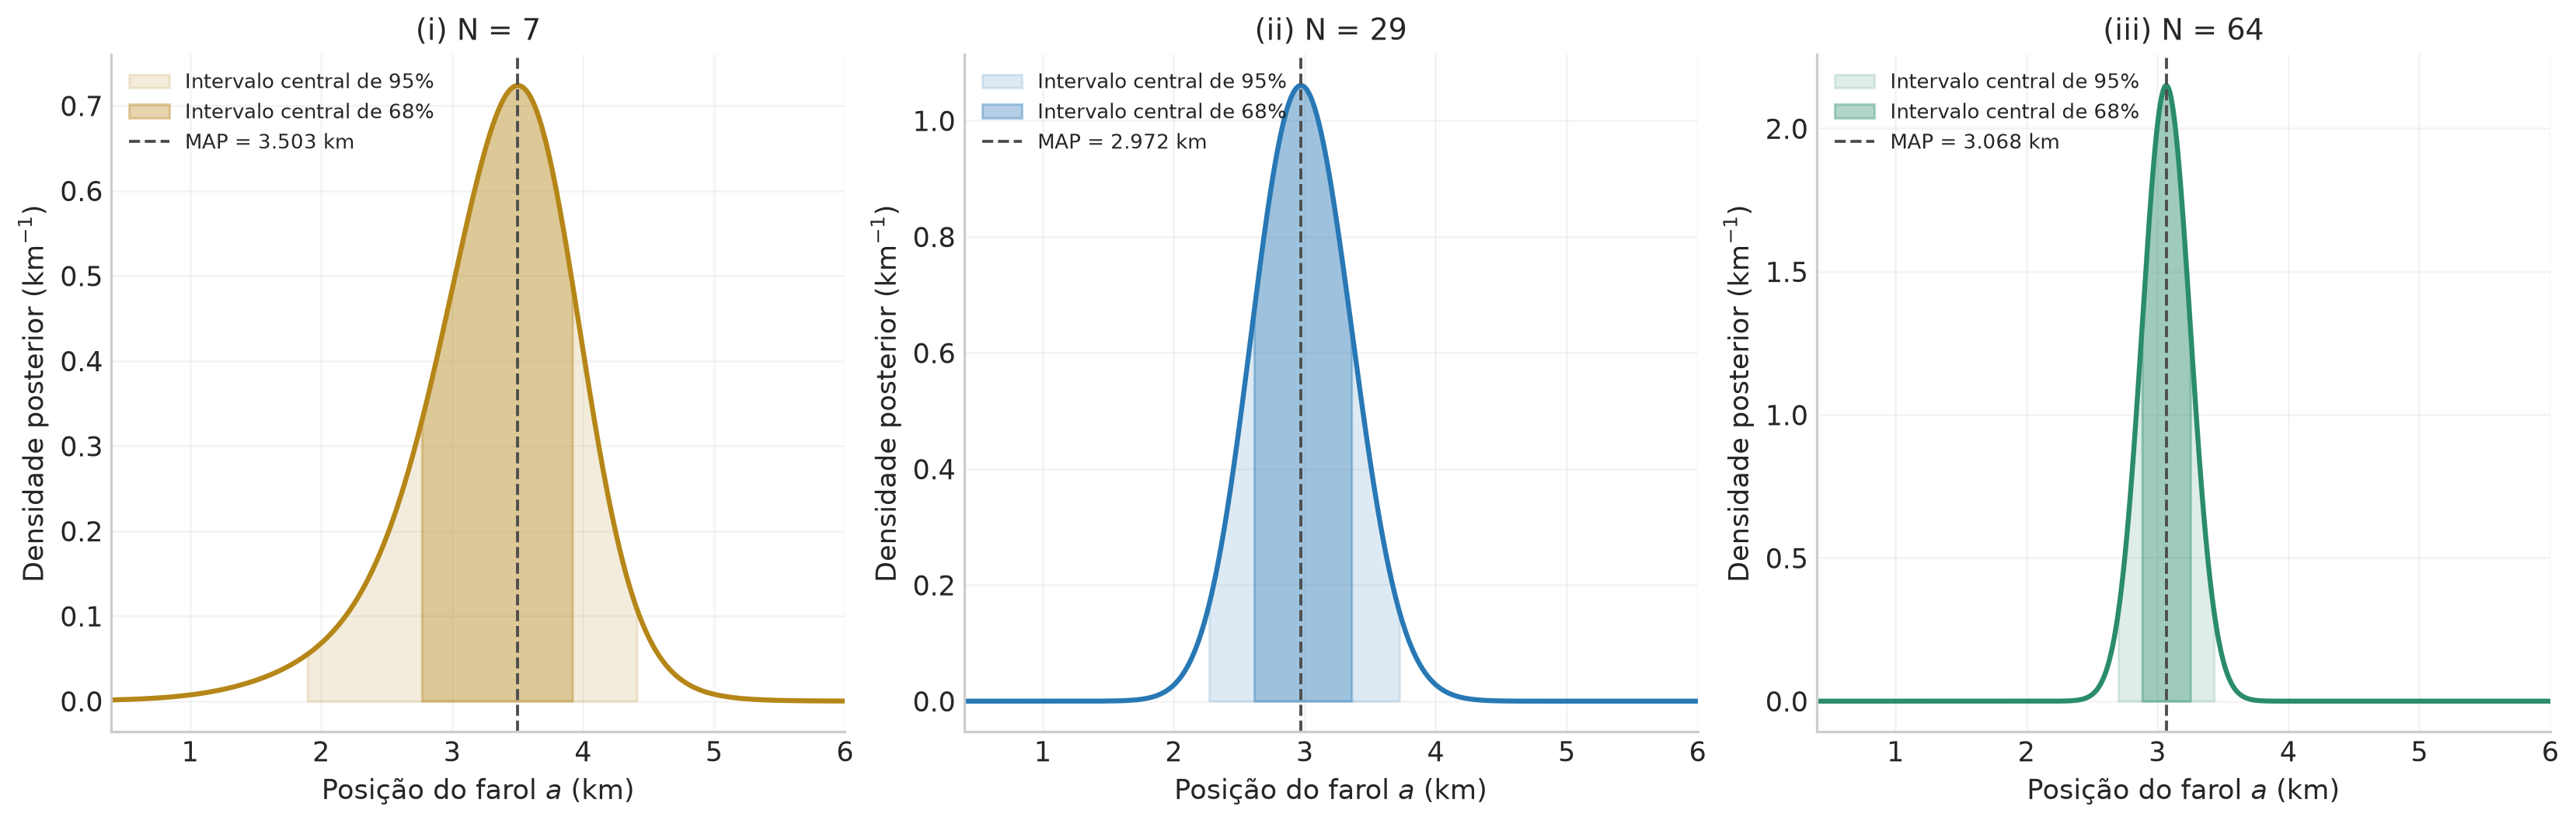

In [12]:
q2_summary_rows = []
q2_comparison_rows = []
q2_interval_rows = []
for name, result in q2_results.items():
    data, qs = result["data"], result["quantiles"]
    q2_summary_rows.append([name, len(data), result["mode"], qs[0], qs[-1]])
    q2_comparison_rows.append([name, len(data), data.mean(), np.median(data),
                               result["mode"], result["mean"], qs[2]])
    q2_interval_rows.append([name, qs[1], qs[3], qs[0], qs[-1]])

export_table("q2_b_posicao_intervalos", ["Conjunto", "N", "MAP (km)", "Limite 2,5% (km)", "Limite 97,5% (km)"],
             q2_summary_rows, [0, 0, 6, 6, 6])
export_table("q2_b_estimativas", ["Conjunto", "N", "Média amostral", "Mediana amostral", "MAP", "Média posterior", "Mediana posterior"],
             q2_comparison_rows, [0, 0, 6, 6, 6, 6, 6])
export_table("q2_b_intervalos_68_95", ["Conjunto", "Quantil 16%", "Quantil 84%", "Quantil 2,5%", "Quantil 97,5%"],
             q2_interval_rows, [0, 6, 6, 6, 6])

q2_a_grid = np.linspace(.4, 6.0, 3000)
fig, axes = plt.subplots(1, 3, figsize=(14.3, 4.5), layout="constrained")
for ax, ((name, result), color) in zip(axes, zip(q2_results.items(), [GOLD, BLUE, GREEN])):
    density, qs = result["pdf"](q2_a_grid), result["quantiles"]
    ax.plot(q2_a_grid, density, color=color)
    ax.fill_between(q2_a_grid, 0, density, where=(q2_a_grid>=qs[0])&(q2_a_grid<=qs[-1]),
                     color=color, alpha=.15, label="Intervalo central de 95%")
    ax.fill_between(q2_a_grid, 0, density, where=(q2_a_grid>=qs[1])&(q2_a_grid<=qs[3]),
                     color=color, alpha=.35, label="Intervalo central de 68%")
    ax.axvline(result["mode"], color="0.3", ls="--", lw=1.2,
               label=f"MAP = {result['mode']:.3f} km")
    ax.set(xlabel=r"Posição do farol $a$ (km)", ylabel=r"Densidade posterior (km$^{-1}$)",
            title=f"{name} N = {len(result['data'])}", xlim=(.4,6))
    ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "q2_b_posteriores")

### O que os resultados dizem sobre o farol?

Com a prior de localização adotada, os MAPs são

$$\boxed{\hat a_{(i)}\simeq3{,}5033\,\mathrm{km},\qquad
\hat a_{(ii)}\simeq2{,}9719\,\mathrm{km},\qquad
\hat a_{(iii)}\simeq3{,}0685\,\mathrm{km}.}$$

Os intervalos centrais de 95% são, aproximadamente,

$$\boxed{\begin{aligned}
(i)&:\ [1{,}8949;\ 4{,}4139]\,\mathrm{km},\\
(ii)&:\ [2{,}2696;\ 3{,}7243]\,\mathrm{km},\\
(iii)&:\ [2{,}7016;\ 3{,}4345]\,\mathrm{km}.
\end{aligned}}$$

O conjunto (i) permite uma faixa mais ampla e produz uma posterior assimétrica. Seu MAP é cerca de $3{,}50$ km, enquanto a mediana posterior é $3{,}40$ km e a média posterior $3{,}34$ km. No conjunto (iii), esses três resumos ficam muito próximos de $3{,}068$ km.

Não conhecemos uma “posição verdadeira” fornecida pelo exercício. As estimativas e as probabilidades acima são condicionadas à geometria, ao modelo de emissão, a $b=1$ km e à prior escolhida. Os intervalos apresentados são posteriores para **$a$**.

## Uma medida, uma amostra e a atualização sequencial

Um único pulso fornece um $x_i$. Uma amostra com $N$ pulsos fornece $D$, e toda a amostra atualiza **um mesmo parâmetro** $a$. Não temos $N$ posições desconhecidas do farol. A repetição do experimento produziria outras amostras $D$ e outras posteriores.

Dentro de uma mesma amostra, podemos atualizar aos poucos. Se $D_n=(x_1,\ldots,x_n)$, Bayes e a independência condicional dão

$$p(a\mid D_n,b)\propto f_X(x_n\mid a,b)\,p(a\mid D_{n-1},b).$$

Repetindo a regra, obtemos o produto de todas as likelihoods, exatamente como na análise conjunta. Com a prior uniforme, depois de **um único pulso** a posterior de localização já é própria:

$$p(a\mid x_1,b)=\frac{b}{\pi[(a-x_1)^2+b^2]}.$$

Ela é uma Cauchy em $a$: possui modo e mediana $x_1$, mas ainda não possui média. Para grandes $|a|$, uma posterior baseada em $n$ pulsos decai como $|a|^{-2n}$. Um momento absoluto de ordem $k$ existe se $\int^\infty |a|^{k-2n}\,da$ convergir, isto é, se $k<2n-1$. Com dois ou mais pulsos, a média e a variância posteriores já podem existir, embora a distribuição dos registros $X$ continue sem média e variância.

No gráfico, usamos apenas **prefixos do conjunto (iii)**, com 1, 7, 20 e 64 pulsos. Agora, sim, a informação é acumulada sobre a mesma amostra. A largura pode flutuar durante uma realização, e não há garantia de redução a cada novo pulso. O fato de o TLC usual para médias amostrais não se aplicar à Cauchy não impede a likelihood de fornecer informação sobre seu parâmetro de localização.

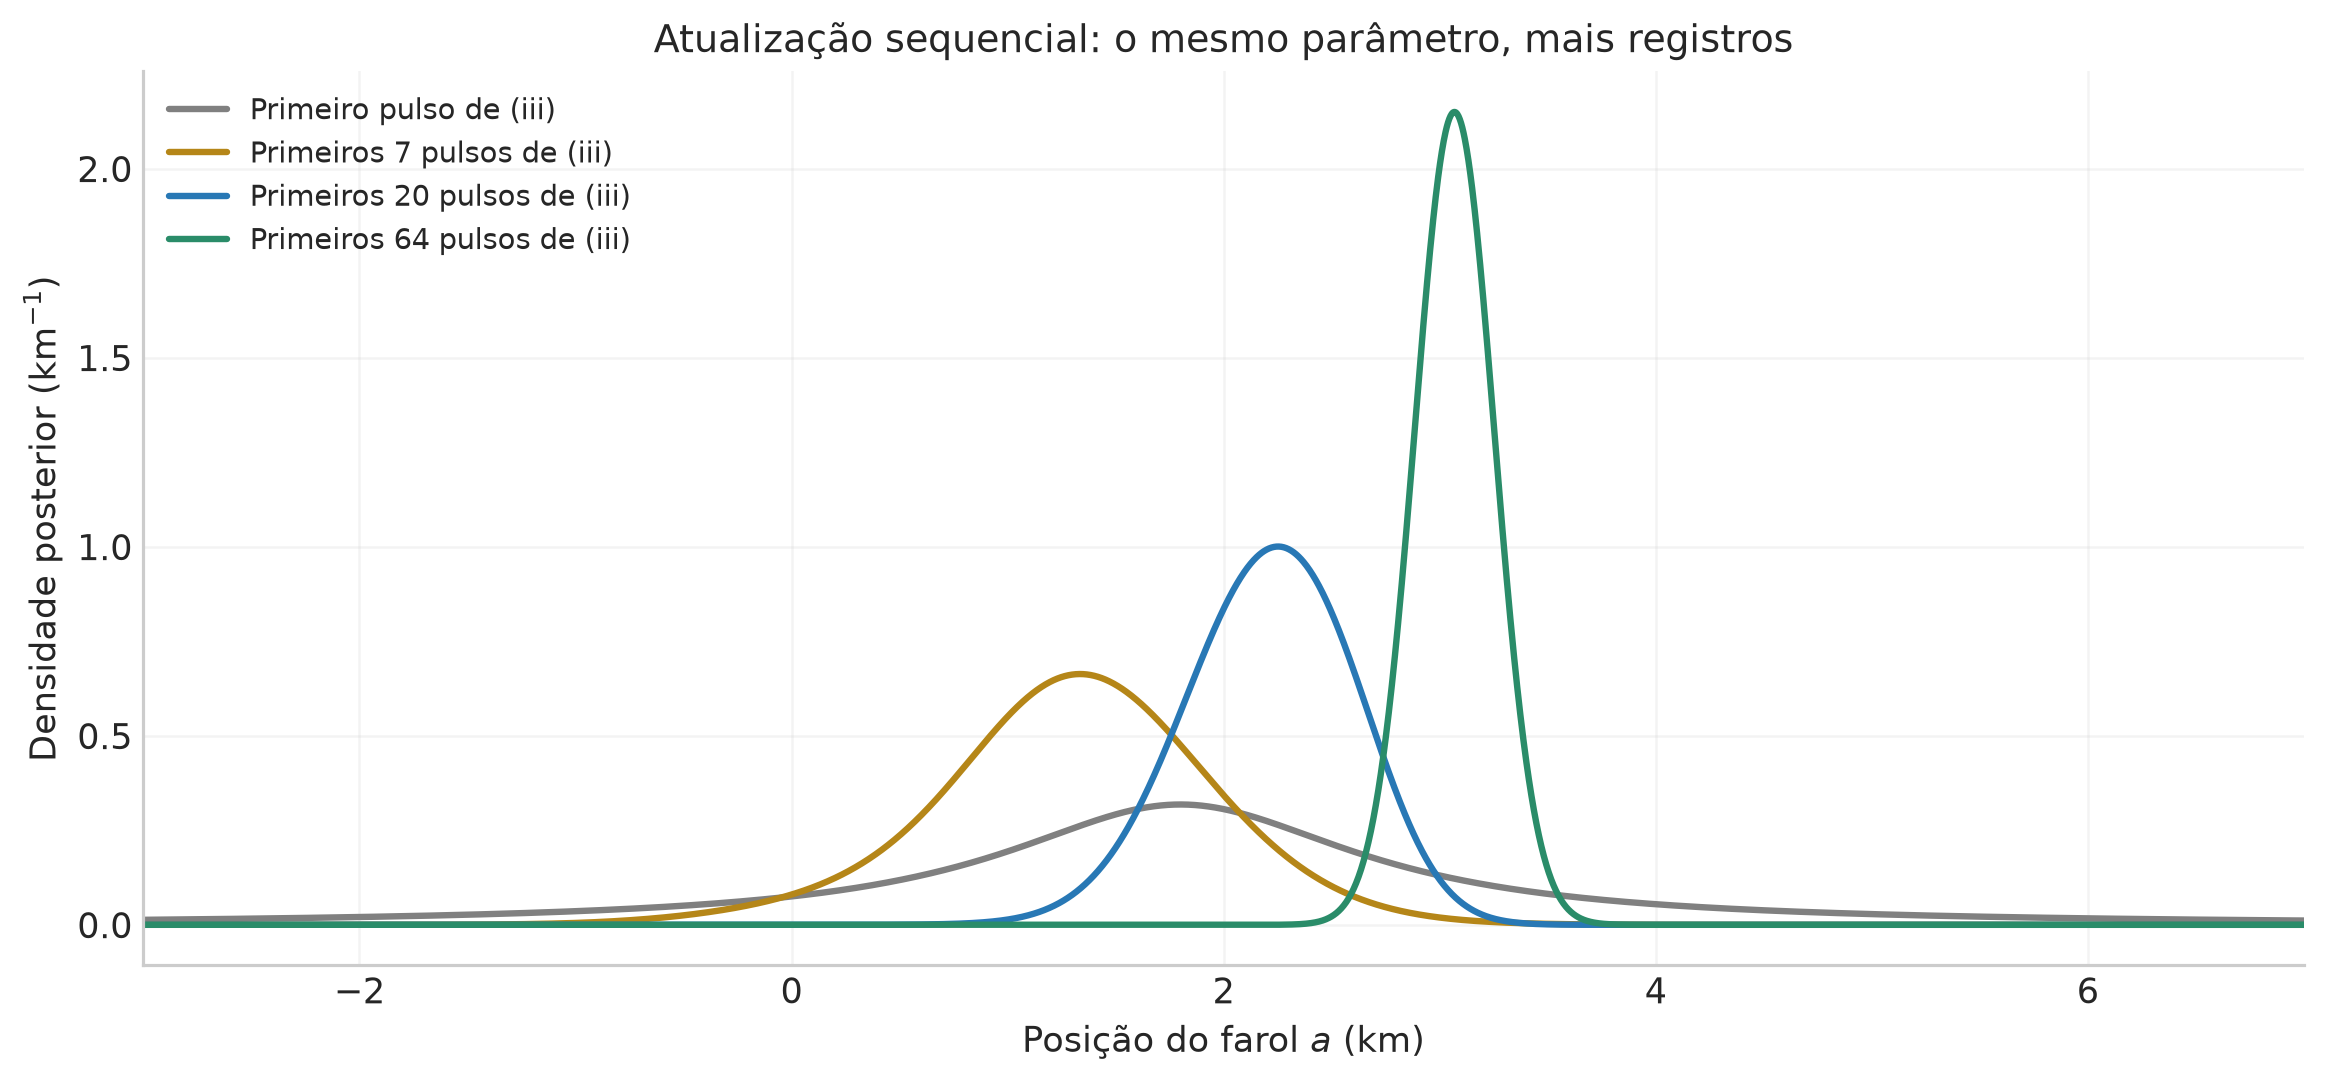

In [13]:
q2_prefixes = {}
for n_pulses in [1, 7, 20, 64]:
    q2_prefixes[n_pulses] = (q2_results["(iii)"] if n_pulses == 64 else
                             q2_build_posterior(q2_data["(iii)"][:n_pulses], q2_b))
q2_seq_grid = np.linspace(-3, 7, 3500)
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
for (n_pulses, result), color in zip(q2_prefixes.items(), ["0.5", GOLD, BLUE, GREEN]):
    ax.plot(q2_seq_grid, result["pdf"](q2_seq_grid), color=color,
            label=("Primeiro pulso de (iii)" if n_pulses == 1 else f"Primeiros {n_pulses} pulsos de (iii)"))
ax.set(xlabel=r"Posição do farol $a$ (km)", ylabel=r"Densidade posterior (km$^{-1}$)",
        title="Atualização sequencial: o mesmo parâmetro, mais registros", xlim=(-3,7))
ax.legend(loc="upper left")
save_figure(fig, "q2_extra_atualizacao_sequencial")

# Questão 3 · Bactérias: dos dados observados à previsão de uma nova amostra

A terceira questão da lista reúne os **problemas 4.7 e 4.9 do Gregory**, na seção de exercícios do capítulo 4. Em uma primeira amostra de água, encontramos 10 bactérias, das quais 3 são do tipo A. Em uma segunda amostra, independente e com 12 bactérias no total, queremos calcular:

- **Gregory 4.7:** a probabilidade de encontrar **exatamente 6** bactérias do tipo A;
- **Gregory 4.9:** a probabilidade de encontrar **pelo menos 3** bactérias do tipo A.

O total da segunda amostra já é conhecido: estamos condicionando em 12 bactérias, nossa informação priori

O problema parece uma aplicação direta da binomial, para cada bactéria ela é do tipo A ou não (Duas opções). Entretanto, sua probabilidade de sucesso não foi fornecida: o que sabemos é que uma amostra anterior apresentou uma frequência $3/10$. Vamos inferir a proporção desconhecida e depois integrar essa incerteza na previsão. Isso é a versão contínua da mistura que construímos na questão 1, onde tinhamos apenas 3 valores possíveis de $\theta_j$, agora temos diversos valores de sucesso possíveis baseado em uma informação anterior, nossa priori.

### Experimento, hipóteses e notação

| Símbolo | Significado |
|:--|:--|
| $q\in[0,1]$ | Probabilidade de uma bactéria da população ser do tipo A; parâmetro desconhecido |
| $n_0=10$ | Total de bactérias da primeira amostra |
| $R_0$ e $r_0=3$ | Contagem de tipos A antes da observação e valor observado na primeira amostra |
| $D_0=(R_0=3,n_0=10)$ | Informação fornecida pela primeira amostra |
| $m=12$ | Total de bactérias da segunda amostra |
| $K$ e $k$ | Contagem futura de tipos A e um de seus valores possíveis, $k=0,\ldots,12$ |
| $I$ | Hipóteses de amostragem e informação anterior, incluindo a prior de $q$ |

Assumimos uma população suficientemente grande e homogênea, da qual as duas amostras são representativas. Há um **mesmo $q$** nas duas amostras. Dado esse parâmetro, as classificações A/não A são independentes. Não há informação sobre uma população finita de composição conhecida que justifique uma hipergeométrica, nem dados sobre mudanças de composição entre as coletas.

“Amostras independentes” significa aqui que, **condicionado ao mesmo $q$**, o mecanismo de coleta de uma não depende do resultado da outra. Saber o resultado da primeira ainda altera nossa previsão da segunda, pois aprendemos sobre esse parâmetro compartilhado.

### 1. Primeiro inferimos $q$: likelihood, prior e posterior

Uma sequência específica com 3 bactérias A e 7 não A tem probabilidade $q^3(1-q)^7$. Como há $\binom{10}{3}=120$ posições possíveis para as três A, a likelihood da **contagem** é

$$L(q;D_0)=P(R_0=3\mid q,n_0=10,I)=\binom{10}{3}q^3(1-q)^7.$$

Essa é uma distribuição dos dados quando $q$ está fixo. Com os dados observados, a estudamos como função de $q$. A frequência $r_0/n_0=0{,}3$ maximiza essa likelihood, mas não torna o parâmetro exatamente conhecido.

O enunciado não especifica uma prior. Vou adotar a **prior uniforme em $q$**,

$$\pi(q\mid I)=1,\quad0\leq q\leq1,$$

e zero fora desse intervalo. Ela atribui a mesma probabilidade a intervalos de mesma largura nessa parametrização. É uma escolha explícita e própria, e não uma ausência universal de informação: uma prior uniforme em uma transformação de $q$ seria, em geral, diferente. Mais adiante vamos conferir duas outras escolhas como comparação.

Pela regra de Bayes,

$$p(q\mid D_0,I)=\frac{\binom{10}{3}q^3(1-q)^7\pi(q)}
{\int_0^1\binom{10}{3}u^3(1-u)^7\pi(u)\,du}.$$

A constante combinatória cancela entre numerador e denominador, pois não depende de $q$. Portanto,

$$p(q\mid D_0,I)=\frac{q^3(1-q)^7}{\int_0^1u^3(1-u)^7\,du}.$$

Essa posterior é uma **densidade no parâmetro**,a probabilidade só aparece ao integrarmos em uma região. A normalização será em $q\in[0,1]$.

### 2. Abrindo a integral de normalização antes de nomear a distribuição

Definimos, para inteiros não negativos $r,s$,

$$I_{r,s}=\int_0^1u^r(1-u)^s\,du.$$

Para $r\geq1$, uma integração por partes com $f=u^r$ e $dg=(1-u)^sdu$ dá

$$I_{r,s}=\left[-\frac{u^r(1-u)^{s+1}}{s+1}\right]_0^1
+\frac{r}{s+1}\int_0^1u^{r-1}(1-u)^{s+1}\,du
=\frac{r}{s+1}I_{r-1,s+1}.$$

O termo de fronteira é zero. Repetindo $r$ vezes e usando $I_{0,r+s}=1/(r+s+1)$,

$$\boxed{I_{r,s}=\frac{r!s!}{(r+s+1)!}.}$$

No nosso caso,

$$I_{3,7}=\frac{3!7!}{11!}=\frac1{1320},\qquad
\boxed{p(q\mid D_0,I)=1320\,q^3(1-q)^7.}$$

Podemos agora dar um nome à integral geral:

$$\boxed{B(a,b)=\int_0^1u^{a-1}(1-u)^{b-1}\,du,\qquad a,b>0.}$$

Esta é a **função Beta**. Sua integral converge nessas condições; para argumentos inteiros, a conta anterior mostra que $B(a,b)=(a-1)!(b-1)!/(a+b-1)!$. Não precisamos introduzir a função Gamma para resolver esta questão.

A **distribuição Beta** com parâmetros $\alpha,\beta>0$ é definida pela densidade

$$\mathrm{Beta}(q;\alpha,\beta)=\frac{q^{\alpha-1}(1-q)^{\beta-1}}{B(\alpha,\beta)},\qquad0<q<1.$$

Comparando os expoentes, nossa posterior é $\mathrm{Beta}(4,8)$. Os parâmetros 4 e 8 não são contagens observadas de bactérias: vêm dos expoentes mais 1, depois da escolha da prior uniforme. Sua soma, $4+8=n_0+2=12$, coincide numericamente com o tamanho da amostra futura, $m=12$, mas foi obtida a partir da amostra anterior e da prior.

Também podemos conferir a evidência da primeira contagem:

$$P(R_0=3\mid n_0=10,I)=\binom{10}{3}I_{3,7}=\frac{120}{1320}=\frac1{11}.$$

A evidência é uma probabilidade dos **dados anteriores**, integrada sobre a prior. Depois de atualizar, usaremos a posterior de $q$ para prever os dados da segunda amostra.

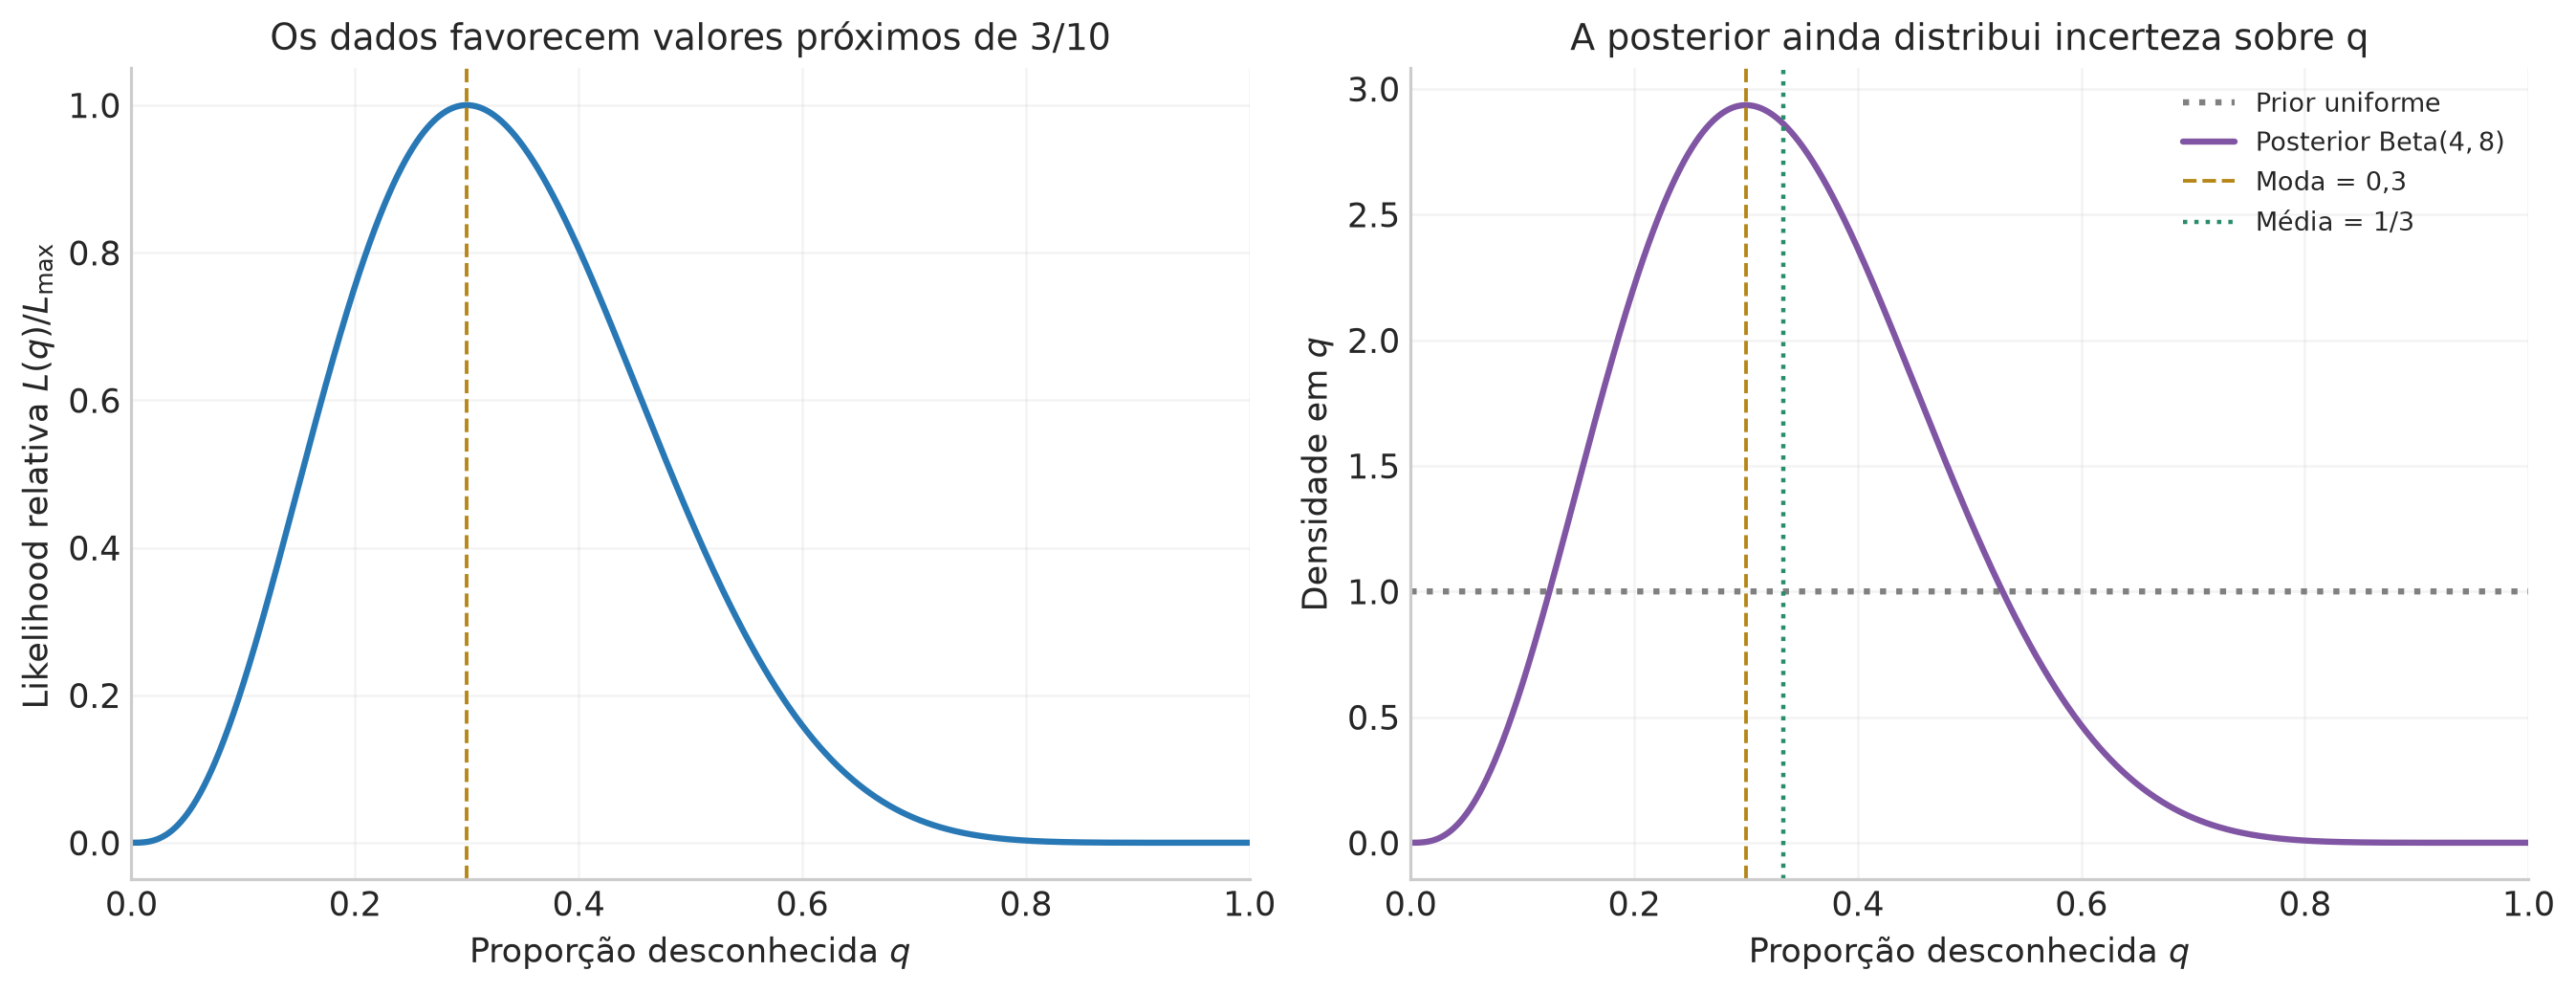

B(4,8) = 1/1320; normalização posterior = 1320
Evidência da contagem anterior: 1/11


In [14]:
# Imports e funções da questão 3. As exportações usam os helpers do início do notebook.
from math import comb, factorial
from fractions import Fraction
from scipy.special import betaln
from scipy.stats import beta as beta_distribution, betabinom

q3_n0, q3_r0, q3_m = 10, 3, 12
q3_alpha, q3_beta = q3_r0+1, q3_n0-q3_r0+1

def q3_beta_integer(a, b):
    """B(a,b) exata para argumentos inteiros positivos, pela integral deduzida."""
    if a < 1 or b < 1 or int(a) != a or int(b) != b:
        raise ValueError("Esta rotina de fatoriais requer inteiros positivos.")
    return Fraction(factorial(a-1)*factorial(b-1), factorial(a+b-1))

q3_B = q3_beta_integer(q3_alpha, q3_beta)

def q3_posterior_pdf(q):
    """Densidade posterior em [0,1], escrita a partir da normalização analítica."""
    q = np.asarray(q, dtype=float)
    inside = (q>=0)&(q<=1)
    safe_q = np.clip(q, 0, 1)
    return np.where(inside, safe_q**3*(1-safe_q)**7/float(q3_B), 0.0)

q3_qgrid = np.linspace(0, 1, 1800)
q3_q_mode = q3_r0/q3_n0
q3_likelihood = comb(q3_n0, q3_r0)*q3_qgrid**q3_r0*(1-q3_qgrid)**(q3_n0-q3_r0)
q3_Lmax = comb(q3_n0, q3_r0)*q3_q_mode**q3_r0*(1-q3_q_mode)**(q3_n0-q3_r0)
q3_q_mean = float(q3_beta_integer(5,8)/q3_B)
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
axes[0].plot(q3_qgrid, q3_likelihood/q3_Lmax, color=BLUE)
axes[0].axvline(q3_q_mode, color=GOLD, ls="--", lw=1.2)
axes[0].set(xlabel=r"Proporção desconhecida $q$", ylabel=r"Likelihood relativa $L(q)/L_{\max}$",
            title="Os dados favorecem valores próximos de 3/10", xlim=(0,1))
axes[1].plot(q3_qgrid, np.ones_like(q3_qgrid), color="0.5", ls=":", label="Prior uniforme")
axes[1].plot(q3_qgrid, q3_posterior_pdf(q3_qgrid), color=PURPLE, label=r"Posterior Beta$(4,8)$")
axes[1].axvline(q3_q_mode, color=GOLD, ls="--", lw=1.2, label="Moda = 0,3")
axes[1].axvline(q3_q_mean, color=GREEN, ls=":", lw=1.4, label="Média = 1/3")
axes[1].set(xlabel=r"Proporção desconhecida $q$", ylabel=r"Densidade em $q$",
            title="A posterior ainda distribui incerteza sobre q", xlim=(0,1))
axes[1].legend(loc="upper right", fontsize=8.5)
save_figure(fig, "q3_posterior_proporcao")
print(f"B(4,8) = {q3_B}; normalização posterior = {1/q3_B}")
print(f"Evidência da contagem anterior: {comb(q3_n0,q3_r0)*q3_B}")

### 3. Prever a segunda amostra: marginalizar o parâmetro compartilhado

Se conhecêssemos $q$, a probabilidade de observar $k$ bactérias A entre $m=12$ seria binomial:

$$P(K=k\mid q,m,I)=\binom{12}{k}q^k(1-q)^{12-k}.$$

A independência condicional entre as amostras diz que $P(K=k\mid q,D_0,m,I)=P(K=k\mid q,m,I)$. Entretanto, **não conhecemos $q$**. Pela regra da probabilidade total,

$$\boxed{P(K=k\mid D_0,m,I)=\int_0^1P(K=k\mid q,m,I)\,p(q\mid D_0,I)\,dq.}$$

O integrando combina uma probabilidade da contagem futura com uma densidade do parâmetro. A integral fornece uma **massa de probabilidade em $k$**, e não uma densidade em $q$.

Substituindo a binomial e a posterior,

$$\begin{aligned}
P(K=k\mid D_0,m,I)
&=\binom{12}{k}\frac1{B(4,8)}\int_0^1q^{k+3}(1-q)^{19-k}\,dq\\
&=\boxed{\binom{12}{k}\frac{B(k+4,20-k)}{B(4,8)}},\qquad k=0,\ldots,12.
\end{aligned}$$

Esta é uma **distribuição beta-binomial**: uma mistura contínua de binomiais com um mesmo parâmetro incerto, cuja distribuição de mistura é Beta. Ela é preditiva **posterior**, pois a distribuição usada para misturar já incorporou $D_0$. Na questão 1, os pesos da mistura eram anteriores aos dados.

Sua normalização vem diretamente da construção:

$$\sum_{k=0}^{12}P(K=k\mid D_0)
=\int_0^1\underbrace{\sum_{k=0}^{12}P(K=k\mid q)}_{1}\,p(q\mid D_0)\,dq=1.$$

### Gregory 4.7 · Exatamente seis

Para $k=6$,

$$P(K=6\mid D_0)=\binom{12}{6}\frac{B(10,14)}{B(4,8)}
=924\frac{9!13!}{23!}\frac{11!}{3!7!}
=\boxed{\frac{792}{7429}\simeq0{,}1066092341.}$$

Portanto, a probabilidade pedida é aproximadamente **10,6609%**, condicionada ao modelo e à prior uniforme adotados.

### Gregory 4.9 · Pelo menos três

“Pelo menos 3” inclui $K=3$. É mais curto somar o complemento $K=0,1,2$:

$$P(K\geq3\mid D_0)=1-\sum_{k=0}^{2}\binom{12}{k}\frac{B(k+4,20-k)}{B(4,8)}.$$

Os três termos são

$$P(K=0)=\frac6{161}=\frac{114}{3059},\quad
P(K=1)=\frac{288}{3059},\quad
P(K=2)=\frac{440}{3059}.$$

Logo,

$$\boxed{P(K\geq3\mid D_0)=1-\frac{114+288+440}{3059}
=\frac{2217}{3059}\simeq0{,}7247466492.}$$

A segunda resposta é aproximadamente **72,4747%**.

| Exercício | Evento | Probabilidade | Probabilidade (%) |
| :-- | :-- | :-- | :-- |
| Gregory 4.7 | $K=6$ | 0,1066092341 | 10,660923 |
| Gregory 4.9 | $K\geq3$ | 0,7247466492 | 72,474665 |

| K | P(K | D0) | Probabilidade (%) | Probabilidade acumulada |
| :-- | :-- | :-- | :-- |
| 0 | 0,0372670807 | 3,726708 | 0,0372670807 |
| 1 | 0,0941484145 | 9,414841 | 0,1314154953 |
| 2 | 0,1438378555 | 14,383786 | 0,2752533508 |
| 3 | 0,1692210065 | 16,922101 | 0,4444743572 |
| 4 | 0,1665769283 | 16,657693 | 0,6110512855 |
| 5 | 0,1421456454 | 14,214565 | 0,7531969309 |
| 6 | 0,1066092341 | 10,660923 | 0,8598061650 |
| 7 | 0,0702918027 | 7,029180 | 0,9300979677 |
| 8 | 0,0402713453 | 4,027135 | 0,9703693130 |
| 9 | 0,0195255007 | 1,952550 | 0,9898948138 |
| 10 | 0,0076149453 | 0,761495 | 0,9975097591 |
| 11 | 0,0021537219 | 0,215372 | 0,9996634810 |
| 12 | 0,0003365190 | 0,033652 | 1,0000000000 |

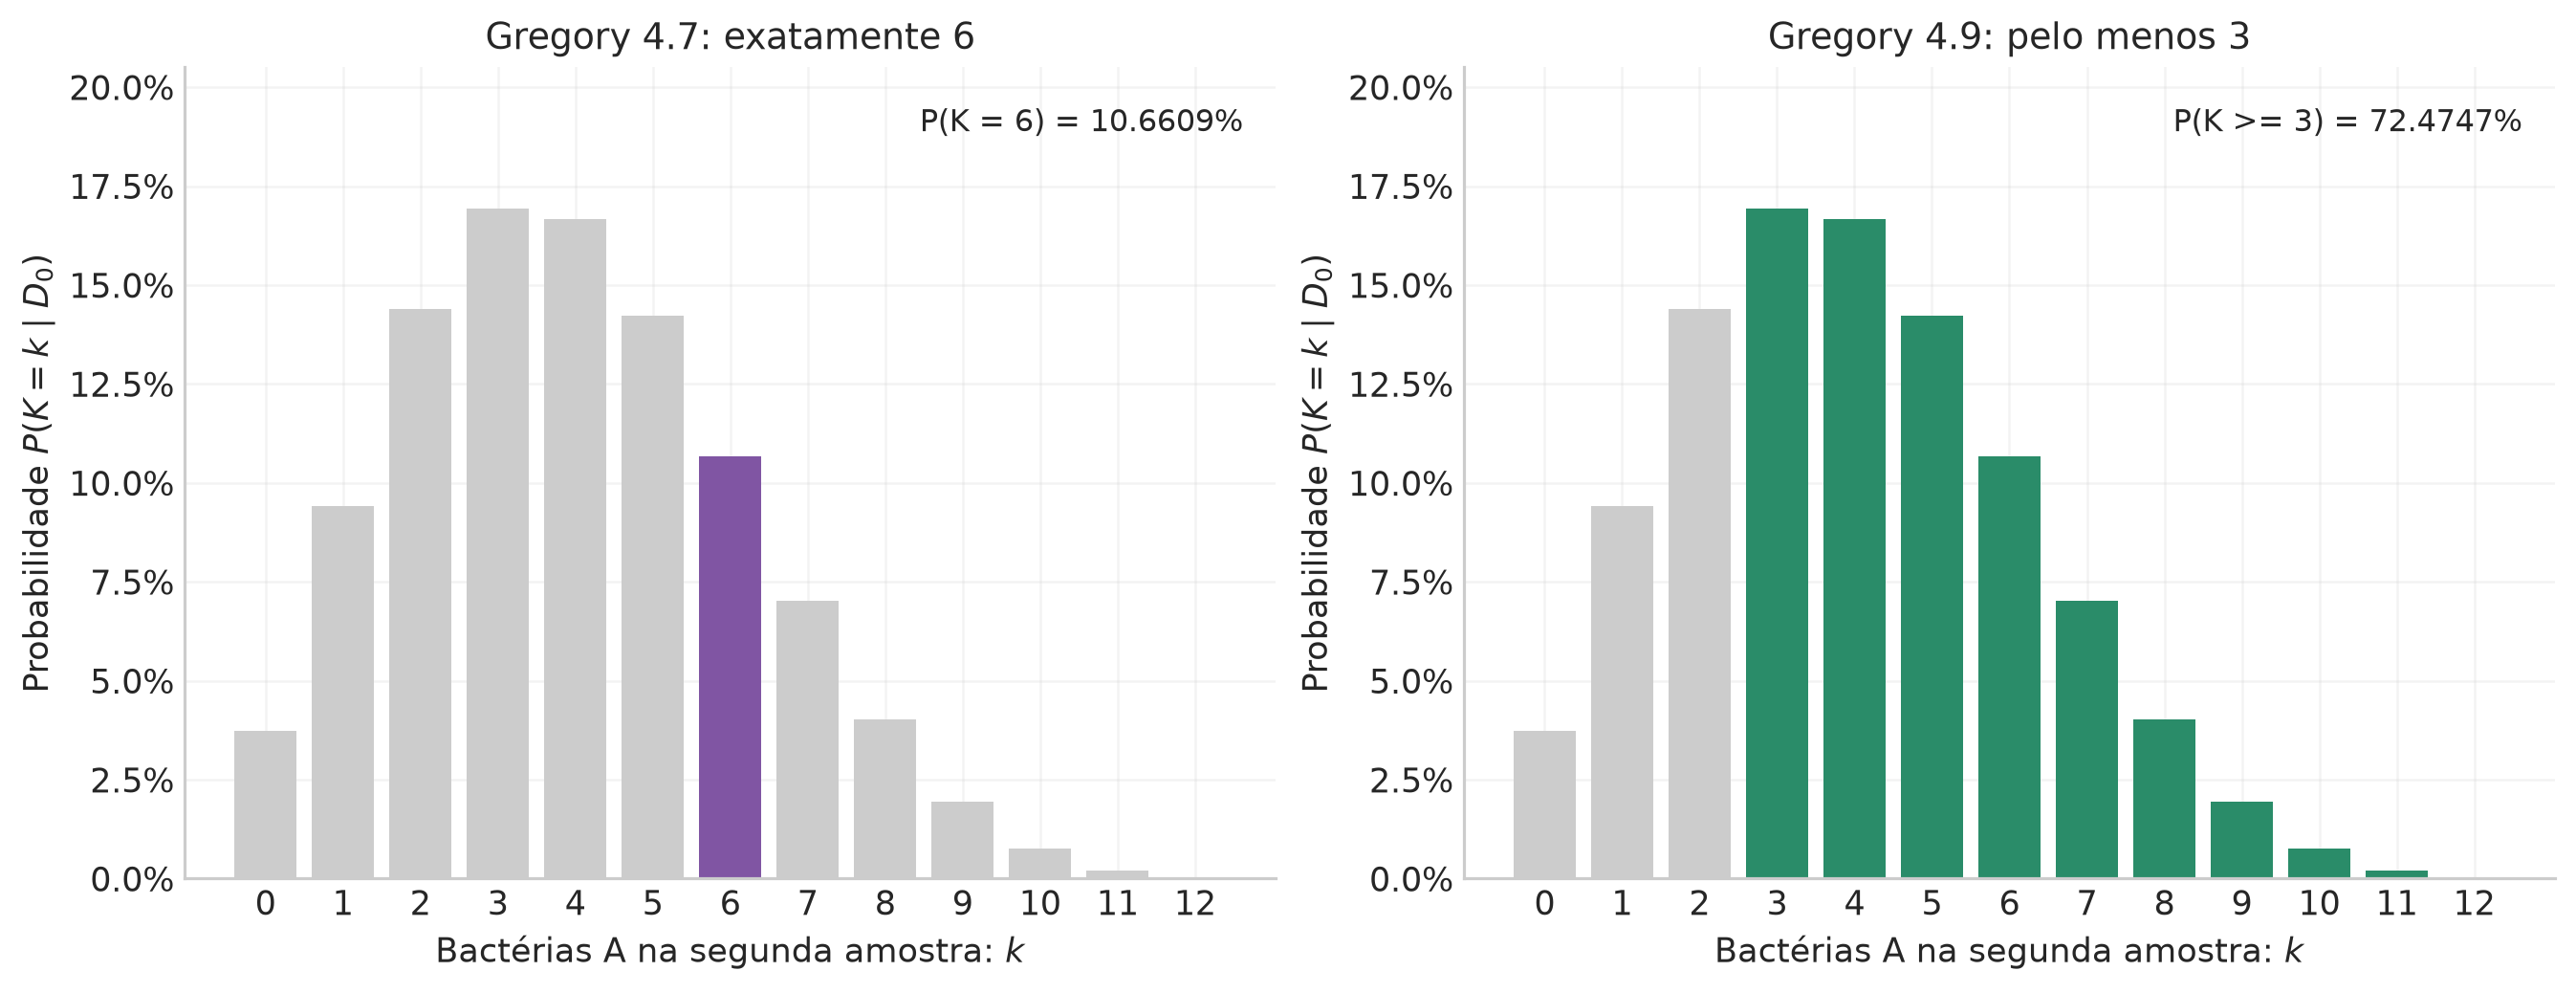

P(K=6) exata = 792/7429; P(K>=3) exata = 2217/3059


In [15]:
def q3_predictive_pmf(m, alpha, beta):
    """Massas beta-binomiais: fórmula deduzida, usando log B para estabilidade."""
    k = np.arange(m+1)
    coefficients = np.array([comb(m, int(j)) for j in k], dtype=float)
    # betaln(a,b) calcula log B(a,b); a função B já foi definida por sua integral.
    return np.exp(np.log(coefficients) + betaln(k+alpha, m-k+beta) - betaln(alpha,beta))

q3_counts = np.arange(q3_m+1)
q3_pmf = q3_predictive_pmf(q3_m, q3_alpha, q3_beta)
q3_cdf = np.cumsum(q3_pmf)
q3_p6 = q3_pmf[6]
q3_patleast3 = q3_pmf[3:].sum()
q3_exact_pmf = [Fraction(comb(q3_m,k))*q3_beta_integer(k+4,20-k)/q3_B for k in range(q3_m+1)]
q3_exact_p6 = q3_exact_pmf[6]
q3_exact_tail = sum(q3_exact_pmf[3:], Fraction(0))

export_table("q3_resultados", ["Exercício", "Evento", "Probabilidade", "Probabilidade (%)"],
             [["Gregory 4.7", r"$K=6$", q3_p6, 100*q3_p6],
              ["Gregory 4.9", r"$K\geq3$", q3_patleast3, 100*q3_patleast3]], [0,0,10,6])
export_table("q3_distribuicao_preditiva", ["K", "P(K | D0)", "Probabilidade (%)", "Probabilidade acumulada"],
             [[k,p,100*p,c] for k,p,c in zip(q3_counts,q3_pmf,q3_cdf)], [0,10,6,10])

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4), layout="constrained")
for ax, mask, color, title, label in [
    (axes[0], q3_counts==6, PURPLE, "Gregory 4.7: exatamente 6", f"P(K = 6) = {q3_p6:.4%}"),
    (axes[1], q3_counts>=3, GREEN, "Gregory 4.9: pelo menos 3", f"P(K >= 3) = {q3_patleast3:.4%}")]:
    ax.bar(q3_counts, q3_pmf, color=[color if selected else "0.8" for selected in mask], width=.8)
    ax.text(.97,.95,label,transform=ax.transAxes,ha="right",va="top",fontsize=10)
    ax.set(xlabel=r"Bactérias A na segunda amostra: $k$", ylabel=r"Probabilidade $P(K=k\mid D_0)$",
            title=title, ylim=(0,.205), xticks=q3_counts)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig, "q3_eventos_preditivos")
print(f"P(K=6) exata = {q3_exact_p6}; P(K>=3) exata = {q3_exact_tail}")

### Ler o evento na distribuição acumulada

Para uma contagem inteira, a CDF é $F_K(k)=P(K\leq k\mid D_0)$. Assim,

$$P(K\geq3\mid D_0)=1-F_K(2),\qquad
P(K>3\mid D_0)=1-F_K(3).$$

O primeiro evento inclui 3; o segundo começa em 4. Não podemos trocar os dois. Também podemos conferir o evento pontual pela altura do salto da CDF:

$$P(K=6\mid D_0)=F_K(6)-F_K(5).$$

Vamos desenhar a acumulada em degraus, respeitando que a contagem é discreta.

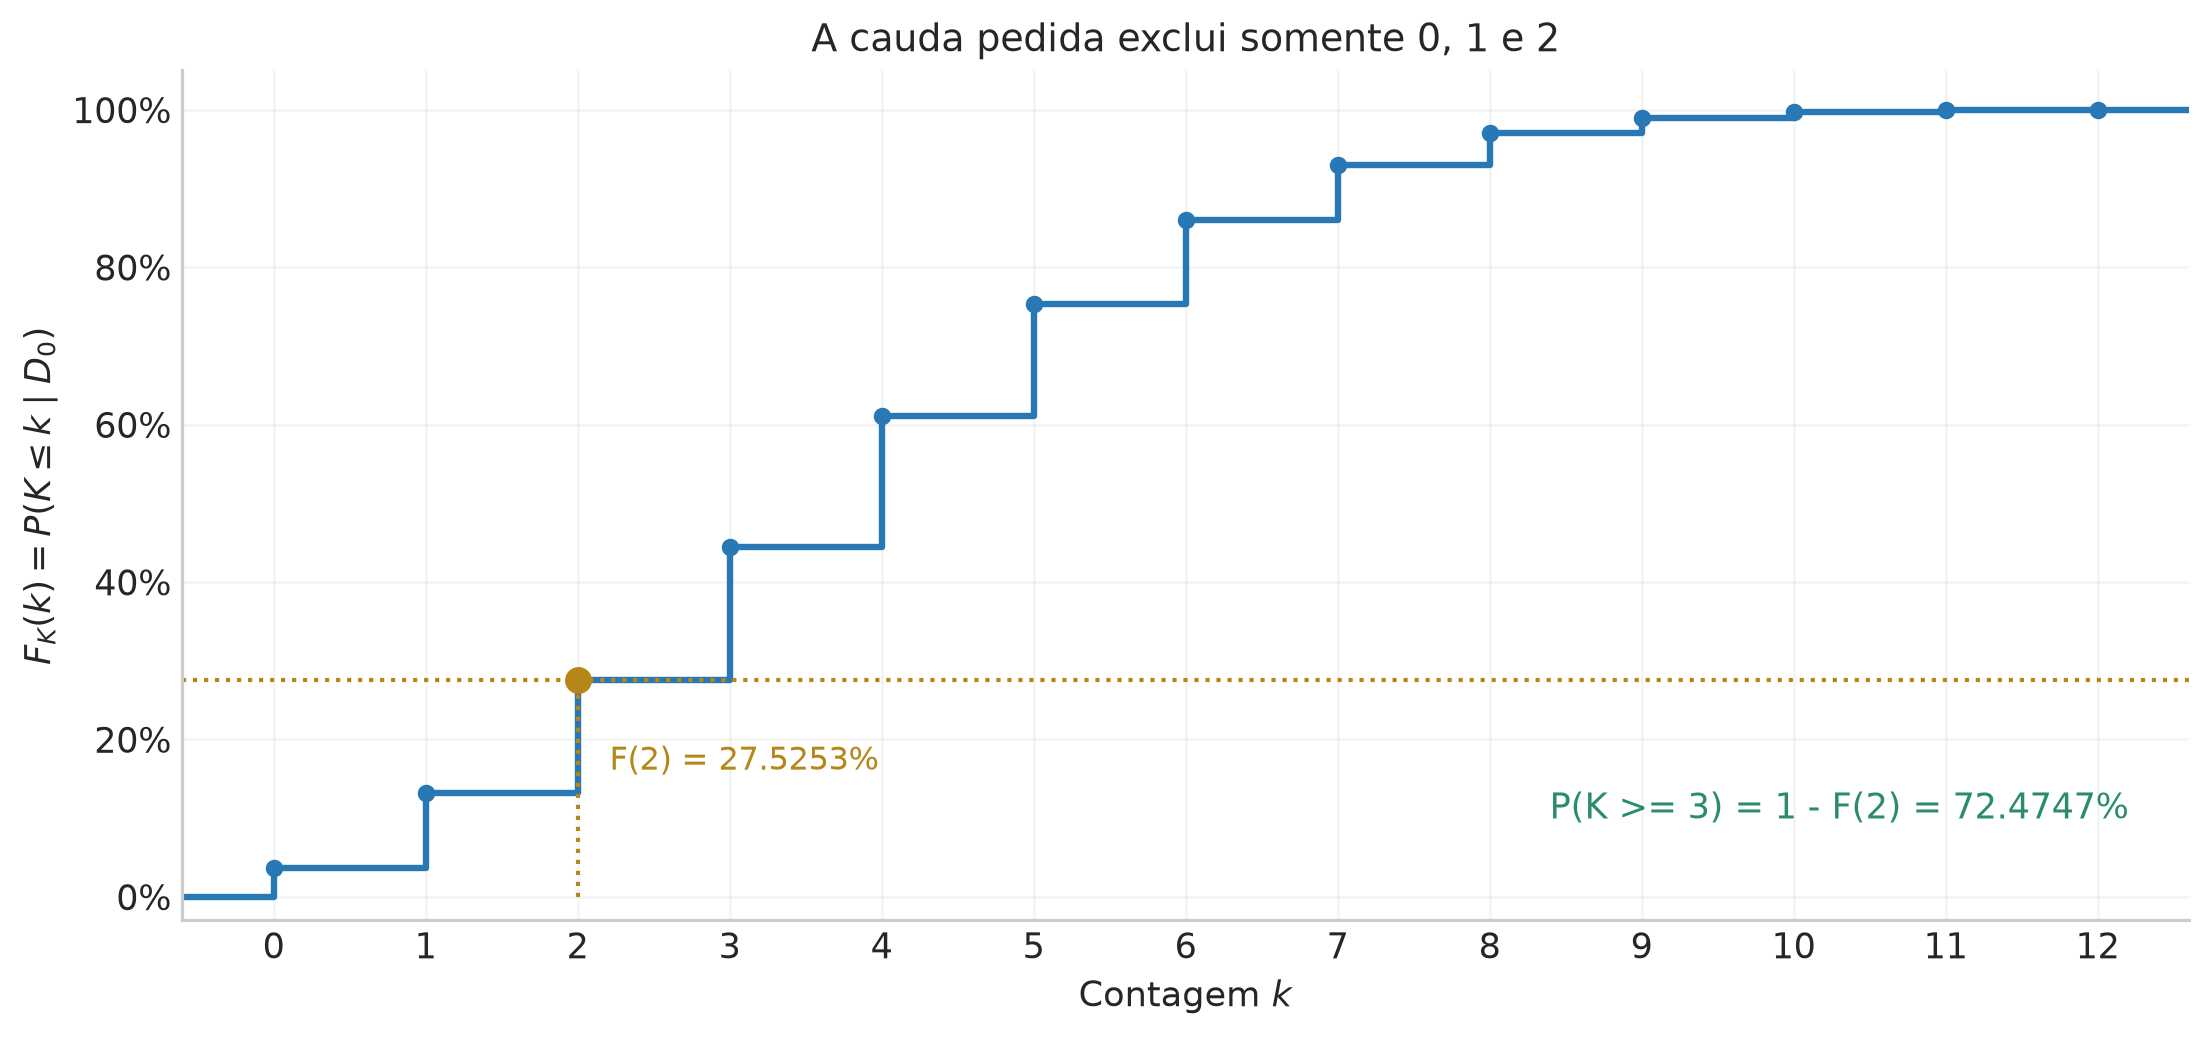

In [16]:
fig, ax = plt.subplots(figsize=(9.5,4.4), layout="constrained")
ax.step(np.r_[-1,q3_counts,13], np.r_[0,q3_cdf,1], where="post", color=BLUE)
ax.scatter(q3_counts,q3_cdf,color=BLUE,s=20,zorder=3)
ax.axhline(q3_cdf[2],color=GOLD,ls=":",lw=1.3)
ax.vlines(2,0,q3_cdf[2],color=GOLD,ls=":",lw=1.3)
ax.scatter([2],[q3_cdf[2]],color=GOLD,s=55,zorder=4)
ax.annotate(f"F(2) = {q3_cdf[2]:.4%}",(2,q3_cdf[2]),xytext=(10,-28),
             textcoords="offset points",color=GOLD,fontsize=10)
ax.text(.97,.12,f"P(K >= 3) = 1 - F(2) = {q3_patleast3:.4%}",
         transform=ax.transAxes,ha="right",color=GREEN,fontsize=11)
ax.set(xlabel=r"Contagem $k$",ylabel=r"$F_K(k)=P(K\leq k\mid D_0)$",
        title="A cauda pedida exclui somente 0, 1 e 2",xticks=q3_counts,
        xlim=(-.6,12.6),ylim=(-.03,1.05))
ax.yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q3_acumulada")

### 4. Comparar com uma binomial sem confundir as perguntas

É instrutivo fazer duas substituições pontuais:

1. Fixar $q=3/10$, a frequência observada e o máximo da likelihood anterior.
2. Fixar $q=\mathbb E[q\mid D_0]=1/3$, a média posterior que vamos deduzir abaixo.

Ambas produzem uma binomial. Nenhuma preserva a incerteza da posterior de $q$. No segundo caso, a média da contagem futura será igual à da beta-binomial, mas sua dispersão ainda será diferente.

A integral de uma função de $q$ não é, em geral, essa função avaliada na média de $q$:

$$\mathbb E\!\left[\binom{12}{k}q^k(1-q)^{12-k}\,\middle|\,D_0\right]
\neq\binom{12}{k}\,\mathbb E[q\mid D_0]^k(1-\mathbb E[q\mid D_0])^{12-k}.$$

Isso retoma diretamente a diferença entre $\mathbb E[g(q)]$ e $g(\mathbb E[q])$. A marginalização não aumenta a probabilidade de **todo** evento; ela redistribui as massas. Por isso precisamos calcular o evento de interesse na distribuição preditiva inteira.

### 5. De onde vem a dispersão adicional?

Podemos abrir os momentos de $q$ usando a mesma integral:

$$\mathbb E[q\mid D_0]=\frac{B(5,8)}{B(4,8)}=\frac13,$$
$$\mathbb E[q^2\mid D_0]=\frac{B(6,8)}{B(4,8)}=\frac5{39},$$
$$\operatorname{Var}(q\mid D_0)=\frac5{39}-\frac19=\frac2{117},\qquad
\mathbb E[q(1-q)\mid D_0]=\frac13-\frac5{39}=\frac8{39}.$$

Para um $q$ fixo, $\mathbb E[K\mid q]=mq$ e $\operatorname{Var}(K\mid q)=mq(1-q)$, pelas somas de indicadores Bernoulli. Portanto,

$$\boxed{\mathbb E[K\mid D_0]=m\mathbb E[q\mid D_0]=4.}$$

Para deduzir a variância, usamos $\mathbb E[K^2\mid q]=mq(1-q)+m^2q^2$, integramos em $q$ e subtraímos a média ao quadrado:

$$\begin{aligned}
\operatorname{Var}(K\mid D_0)
&=m\mathbb E[q(1-q)\mid D_0]+m^2\operatorname{Var}(q\mid D_0)\\
&=\underbrace{\frac{32}{13}}_{\text{flutuação da contagem para }q\text{ dado}}
+\underbrace{\frac{32}{13}}_{\text{incerteza na contagem esperada }mq}\\
&=\boxed{\frac{64}{13}\simeq4{,}92308.}
\end{aligned}$$

Uma binomial com $q=1/3$ teria variância $12(1/3)(2/3)=8/3\simeq2{,}66667$. A diferença aparece mesmo quando as médias são iguais. A parte “flutuação para $q$ dado” é a média de $mq(1-q)$ sobre a posterior, e não simplesmente $m\bar q(1-\bar q)$.

Outra maneira de entender o mesmo efeito: sejam $Z_1,Z_2$ os indicadores de duas bactérias da segunda amostra. Dado $q$, $\mathbb E[Z_1Z_2\mid q]=q^2$. Depois de marginalizar,

$$\operatorname{Cov}(Z_1,Z_2\mid D_0)=\mathbb E[q^2\mid D_0]-\mathbb E[q\mid D_0]^2=\operatorname{Var}(q\mid D_0)>0.$$

A incerteza compartilhada correlaciona nossas previsões. Isso não introduz uma interação biológica entre as bactérias: é uma dependência da descrição probabilística depois de integrar o parâmetro comum.

| Modelo | Média de K | Variância de K | P(K = 6) | P(K >= 3) |
| :-- | :-- | :-- | :-- | :-- |
| Preditiva beta-binomial | 4,000000 | 4,923077 | 0,1066092341 | 0,7247466492 |
| Binomial: q = 3/10 | 3,600000 | 2,520000 | 0,0792478958 | 0,7471846521 |
| Binomial: q = 1/3 | 4,000000 | 2,666667 | 0,1112748170 | 0,8188773542 |

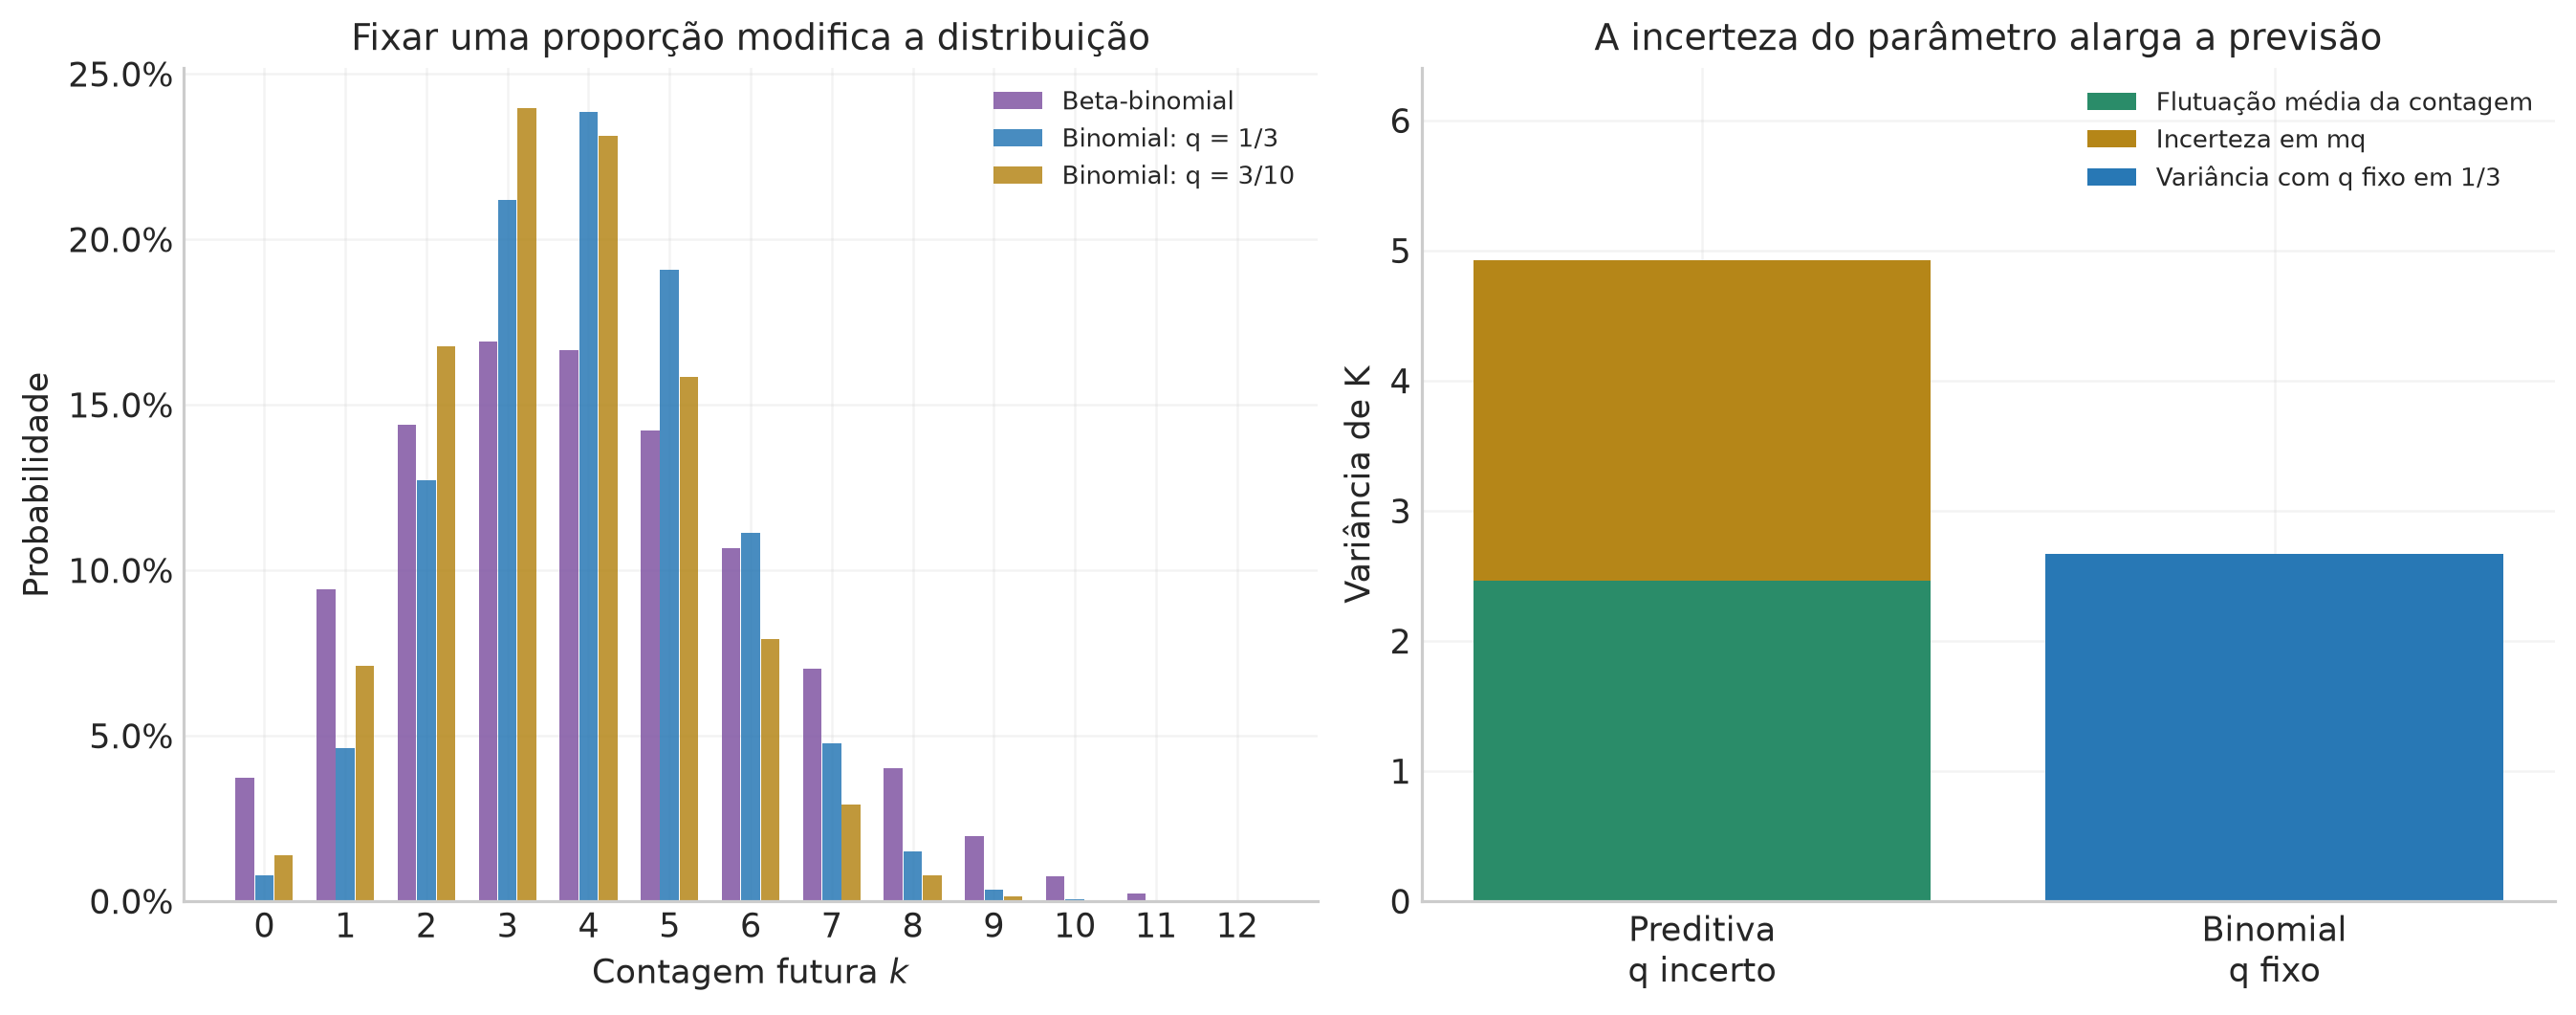

In [17]:
q3_pmf_frequency = binom.pmf(q3_counts,q3_m,q3_r0/q3_n0)
q3_pmf_mean = binom.pmf(q3_counts,q3_m,q3_q_mean)
q3_Eq2 = float(q3_beta_integer(6,8)/q3_B)
q3_varq = q3_Eq2-q3_q_mean**2
q3_within = q3_m*(q3_q_mean-q3_Eq2)
q3_between = q3_m**2*q3_varq
q3_meanK = q3_m*q3_q_mean
q3_varK = q3_within+q3_between

q3_models = [
    ["Preditiva beta-binomial",q3_meanK,q3_varK,q3_p6,q3_patleast3],
    ["Binomial: q = 3/10",q3_m*.3,q3_m*.3*.7,q3_pmf_frequency[6],q3_pmf_frequency[3:].sum()],
    ["Binomial: q = 1/3",q3_meanK,q3_m*q3_q_mean*(1-q3_q_mean),q3_pmf_mean[6],q3_pmf_mean[3:].sum()],
]
export_table("q3_comparacao_modelos",["Modelo","Média de K","Variância de K","P(K = 6)","P(K >= 3)"],
             q3_models,[0,6,6,10,10])

fig, axes = plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
for offset,pmf,color,label in [(-.24,q3_pmf,PURPLE,"Beta-binomial"),
                              (0,q3_pmf_mean,BLUE,"Binomial: q = 1/3"),
                              (.24,q3_pmf_frequency,GOLD,"Binomial: q = 3/10")]:
    axes[0].bar(q3_counts+offset,pmf,width=.23,color=color,alpha=.85,label=label)
axes[0].set(xlabel=r"Contagem futura $k$",ylabel="Probabilidade",xticks=q3_counts,
            title="Fixar uma proporção modifica a distribuição")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc="upper right",fontsize=8)
axes[1].bar(0,q3_within,color=GREEN,label="Flutuação média da contagem")
axes[1].bar(0,q3_between,bottom=q3_within,color=GOLD,label="Incerteza em mq")
axes[1].bar(1,q3_m*q3_q_mean*(1-q3_q_mean),color=BLUE,label="Variância com q fixo em 1/3")
axes[1].set_xticks([0,1],["Preditiva\nq incerto","Binomial\nq fixo"])
axes[1].set(ylabel="Variância de K",title="A incerteza do parâmetro alarga a previsão",ylim=(0,6.4))
axes[1].legend(loc="upper right",fontsize=8)
save_figure(fig,"q3_binomial_beta_binomial")

### 6. Quando recuperamos a binomial de proporção conhecida?

Vamos imaginar primeiras amostras maiores, mantendo a frequência observada $r/n=0{,}3$, e prever sempre uma segunda amostra com $m=12$. Com prior uniforme, a posterior seria $\mathrm{Beta}(r+1,n-r+1)$.

A fórmula geral da preditiva é

$$P(K=k\mid r,n)=\binom mk\frac{B(r+k+1,n-r+m-k+1)}{B(r+1,n-r+1)}.$$

Para enxergar seu limite, definimos o produto crescente

$$x^{\overline j}=x(x+1)\cdots(x+j-1),\qquad x^{\overline0}=1.$$

Abrindo os fatoriais nas funções Beta, obtemos

$$P(K=k\mid r,n)=\binom mk
\frac{(r+1)^{\overline k}(n-r+1)^{\overline{m-k}}}{(n+2)^{\overline m}}.$$

Agora tomamos $n\to\infty$, $r/n\to q_0\in(0,1)$ e **$m$ fixo**. Dividimos cada fator por $n$: os primeiros $k$ fatores tendem a $q_0$, os $m-k$ seguintes a $1-q_0$, e os $m$ fatores do denominador tendem a 1. Assim,

$$\boxed{P(K=k\mid r,n)\longrightarrow\binom mk q_0^k(1-q_0)^{m-k}.}$$

A binomial de parâmetro conhecido aparece como limite de uma preditiva cuja incerteza sobre $q$ desaparece. Isso não autoriza antecipar o limite para a primeira amostra pequena de apenas 10 bactérias.

No gráfico, cada posterior foi normalizada em $[0,1]$, embora mostremos um zoom ao redor de $0{,}3$. As massas da contagem futura são calculadas em todo o suporte $0,\ldots,12$.

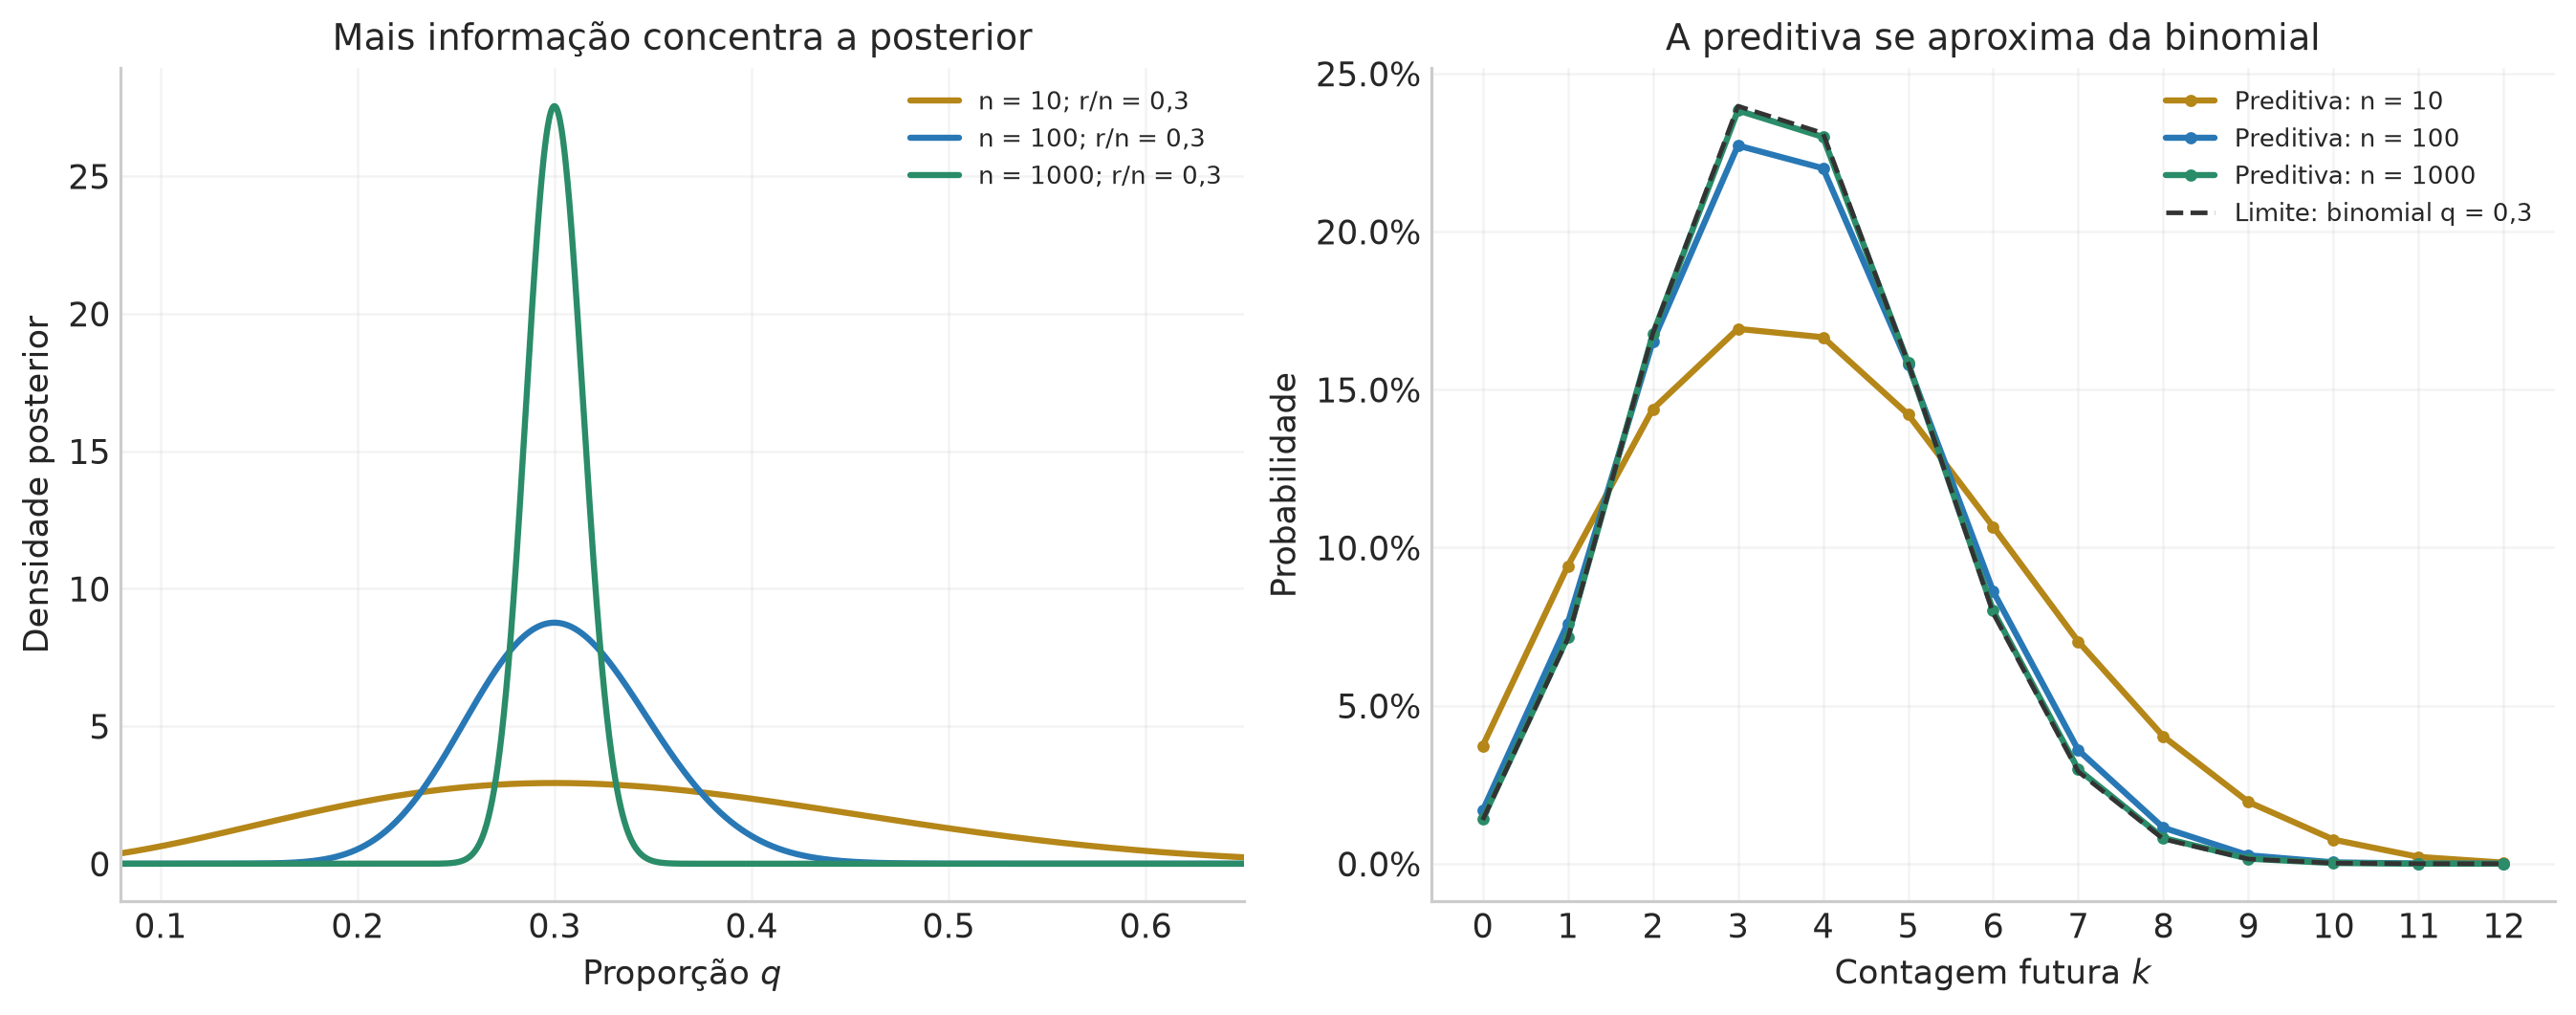

In [18]:
q3_zoom = np.linspace(.08,.65,2400)
fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
for n_previous,color in zip([10,100,1000],[GOLD,BLUE,GREEN]):
    r_previous = 3*n_previous//10
    a_post,b_post = r_previous+1,n_previous-r_previous+1
    axes[0].plot(q3_zoom,beta_distribution.pdf(q3_zoom,a_post,b_post),color=color,
                 label=f"n = {n_previous}; r/n = 0,3")
    axes[1].plot(q3_counts,q3_predictive_pmf(q3_m,a_post,b_post),color=color,
                 marker="o",ms=3,label=f"Preditiva: n = {n_previous}")
axes[1].plot(q3_counts,q3_pmf_frequency,color="0.2",ls="--",lw=1.5,label="Limite: binomial q = 0,3")
axes[0].set(xlabel=r"Proporção $q$",ylabel="Densidade posterior",title="Mais informação concentra a posterior",xlim=(.08,.65))
axes[1].set(xlabel=r"Contagem futura $k$",ylabel="Probabilidade",title="A preditiva se aproxima da binomial",xticks=q3_counts)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:ax.legend(loc="upper right",fontsize=8)
save_figure(fig,"q3_limite_binomial")

### 7. A escolha da prior faz parte da resposta

Os valores principais acima usam $\pi(q)=1$. Para explicitar essa dependência, consideremos uma prior Beta com parâmetros $a_0,b_0>0$, já definida pela sua densidade. Multiplicar pelos fatores da likelihood produz

$$q^{a_0-1}(1-q)^{b_0-1}\,q^{r_0}(1-q)^{n_0-r_0}
=q^{a_0+r_0-1}(1-q)^{b_0+n_0-r_0-1}.$$

Normalizar a expressão dá $q\mid D_0\sim\mathrm{Beta}(a_0+3,b_0+7)$. A preditiva usa esses mesmos parâmetros na integral que já deduzimos.

Vamos comparar a uniforme, uma prior $\mathrm{Beta}(2,2)$ que favorece valores centrais e uma $\mathrm{Beta}(1,4)$ que favorece proporções menores. As duas últimas são **cenários ilustrativos de informação anterior**, sem evidência fornecida pelo enunciado que as torne preferíveis. Não vamos misturar seus resultados com a resposta principal. A tabela mostra por que declarar a prior é necessário quando a amostra inicial é pequena.

In [19]:
q3_prior_rows=[]
for label,a0,b0 in [("Uniforme: Beta(1,1)",1,1),("Central: Beta(2,2)",2,2),
                    ("Proporções menores: Beta(1,4)",1,4)]:
    aa,bb=a0+q3_r0,b0+q3_n0-q3_r0
    pmf=q3_predictive_pmf(q3_m,aa,bb)
    q3_prior_rows.append([label,aa,bb,aa/(aa+bb),pmf[6],pmf[3:].sum()])
export_table("q3_sensibilidade_prior",["Prior","alpha posterior","beta posterior","Média de q","P(K = 6)","P(K >= 3)"],
             q3_prior_rows,[0,0,0,6,10,10])

| Prior | alpha posterior | beta posterior | Média de q | P(K = 6) | P(K >= 3) |
| :-- | :-- | :-- | :-- | :-- | :-- |
| Uniforme: Beta(1,1) | 4 | 8 | 0,333333 | 0,1066092341 | 0,7247466492 |
| Central: Beta(2,2) | 5 | 9 | 0,357143 | 0,1212680038 | 0,7768878719 |
| Proporções menores: Beta(1,4) | 4 | 11 | 0,266667 | 0,0696513663 | 0,5956521739 |

# Questão 4 · Distribuição da média: simulação e convolução por FFT

A questão corresponde ao **problema 5.5 do Gregory**. Temos variáveis $X_1,\ldots,X_n$ independentes e identicamente distribuídas, cada uma com distribuição $\mathrm{Beta}(2,4)$. Queremos a **PDF da média** de $n$ medidas.

O objeto pedido é a distribuição dos valores possíveis de

$$\boxed{\bar X_n=\frac1n\sum_{i=1}^nX_i.}$$

Vou fazer as duas construções propostas no livro: primeiro gerar muitas amostras e calcular suas médias, que é a abordagem mais direta; depois construir a PDF da soma por convoluções e usar a FFT. A expressão matemática por convolução também será deduzida, para deixar claro o que os dois algoritmos aproximam.

Nos itens, vamos:

- **(a)** mostrar as quatro PDFs para $n=1,3,5,8$, com área unitária;
- **(b)** calcular média e variância por integração das PDFs obtidas, usando os resultados teóricos como conferência;
- **(c)** comparar $n=5$ e $n=8$ com gaussianas de mesma média e variância e interpretar a aproximação.

### Notação e o que estamos repetindo

| Símbolo | Significado |
|:--|:--|
| $X_i$ | Uma variável da população Beta$(2,4)$ |
| $S_n=\sum_iX_i$ | Soma de uma amostra com $n$ medidas |
| $\bar X_n=S_n/n$ | Estatística média, antes de observar uma amostra |
| $x_i$, $\bar x_n$ | Valores observados de uma medida e de uma média |
| $n$ | Número de medidas **em cada amostra**: 1, 3, 5 ou 8 |
| $M$ | Número de amostras independentes simuladas para construir uma distribuição de médias |
| $h=1/J$ | Espaçamento da malha numérica; $J+1$ pontos cobrem $[0,1]$ |
| $L$ | Comprimento da transformação discreta usada na FFT |

Uma linha de $n$ valores gera **uma** média. Precisamos de $M$ linhas, cada uma com $n$ novos valores, para estimar sua distribuição por Monte Carlo. Aumentar $M$ melhora nossa precisão numérica; aumentar $n$ modifica a própria distribuição da média. São papéis diferentes.

Aqui os parâmetros 2 e 4 da população já foram fornecidos. Estamos calculando uma **distribuição amostral de uma estatística**, sem inferir um parâmetro desconhecido e sem escolher uma prior. A presença de uma distribuição Beta não torna este problema uma atualização bayesiana como a questão anterior.

### A PDF de cada medida: tornar explícita a normalização

O enunciado escreve a Beta com a função Gamma. Para não deixar a notação implícita, definimos

$$\Gamma(a)=\int_0^\infty t^{a-1}e^{-t}\,dt,\qquad a>0.$$

A integração por partes fornece $\Gamma(a+1)=a\Gamma(a)$, pois o termo de fronteira $[-t^ae^{-t}]_0^\infty$ é zero; além disso, $\Gamma(1)=1$. Portanto, para inteiros positivos, $\Gamma(k)=(k-1)!$.

Para $\alpha=2$ e $\beta=4$, a constante é

$$\frac{\Gamma(\alpha+\beta)}{\Gamma(\alpha)\Gamma(\beta)}
=\frac{\Gamma(6)}{\Gamma(2)\Gamma(4)}=\frac{5!}{1!3!}=20.$$

Assim, a densidade de uma medida é

$$\boxed{f_X(x)=\begin{cases}20x(1-x)^3,&0<x<1,\\0,&\text{fora desse intervalo}.\end{cases}}$$

A normalização pode ser conferida sem uma função especial:

$$\int_0^120x(1-x)^3\,dx
=20\left[\frac{x^2}{2}-x^3+\frac{3x^4}{4}-\frac{x^5}{5}\right]_0^1=1.$$

Como $0\leq X_i\leq1$, a soma satisfaz $0\leq S_n\leq n$ e a média continua em $0\leq\bar X_n\leq1$. A distribuição da média vai estreitar dentro desse mesmo suporte; não devemos ampliar seu suporte para $[0,n]$.

In [20]:
# Questão 4: distribuições de médias, sem depender de dados externos.
from scipy.fft import rfft, irfft, next_fast_len
from scipy.integrate import cumulative_trapezoid

q4_ns = (1,3,5,8)
q4_colors = {1:BLUE,3:GOLD,5:GREEN,8:PURPLE}

def q4_population_pdf(x):
    """PDF Beta(2,4), com o suporte e a constante escritos explicitamente."""
    x=np.asarray(x,dtype=float)
    u=np.clip(x,0,1)
    return np.where((x>=0)&(x<=1),20*u*(1-u)**3,0.0)

def q4_pdf_moments(x,pdf):
    """Integra uma PDF tabulada: área, média, variância e assimetria."""
    area=trapezoid(pdf,x)
    mean=trapezoid(x*pdf,x)/area
    variance=trapezoid((x-mean)**2*pdf,x)/area
    third=trapezoid((x-mean)**3*pdf,x)/area
    return {"area":area,"mean":mean,"variance":variance,"skewness":third/variance**1.5}

print("Área da PDF original por quadratura:",quad(q4_population_pdf,0,1)[0])

Área da PDF original por quadratura: 1.0


### A construção matemática: primeiro a soma, depois a média

Vamos escrever $g_n(s)$ para a PDF de $S_n$. Se $S_n$ e a próxima medida $X_{n+1}$ são independentes, condicionamos no valor $u$ dessa medida e integramos:

$$g_{n+1}(s)=\int_{-\infty}^{\infty}g_n(s-u)f_X(u)\,du=(g_n*f_X)(s).$$

O símbolo $*$ representa **convolução**. Começando por $g_1=f_X$, obtemos

$$g_n=\underbrace{f_X*f_X*\cdots*f_X}_{n\text{ fatores}}.$$

Por exemplo, para duas medidas,

$$g_2(s)=\int_{\max(0,s-1)}^{\min(1,s)}f_X(u)f_X(s-u)\,du,\qquad0<s<2.$$

Os limites exigem simultaneamente $0<u<1$ e $0<s-u<1$. Esta expressão já define a PDF da soma; não estamos supondo uma forma Beta para o resultado.

Para passar à média, usamos sua acumulada:

$$F_{\bar X_n}(x)=P(S_n/n\leq x)=P(S_n\leq nx)=F_{S_n}(nx).$$

Derivando em $x$, aparece o jacobiano da mudança de escala:

$$\boxed{f_{\bar X_n}(x)=n\,g_n(nx),\qquad0<x<1.}$$

A altura precisa multiplicar por $n$ porque a escala horizontal foi comprimida por $n$. Sem esse fator, a área seria $1/n$. Com ele,

$$\int_0^1n\,g_n(nx)\,dx=\int_0^ng_n(s)\,ds=1.$$

Essa é a resposta matemática geral para a PDF da média. Os métodos seguintes a aproximam numericamente, como propõe o exercício.

### Método 1 · O caminho mais direto: médias de muitas amostras

Para cada $n$, geramos $M$ amostras independentes. Se $r$ identifica a repetição, calculamos

$$\bar x_n^{(r)}=\frac1n\sum_{i=1}^nx_i^{(r)},\qquad r=1,\ldots,M.$$

Um histograma desses $M$ valores aproxima $f_{\bar X_n}$. Para uma classe $[a_j,b_j)$ com $c_j$ médias, a altura é

$$h_j=\frac{c_j}{M(b_j-a_j)}.$$

A área da classe é $c_j/M$; somar todas as classes fornece área 1. Aqui cobrimos o suporte inteiro $[0,1]$, sem descartar caudas. A altura é uma **densidade** e pode ultrapassar 1, pois é a área, e não a altura isolada, que representa probabilidade.

Usaremos $M=500\,000$ repetições para cada $n$. Para evitar guardar matrizes grandes sem necessidade, geramos as medidas em blocos e conservamos apenas suas médias. A semente permite reproduzir as mesmas simulações.

In [21]:
q4_M=500_000
q4_rng=np.random.default_rng(20261024+400)
q4_hist_edges=np.linspace(0,1,251)
q4_mc={}
for n in q4_ns:
    means=np.empty(q4_M)
    for start in range(0,q4_M,50_000):
        stop=min(start+50_000,q4_M)
        sample=q4_rng.beta(2,4,size=(stop-start,n))
        means[start:stop]=sample.mean(axis=1)
    counts,_=np.histogram(means,bins=q4_hist_edges)
    density=counts/(q4_M*np.diff(q4_hist_edges))
    q4_mc[n]={"means":means,"density":density,"counts":counts}
print(f"Geradas {q4_M:,} médias para cada n; total de médias: {len(q4_ns)*q4_M:,}.")

Geradas 500,000 médias para cada n; total de médias: 2,000,000.


### Método 2 · Convoluções pelo teorema de Fourier e pela FFT

Adotamos a convenção de transformada

$$\widehat f(k)=\int_{-\infty}^{\infty}f(x)e^{-ikx}\,dx,\qquad
f(x)=\frac1{2\pi}\int_{-\infty}^{\infty}\widehat f(k)e^{ikx}\,dk.$$

Aqui $k$ é a variável conjugada à posição $x$. O teorema da convolução segue da substituição $v=s-u$:

$$\begin{aligned}
\widehat{f*g}(k)
&=\int ds\int du\,f(u)g(s-u)e^{-iks}\\
&=\int f(u)e^{-iku}\,du\int g(v)e^{-ikv}\,dv
=\widehat f(k)\widehat g(k).
\end{aligned}$$

Logo, a transformada da soma é $\widehat g_n(k)=\widehat f_X(k)^n$. Em uma malha finita, usamos a **transformada discreta de Fourier**, ou DFT. A **FFT** é o algoritmo rápido para calculá-la;

#### Densidades e pesos discretos: Espaçamento da malha

Tomamos $x_j=jh$, $j=0,\ldots,J$, com $h=1/J$. Os números $f_X(x_j)$ são densidades. Para trabalhar com pesos de quadratura, definimos

$$A_h=h\sum_{j=0}^{J}f_X(x_j),\qquad
w_j=\frac{h f_X(x_j)}{A_h},\qquad\sum_jw_j=1.$$

$A_h$ aproxima a integral 1. Como a PDF vale zero nas duas extremidades, essa soma coincide com a regra dos trapézios nesta malha. A divisão por $A_h$ corrige o pequeno erro de quadratura inicial, que vamos registrar e conferir ao refinar a resolução. Os $w_j$ aproximam massas de pequenos intervalos; não atribuem átomos à variável contínua original.

Depois de completar a sequência com zeros até comprimento $L$, usamos índices inteiros $k,\ell=0,\ldots,L-1$ na DFT e calculamos

$$\widetilde w_k=\sum_{j=0}^{L-1}w_j e^{-2\pi ijk/L},\qquad
v_\ell=\frac1L\sum_{k=0}^{L-1}\widetilde w_k^{\,n}e^{2\pi ik\ell/L}.$$

Com espaço suficiente, $v_\ell$ é o peso da soma no ponto $s_\ell=\ell h$. Para recuperar densidades,

$$g_n(s_\ell)\simeq\frac{v_\ell}{h},\qquad
\boxed{f_{\bar X_n}(s_\ell/n)\simeq\frac{n v_\ell}{h}.}$$

O fator $1/h$ converte peso em densidade e o fator $n$ vem da transformação da soma para a média. Não devemos misturar esses dois fatores.

#### Por que preencher com zeros?

A DFT trata as sequências como **periódicas** e seu produto gera uma convolução circular. A convolução linear de $n$ vetores com $J+1$ elementos tem

$$n[(J+1)-1]+1=nJ+1$$

elementos. Precisamos de $\boxed{L\geq nJ+1}$ para que a soma inteira caiba antes da repetição periódica. Sem isso, a parte que excede a janela é somada ao começo: a distribuição é dobrada sobre si mesma.

O preenchimento com zeros não cria novas medidas nem modifica a população. Ele reserva espaço para a soma, cujo suporte cresceu de $[0,1]$ para $[0,n]$. Escolher um comprimento um pouco maior e conveniente à FFT só facilita o cálculo.

In [22]:
def q4_fft_density(n,J=4096):
    """PDF da média por convolução linear, com padding e fatores de escala explícitos."""
    if n<1 or int(n)!=n or J<2:
        raise ValueError("n deve ser inteiro positivo e J deve ser pelo menos 2.")
    h=1/J
    x=np.linspace(0,1,J+1)
    original=q4_population_pdf(x)
    input_area=h*original.sum()
    weights=h*original/input_area
    needed=n*J+1
    length=next_fast_len(needed,real=True)
    spectrum=rfft(weights,n=length)
    mass=irfft(spectrum**n,n=length)[:needed]
    negative_mass=-mass[mass<0].sum()
    if mass.min() < -1e-12:
        raise RuntimeError("A convolução gerou pesos negativos além do erro de arredondamento.")
    mass=np.maximum(mass,0)  # Remove somente resíduos negativos de precisão de máquina.
    sum_grid=np.arange(needed)*h
    mean_grid=sum_grid/n
    mean_pdf=n*mass/h
    area_before=trapezoid(mean_pdf,mean_grid)
    if not np.isclose(area_before,1,rtol=0,atol=1e-9):
        raise RuntimeError("A área da convolução ficou incorreta; não ocultar o erro renormalizando.")
    # Depois da conferência, remove o resíduo numérico de normalização.
    mass=mass/area_before
    mean_pdf=mean_pdf/area_before
    sum_pdf=mass/h
    return {"n":n,"J":J,"h":h,"L":length,"weights":weights,"input_area":input_area,
            "area_before":area_before,"negative_mass":negative_mass,"mass":mass,
            "sum_grid":sum_grid,"sum_pdf":sum_pdf,"x":mean_grid,"pdf":mean_pdf,
            "moments":q4_pdf_moments(mean_grid,mean_pdf)}

q4_fft={n:q4_fft_density(n,J=4096) for n in q4_ns}
export_table("q4_fft_configuracao",["n","J","Comprimento FFT","Área inicial","Área antes do ajuste","Massa negativa removida"],
             [[n,d["J"],d["L"],d["input_area"],d["area_before"],d["negative_mass"]]
              for n,d in q4_fft.items()],[0,0,0,10,12,16])

| n | J | Comprimento FFT | Área inicial | Área antes do ajuste | Massa negativa removida |
| :-- | :-- | :-- | :-- | :-- | :-- |
| 1 | 4096 | 4320 | 0,9999999007 | 1,000000000000 | 0,0000000000000000 |
| 3 | 4096 | 12500 | 0,9999999007 | 1,000000000000 | 0,0000000000000000 |
| 5 | 4096 | 20736 | 0,9999999007 | 1,000000000000 | 0,0000000000000000 |
| 8 | 4096 | 32805 | 0,9999999007 | 1,000000000000 | 0,0000000000000001 |

### Visualizar o erro de uma convolução circular

Vamos usar $n=3$ para mostrar o que aconteceria se ignorássemos o preenchimento com zeros. À esquerda, estendemos a PDF de entrada por zeros fora de $[0,1]$. À direita, comparamos a PDF correta da **soma** $S_3$ com o resultado de uma DFT curta, de comprimento $J+1$.

A sequência curta tem período $(J+1)h$ e mistura contribuições que deveriam ocupar regiões diferentes de $[0,3]$. É possível que seus pesos ainda somem 1: **normalizar não corrige uma convolução circular calculada no lugar da convolução linear**. Por isso conferir só a área seria insuficiente.

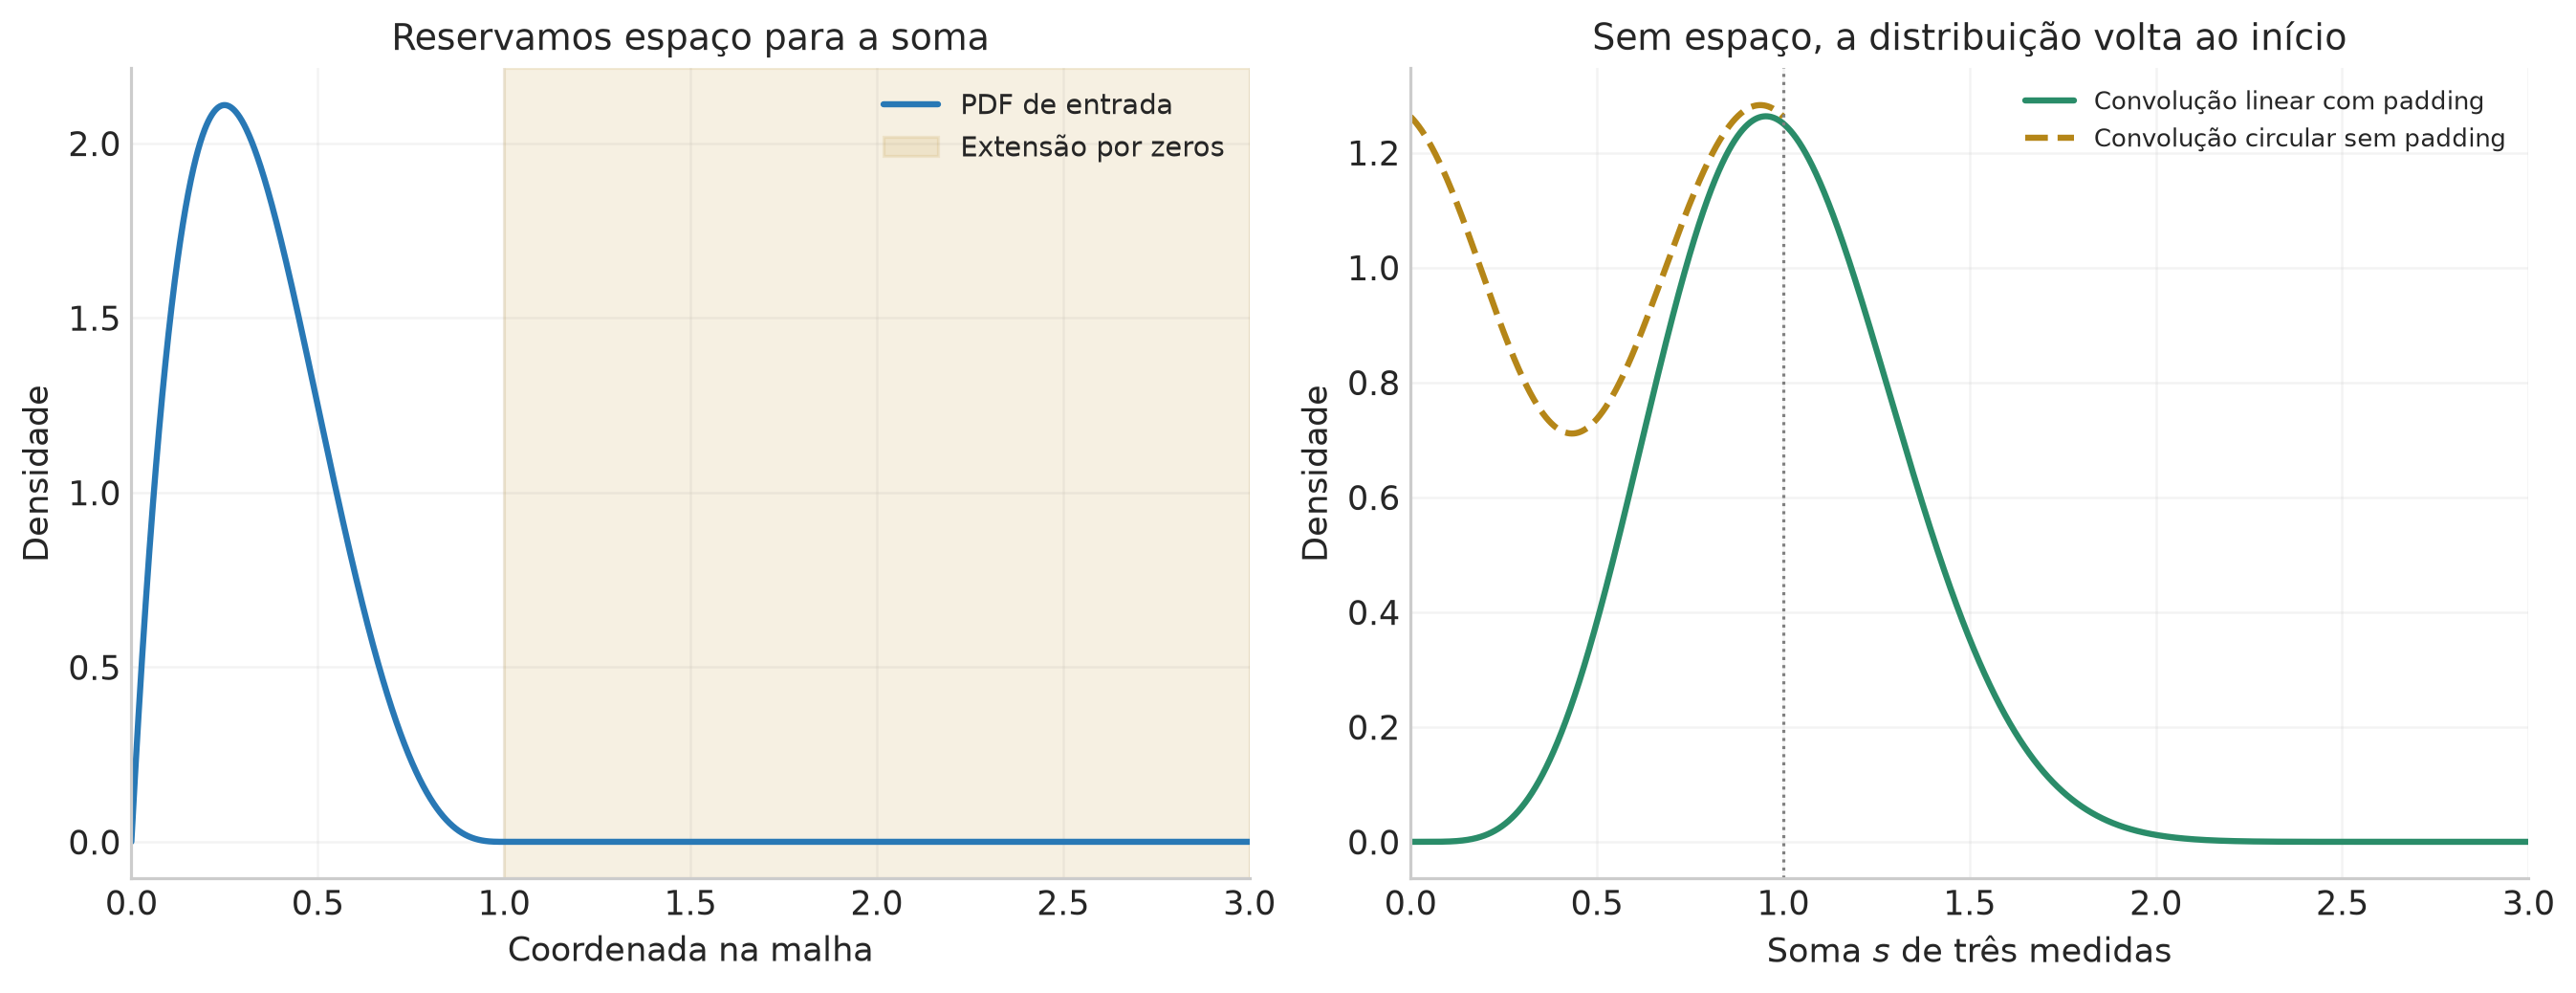

In [23]:
q4_demo=q4_fft[3]
q4_short_length=len(q4_demo["weights"])
q4_circular=irfft(rfft(q4_demo["weights"],n=q4_short_length)**3,n=q4_short_length)
q4_period=q4_short_length*q4_demo["h"]
q4_circular_grid=np.arange(q4_short_length+1)*q4_demo["h"]
q4_circular_pdf=np.r_[q4_circular,q4_circular[0]]/q4_demo["h"]
fig,axes=plt.subplots(1,2,figsize=(11.6,4.4),layout="constrained")
q4_extended=np.linspace(0,3,2500)
axes[0].plot(q4_extended,q4_population_pdf(q4_extended),color=BLUE,label="PDF de entrada")
axes[0].axvspan(1,3,color=GOLD,alpha=.12,label="Extensão por zeros")
axes[0].set(xlabel="Coordenada na malha",ylabel="Densidade",title="Reservamos espaço para a soma",xlim=(0,3))
axes[0].legend(loc="upper right")
axes[1].plot(q4_demo["sum_grid"],q4_demo["sum_pdf"],color=GREEN,label="Convolução linear com padding")
axes[1].plot(q4_circular_grid,q4_circular_pdf,color=GOLD,ls="--",label="Convolução circular sem padding")
axes[1].axvline(q4_period,color="0.5",ls=":",lw=1)
axes[1].set(xlabel=r"Soma $s$ de três medidas",ylabel="Densidade",title="Sem espaço, a distribuição volta ao início",xlim=(0,3))
axes[1].legend(loc="upper right",fontsize=8)
save_figure(fig,"q4_fft_padding")

## Item (a) · As quatro PDFs, com área unitária

Agora mostramos os resultados para $n=1,3,5,8$ nos dois métodos. No painel de Monte Carlo, cada curva em degraus é uma densidade de histograma. No painel da FFT, as curvas vêm da convolução e da mudança $\bar X_n=S_n/n$.

Cada painel contém as quatro distribuições no mesmo sistema de eixos. Todas têm **área 1**. Quando a distribuição fica mais estreita, seu pico precisa subir. Para $n=1$, a média é a própria variável e recuperamos a Beta$(2,4)$ original.

Na PDF original ($n=1$), a derivada é $f_X'(x)=20(1-x)^2(1-4x)$, e o máximo interior está em $x=1/4$. Esse pico não é a média $1/3$ que calcularemos no item (b): a distribuição é assimétrica. As convoluções reduzem essa assimetria à medida que $n$ cresce.

A simulação ainda tem ruído de contagem nas classes. A FFT evita esse ruído amostral, mas introduz um erro de malha, que será avaliado separadamente.

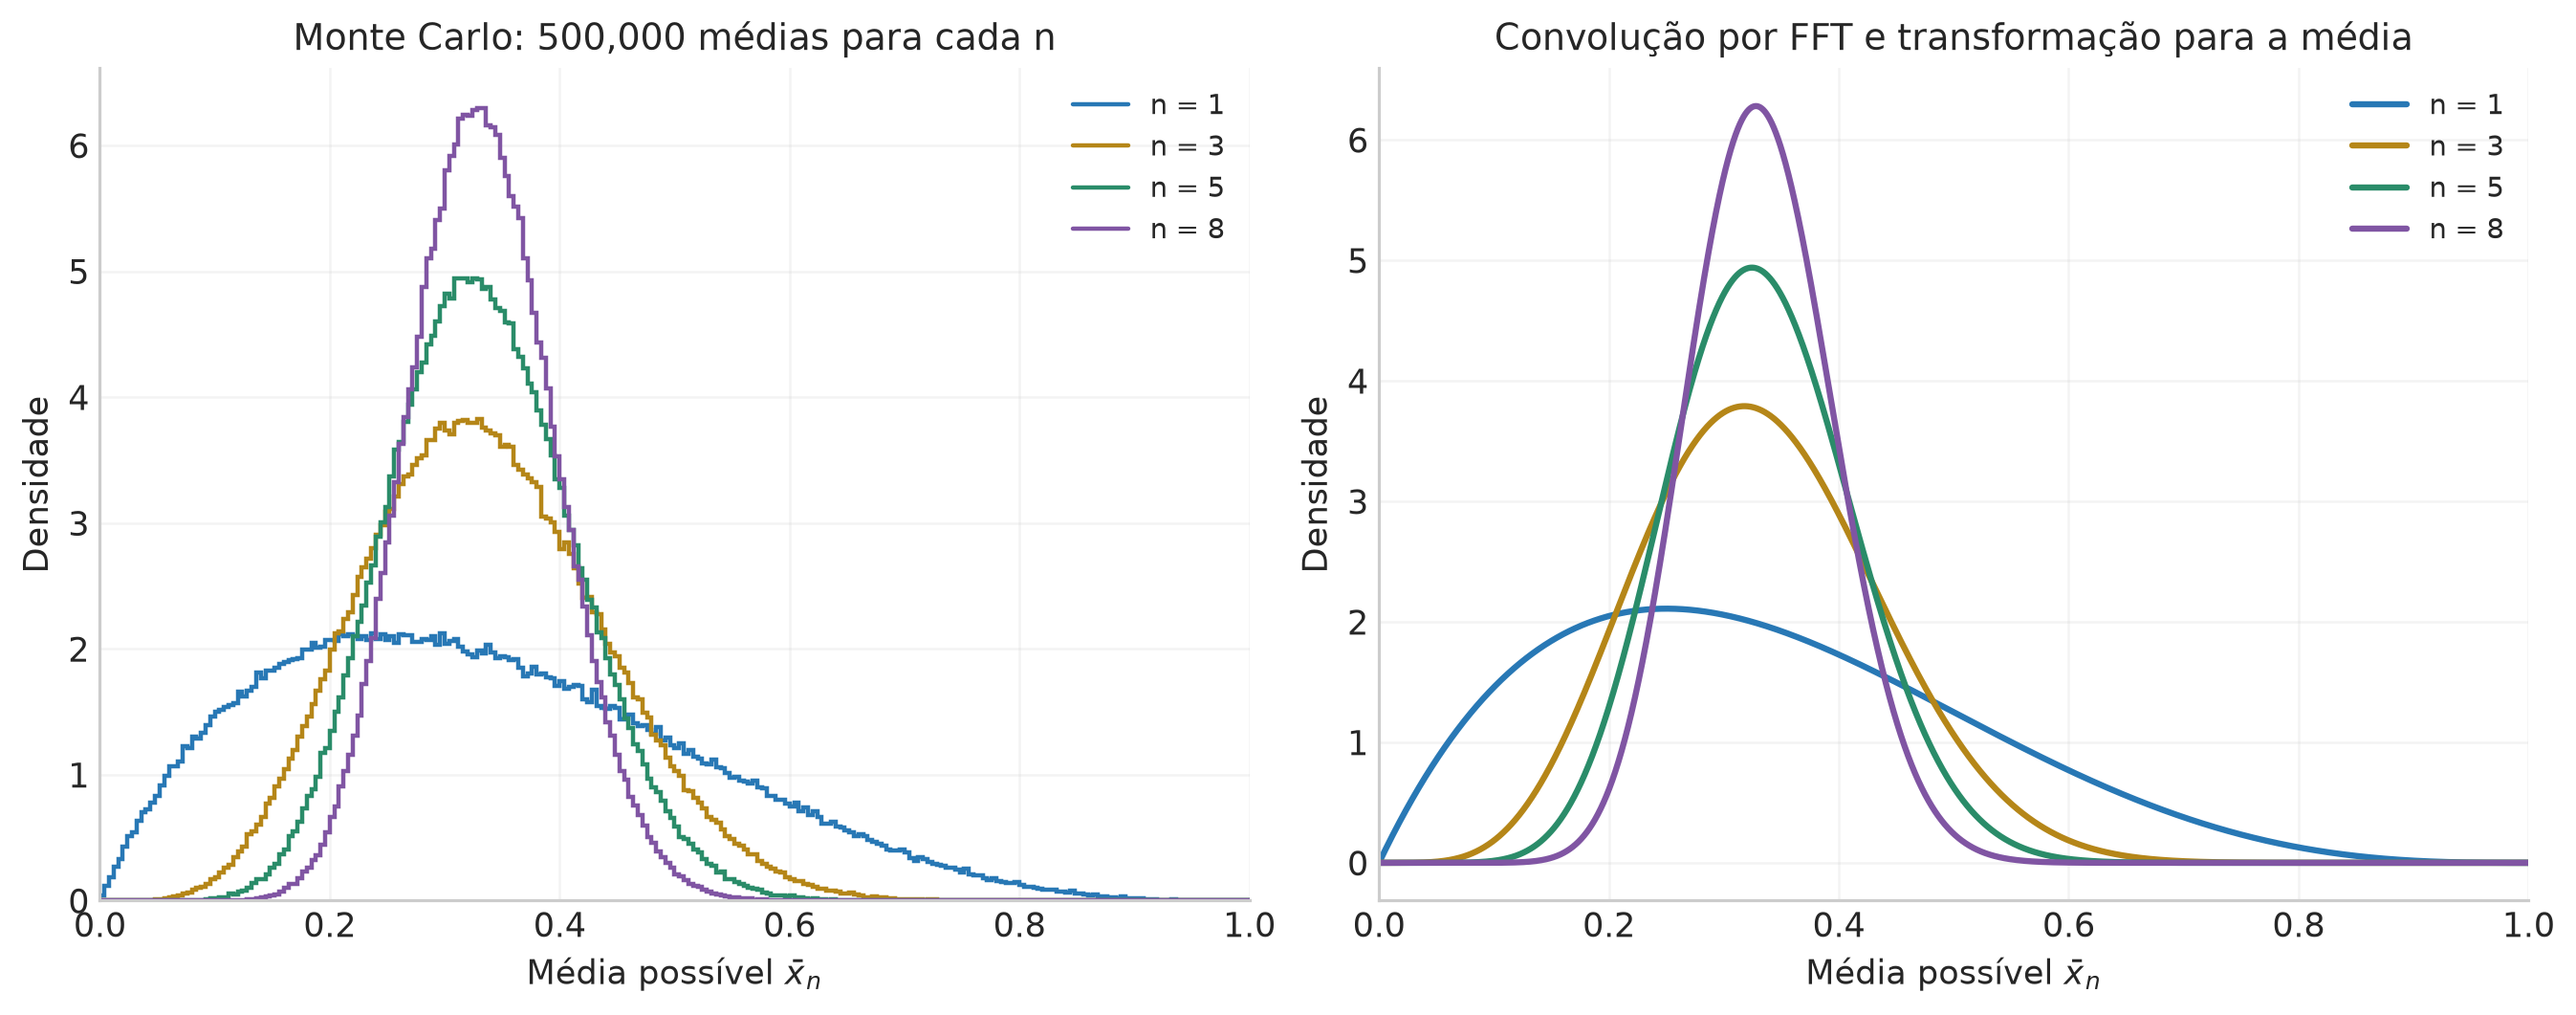

In [24]:
fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
for n in q4_ns:
    axes[0].stairs(q4_mc[n]["density"],q4_hist_edges,color=q4_colors[n],lw=1.4,label=f"n = {n}")
    axes[1].plot(q4_fft[n]["x"],q4_fft[n]["pdf"],color=q4_colors[n],label=f"n = {n}")
for ax in axes:
    ax.set(xlabel=r"Média possível $\bar x_n$",ylabel="Densidade",xlim=(0,1))
    ax.legend(loc="upper right")
axes[0].set_title(f"Monte Carlo: {q4_M:,} médias para cada n")
axes[1].set_title("Convolução por FFT e transformação para a média")
save_figure(fig,"q4_a_distribuicoes_medias")

## Item (b) · Calcular os momentos das PDFs obtidas

O enunciado pede para não apenas citar a média e a variância esperadas. Para cada PDF numérica $p_n(x)$, calcularemos

$$A_n=\int_0^1p_n(x)\,dx,\qquad
\mu_n=\frac{\int_0^1x p_n(x)\,dx}{A_n},$$
$$v_n=\frac{\int_0^1(x-\mu_n)^2p_n(x)\,dx}{A_n}.$$

A divisão pela área explicita a definição dos momentos; as áreas também serão mostradas para conferir que $A_n\simeq1$. Nas curvas da FFT, usamos quadratura pela regra dos trapézios.

No histograma, a densidade $h_j$ é constante dentro de $[a_j,b_j)$, de modo que podemos integrar **exatamente a representação em degraus**:

$$A_n=\sum_jh_j(b_j-a_j),\quad
\mu_n=\frac1{A_n}\sum_jh_j\frac{b_j^2-a_j^2}{2},$$
$$\mathbb E_{\rm hist}[\bar X_n^2]=\frac1{A_n}\sum_jh_j\frac{b_j^3-a_j^3}{3},\qquad
v_n=\mathbb E_{\rm hist}[\bar X_n^2]-\mu_n^2.$$

Também calcularemos os momentos das próprias médias simuladas, sem classes, para identificar o efeito da representação por histograma. Nessa distribuição empírica cada uma das $M$ médias recebe peso $1/M$; por isso usamos a variância com denominador $M$ (`ddof=0`).

### Uma conferência teórica, depois de definir o cálculo numérico

Os momentos de uma medida podem ser abertos usando o polinômio da PDF:

$$\mathbb E[X^r]=20\int_0^1x^{r+1}(1-x)^3\,dx
=20\left[\frac1{r+2}-\frac3{r+3}+\frac3{r+4}-\frac1{r+5}\right].$$

Em particular,

$$\mathbb E[X]=20\left(\frac13-\frac34+\frac35-\frac16\right)=\frac13,$$
$$\mathbb E[X^2]=20\left(\frac14-\frac35+\frac36-\frac17\right)=\frac17,$$
$$\operatorname{Var}(X)=\frac17-\frac19=\frac2{63}.$$

Pela linearidade da média e pela independência,

$$\mathbb E[\bar X_n]=\frac1n\sum_i\mathbb E[X_i]=\frac13,$$
$$\operatorname{Var}(\bar X_n)=\frac1{n^2}\sum_i\operatorname{Var}(X_i)
=\boxed{\frac{2}{63n}}.$$

Essas relações são **exatas**, mesmo sem aproximação gaussiana. Elas servem de referência para conferir os momentos calculados das PDFs. O código abaixo não usa essas expressões para preencher as colunas numéricas.

| n | Área | Média integrada | Variância integrada |
| :-- | :-- | :-- | :-- |
| 1 | 1,000000000000 | 0,3333333664 | 0,031746023862 |
| 3 | 1,000000000000 | 0,3333333664 | 0,010582007954 |
| 5 | 1,000000000000 | 0,3333333664 | 0,006349204772 |
| 8 | 1,000000000000 | 0,3333333664 | 0,003968252983 |

| n | Área | Média do histograma | Variância do histograma | Média sem classes | Variância sem classes |
| :-- | :-- | :-- | :-- | :-- | :-- |
| 1 | 1,000000000000 | 0,33343348 | 0,0317424204 | 0,33343274 | 0,0317400698 |
| 3 | 1,000000000000 | 0,33365536 | 0,0105585456 | 0,33365512 | 0,0105561009 |
| 5 | 1,000000000000 | 0,33312519 | 0,0063536365 | 0,33312668 | 0,0063516177 |
| 8 | 1,000000000000 | 0,33341527 | 0,0039622372 | 0,33341608 | 0,0039597163 |

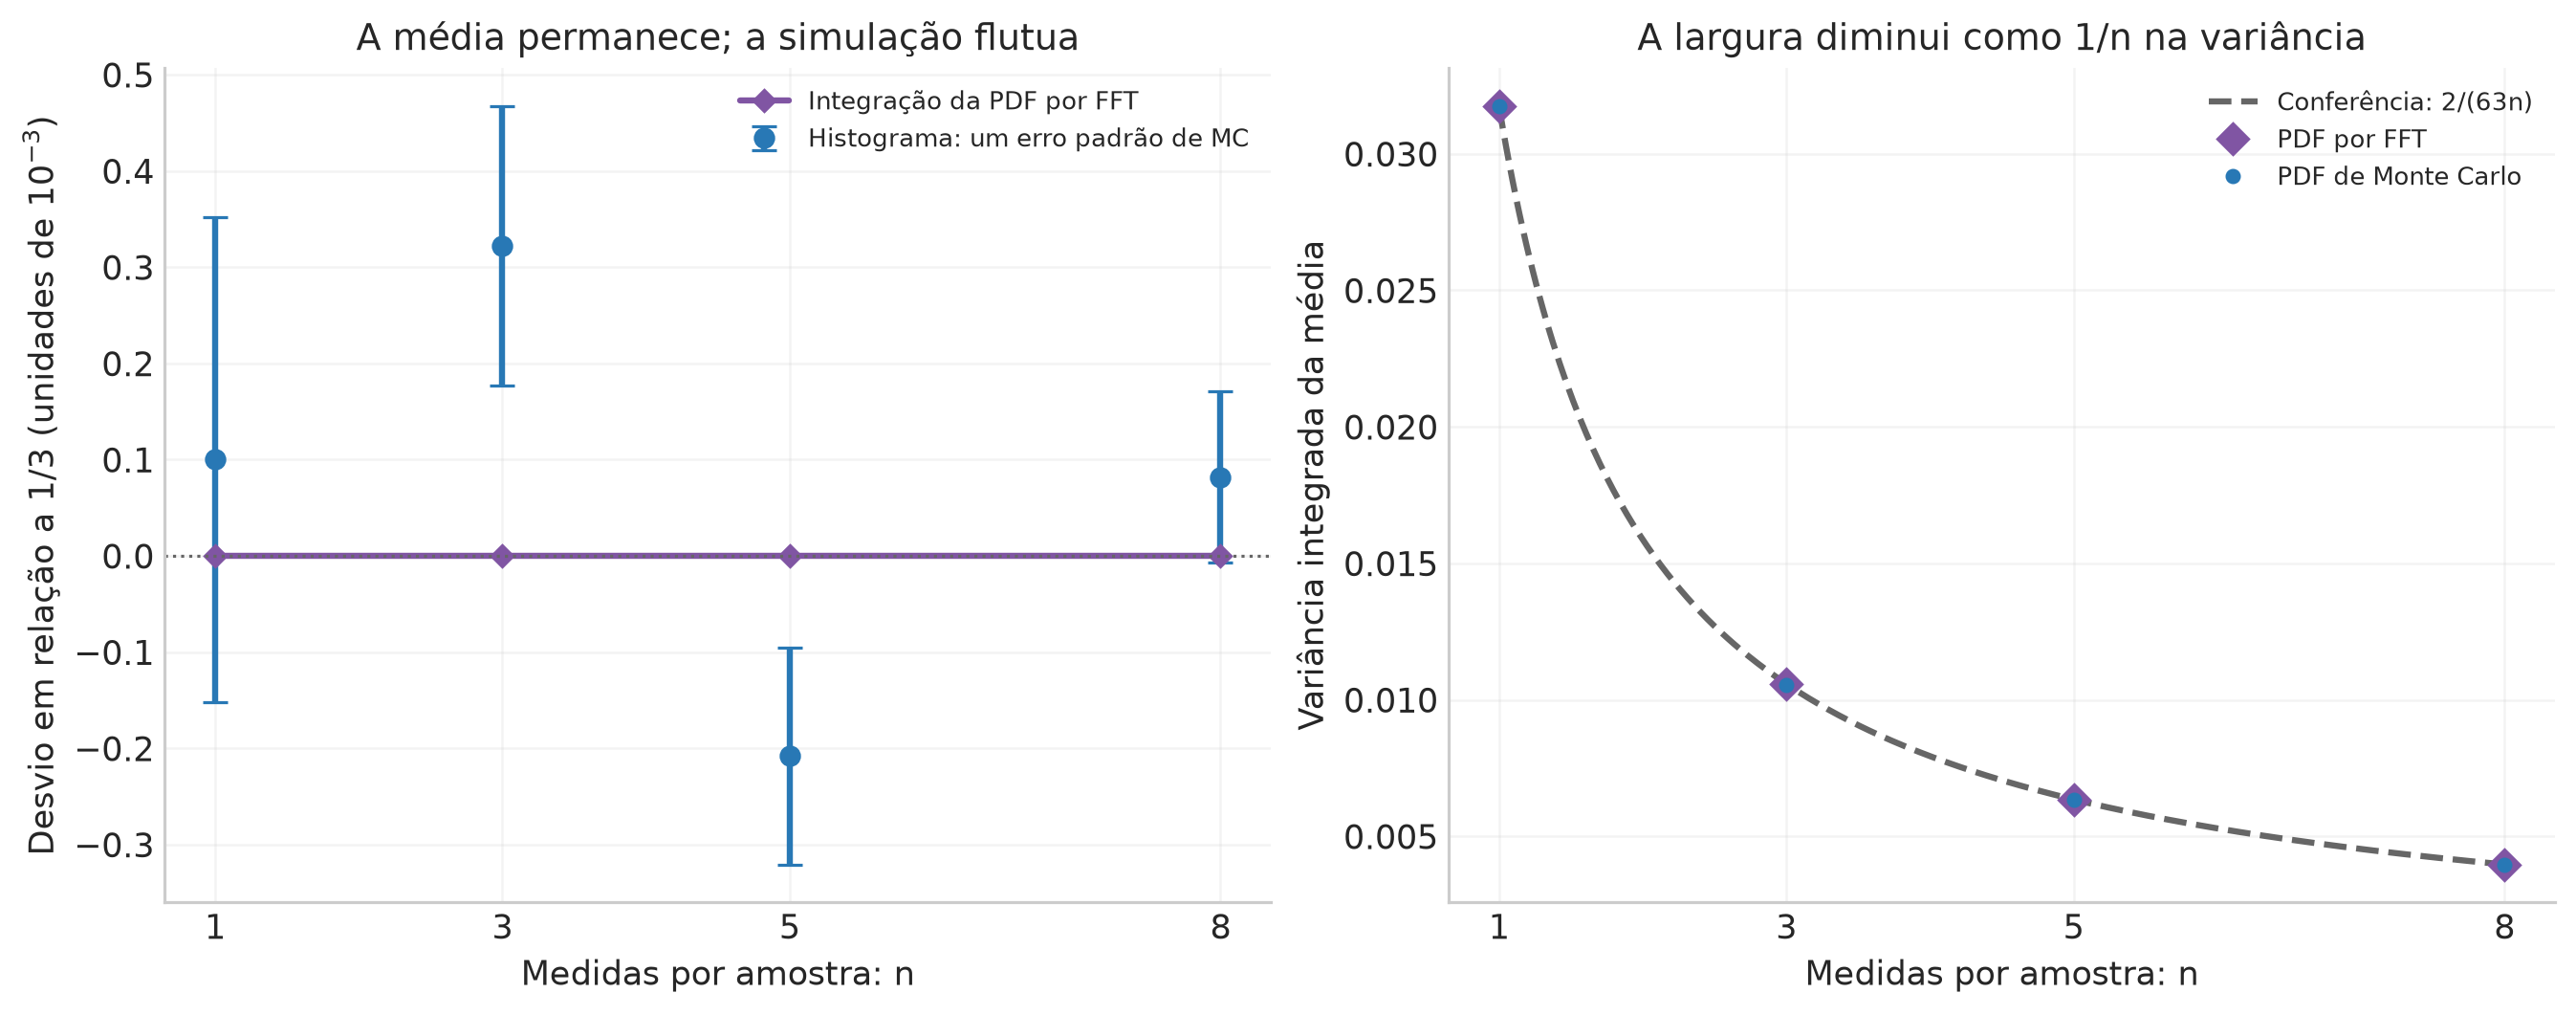

In [25]:
q4_fft_rows=[]
q4_mc_rows=[]
q4_moments_mc={}
left,right=q4_hist_edges[:-1],q4_hist_edges[1:]
for n in q4_ns:
    d=q4_fft[n]
    stats=q4_pdf_moments(d["x"],d["pdf"])
    d["moments"]=stats
    q4_fft_rows.append([n,stats["area"],stats["mean"],stats["variance"]])
    density=q4_mc[n]["density"]
    area=np.sum(density*(right-left))
    mean=np.sum(density*(right**2-left**2)/2)/area
    second=np.sum(density*(right**3-left**3)/3)/area
    variance=second-mean**2
    raw_mean=q4_mc[n]["means"].mean()
    raw_variance=q4_mc[n]["means"].var(ddof=0)
    q4_moments_mc[n]={"area":area,"mean":mean,"variance":variance,
                       "raw_mean":raw_mean,"raw_variance":raw_variance,
                       "se_mean":np.sqrt(raw_variance/q4_M)}
    q4_mc_rows.append([n,area,mean,variance,raw_mean,raw_variance])

export_table("q4_b_momentos_fft",["n","Área","Média integrada","Variância integrada"],
             q4_fft_rows,[0,12,10,12])
export_table("q4_b_momentos_monte_carlo",["n","Área","Média do histograma","Variância do histograma","Média sem classes","Variância sem classes"],
             q4_mc_rows,[0,12,8,10,8,10])

fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
axes[0].errorbar(q4_ns,[(q4_moments_mc[n]["mean"]-1/3)*1e3 for n in q4_ns],
                 yerr=[q4_moments_mc[n]["se_mean"]*1e3 for n in q4_ns],
                 fmt="o",color=BLUE,capsize=4,label="Histograma: um erro padrão de MC")
axes[0].plot(q4_ns,[(q4_fft[n]["moments"]["mean"]-1/3)*1e3 for n in q4_ns],
             color=PURPLE,marker="D",ms=5,label="Integração da PDF por FFT")
axes[0].axhline(0,color="0.4",ls=":",lw=1)
axes[0].set(xlabel="Medidas por amostra: n",ylabel=r"Desvio em relação a 1/3 (unidades de $10^{-3}$)",
            title="A média permanece; a simulação flutua",xticks=q4_ns)
axes[0].legend(loc="best",fontsize=8)
q4_n_curve=np.linspace(1,8,300)
axes[1].plot(q4_n_curve,2/(63*q4_n_curve),color="0.4",ls="--",label="Conferência: 2/(63n)")
axes[1].plot(q4_ns,[q4_fft[n]["moments"]["variance"] for n in q4_ns],
             color=PURPLE,marker="D",ls="none",ms=7,label="PDF por FFT")
axes[1].plot(q4_ns,[q4_moments_mc[n]["variance"] for n in q4_ns],
             color=BLUE,marker="o",ls="none",ms=4,label="PDF de Monte Carlo")
axes[1].set(xlabel="Medidas por amostra: n",ylabel="Variância integrada da média",
            title="A largura diminui como 1/n na variância",xticks=q4_ns)
axes[1].legend(loc="upper right",fontsize=8)
save_figure(fig,"q4_b_momentos")

As barras do painel de média representam um erro padrão de Monte Carlo, estimado por $s/\sqrt M$, onde $s$ é o desvio das médias simuladas. Elas descrevem a precisão com que simulamos o momento, e não a largura da distribuição de $\bar X_n$, que é muito maior. A integração do histograma acrescenta um pequeno efeito de discretização; a tabela sem classes permite separá-lo. Com a semente usada, a média simulada para $n=3$ fica aproximadamente 2,2 erros padrão acima de $1/3$. Barras de um erro padrão não precisam conter o valor teórico em todas as repetições; aumentar $M$ reduz a escala dessas flutuações.

Como referência analítica, as quatro variâncias são $2/63$, $2/189$, $2/315$ e $1/252$. As integrais das PDFs devem se aproximar desses valores; aumentar $M$ reduz as flutuações do método Monte Carlo, enquanto reduzir o espaçamento $h$ melhora a aproximação da FFT.

Também vale uma cautela: a média de variáveis Beta não se torna automaticamente uma $\mathrm{Beta}(2n,4n)$. Essa escolha preservaria a média $1/3$, mas teria variância $2/[9(6n+1)]$, diferente de $2/(63n)$ para $n>1$. Não podemos transferir para uma média de medidas a regra de atualização de parâmetros usada na questão das bactérias.

## Item (c) · Gaussianas com os momentos calculados para n = 5 e n = 8

Para cada uma dessas duas PDFs, tomamos a média $\mu_n$ e a variância $v_n$ **integradas no item (b)** e construímos

$$\phi_n(x)=\frac{1}{\sqrt{2\pi v_n}}\exp\!\left[-\frac{(x-\mu_n)^2}{2v_n}\right].$$

Assim a comparação não depende de inserir os momentos teóricos no lugar da conta pedida. As gaussianas são normalizadas em toda a reta. Não as truncamos nem renormalizamos em $[0,1]$, pois isso mudaria a distribuição usada para comparação.

Além das curvas, vamos calcular três quantidades que ajudam a interpretar a aproximação:

1. A assimetria padronizada da PDF, $\gamma_{1,n}=\int(x-\mu_n)^3p_n(x)\,dx/v_n^{3/2}$, que é zero numa normal.
2. A maior diferença absoluta entre as acumuladas, $D_{\rm CDF}=\sup_x|F_n(x)-\Phi[(x-\mu_n)/\sqrt{v_n}]|$. É uma medida descritiva de erro de aproximação, não um teste de hipótese ou um valor-p.
3. A massa que a gaussiana atribui fora do suporte físico $[0,1]$.

Uma aproximação pode ser boa perto do pico e exigir mais cuidado em probabilidades de cauda. A concordância da média e da variância, por construção, não garante a concordância das distribuições inteiras.

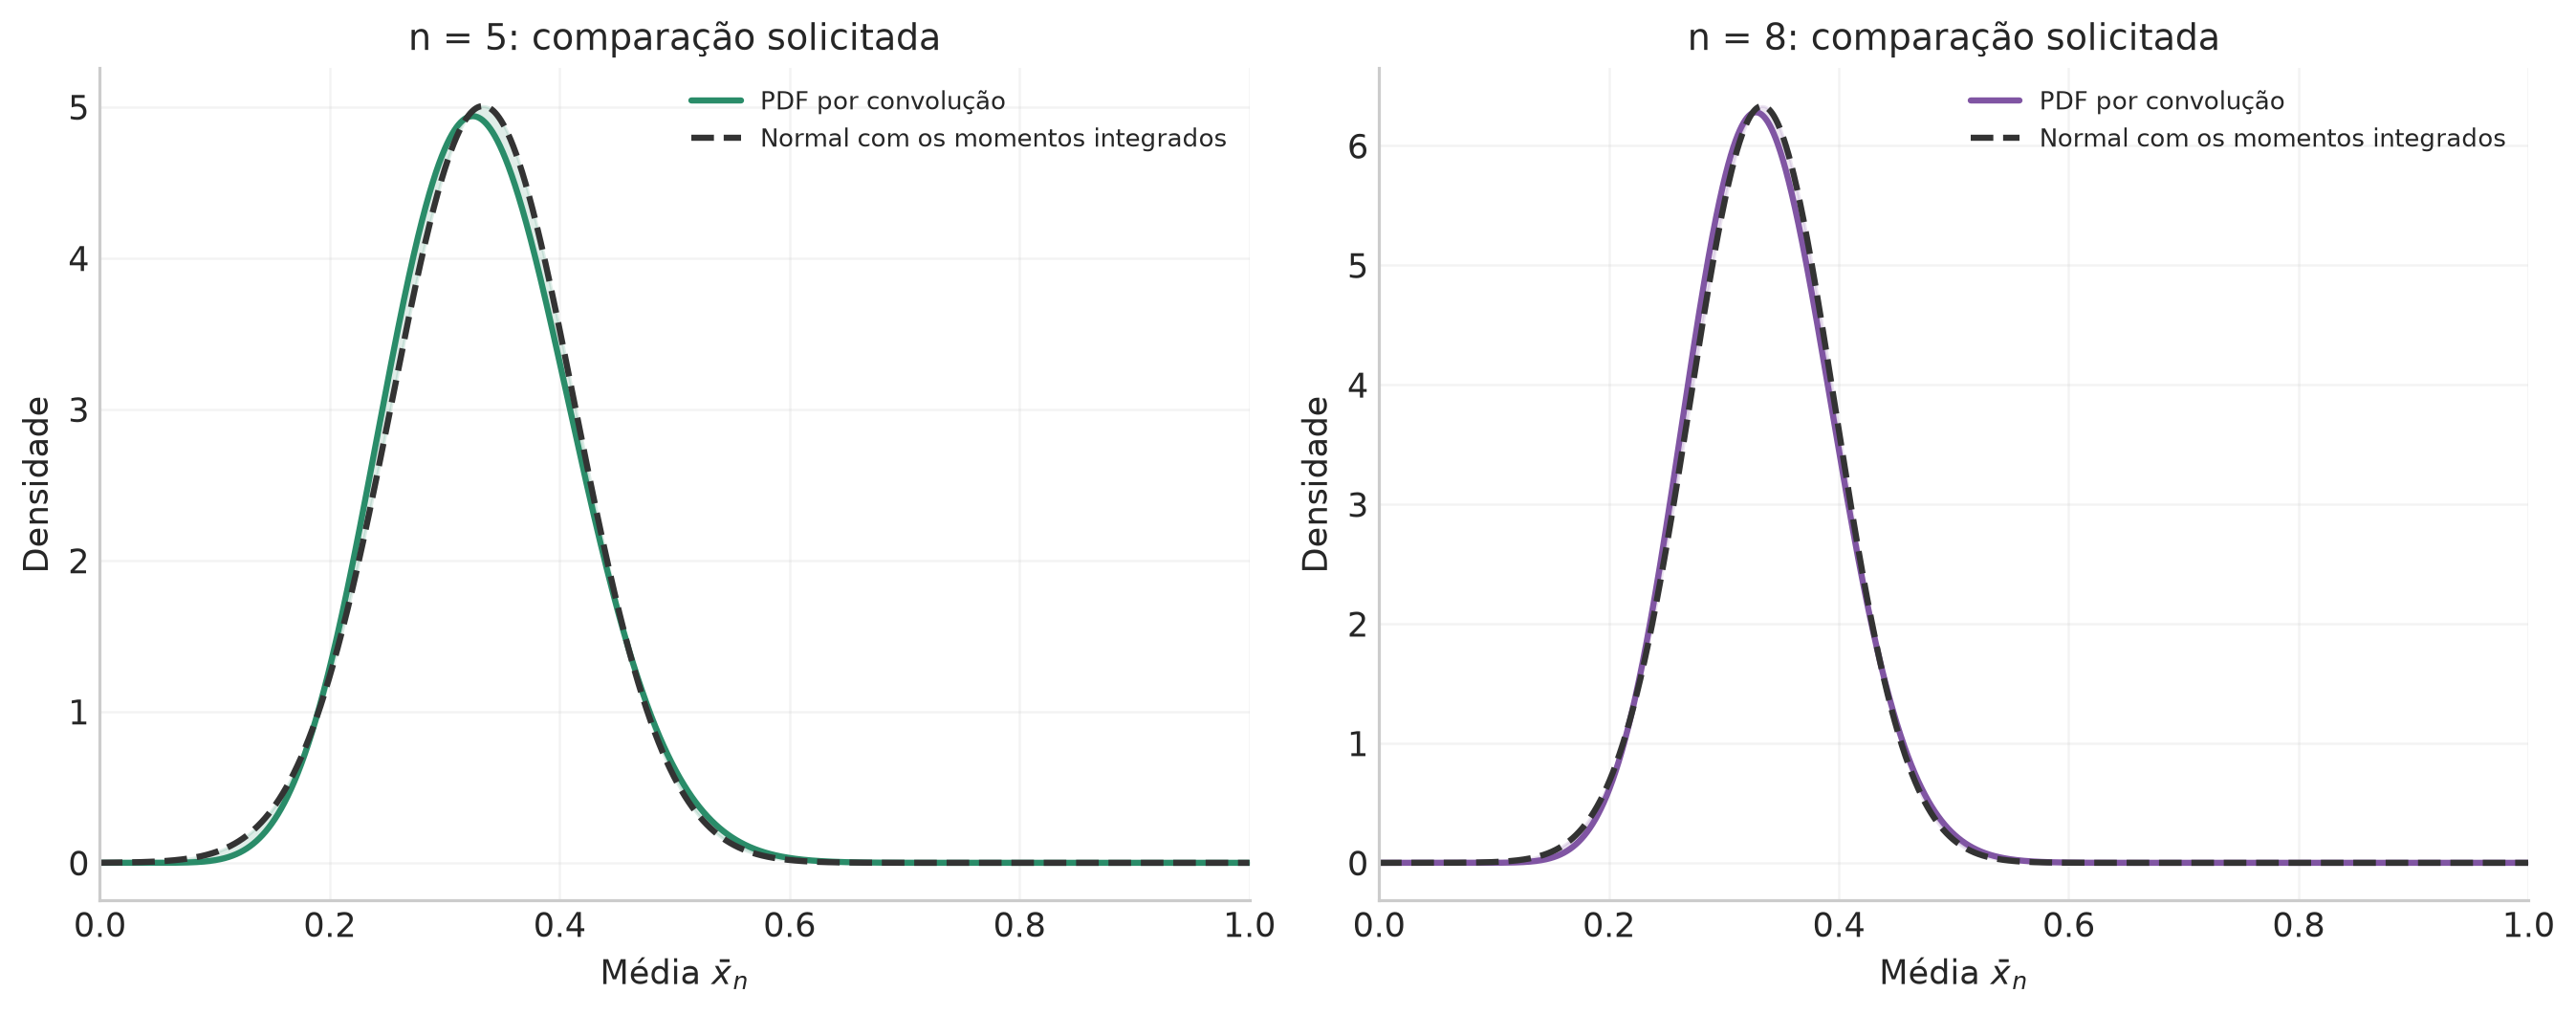

| n | Média | Variância | Assimetria | Maior diferença de CDF | Massa gaussiana fora |
| :-- | :-- | :-- | :-- | :-- | :-- |
| 5 | 0,3333333664 | 0,006349204772 | 0,20916515 | 0,01490219 | 0,000014365325 |
| 8 | 0,3333333664 | 0,003968252983 | 0,16535957 | 0,01147869 | 0,000000060657 |

In [26]:
q4_gaussian_rows=[]
fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
for ax,n in zip(axes,[5,8]):
    d=q4_fft[n];stats=d["moments"]
    mean,variance=stats["mean"],stats["variance"]
    sd=np.sqrt(variance)
    gaussian=norm.pdf(d["x"],loc=mean,scale=sd)
    cdf=cumulative_trapezoid(d["pdf"],d["x"],initial=0)
    gaussian_cdf=norm.cdf(d["x"],loc=mean,scale=sd)
    d_cdf=np.max(np.abs(cdf-gaussian_cdf))
    outside=norm.cdf(0,loc=mean,scale=sd)+norm.sf(1,loc=mean,scale=sd)
    d["cdf"]=cdf;d["gaussian_cdf_error"]=d_cdf;d["gaussian_outside"]=outside
    q4_gaussian_rows.append([n,mean,variance,stats["skewness"],d_cdf,outside])
    ax.plot(d["x"],d["pdf"],color=q4_colors[n],label="PDF por convolução")
    ax.plot(d["x"],gaussian,color="0.2",ls="--",label="Normal com os momentos integrados")
    ax.fill_between(d["x"],d["pdf"],gaussian,color=q4_colors[n],alpha=.15)
    ax.set(xlabel=r"Média $\bar x_n$",ylabel="Densidade",title=f"n = {n}: comparação solicitada",xlim=(0,1))
    ax.legend(loc="upper right",fontsize=8)
save_figure(fig,"q4_c_comparacao_gaussianas")
export_table("q4_c_diagnosticos",["n","Média","Variância","Assimetria","Maior diferença de CDF","Massa gaussiana fora"],
             q4_gaussian_rows,[0,10,12,8,8,12])

### O que concluir das comparações?

A aproximação gaussiana melhora de $n=5$ para $n=8$, mas as distribuições ainda não são exatamente normais.

A distribuição original é assimétrica à direita. Podemos deduzir como essa assimetria diminui. Usando a integral dos momentos, $\mathbb E[X^3]=1/14$, então

$$\mathbb E[(X-\mu)^3]=\mathbb E[X^3]-3\mu\mathbb E[X^2]+2\mu^3
=\frac1{14}-\frac17+\frac2{27}=\frac1{378}.$$

Para as variáveis centradas $Y_i=X_i-\mu$, todos os termos cruzados de $\mathbb E[(\sum_iY_i)^3]$ são zero por independência e média nula, restando $n\mathbb E[Y_i^3]$. Assim,

$$\mathbb E[(\bar X_n-\mu)^3]=\frac1{378n^2},\qquad
\gamma_{1,n}=\frac{\gamma_{1,1}}{\sqrt n},\qquad
\gamma_{1,1}=\frac{1/378}{(2/63)^{3/2}}=\frac{\sqrt{14}}8.$$

A assimetria ainda é aproximadamente $0{,}20917$ para $n=5$ e $0{,}16536$ para $n=8$, em acordo com as integrais das PDFs. Esse cálculo explica uma diferença visível que comparar apenas média e variância deixaria escondida.

### Estreitamento e limite central são duas afirmações diferentes

A relação $\operatorname{Var}(\bar X_n)=\sigma^2/n$ é exata, mas não diz sozinha que a forma é normal. O teorema do limite central trata da variável **centrada e padronizada**,

$$Z_n=\frac{\bar X_n-\mu}{\sigma/\sqrt n},\qquad Z_n\ \xrightarrow{d}\ \mathcal N(0,1).$$


Para ver brevemente de onde vem o limite, a função característica de uma variável centrada tem expansão $\mathbb E[e^{it(X-\mu)}]=1-\sigma^2t^2/2+O(t^3)$. Pela independência,

$$\mathbb E[e^{itZ_n}]=\left[1-\frac{t^2}{2n}+O(n^{-3/2})\right]^n\longrightarrow e^{-t^2/2}.$$

Este é o limite característico da normal padrão; a expansão é válida aqui porque a Beta tem suporte limitado e seus momentos são finitos. Na escala original, a distribuição de $\bar X_n$ fica cada vez mais concentrada em $\mu$, em vez de tender a uma gaussiana de largura fixa.

Vamos padronizar numericamente as duas PDFs usando seus próprios momentos integrados, para separar a mudança de forma da mudança de largura. O painel de diferenças de CDF mostra resíduos que ficam pouco visíveis quando as curvas são sobrepostas.

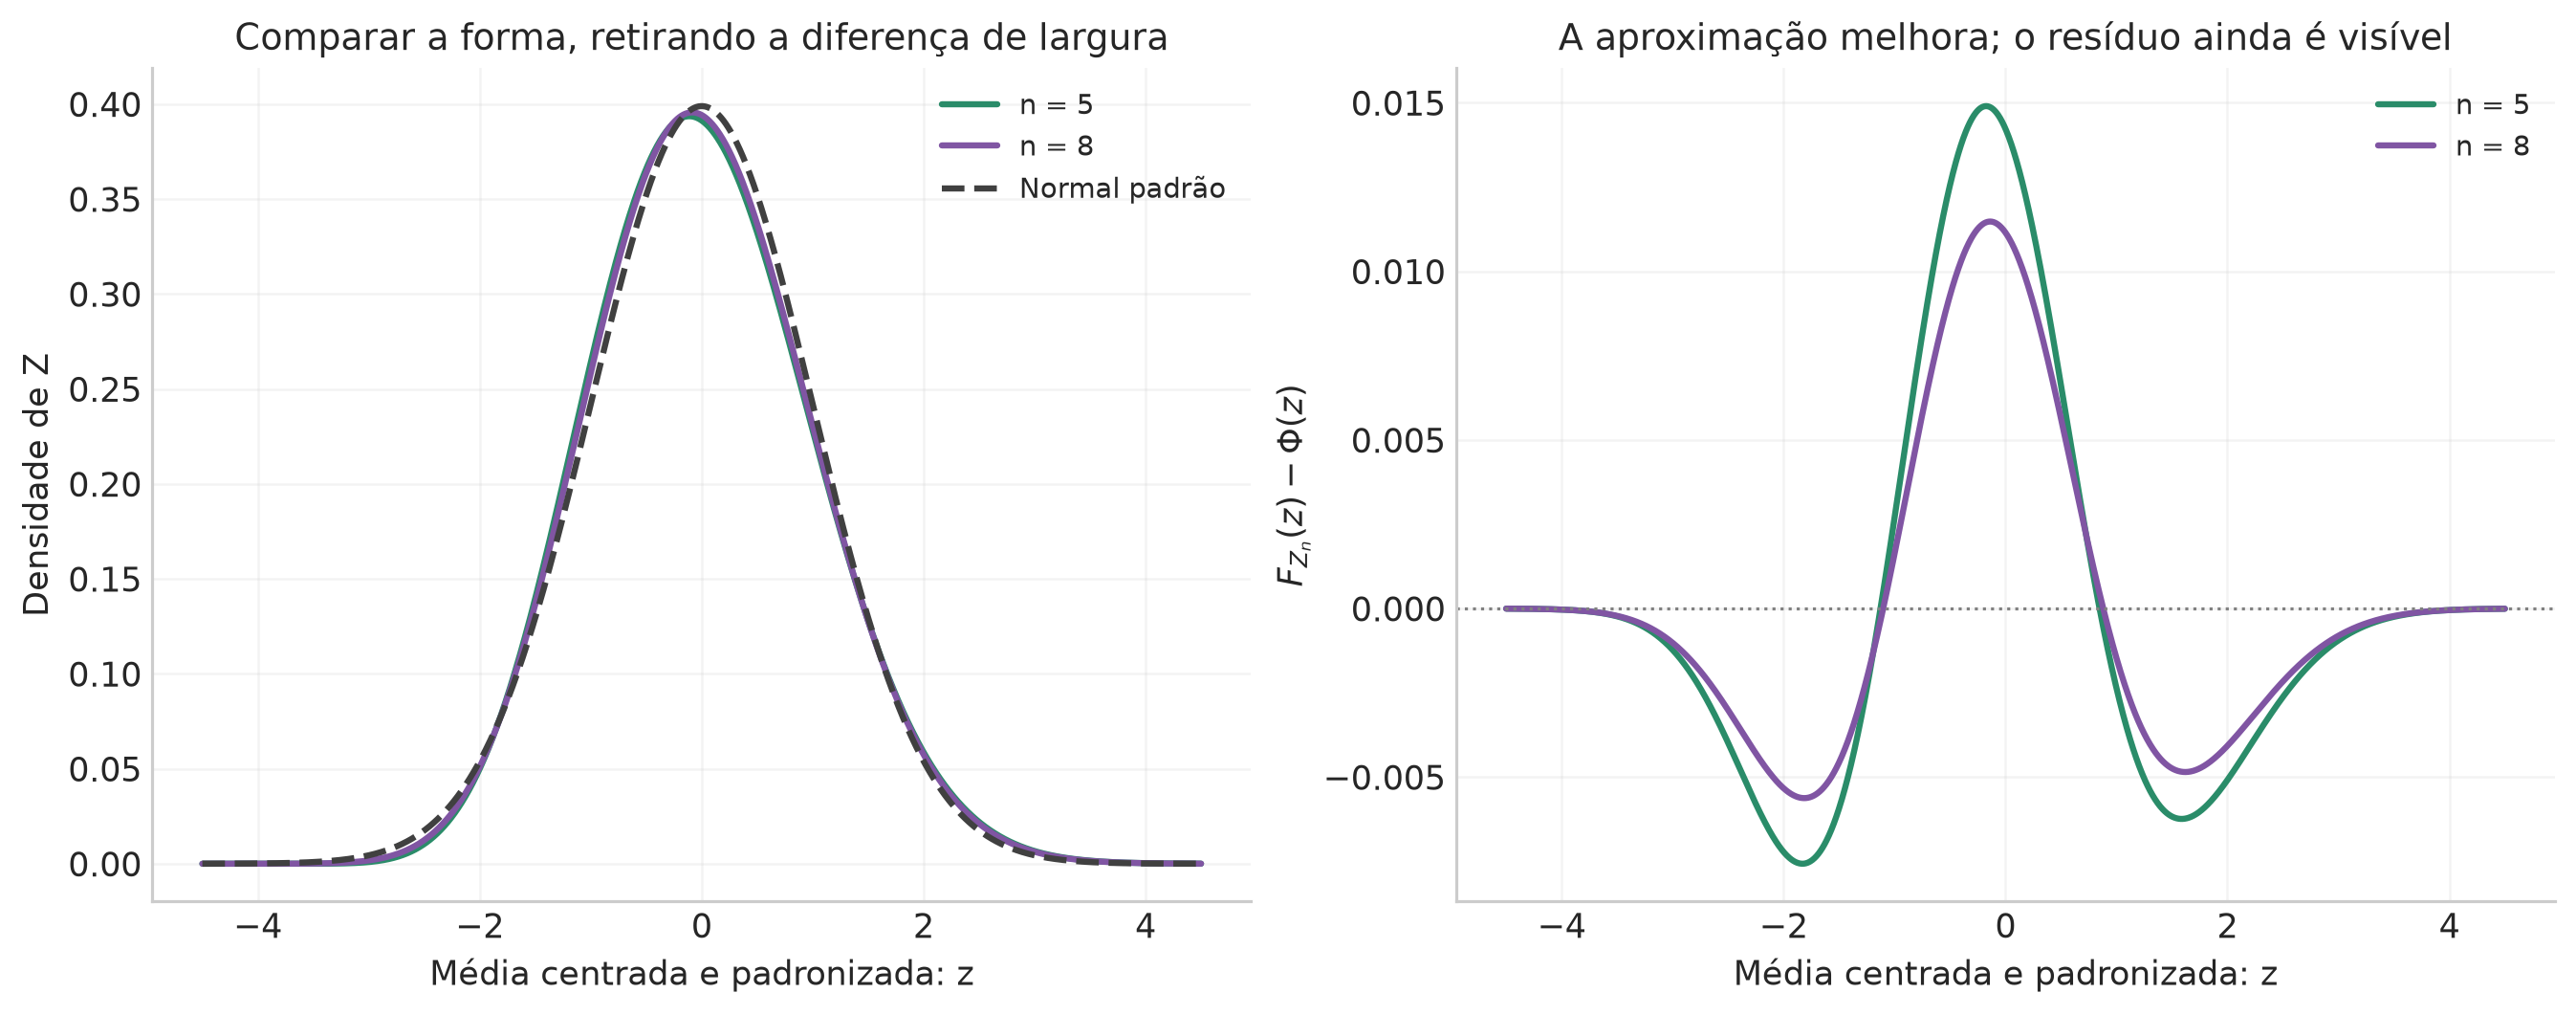

In [27]:
q4_zgrid=np.linspace(-4.5,4.5,2000)
fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
for n in [5,8]:
    d=q4_fft[n];mean=d["moments"]["mean"];sd=np.sqrt(d["moments"]["variance"])
    original_x=mean+sd*q4_zgrid
    standardized_pdf=sd*np.interp(original_x,d["x"],d["pdf"],left=0,right=0)
    standardized_cdf=np.interp(original_x,d["x"],d["cdf"],left=0,right=1)
    axes[0].plot(q4_zgrid,standardized_pdf,color=q4_colors[n],label=f"n = {n}")
    axes[1].plot(q4_zgrid,standardized_cdf-norm.cdf(q4_zgrid),color=q4_colors[n],label=f"n = {n}")
axes[0].plot(q4_zgrid,norm.pdf(q4_zgrid),color="0.25",ls="--",label="Normal padrão")
axes[0].set(xlabel="Média centrada e padronizada: z",ylabel="Densidade de Z",
            title="Comparar a forma, retirando a diferença de largura")
axes[1].axhline(0,color="0.5",ls=":",lw=1)
axes[1].set(xlabel="Média centrada e padronizada: z",ylabel=r"$F_{Z_n}(z)-\Phi(z)$",
            title="A aproximação melhora; o resíduo ainda é visível")
for ax in axes:ax.legend(loc="upper right",fontsize=9)
save_figure(fig,"q4_c_limite_central")

# Questão 5 · Dispersão amostral, qui-quadrado e razão de variâncias

A quinta questão da lista reúne os **problemas 6.1, 6.3 e 6.4 do Gregory**. Os cálculos são curtos, mas é importante identificar que quantidade foi observada, qual estatística estamos usando e sob quais hipóteses sua distribuição é conhecida.

Vamos seguir uma linha comum: começar com as medidas gaussianas, entender a soma de quadrados que produz a distribuição $\chi^2$ e depois construir a distribuição $F$ como razão de duas dessas somas independentes.

| Problema | Informação fornecida | O que calcular |
|:--|:--|:--|
| 6.1 | Quatro dados IID de uma população normal | Variância amostral, desvio padrão e erro padrão estimado da média |
| 6.3 | Uma distribuição $\chi^2$ com $\nu=10$ | Área à direita de $q_0=30{,}61$ |
| 6.4 | Duas amostras normais independentes e uma razão populacional de variâncias | Área à direita de $f_0=3{,}33$ em $F_{5,10}$ |

No último problema, vamos distinguir o valor **observado** $f_{\rm obs}=1{,}665$ do **limiar pedido** $f_0=3{,}33$. Ambos aparecem no enunciado e representam perguntas de cauda diferentes.

Nas expressões probabilísticas, letras maiúsculas como $S^2$, $Q$ e $F$ indicam estatísticas antes de observar os dados; minúsculas como $s^2$, $q_0$ e $f_{\rm obs}$ indicam valores numéricos. Nessa questão não é necessário calcular nenhuma posterior.

### Gregory 6.1 · Variância e desvio padrão de uma amostra

Os dados são

$$x=\{0{,}753;\ 3{,}795;\ 4{,}827;\ 2{,}025\},\qquad n=4.$$

Primeiro calculamos a média observada,

$$\bar x=\frac{0{,}753+3{,}795+4{,}827+2{,}025}{4}=\frac{11{,}4}{4}=2{,}85.$$

Definindo os desvios $d_i=x_i-\bar x$, a variância amostral e o desvio padrão amostral são

$$\boxed{s^2=\frac1{n-1}\sum_{i=1}^n(x_i-\bar x)^2,\qquad s=\sqrt{s^2}.}$$

#### Por que o denominador é n − 1?

Não estamos calculando apenas o momento de uma distribuição empírica, onde conhecemos a média teórica e o $\sigma$ da distribuição, de quatro pontos, que usaria pesos $1/n$. Queremos o estimador usual sem viés da variância da população. Podemos demonstrar a correção.

Para medidas IID de média $\mu$ e variância $\sigma^2$ finita, expandimos em torno de $\mu$:

$$\sum_i(X_i-\bar X)^2=\sum_i(X_i-\mu)^2-n(\bar X-\mu)^2.$$

O termo cruzado se simplifica porque $\sum_i(X_i-\mu)=n(\bar X-\mu)$. Tomando a esperança e usando $\operatorname{Var}(\bar X)=\sigma^2/n$,

$$\mathbb E\!\left[\sum_i(X_i-\bar X)^2\right]
=n\sigma^2-n\frac{\sigma^2}{n}=(n-1)\sigma^2.$$

Logo $S^2=\sum_i(X_i-\bar X)^2/(n-1)$ satisfaz $\mathbb E[S^2]=\sigma^2$. Essa propriedade requer independência e variância finita, mas não requer normalidade. A distribuição exata em termos de $\chi^2$, que veremos a seguir, requer a hipótese gaussiana.

Nos dados fornecidos,

$$d=\{-2{,}097;\ 0{,}945;\ 1{,}977;\ -0{,}825\},$$
$$\sum_i d_i^2=4{,}397409+0{,}893025+3{,}908529+0{,}680625=9{,}879588.$$

Portanto,

$$\boxed{s^2=\frac{9{,}879588}{3}=3{,}293196,\qquad s\simeq1{,}81471651.}$$

#### De onde vem o erro padrão da média?

Pela independência,

$$\operatorname{Var}(\bar X)=\frac1{n^2}\sum_i\operatorname{Var}(X_i)=\frac{\sigma^2}{n}.$$

O **erro padrão verdadeiro** da estatística média é seu desvio padrão $\sigma/\sqrt n$. Como $\sigma$ é desconhecido, usamos a estimativa

$$\boxed{\widehat{\mathrm{SE}}(\bar X)=\frac{s}{\sqrt n}
=\frac{1{,}81471651}{2}\simeq0{,}90735825.}$$

$s$ descreve a dispersão das medidas individuais; $s/\sqrt n$ estima a dispersão das médias em amostras possíveis de tamanho $n$.Para transformá-lo em um intervalo, os erros em relação a média, com $\sigma$ desconhecido exigiria ainda a distribuição e os quantis de Student; o item pede apenas o erro padrão.

$s$ e o erro padrão conservam a unidade dos valores medidos; $s^2$ tem essa unidade ao quadrado.

| i | Dado | Desvio da média | Desvio ao quadrado |
| :-- | :-- | :-- | :-- |
| 1 | 0,753 | -2,097000 | 4,397409000 |
| 2 | 3,795 | 0,945000 | 0,893025000 |
| 3 | 4,827 | 1,977000 | 3,908529000 |
| 4 | 2,025 | -0,825000 | 0,680625000 |

| Quantidade | Valor |
| :-- | :-- |
| Média amostral | 2,850000000 |
| Soma dos quadrados | 9,879588000 |
| Variância amostral | 3,293196000 |
| Desvio padrão amostral | 1,814716507 |
| Erro padrão estimado da média | 0,907358253 |

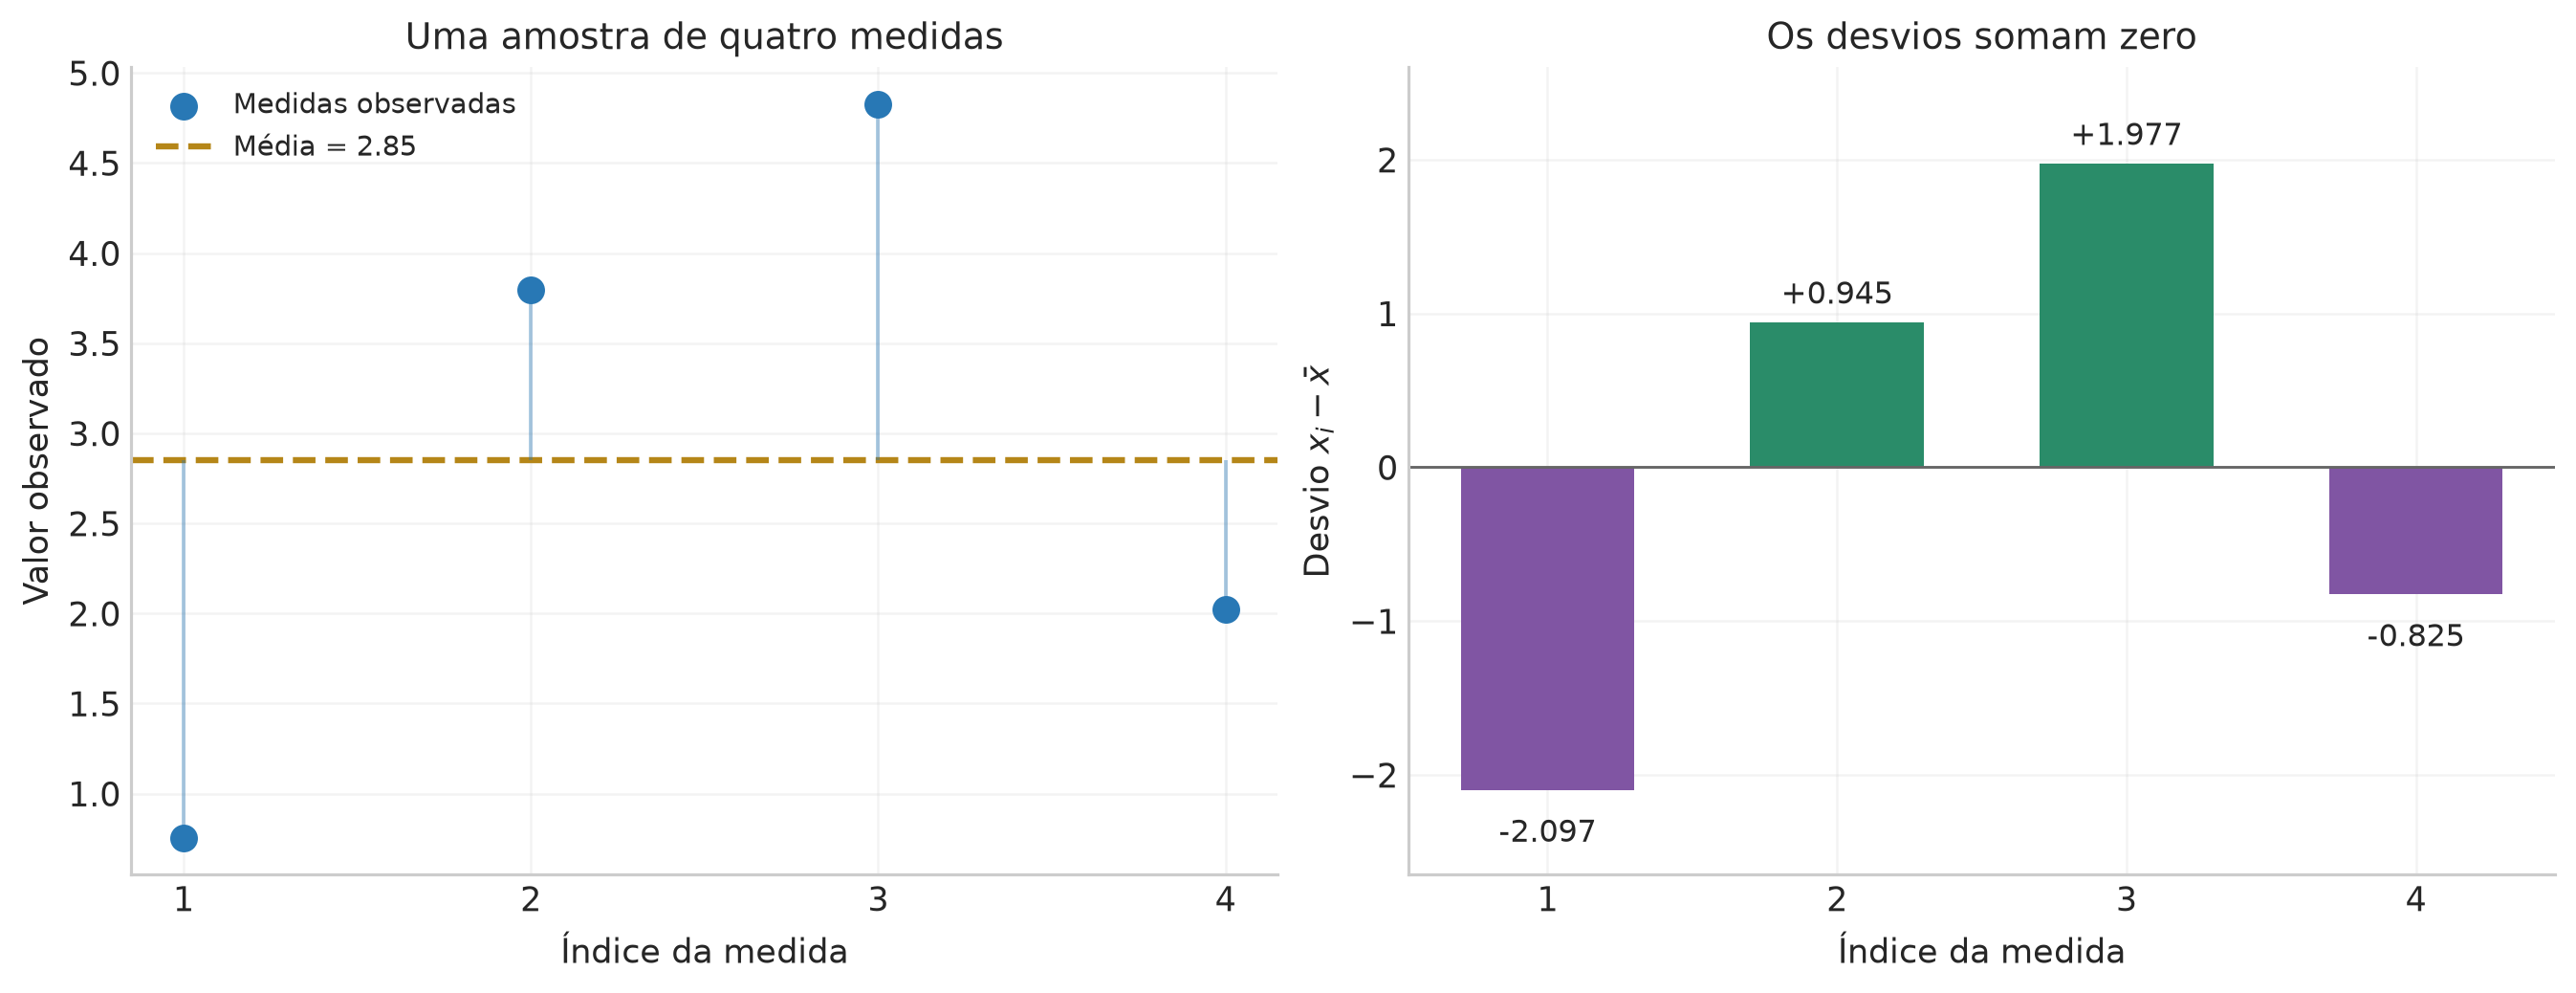

In [28]:
# Questão 5: os cálculos da amostra e as distribuições de suas estatísticas.
from scipy.stats import chi2, f as f_distribution
from scipy.special import gammaln

q5_data=np.array([.753,3.795,4.827,2.025])
q5_n=len(q5_data)
q5_mean=q5_data.mean()
q5_residuals=q5_data-q5_mean
q5_sumsquares=np.sum(q5_residuals**2)
q5_sample_variance=q5_sumsquares/(q5_n-1)
q5_sample_sd=np.sqrt(q5_sample_variance)
q5_se=q5_sample_sd/np.sqrt(q5_n)

export_table("q5_61_desvios",["i","Dado","Desvio da média","Desvio ao quadrado"],
             [[i+1,x,d,d*d] for i,(x,d) in enumerate(zip(q5_data,q5_residuals))],[0,3,6,9])
export_table("q5_61_resultados",["Quantidade","Valor"],
             [["Média amostral",q5_mean],["Soma dos quadrados",q5_sumsquares],
              ["Variância amostral",q5_sample_variance],["Desvio padrão amostral",q5_sample_sd],
              ["Erro padrão estimado da média",q5_se]],[0,9])

fig,axes=plt.subplots(1,2,figsize=(11.6,4.4),layout="constrained")
indices=np.arange(1,q5_n+1)
axes[0].scatter(indices,q5_data,color=BLUE,s=65,zorder=3,label="Medidas observadas")
axes[0].axhline(q5_mean,color=GOLD,ls="--",label=f"Média = {q5_mean:.2f}")
axes[0].vlines(indices,q5_mean,q5_data,color=BLUE,alpha=.4,lw=1.2)
axes[0].set(xlabel="Índice da medida",ylabel="Valor observado",title="Uma amostra de quatro medidas",xticks=indices)
axes[0].legend(loc="upper left",fontsize=9)
axes[1].bar(indices,q5_residuals,color=[PURPLE if d<0 else GREEN for d in q5_residuals],width=.6)
axes[1].axhline(0,color="0.4",lw=.9)
for i,d in zip(indices,q5_residuals):
    axes[1].annotate(f"{d:+.3f}",(i,d),xytext=(0,-17 if d<0 else 6),
                     textcoords="offset points",ha="center",fontsize=10)
axes[1].set(xlabel="Índice da medida",ylabel=r"Desvio $x_i-\bar x$",title="Os desvios somam zero",xticks=indices,ylim=(-2.65,2.6))
save_figure(fig,"q5_61_dados_desvios")

### Da amostra normal às somas de quadrados: por que três graus de liberdade?

No problema 6.1, a normalidade foi fornecida. Escrevemos $X_i\sim\mathcal N(\mu,\sigma^2)$, independentes, e padronizamos cada medida:

$$Z_i=\frac{X_i-\mu}{\sigma}\sim\mathcal N(0,1).$$

Se conhecêssemos $\mu$, a soma $\sum_i(X_i-\mu)^2/\sigma^2$ teria $n$ contribuições normais padronizadas independentes. Ao usar $\bar X$ no lugar de $\mu$, os desvios satisfazem a restrição $\sum_i(X_i-\bar X)=0$. Resta um espaço de dimensão $n-1$.

Podemos tornar essa afirmação precisa usando uma rotação de coordenadas. A densidade conjunta dos $Z_i$ é proporcional a $\exp(-\|z\|^2/2)$; uma transformação ortogonal preserva a norma e tem jacobiano de módulo 1. Em uma base ortonormal cuja primeira direção é $(1,\ldots,1)/\sqrt n$, as novas coordenadas $Y_0,\ldots,Y_{n-1}$ continuam com densidade

$$p(y)=(2\pi)^{-n/2}\exp\!\left[-\frac12\sum_{j=0}^{n-1}y_j^2\right]
=\prod_{j=0}^{n-1}\frac{e^{-y_j^2/2}}{\sqrt{2\pi}}.$$

Isso demonstra que são normais padrão **independentes**. A primeira coordenada é

$$Y_0=\frac{\sqrt n(\bar X-\mu)}{\sigma},$$

e as outras descrevem os desvios em torno da média. Pela conservação da norma,

$$\boxed{Q=\frac{\sum_i(X_i-\bar X)^2}{\sigma^2}
=\frac{(n-1)S^2}{\sigma^2}=\sum_{j=1}^{n-1}Y_j^2.}$$

Temos $n-1$ quadrados independentes e $Q$ é independente de $Y_0$. Para a amostra de quatro medidas, $\nu=n-1=3$.

Esta conta também mostra que a média de uma população normal é **exatamente** normal, com variância $\sigma^2/n$, para qualquer $n$. Na questão anterior, partíamos de uma população Beta e a normal era uma aproximação para a forma da média. A correção de graus de liberdade vem da média estimada na soma de quadrados.

### Construir a distribuição qui-quadrado a partir das normais

Se $Z\sim\mathcal N(0,1)$ e $V=Z^2$, cada $v>0$ tem dois ramos inversos, $z=\pm\sqrt v$. A transformação da densidade dá

$$f_V(v)=\sum_{z=\pm\sqrt v}f_Z(z)\left|\frac{dz}{dv}\right|
=2\frac{e^{-v/2}}{\sqrt{2\pi}}\frac1{2\sqrt v}
=\frac{v^{-1/2}e^{-v/2}}{\sqrt{2\pi}}.$$

Para a soma $Q=Z_1^2+\cdots+Z_\nu^2$ de $\nu$ normais padrão independentes, podemos usar a função geradora de momentos $M_Q(t)=\mathbb E[e^{tQ}]$. Para um quadrado,

$$M_V(t)=\frac1{\sqrt{2\pi}}\int_{-\infty}^{\infty}e^{-(1-2t)z^2/2}\,dz
=(1-2t)^{-1/2},\qquad t<1/2.$$

A independência transforma o produto das exponenciais em produto de médias, de modo que

$$M_Q(t)=(1-2t)^{-\nu/2}.$$

A densidade que possui essa função geradora é

$$\boxed{f_{\chi^2_\nu}(q)=\frac{q^{\nu/2-1}e^{-q/2}}{2^{\nu/2}\Gamma(\nu/2)},\qquad q>0.}$$

Para verificar isso, lembramos que $\Gamma(a)=\int_0^\infty u^{a-1}e^{-u}du$. A mudança $u=q/2$ normaliza a densidade acima; para sua função geradora, a mudança $u=(1/2-t)q$ fornece justamente $(1-2t)^{-\nu/2}$. A função geradora, quando existe numa vizinhança de zero, determina a distribuição. Assim a forma da PDF está ligada à soma de quadrados, em vez de ter sido apenas escolhida por uma tabela.

É uma distribuição Gamma de forma $\nu/2$ e escala 2. Derivando $M_Q$ em zero,

$$\mathbb E[Q]=M'_Q(0)=\nu,\quad
\mathbb E[Q^2]=M''_Q(0)=\nu(\nu+2),\quad
\operatorname{Var}(Q)=2\nu.$$

Vamos conferir graficamente sua origem usando amostras normais de tamanho 4. Na simulação escolhemos $\mu=0$ e $\sigma=1$ conhecidos para poder construir os pivôs; isso não atribui esses valores à população desconhecida dos quatro dados do exercício. As distribuições padronizadas não dependem da escolha desses valores de localização e escala.

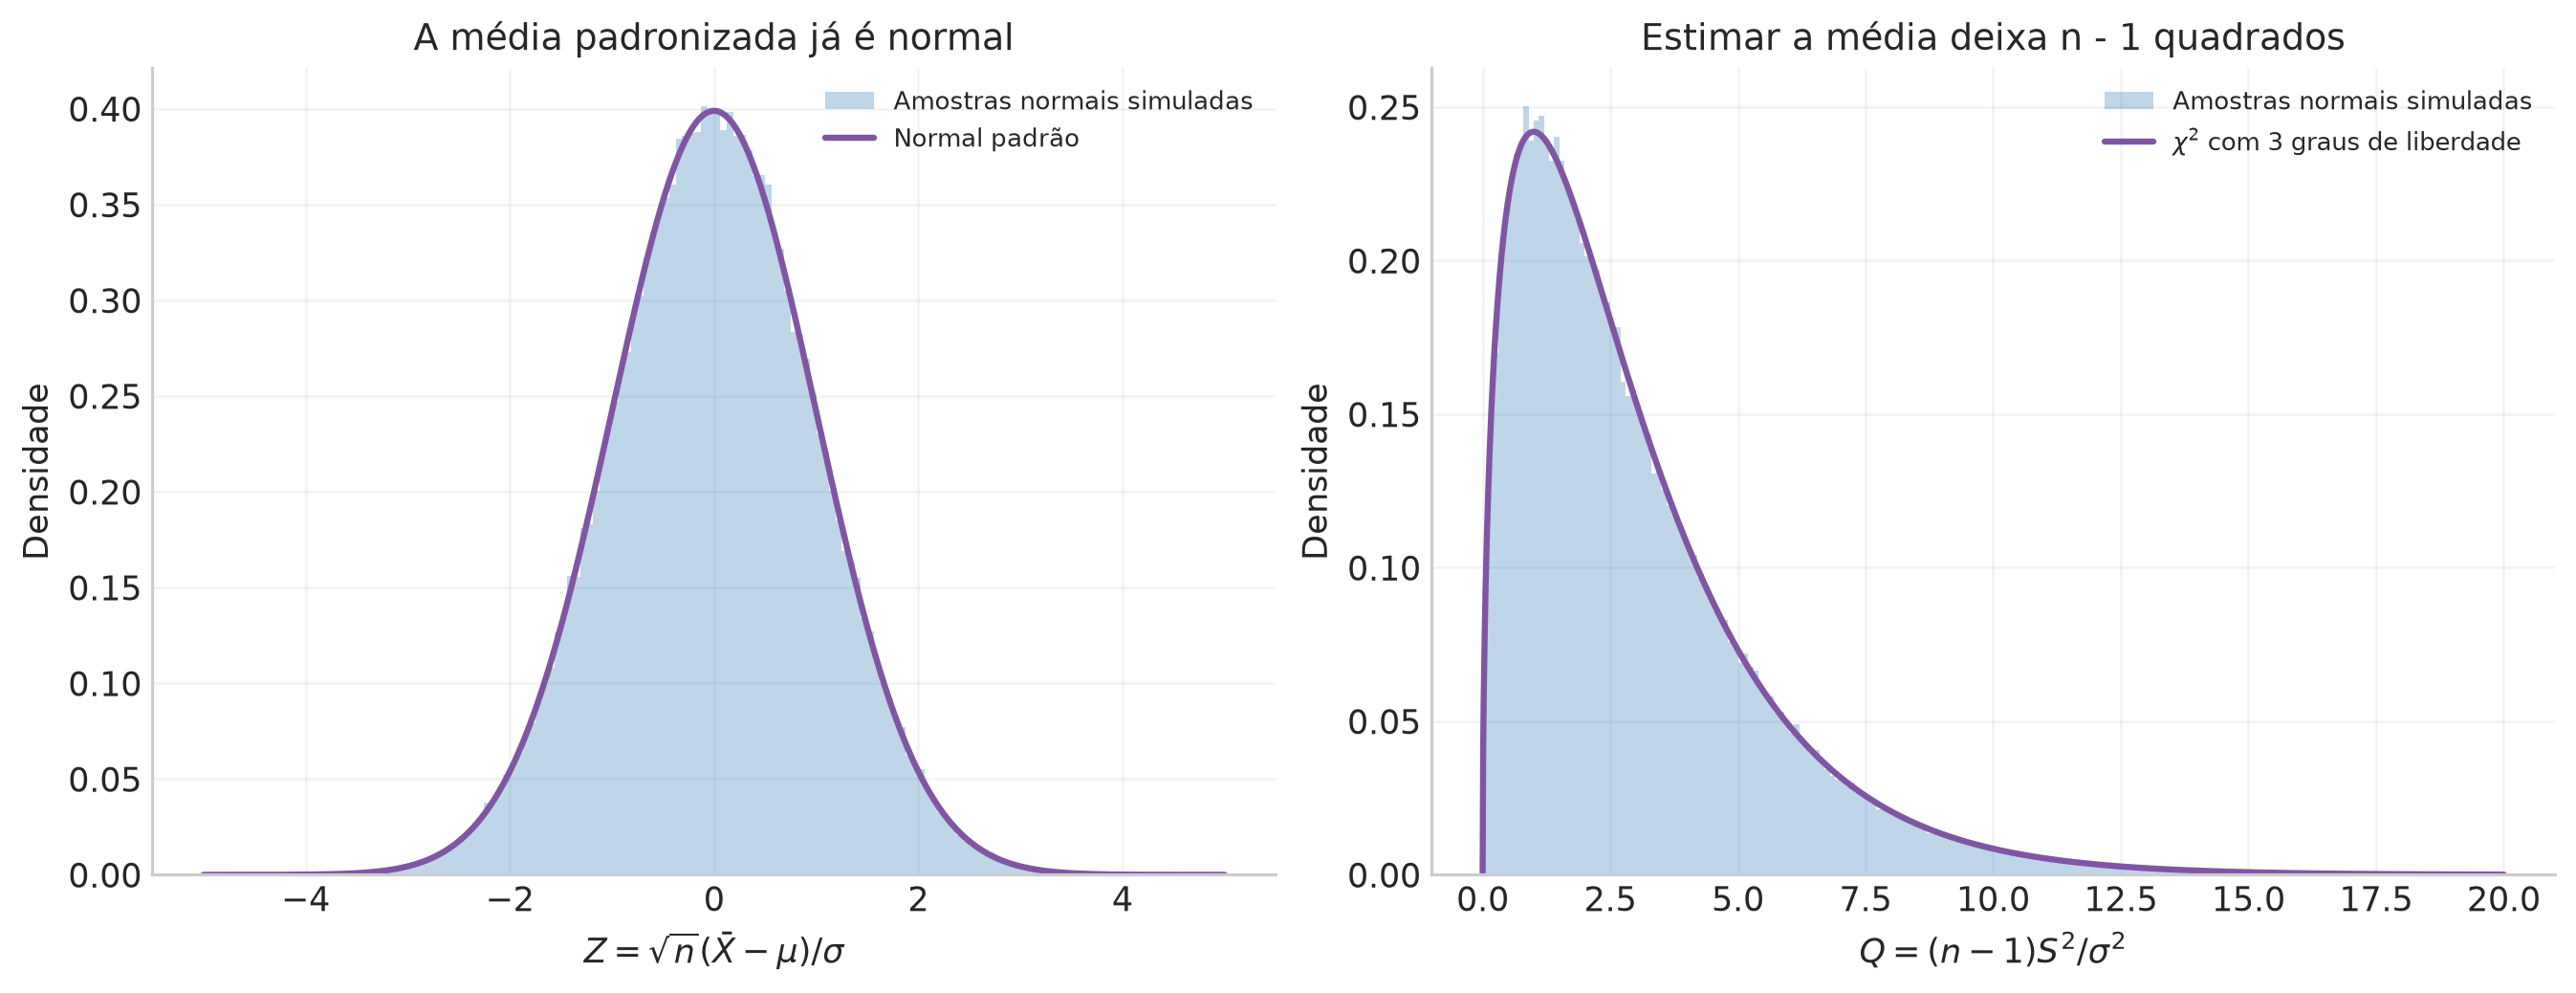

In [29]:
def q5_chi2_pdf(q,nu):
    """PDF qui-quadrado, escrita em log a partir da fórmula deduzida."""
    if nu<=0:
        raise ValueError("Os graus de liberdade devem ser positivos.")
    q=np.asarray(q,dtype=float)
    positive=np.where(q>0,q,1.0)
    logpdf=(nu/2-1)*np.log(positive)-positive/2-(nu/2)*np.log(2)-gammaln(nu/2)
    return np.where(q>0,np.exp(logpdf),0.0)

q5_rng=np.random.default_rng(20261025)
q5_Mnormal=200_000
q5_normal_samples=q5_rng.normal(size=(q5_Mnormal,4))
q5_normal_means=q5_normal_samples.mean(axis=1)
q5_normal_s2=q5_normal_samples.var(axis=1,ddof=1)
q5_Z=2*q5_normal_means
q5_Q3=3*q5_normal_s2

fig,axes=plt.subplots(1,2,figsize=(11.6,4.4),layout="constrained")
for ax,values,edges in [(axes[0],q5_Z,np.linspace(-5,5,161)),
                        (axes[1],q5_Q3,np.linspace(0,20,201))]:
    counts,_=np.histogram(values,bins=edges)
    # Denominador inclui todas as repetições, também as que não aparecem na janela.
    ax.stairs(counts/(len(values)*np.diff(edges)),edges,fill=True,color=BLUE,alpha=.3,label="Amostras normais simuladas")
q5_zgrid=np.linspace(-5,5,1800)
q5_q3grid=np.linspace(0,20,2000)
axes[0].plot(q5_zgrid,norm.pdf(q5_zgrid),color=PURPLE,label="Normal padrão")
axes[1].plot(q5_q3grid,q5_chi2_pdf(q5_q3grid,3),color=PURPLE,label=r"$\chi^2$ com 3 graus de liberdade")
axes[0].set(xlabel=r"$Z=\sqrt{n}(\bar{X}-\mu)/\sigma$",ylabel="Densidade",title="A média padronizada já é normal")
axes[1].set(xlabel=r"$Q=(n-1)S^2/\sigma^2$",ylabel="Densidade",title="Estimar a média deixa n - 1 quadrados")
for ax in axes:ax.legend(loc="upper right",fontsize=8)
save_figure(fig,"q5_origem_media_chi2")

### Gregory 6.3 · Área da cauda de uma qui-quadrado

Agora o enunciado fornece diretamente $\nu=10$ graus de liberdade e pede a área à direita de $q_0=30{,}61$. Estes não são os três graus de liberdade do problema anterior: é outro exercício, com sua própria distribuição.

Queremos

$$\boxed{P(Q\geq30{,}61\mid\nu=10)=\int_{30{,}61}^{\infty}
\frac{q^4e^{-q/2}}{2^5\Gamma(5)}\,dq.}$$

#### Uma forma curta de abrir a integral, além da quadratura

Com $u=q/2$ e $z_0=30{,}61/2=15{,}305$, fica

$$P(Q\geq30{,}61)=\frac1{\Gamma(5)}\int_{z_0}^{\infty}u^4e^{-u}\,du.$$

Se $J_k(z)=\int_z^\infty u^ke^{-u}du$, uma integração por partes dá

$$J_k(z)=z^ke^{-z}+kJ_{k-1}(z),\qquad J_0(z)=e^{-z}.$$

Aplicando a recorrência quatro vezes e usando $\Gamma(5)=4!$, obtemos

$$\boxed{P(Q\geq30{,}61)=e^{-z_0}\left(1+z_0+\frac{z_0^2}{2!}
+\frac{z_0^3}{3!}+\frac{z_0^4}{4!}\right)
\simeq0{,}0006803377805.}$$

A probabilidade é aproximadamente **0,0680338%**. Vamos comparar essa expressão finita com quadratura direta e com a função de sobrevivência (`sf`), que calcula a cauda superior. Para caudas muito pequenas, avaliá-la diretamente evita a perda de precisão que pode ocorrer ao subtrair uma CDF próxima de 1.

Também vamos sobrepor uma normal com os mesmos momentos, média $\nu=10$ e variância $2\nu=20$. Essa normal é apenas uma aproximação, para avaliar o que acontece longe do pico, e não o modelo a usar na resposta.

| Cálculo | Probabilidade | Probabilidade (%) |
| :-- | :-- | :-- |
| Qui-quadrado: soma finita | 0,000680337780 | 0,068033778 |
| Qui-quadrado: quadratura | 0,000680337780 | 0,068033778 |
| Qui-quadrado: sf | 0,000680337780 | 0,068033778 |
| Normal com os mesmos momentos | 0,000002027570 | 0,000202757 |

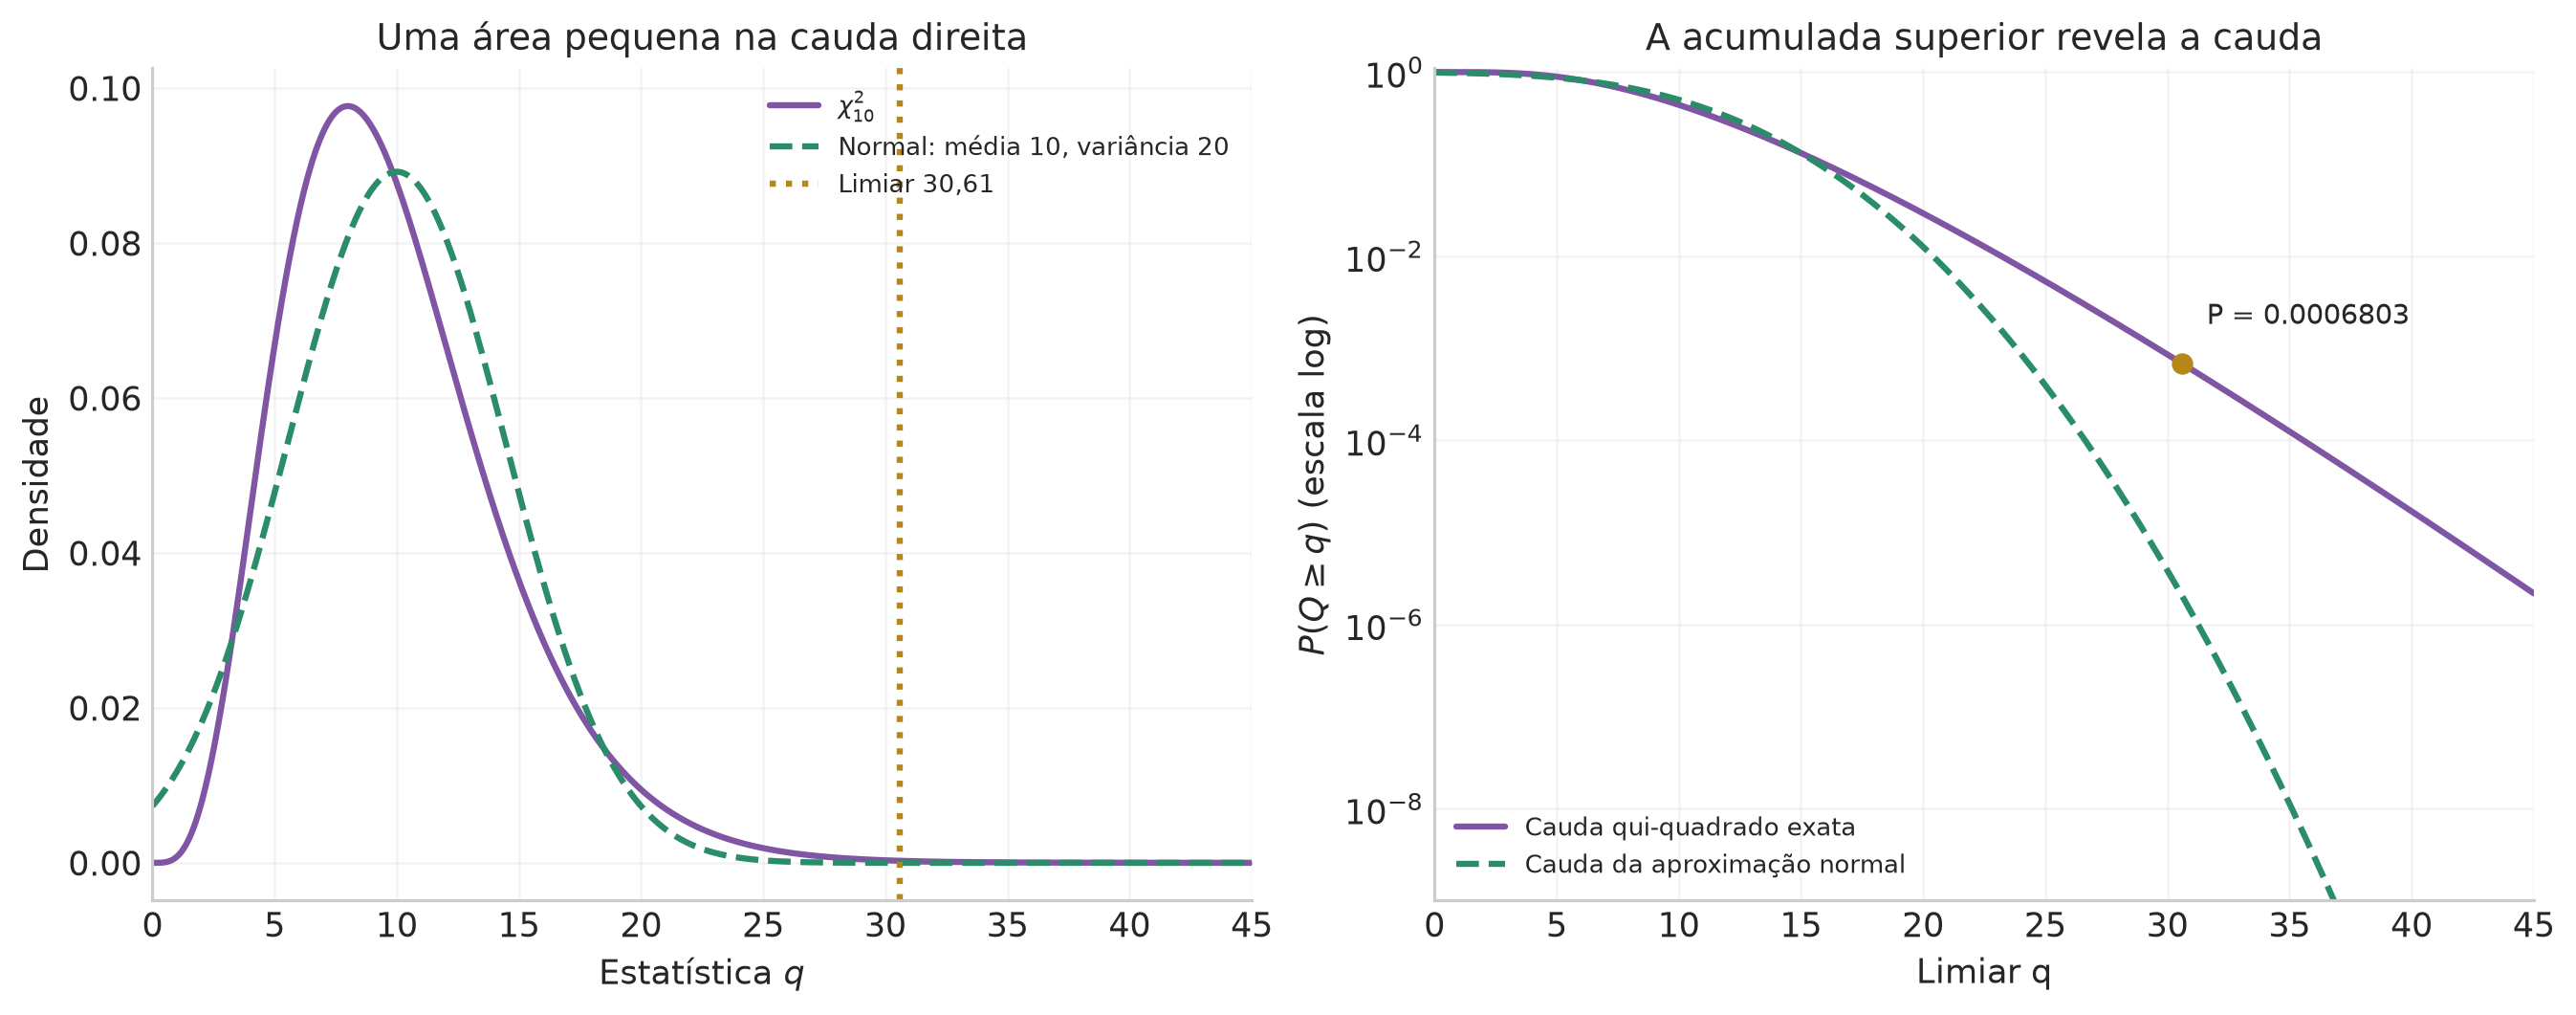

In [30]:
q5_nu=10
q5_qcut=30.61
q5_zcut=q5_qcut/2
q5_chi_tail_series=np.exp(-q5_zcut)*sum(q5_zcut**j/factorial(j) for j in range(5))
q5_chi_tail_quad=quad(lambda q:q5_chi2_pdf(q,q5_nu),q5_qcut,np.inf,epsabs=1e-13)[0]
q5_chi_tail_sf=chi2.sf(q5_qcut,q5_nu)
q5_chi_gaussian_tail=norm.sf(q5_qcut,loc=q5_nu,scale=np.sqrt(2*q5_nu))
export_table("q5_63_cauda",["Cálculo","Probabilidade","Probabilidade (%)"],
             [["Qui-quadrado: soma finita",q5_chi_tail_series,100*q5_chi_tail_series],
              ["Qui-quadrado: quadratura",q5_chi_tail_quad,100*q5_chi_tail_quad],
              ["Qui-quadrado: sf",q5_chi_tail_sf,100*q5_chi_tail_sf],
              ["Normal com os mesmos momentos",q5_chi_gaussian_tail,100*q5_chi_gaussian_tail]],
             [0,12,9])

q5_chigrid=np.linspace(0,45,3000)
fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
q5_chidensity=q5_chi2_pdf(q5_chigrid,q5_nu)
axes[0].plot(q5_chigrid,q5_chidensity,color=PURPLE,label=r"$\chi^2_{10}$")
axes[0].plot(q5_chigrid,norm.pdf(q5_chigrid,10,np.sqrt(20)),color=GREEN,ls="--",label="Normal: média 10, variância 20")
axes[0].fill_between(q5_chigrid,0,q5_chidensity,where=q5_chigrid>=q5_qcut,color=GOLD,alpha=.6)
axes[0].axvline(q5_qcut,color=GOLD,ls=":",label="Limiar 30,61")
axes[0].set(xlabel=r"Estatística $q$",ylabel="Densidade",title="Uma área pequena na cauda direita",xlim=(0,45))
axes[0].legend(loc="upper right",fontsize=8)
axes[1].semilogy(q5_chigrid,chi2.sf(q5_chigrid,10),color=PURPLE,label="Cauda qui-quadrado exata")
axes[1].semilogy(q5_chigrid,norm.sf(q5_chigrid,10,np.sqrt(20)),color=GREEN,ls="--",label="Cauda da aproximação normal")
axes[1].scatter([q5_qcut],[q5_chi_tail_sf],color=GOLD,zorder=4)
axes[1].annotate(f"P = {q5_chi_tail_sf:.7f}",(q5_qcut,q5_chi_tail_sf),xytext=(8,13),
                 textcoords="offset points",fontsize=9)
axes[1].set(xlabel="Limiar q",ylabel=r"$P(Q\geq q)$ (escala log)",title="A acumulada superior revela a cauda",
            xlim=(0,45),ylim=(1e-9,1.1))
axes[1].legend(loc="lower left",fontsize=8)
save_figure(fig,"q5_63_cauda_chi2")

### Interpretar a cauda

O valor $0{,}0006803$ diz a frequência probabilística de estatísticas pelo menos tão grandes quanto 30,61 **sob uma distribuição $\chi^2_{10}$**. Indica possivelmente algum erro nos dados ou até mesmoq ue as barras de erro estão sendo subestimadas, ou anticorrelação nos dados que não está sendo considerada.

A comparação normal fornece cerca de $2{,}0276\times10^{-6}$, aproximadamente 335,5 vezes menor que a cauda correta. Ter os mesmos momentos não basta para aproximar com precisão um evento distante do centro. Esse é um exemplo concreto da cautela que apareceu na questão 4: a inspeção do pico não garante a qualidade de uma aproximação nas caudas.

### Gregory 6.4 · Duas amostras e uma hipótese sobre a razão populacional

O enunciado fornece duas amostras normais independentes:

$$n_1=6,\quad s_1^2=16{,}65;\qquad n_2=11,\quad s_2^2=5{,}0.$$

A hipótese é

$$H_0:\quad\rho_0\equiv\frac{\sigma_1^2}{\sigma_2^2}=2.$$

O índice 0 apenas identifica o valor populacional assumido. As duas variâncias populacionais absolutas não foram fornecidas, mas veremos que a estatística elimina essa escala desconhecida.

Pelo resultado das somas de quadrados de amostras normais,

$$U=\frac{\nu_1S_1^2}{\sigma_1^2}\sim\chi^2_{\nu_1},\quad\nu_1=n_1-1=5,$$
$$V=\frac{\nu_2S_2^2}{\sigma_2^2}\sim\chi^2_{\nu_2},\quad\nu_2=n_2-1=10.$$

A independência das amostras torna $U$ e $V$ independentes. Formamos então

$$\boxed{F=\frac{U/\nu_1}{V/\nu_2}
=\frac{S_1^2/\sigma_1^2}{S_2^2/\sigma_2^2}
=\frac{S_1^2/S_2^2}{\rho_0}.}$$

A razão bruta observada das variâncias e o valor observado de $F$ são

$$R_{\rm obs}=\frac{s_1^2}{s_2^2}=\frac{16{,}65}{5}=3{,}33,$$
$$\boxed{f_{\rm obs}=\frac{R_{\rm obs}}{\rho_0}=\frac{3{,}33}{2}=1{,}665.}$$

É a razão de variâncias **normalizada pela razão populacional**, e não a razão bruta, que segue a distribuição $F_{5,10}$. A ordem dos graus de liberdade acompanha a ordem numerador/denominador; trocá-los sem inverter a estatística muda a distribuição.

### Deduzir a PDF de F a partir da razão de qui-quadrados

Definimos $a=\nu_1/2$, $b=\nu_2/2$ e $c=\nu_1/\nu_2$. A transformação de $(U,V)$ para $(F,V)$ satisfaz

$$u=cfv,\qquad v=v,\qquad
\left|\frac{\partial(u,v)}{\partial(f,v)}\right|=cv.$$

Pela independência, a densidade conjunta original é $f_U(u)f_V(v)$. Substituindo as duas PDFs qui-quadrado e o jacobiano,

$$p(f,v)=\frac{c^af^{a-1}}{2^{a+b}\Gamma(a)\Gamma(b)}
v^{a+b-1}\exp\!\left[-\frac{(1+cf)v}{2}\right],\qquad f,v>0.$$

Integramos o denominador auxiliar $v$. Com $t=(1+cf)v/2$,

$$\int_0^\infty v^{a+b-1}e^{-(1+cf)v/2}\,dv
=\Gamma(a+b)\left(\frac2{1+cf}\right)^{a+b}.$$

Logo,

$$f_F(f)=\frac{\Gamma(a+b)}{\Gamma(a)\Gamma(b)}
\frac{c^af^{a-1}}{(1+cf)^{a+b}}.$$

Podemos escrever a constante em termos da função Beta, que definimos novamente por sua integral:

$$B(a,b)=\int_0^1t^{a-1}(1-t)^{b-1}\,dt,\qquad a,b>0.$$

A relação $B(a,b)=\Gamma(a)\Gamma(b)/\Gamma(a+b)$ também pode ser aberta: no produto das duas integrais de Gamma, fazemos $r=u+v$, $t=u/(u+v)$, com $u=rt$, $v=r(1-t)$ e jacobiano $r$. Então

$$\begin{aligned}
\Gamma(a)\Gamma(b)
&=\int_0^\infty\int_0^\infty u^{a-1}v^{b-1}e^{-(u+v)}\,du\,dv\\
&=\left[\int_0^\infty r^{a+b-1}e^{-r}\,dr\right]
\left[\int_0^1t^{a-1}(1-t)^{b-1}\,dt\right]
=\Gamma(a+b)B(a,b).
\end{aligned}$$

Portanto,

$$\boxed{f_{F_{\nu_1,\nu_2}}(f)=\frac{c^af^{a-1}}{B(a,b)(1+cf)^{a+b}},\qquad f>0.}$$

A função especial aparece como resultado da integral de uma razão de variáveis independentes; não estamos escolhendo uma prior Beta para as variâncias.

| Cálculo para F a partir de 3,33 | Probabilidade | Probabilidade (%) |
| :-- | :-- | :-- |
| Quadratura da PDF deduzida | 0,049831275797 | 4,983127580 |
| Função de sobrevivência F | 0,049831275797 | 4,983127580 |
| Integral da Beta transformada | 0,049831275797 | 4,983127580 |
| CDF da razão recíproca | 0,049831275797 | 4,983127580 |

| Evento | Limiar em F | Limiar na razão bruta | Probabilidade sob H0 |
| :-- | :-- | :-- | :-- |
| Cauda pedida | 3,330000 | 6,660000 | 0,049831275797 |
| Cauda do valor observado | 1,665000 | 3,330000 | 0,230216297933 |

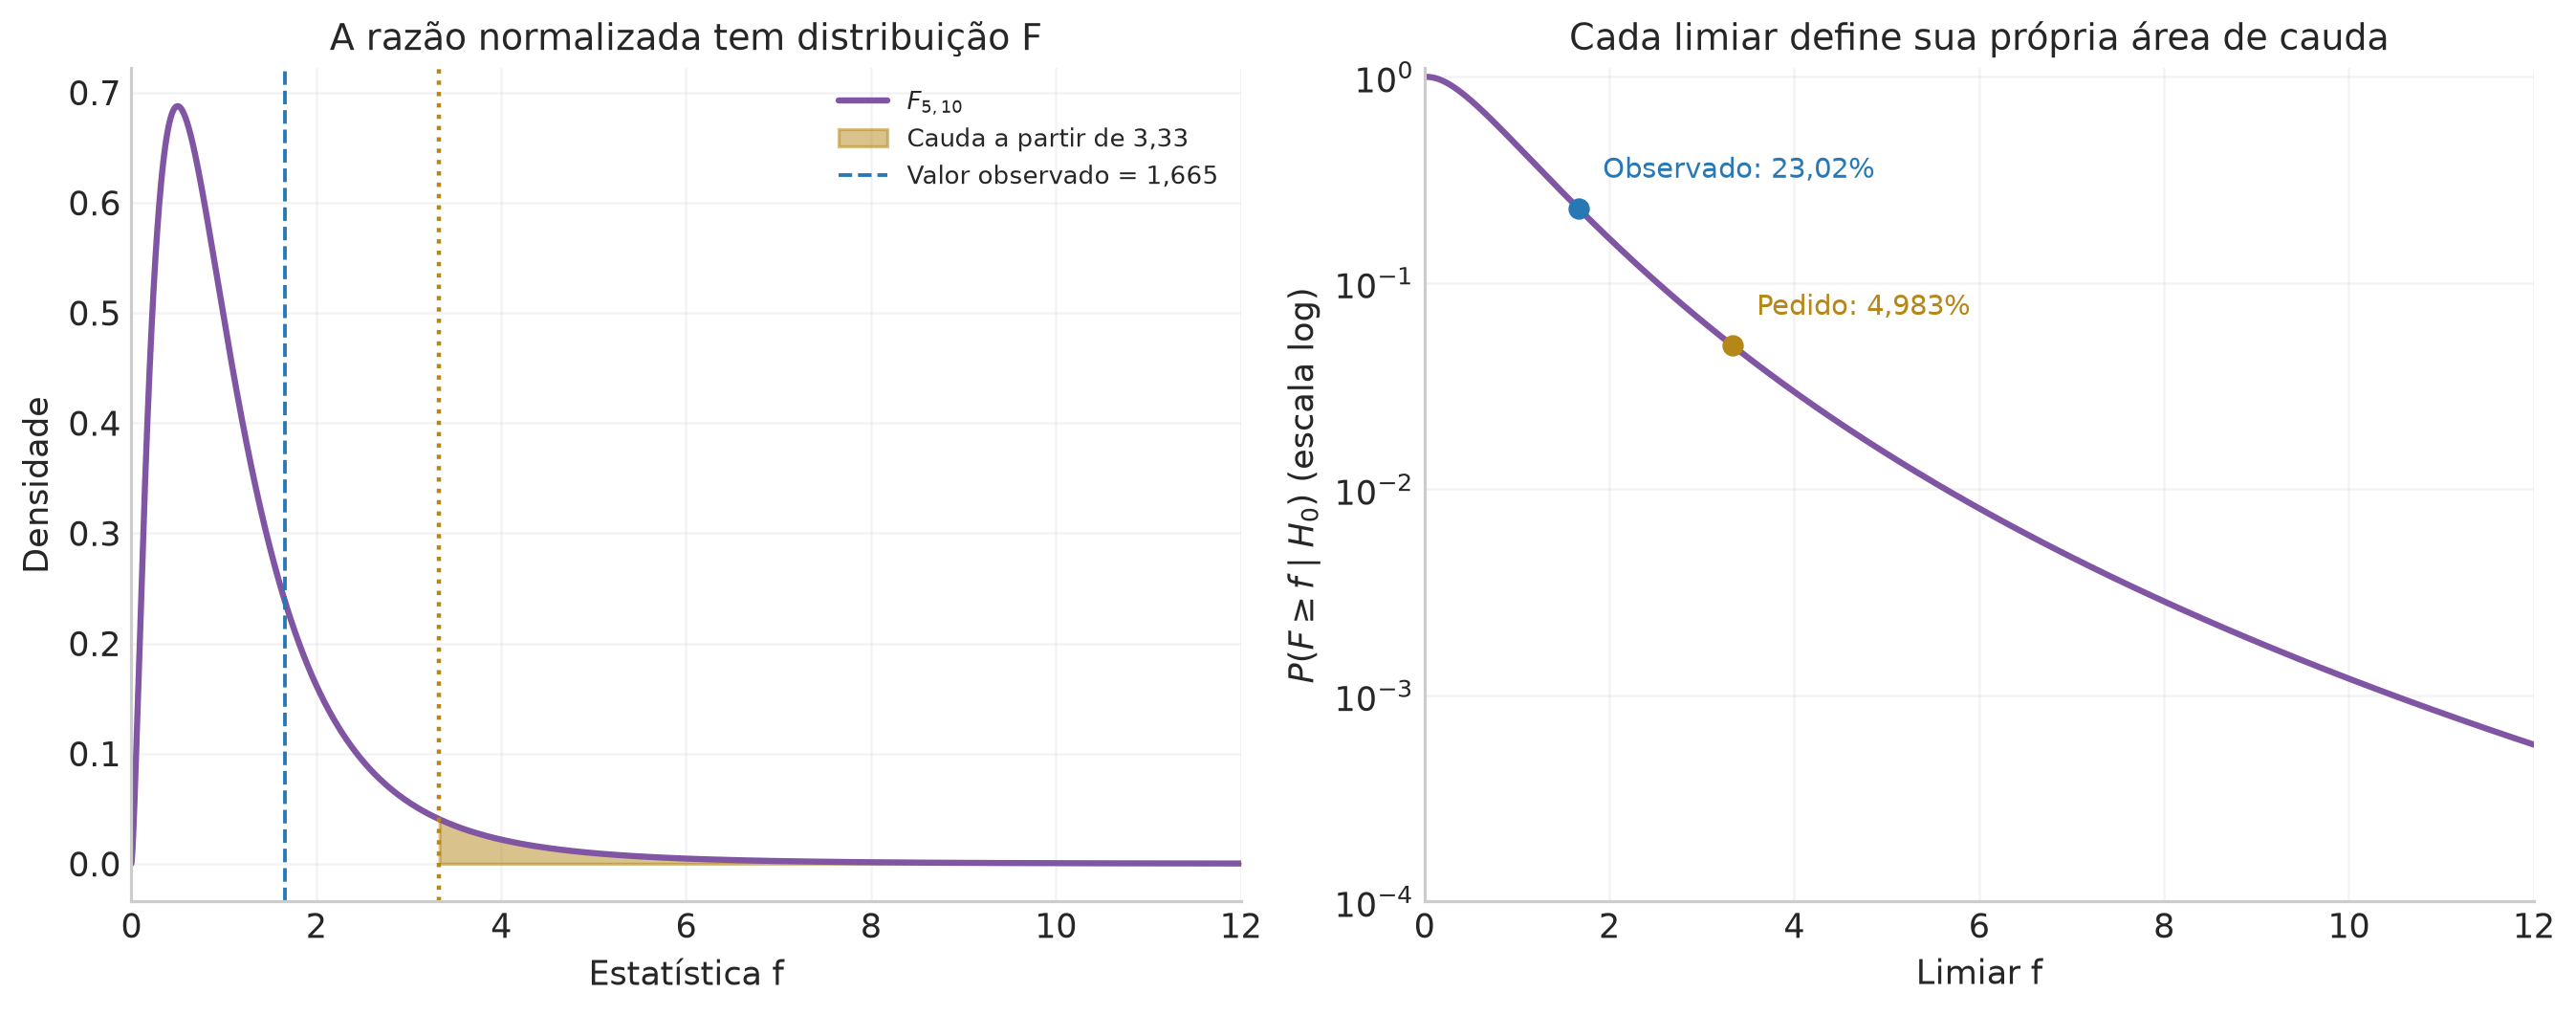

In [31]:
def q5_f_pdf(value,nu1,nu2):
    """PDF F pela fórmula deduzida; betaln é log B(a,b)."""
    if nu1<=0 or nu2<=0:
        raise ValueError("Os dois graus de liberdade devem ser positivos.")
    value=np.asarray(value,dtype=float)
    positive=np.where(value>0,value,1.0)
    a,b,c=nu1/2,nu2/2,nu1/nu2
    logpdf=a*np.log(c)+(a-1)*np.log(positive)-(a+b)*np.log1p(c*positive)-betaln(a,b)
    return np.where(value>0,np.exp(logpdf),0.0)

q5_n1,q5_n2=6,11
q5_nu1,q5_nu2=q5_n1-1,q5_n2-1
q5_s1_squared,q5_s2_squared=16.65,5.0
q5_variance_ratio0=2.0
q5_raw_ratio=q5_s1_squared/q5_s2_squared
q5_f_observed=q5_raw_ratio/q5_variance_ratio0
q5_f_cut=3.33  # Limiar explicitamente pedido no Gregory; não é f_observado.
q5_f_tail_sf=f_distribution.sf(q5_f_cut,q5_nu1,q5_nu2)
q5_f_tail_quad=quad(lambda value:q5_f_pdf(value,q5_nu1,q5_nu2),q5_f_cut,np.inf,epsabs=1e-12)[0]
q5_w_cut=q5_nu1*q5_f_cut/(q5_nu1*q5_f_cut+q5_nu2)
q5_f_tail_beta=quad(lambda w:beta_distribution.pdf(w,q5_nu1/2,q5_nu2/2),q5_w_cut,1,epsabs=1e-12)[0]
q5_f_tail_reciprocal=f_distribution.cdf(1/q5_f_cut,q5_nu2,q5_nu1)
q5_f_tail_observed=f_distribution.sf(q5_f_observed,q5_nu1,q5_nu2)

export_table("q5_64_cauda",["Cálculo para F a partir de 3,33","Probabilidade","Probabilidade (%)"],
             [["Quadratura da PDF deduzida",q5_f_tail_quad,100*q5_f_tail_quad],
              ["Função de sobrevivência F",q5_f_tail_sf,100*q5_f_tail_sf],
              ["Integral da Beta transformada",q5_f_tail_beta,100*q5_f_tail_beta],
              ["CDF da razão recíproca",q5_f_tail_reciprocal,100*q5_f_tail_reciprocal]],
             [0,12,9])
export_table("q5_64_limites_distintos",["Evento","Limiar em F","Limiar na razão bruta","Probabilidade sob H0"],
             [["Cauda pedida",q5_f_cut,q5_variance_ratio0*q5_f_cut,q5_f_tail_sf],
              ["Cauda do valor observado",q5_f_observed,q5_raw_ratio,q5_f_tail_observed]],
             [0,6,6,12])

q5_fgrid=np.linspace(0,12,3000)
q5_fdensity=q5_f_pdf(q5_fgrid,q5_nu1,q5_nu2)
fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
axes[0].plot(q5_fgrid,q5_fdensity,color=PURPLE,label=r"$F_{5,10}$")
axes[0].fill_between(q5_fgrid,0,q5_fdensity,where=q5_fgrid>=q5_f_cut,color=GOLD,alpha=.5,label="Cauda a partir de 3,33")
axes[0].axvline(q5_f_observed,color=BLUE,ls="--",lw=1.2,label="Valor observado = 1,665")
axes[0].axvline(q5_f_cut,color=GOLD,ls=":",lw=1.4)
axes[0].set(xlabel="Estatística f",ylabel="Densidade",title="A razão normalizada tem distribuição F",xlim=(0,12))
axes[0].legend(loc="upper right",fontsize=8)
axes[1].semilogy(q5_fgrid,f_distribution.sf(q5_fgrid,q5_nu1,q5_nu2),color=PURPLE)
for value,probability,color,label,offset in [
    (q5_f_observed,q5_f_tail_observed,BLUE,"Observado: 23,02%",(8,10)),
    (q5_f_cut,q5_f_tail_sf,GOLD,"Pedido: 4,983%",(8,10))]:
    axes[1].scatter([value],[probability],color=color,zorder=4)
    axes[1].annotate(label,(value,probability),xytext=offset,textcoords="offset points",color=color,fontsize=9)
axes[1].set(xlabel="Limiar f",ylabel=r"$P(F\geq f\mid H_0)$ (escala log)",
            title="Cada limiar define sua própria área de cauda",xlim=(0,12),ylim=(1e-4,1.1))
save_figure(fig,"q5_64_cauda_f")

### Interpretar a diferença entre os dois limiares

Com $R=S_1^2/S_2^2$, a hipótese $\rho_0=2$ implica $R=2F$. Então os dois eventos são

$$\begin{aligned}
\text{pedido no texto:}\quad F\geq3{,}33
&\ \Longleftrightarrow\ R\geq6{,}66,\\
\text{tão grande quanto o observado:}\quad F\geq1{,}665
&\ \Longleftrightarrow\ R\geq3{,}33.
\end{aligned}$$

O segundo evento tem probabilidade aproximadamente $0{,}2302163$, ou **23,0216%**. Não vamos substituí-lo pela resposta pedida de 4,98313%, nem usar esta última como a área associada ao valor observado $f_{\rm obs}=1{,}665$.

O limiar 3,33 fica perto do quantil 95% de $F_{5,10}$, aproximadamente 3,32583, o que ajuda a conferir a cauda próxima de 5%. Isso diz respeito ao limiar hipotético pedido. As áreas são condicionadas à hipótese de razão populacional 2; não são probabilidades posteriores dessa hipótese e, sozinhas, não constituem uma comparação bayesiana de modelos.

### Conferir a construção gerando as duas amostras normais

Para visualizar a origem de $F$, escolhemos na simulação $\sigma_2^2=1$ e $\sigma_1^2=2$, sob $H_0$, e médias populacionais zero. Os valores absolutos são apenas uma escolha de unidades e de origem para a conferência: a razão normalizada elimina essas escolhas.

Em cada repetição, geramos uma amostra com 6 medidas e outra com 11, calculamos suas variâncias com denominadores 5 e 10 e formamos $F=S_1^2/(2S_2^2)$. Em seguida calculamos também $R=2F$. Pela transformação de escala, sua PDF é

$$f_R(r)=\frac12 f_F(r/2),\qquad r>0.$$

Os histogramas abaixo usam o número total de repetições no denominador, incluindo os valores que caem fora da janela visível. Assim não renormalizamos indevidamente uma cauda cortada no desenho.

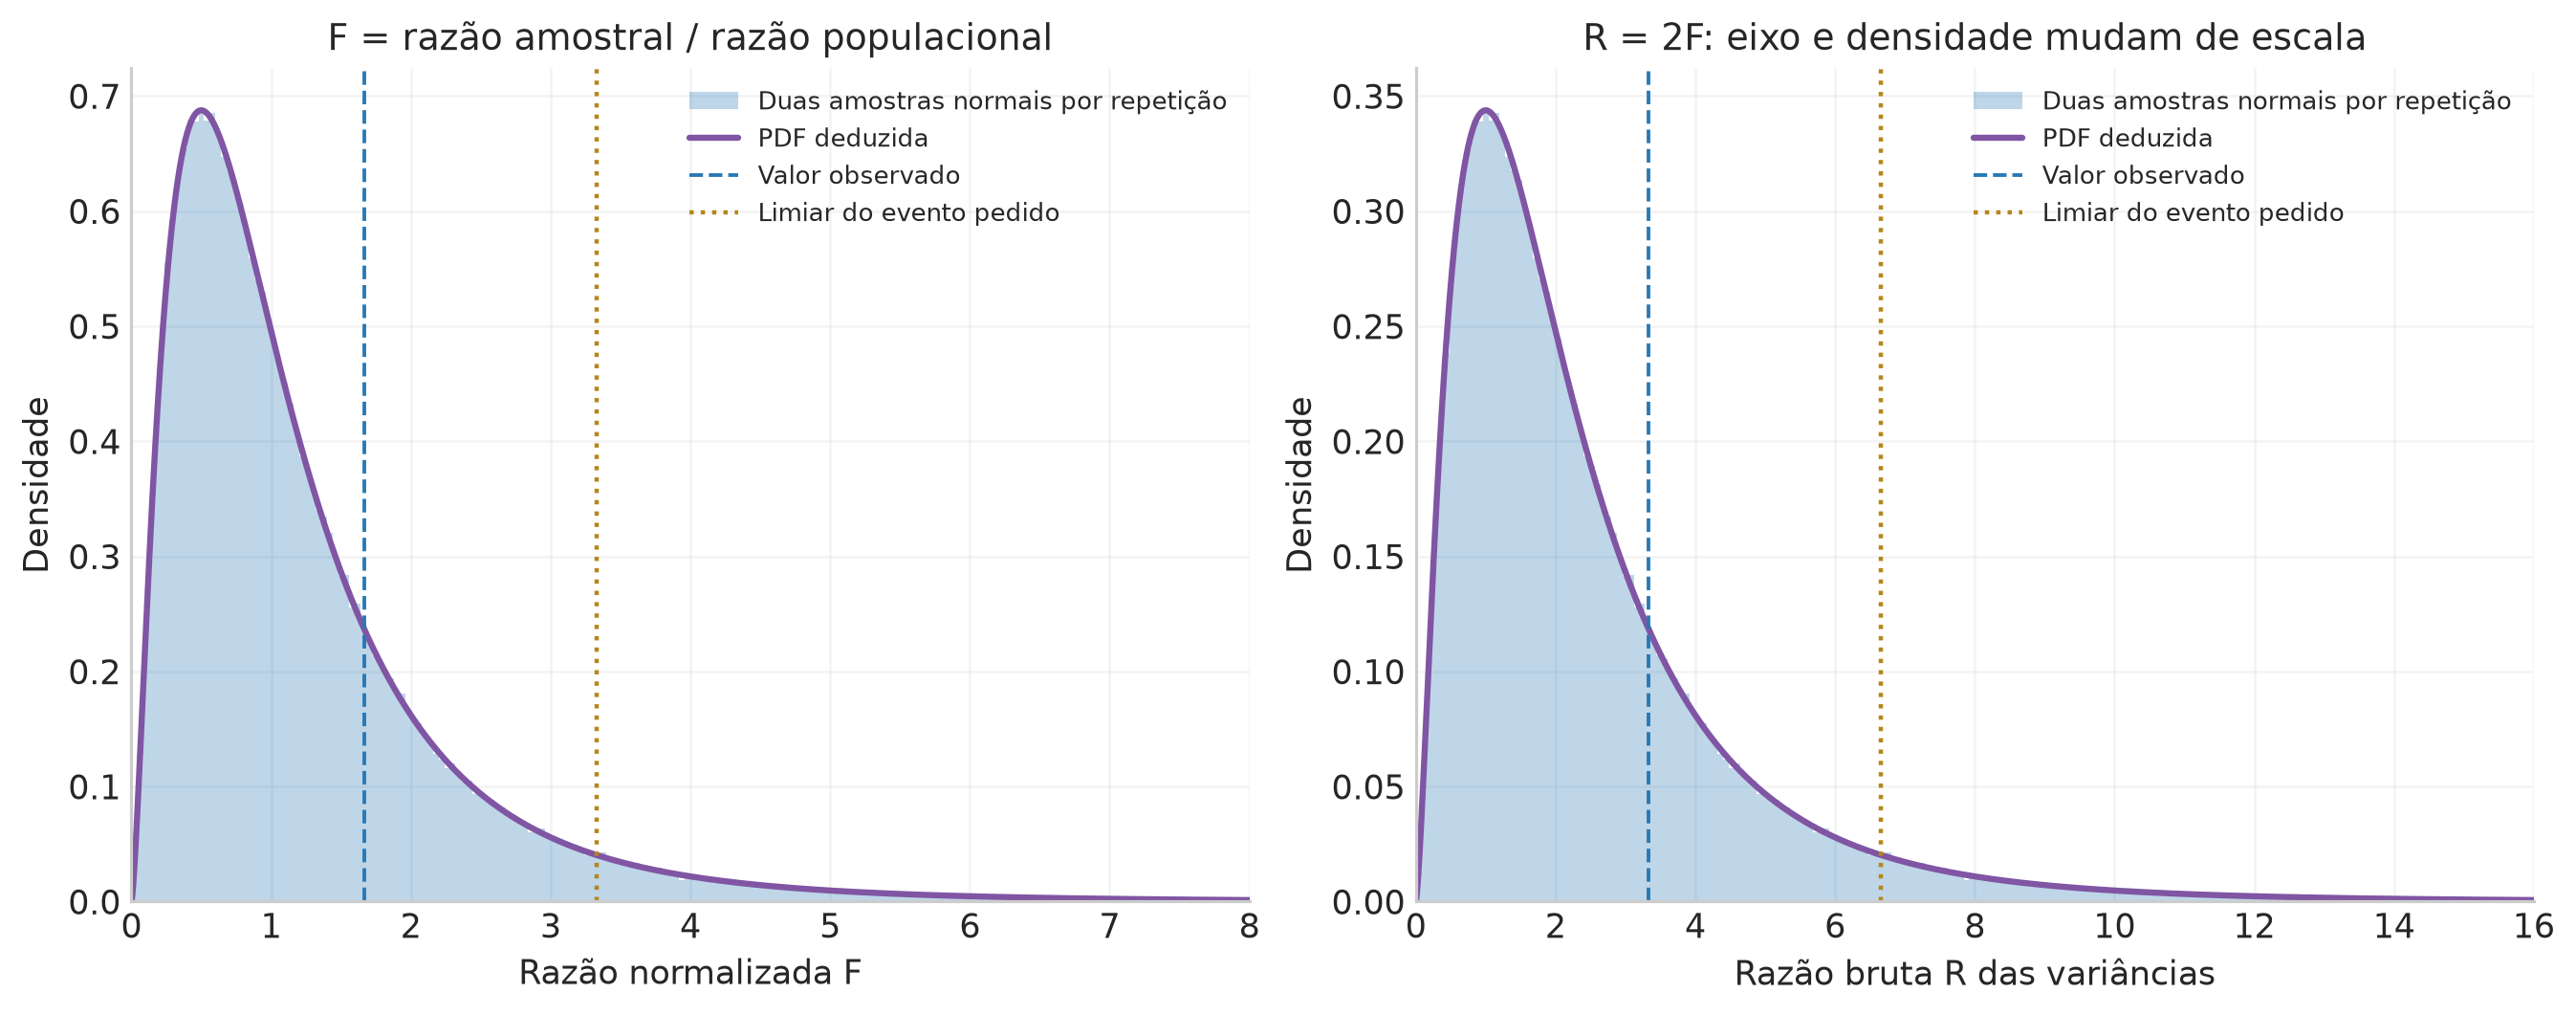

In [32]:
q5_MF=300_000
q5_simulated_f=np.empty(q5_MF)
for start in range(0,q5_MF,25_000):
    stop=min(start+25_000,q5_MF)
    group1=q5_rng.normal(scale=np.sqrt(2),size=(stop-start,q5_n1))
    group2=q5_rng.normal(scale=1,size=(stop-start,q5_n2))
    var1=group1.var(axis=1,ddof=1)
    var2=group2.var(axis=1,ddof=1)
    q5_simulated_f[start:stop]=var1/(q5_variance_ratio0*var2)
q5_simulated_R=q5_variance_ratio0*q5_simulated_f

fig,axes=plt.subplots(1,2,figsize=(11.6,4.5),layout="constrained")
for ax,values,scale in [(axes[0],q5_simulated_f,1.0),(axes[1],q5_simulated_R,2.0)]:
    edges=np.linspace(0,8*scale,201)
    counts,_=np.histogram(values,bins=edges)
    ax.stairs(counts/(q5_MF*np.diff(edges)),edges,color=BLUE,fill=True,alpha=.3,label="Duas amostras normais por repetição")
    grid=np.linspace(0,8*scale,2500)
    ax.plot(grid,q5_f_pdf(grid/scale,q5_nu1,q5_nu2)/scale,color=PURPLE,label="PDF deduzida")
    ax.axvline(scale*q5_f_observed,color=BLUE,ls="--",lw=1.2,label="Valor observado")
    ax.axvline(scale*q5_f_cut,color=GOLD,ls=":",lw=1.4,label="Limiar do evento pedido")
    ax.set(ylabel="Densidade",xlim=(0,8*scale))
    ax.legend(loc="upper right",fontsize=8)
axes[0].set(xlabel="Razão normalizada F",title="F = razão amostral / razão populacional")
axes[1].set(xlabel="Razão bruta R das variâncias",title="R = 2F: eixo e densidade mudam de escala")
save_figure(fig,"q5_64_geracao_razoes")

# Questão 6 · Inferir a prevalência com um teste imperfeito

Antes de começar as contas, vou separar as quantidades que aparecem no problema. A **prevalência** é a probabilidade de uma pessoa escolhida ao acaso ter a doença na cidade e na semana estudadas. O resultado do teste acrescenta outra camada: pessoas com a doença podem receber resultado negativo e pessoas saudáveis podem receber resultado positivo.

O enunciado fornece $\mathrm{FPR}=1\%$, $\mathrm{FNR}=15\%$, $n_{\rm tot}=250$ e $n_{\rm yes}=7$. Queremos usar essa contagem para obter uma distribuição sobre a prevalência. Vou desenvolver primeiro o modelo exato, depois a aproximação Beta, explorar seu alcance e, por fim, combinar duas cidades.

| Símbolo | Significado |
|:--|:--|
| $A$ | A pessoa tem a doença |
| $T^+$ | Seu teste é positivo |
| $p_a=P(A\mid I)$ | Prevalência da cidade, parâmetro a inferir |
| $f=P(T^+\mid \bar A,I)=0{,}01$ | Taxa de falsos positivos, FPR |
| $r=P(T^-\mid A,I)=0{,}15$ | Taxa de falsos negativos, FNR |
| $s=1-r=0{,}85$ | Sensibilidade: $P(T^+\mid A,I)$ |
| $h=s-f=0{,}84$ | Quanto a probabilidade de teste positivo muda ao variar a prevalência |
| $q=P(T^+\mid p_a,I)$ | Probabilidade de um resultado positivo na população |
| $Y$, $k$ e $n$ | Contagem aleatória de positivos, contagem observada e total de testes |
| $D=(k,n)$ | Os dados usados para a inferência |

**Hipóteses.** Os testes se referem à mesma semana; a amostra representa a cidade; os resultados são independentes condicionados a $p_a$; $f$ e $r$ têm os valores conhecidos acima. A amostragem é modelada por tentativas de Bernoulli com parâmetro comum. Para uma população finita, essa descrição corresponde à aproximação de uma fração amostrada pequena. Seleção por sintomas ou contatos exigiria incorporar o mecanismo de seleção ao modelo.

O enunciado deixa a prior de $p_a$ em aberto. Vou adotar explicitamente

$$\pi(p_a\mid I)=1,\qquad 0\leq p_a\leq1.$$

É uma prior uniforme na prevalência, que permite construir uma resposta definida para os itens. Os resultados abaixo são condicionados a essa escolha. Uma prior diferente pode ser incorporada multiplicando a mesma likelihood por sua densidade e normalizando novamente.

### Item (a) · Da situação física à likelihood

Um teste positivo pode vir de dois caminhos mutuamente exclusivos. Pela regra do produto e pela soma sobre o estado de saúde,

$$\begin{aligned}
q(p_a)&=P(T^+,A\mid p_a,I)+P(T^+,\bar A\mid p_a,I)\\
&=P(T^+\mid A,I)P(A\mid p_a,I)
+P(T^+\mid\bar A,I)P(\bar A\mid p_a,I)\\
&=s p_a+f(1-p_a)=f+h p_a.
\end{aligned}$$

Portanto,

$$\boxed{q(p_a)=0{,}01+0{,}84p_a,\qquad 0{,}01\leq q\leq0{,}85.}$$

O primeiro termo $s p_a$ descreve positivos verdadeiros e o segundo $f(1-p_a)$ descreve falsos positivos. A fração de testes positivos contém ambas as contribuições. Mesmo para $p_a=0$, a contagem média de positivos em 250 testes é $250f=2{,}5$.

Para construir a distribuição de $Y$, definimos $X_i=1$ quando o teste $i$ é positivo e $X_i=0$ quando é negativo. Uma sequência específica de $k$ positivos e $n-k$ negativos tem probabilidade $q^k(1-q)^{n-k}$. Há $\binom nk$ sequências com essa contagem, logo

$$Y=\sum_{i=1}^nX_i\mid p_a,I\sim\operatorname{Binomial}(n,q(p_a)),$$

$$\boxed{\mathcal L(p_a;D)=P(Y=k\mid p_a,I)
=\binom nk(f+hp_a)^k(1-f-hp_a)^{n-k}.}$$

A binomial é normalizada somando sobre $k=0,\ldots,n$, para cada $p_a$ fixo. Após observar $k$, essa mesma expressão é a likelihood em função de $p_a$. A posterior será uma densidade normalizada integrando sobre $p_a$.

Pelo teorema de Bayes, com a prior uniforme escolhida,

$$p(p_a\mid D,I)=\frac{(f+hp_a)^k(1-f-hp_a)^{n-k}}
{\displaystyle\int_0^1(f+hu)^k(1-f-hu)^{n-k}\,du},\qquad 0\leq p_a\leq1.$$

O coeficiente binomial é constante em $p_a$ e se cancela nesse quociente. Ele será mantido quando calcularmos a evidência $P(Y=k\mid n,I)$.

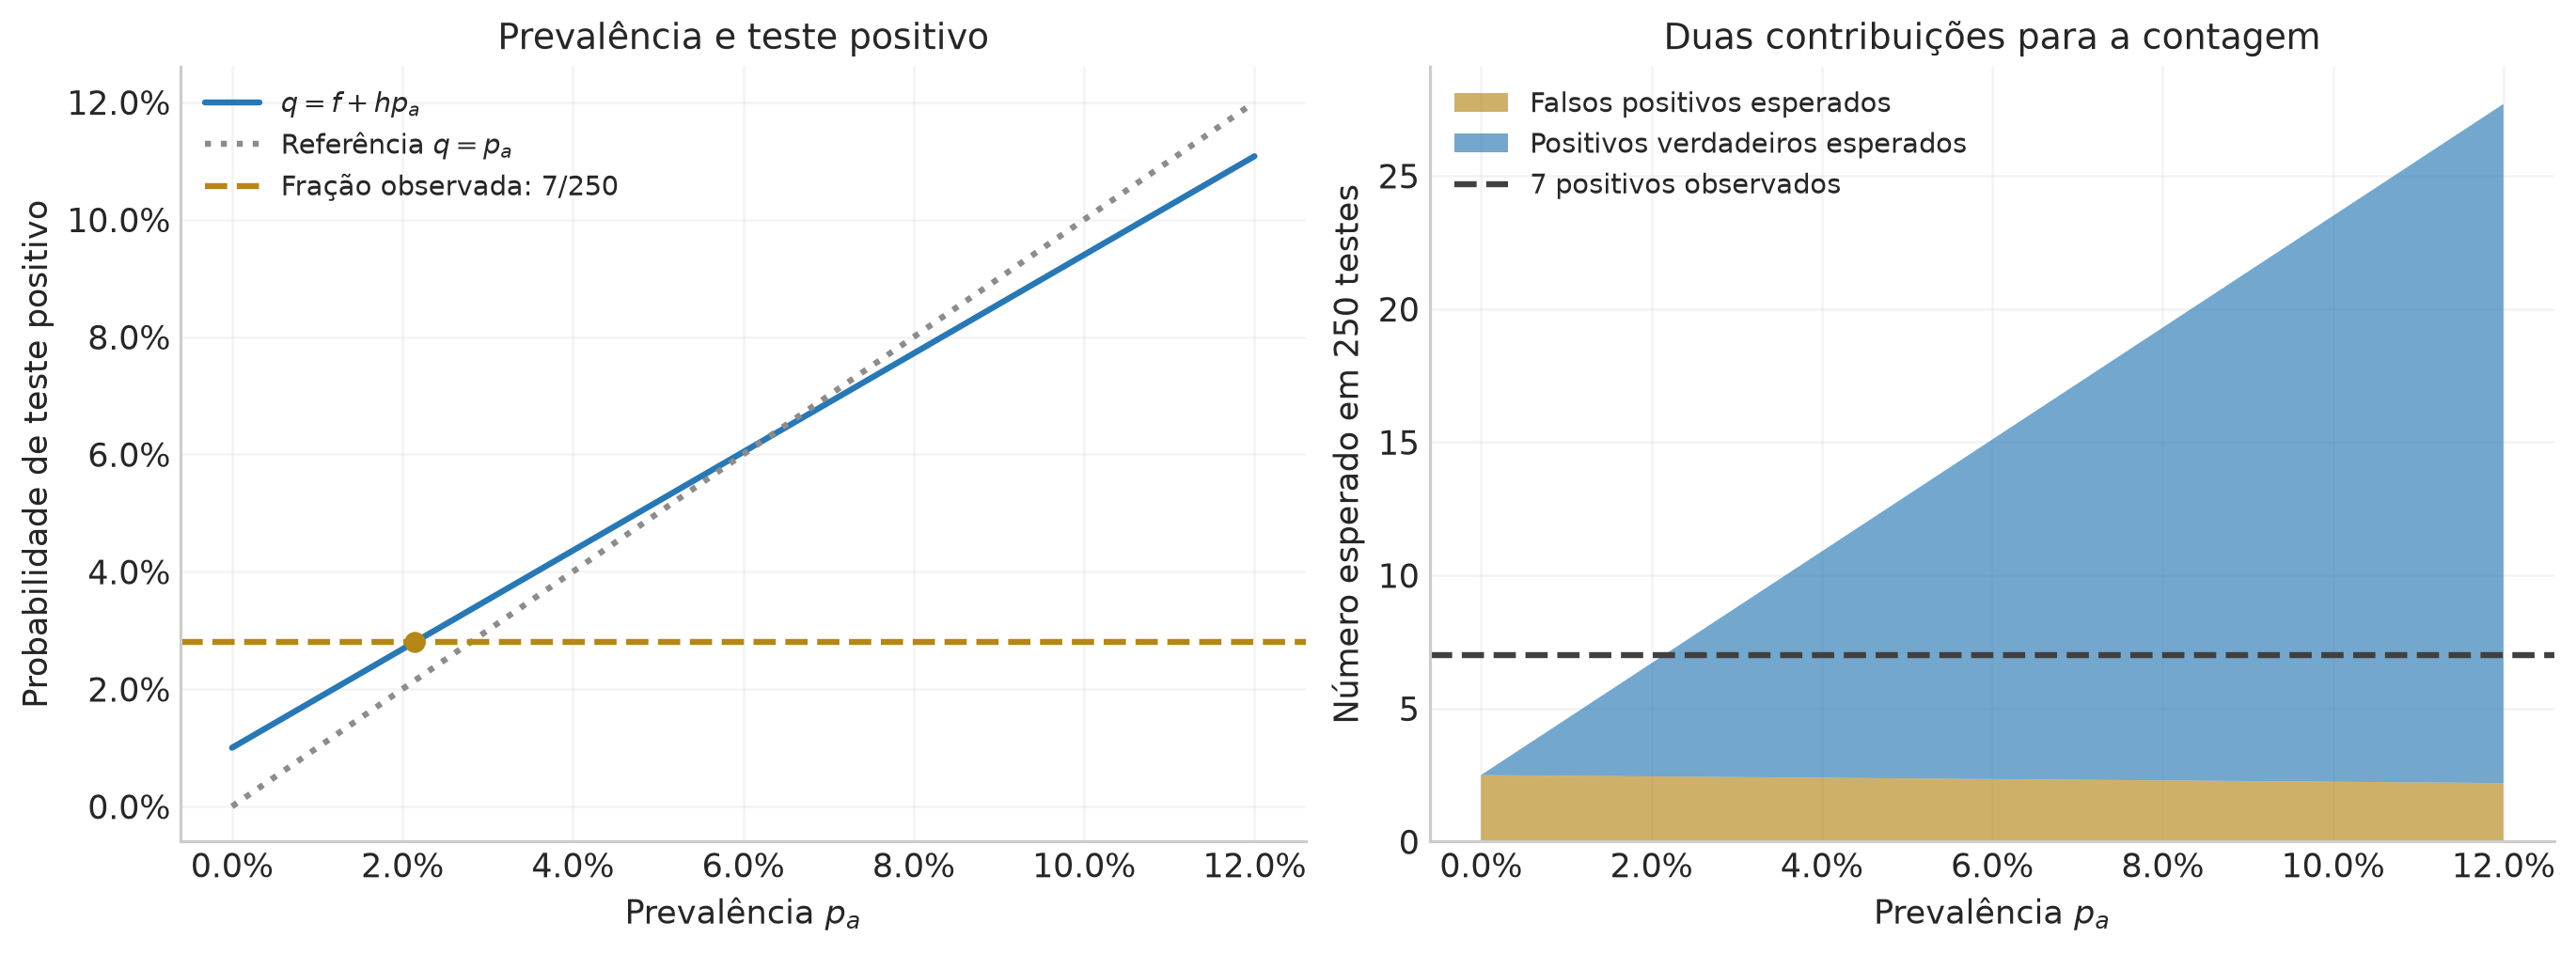

In [33]:
# Questão 6: calibração conhecida do teste e amostra original.
from scipy.stats import beta as beta_distribution
from scipy.special import betaln, gammaln, xlogy, xlog1py
from scipy.integrate import cumulative_trapezoid
from scipy.signal import fftconvolve
from IPython.utils.capture import capture_output

q6_f, q6_r = .01, .15
q6_s = 1-q6_r
q6_h = q6_s-q6_f
q6_delta = q6_f/q6_h
q6_n, q6_k = 250, 7

q6_p_grid = np.linspace(0,.12,700)
q6_true = q6_s*q6_p_grid
q6_false = q6_f*(1-q6_p_grid)
fig,axes=plt.subplots(1,2,figsize=(11.8,4.3),layout="constrained")
axes[0].plot(q6_p_grid,q6_true+q6_false,color=BLUE,label=r"$q=f+hp_a$")
axes[0].plot(q6_p_grid,q6_p_grid,ls=":",color=".55",label=r"Referência $q=p_a$")
axes[0].axhline(q6_k/q6_n,color=GOLD,ls="--",label="Fração observada: 7/250")
axes[0].scatter([(q6_k/q6_n-q6_f)/q6_h],[q6_k/q6_n],color=GOLD,zorder=4)
axes[0].set(xlabel=r"Prevalência $p_a$",ylabel="Probabilidade de teste positivo",title="Prevalência e teste positivo")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=9)
axes[1].stackplot(q6_p_grid,q6_n*q6_false,q6_n*q6_true,
                 labels=["Falsos positivos esperados","Positivos verdadeiros esperados"],
                 colors=[GOLD,BLUE],alpha=.65)
axes[1].axhline(q6_k,color=".25",ls="--",label="7 positivos observados")
axes[1].set(xlabel=r"Prevalência $p_a$",ylabel="Número esperado em 250 testes",title="Duas contribuições para a contagem")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(loc="upper left",fontsize=9)
save_figure(fig,"q6_a_modelo_teste")

### Normalizar a posterior: por que uma Beta aparece no resultado exato?

Vamos abrir a integral para reconhecer a distribuição. A função Beta e a função Beta incompleta regularizada são definidas por

$$B(a,b)=\int_0^1 t^{a-1}(1-t)^{b-1}\,dt,\qquad
I_z(a,b)=\frac1{B(a,b)}\int_0^z t^{a-1}(1-t)^{b-1}\,dt.$$

Assim, a densidade $\operatorname{Beta}(a,b)$ é $b_{a,b}(t)=t^{a-1}(1-t)^{b-1}/B(a,b)$ em $[0,1]$. Com $a=k+1$ e $b=n-k+1$, o produto de potências da likelihood tem exatamente esses expoentes na variável $q$.

A mudança $q=f+hp_a$ dá $dq=h\,dp_a$. Os limites físicos da prevalência correspondem a $q=f$ e $q=s$. Definindo

$$C_{\rm ex}=I_s(a,b)-I_f(a,b),$$

encontramos

$$\int_0^1(f+hp_a)^k(1-f-hp_a)^{n-k}\,dp_a
=\frac{B(a,b)}{h}\,C_{\rm ex}.$$

Portanto, a resposta exata é

$$\boxed{p(p_a\mid D,I)=\frac{h}{C_{\rm ex}}\,
b_{k+1,n-k+1}(f+hp_a),\qquad 0\leq p_a\leq1.}$$

Podemos ler essa expressão como uma **Beta em $q$, truncada em $[f,s]$, seguida da transformação $p_a=(q-f)/h$**. A escala $h$ e o intervalo de truncamento fazem parte da resposta.

Para os dados originais,

$$a=8,\quad b=244,\quad C_{\rm ex}=I_{0{,}85}(8,244)-I_{0{,}01}(8,244),$$
$$\boxed{p(p_a\mid D,I)=\frac{0{,}84}{C_{\rm ex}B(8,244)}
(0{,}01+0{,}84p_a)^7(0{,}99-0{,}84p_a)^{243}.}$$

Essa fórmula é exata sob as hipóteses do modelo e da prior. Para a evidência, usamos $B(k+1,n-k+1)=k!(n-k)!/(n+1)!$, obtida por integração por partes como na questão 3. Segue que

$$\boxed{P(Y=k\mid n,I)=\frac{C_{\rm ex}}{h(n+1)}.}$$

#### Estimativas e intervalos a partir da mesma densidade

Derivando a log-likelihood,

$$\frac{d\log\mathcal L}{dp_a}
=h\left[\frac{k}{f+hp_a}-\frac{n-k}{1-f-hp_a}\right].$$

A solução interior satisfaz $q=k/n$; respeitando os limites físicos,

$$\boxed{\widehat p_{a,\rm MAP}=\min\!\left(1,\max\!\left(0,\frac{k/n-f}{h}\right)\right).}$$

O MAP coincide com o máximo da likelihood para a prior uniforme. A estrita concavidade da log-likelihood, cuja segunda derivada é $-h^2[k/q^2+(n-k)/(1-q)^2]<0$, garante esse máximo; nos casos de fronteira, usamos o sinal da primeira derivada. Aqui, $\widehat p_{a,\rm MAP}=0{,}02142857$, cerca de $2{,}143\%$.

Para o intervalo central de credibilidade, integramos a PDF:

$$F_p(u)=\frac{I_{f+hu}(a,b)-I_f(a,b)}{C_{\rm ex}},\qquad0\leq u\leq1.$$

Os extremos de 95% são os quantis de probabilidades $0{,}025$ e $0{,}975$. A média e a variância também vêm de integrais da PDF. Por exemplo,

$$\mathbb E[q^j\mid D]=\frac{B(a+j,b)}{B(a,b)}
\frac{I_s(a+j,b)-I_f(a+j,b)}{C_{\rm ex}},$$

$$\mathbb E[p_a\mid D]=\frac{\mathbb E[q\mid D]-f}{h},\qquad
\operatorname{Var}(p_a\mid D)=\frac{\operatorname{Var}(q\mid D)}{h^2}.$$

Assim, cada resumo pode ser calculado diretamente da distribuição já deduzida.

| Quantidade | Valor em % |
| :-- | :-- |
| Fração de testes positivos | 2,800000 |
| MAP da prevalência | 2,142857 |
| Média posterior | 2,600219 |
| Mediana posterior | 2,448804 |
| Desvio padrão posterior | 1,302825 |
| Quantil de 2,5% | 0,508537 |
| Quantil de 97,5% | 5,552646 |

C_ex = 0.995877900197; evidência = 0.004723382186


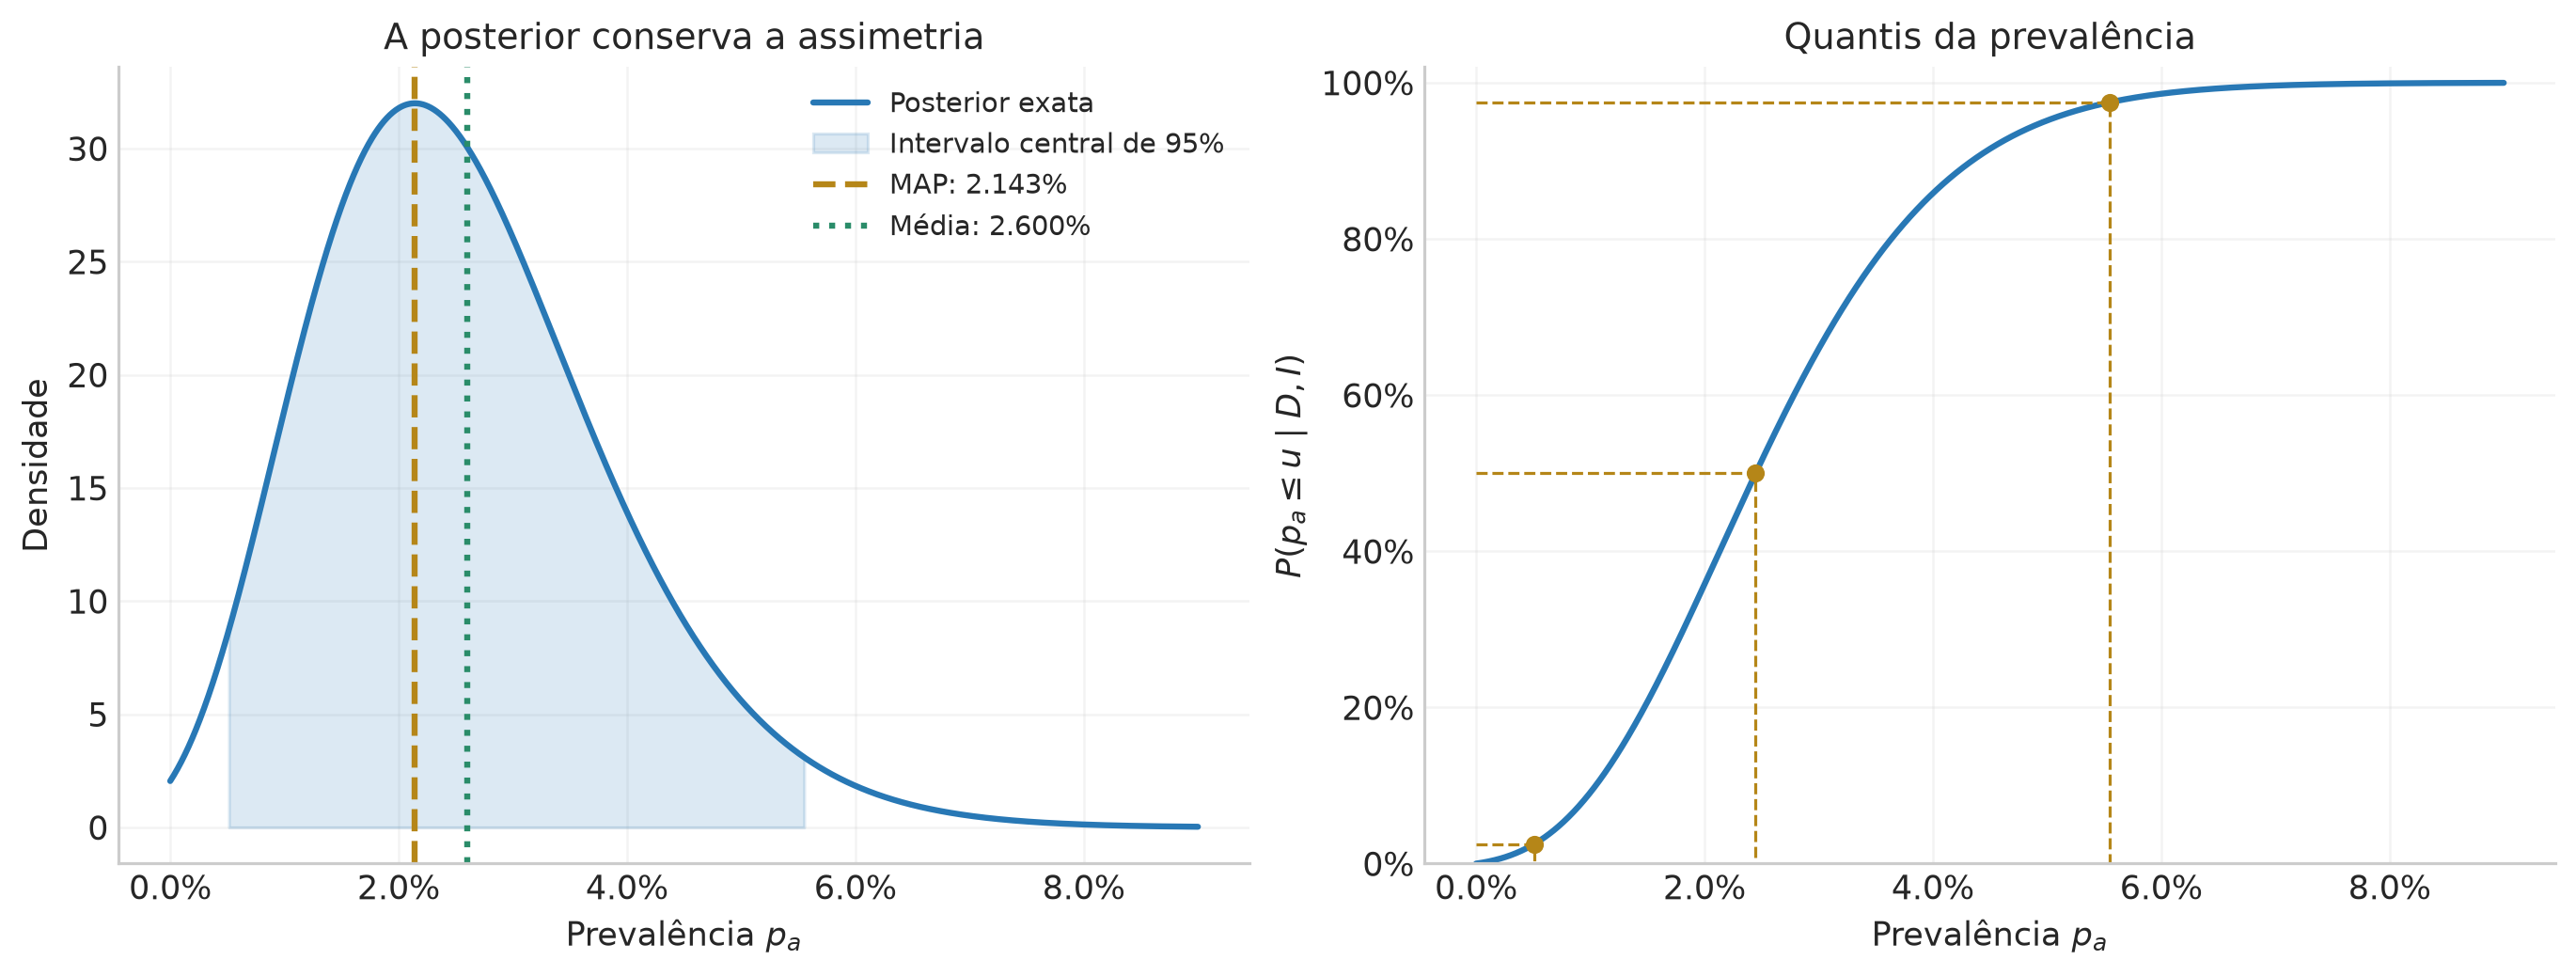

In [34]:
def q6_beta_mass(a,b,lo,hi):
    """Massa Beta entre limites; escolhe CDF ou SF para preservar precisão."""
    lo,hi=np.asarray(lo),np.asarray(hi)
    cl,ch=beta_distribution.cdf(lo,a,b),beta_distribution.cdf(hi,a,b)
    sl,sh=beta_distribution.sf(lo,a,b),beta_distribution.sf(hi,a,b)
    return np.maximum(0,np.where(ch<=sl,ch-cl,sl-sh))

def q6_exact_posterior(n,k):
    """Posterior com prior uniforme, incluindo suporte, CDF, PPF e momentos."""
    if int(n)!=n or int(k)!=k or n<1 or not 0<=k<=n:
        raise ValueError("Use contagens inteiras com 0 <= k <= n.")
    a,b=k+1,n-k+1
    mass=float(q6_beta_mass(a,b,q6_f,q6_s))
    if mass<=0:
        raise ArithmeticError("Massa fora da precisão disponível para esta amostra.")
    def pdf(p):
        p=np.asarray(p)
        return np.where((p>=0)&(p<=1),q6_h*beta_distribution.pdf(q6_f+q6_h*p,a,b)/mass,0.)
    def cdf(p):
        q=q6_f+q6_h*np.clip(np.asarray(p),0,1)
        return np.clip(q6_beta_mass(a,b,q6_f,q)/mass,0,1)
    def ppf(u):
        u=np.clip(np.asarray(u),0,1)
        if beta_distribution.cdf(q6_s,a,b)<=beta_distribution.sf(q6_f,a,b):
            q=beta_distribution.ppf(beta_distribution.cdf(q6_f,a,b)+u*mass,a,b)
        else:
            q=beta_distribution.isf(beta_distribution.sf(q6_s,a,b)+(1-u)*mass,a,b)
        p=np.clip((q-q6_f)/q6_h,0,1)
        return np.where(u==0,0.,np.where(u==1,1.,p))
    qmom=[np.exp(betaln(a+j,b)-betaln(a,b))*float(q6_beta_mass(a+j,b,q6_f,q6_s))/mass for j in (1,2)]
    mean=(qmom[0]-q6_f)/q6_h
    variance=(qmom[1]-qmom[0]**2)/q6_h**2
    return dict(n=n,k=k,a=a,b=b,mass=mass,pdf=pdf,cdf=cdf,ppf=ppf,
                mean=mean,var=variance,sd=np.sqrt(variance),
                mode=float(np.clip((k/n-q6_f)/q6_h,0,1)),evidence=mass/(q6_h*(n+1)))

q6_original=q6_exact_posterior(q6_n,q6_k)
q6_quantiles=q6_original["ppf"](np.array([.025,.5,.975]))
export_table("q6_a_resumo",["Quantidade","Valor em %"],
             [["Fração de testes positivos",100*q6_k/q6_n],
              ["MAP da prevalência",100*q6_original["mode"]],
              ["Média posterior",100*q6_original["mean"]],
              ["Mediana posterior",100*q6_quantiles[1]],
              ["Desvio padrão posterior",100*q6_original["sd"]],
              ["Quantil de 2,5%",100*q6_quantiles[0]],
              ["Quantil de 97,5%",100*q6_quantiles[2]]],[0,6])
print(f"C_ex = {q6_original['mass']:.12f}; evidência = {q6_original['evidence']:.12f}")

q6_grid=np.linspace(0,.09,1400)
fig,axes=plt.subplots(1,2,figsize=(11.8,4.4),layout="constrained")
axes[0].plot(q6_grid,q6_original["pdf"](q6_grid),color=BLUE,label="Posterior exata")
q6_central=(q6_grid>=q6_quantiles[0])&(q6_grid<=q6_quantiles[2])
axes[0].fill_between(q6_grid,0,q6_original["pdf"](q6_grid),where=q6_central,color=BLUE,alpha=.16,label="Intervalo central de 95%")
axes[0].axvline(q6_original["mode"],color=GOLD,ls="--",label=f"MAP: {100*q6_original['mode']:.3f}%")
axes[0].axvline(q6_original["mean"],color=GREEN,ls=":",label=f"Média: {100*q6_original['mean']:.3f}%")
axes[0].set(xlabel=r"Prevalência $p_a$",ylabel="Densidade",title="A posterior conserva a assimetria")
axes[0].legend(fontsize=9)
axes[1].plot(q6_grid,q6_original["cdf"](q6_grid),color=BLUE)
for u,v in zip(q6_quantiles,[.025,.5,.975]):
    axes[1].plot([0,u,u],[v,v,0],color=GOLD,ls="--",lw=1)
    axes[1].scatter([u],[v],color=GOLD,s=25,zorder=3)
axes[1].set(xlabel=r"Prevalência $p_a$",ylabel=r"$P(p_a\leq u\mid D,I)$",title="Quantis da prevalência",ylim=(0,1.02))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes: ax.xaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q6_a_posterior_exata")

### Ler o resultado do item (a)

A prevalência mais favorecida pela densidade é $2{,}143\%$. A média posterior é $2{,}600\%$ e a mediana é $2{,}449\%$. A cauda à direita faz a média ficar acima da moda. O intervalo central de 95% é aproximadamente

$$\boxed{p_a\in[0{,}5085\%;\ 5{,}5526\%]\quad\text{com probabilidade posterior de 95\%.}}$$

Essa é a incerteza sobre a prevalência da cidade e da semana, sob a prior e as hipóteses declaradas. O valor observado $7/250=2{,}8\%$ estima a chance de resultado positivo $q$. A transformação do MAP desconta a contribuição de falsos positivos e corrige a sensibilidade.

O parâmetro $p_a$ é fixo para a população modelada; sua distribuição posterior representa nossa informação após os testes. Ao amostrar valores dessa distribuição no código, estamos representando essa incerteza.

### Item (b) · Construir a aproximação Beta deslocada

O professor propõe uma Beta avaliada em $p_a+p_{\min}$. Para entender a origem dessa forma, definimos

$$t=p_a+\delta,\qquad \delta=p_{\min}=\frac fh=\frac1{84}\simeq0{,}01190476.$$

Então $q=ht$ e, omitindo fatores constantes em $p_a$,

$$\mathcal L(t)\propto t^k(1-ht)^{n-k},\qquad
\delta\leq t\leq1+\delta.$$

Um caminho útil é olhar para a derivada da log-likelihood:

$$\frac{d\log\mathcal L}{dt}
=\frac kt-\frac{h(n-k)}{1-ht}
=\frac{k-nht}{t(1-ht)}.$$

No regime de prevalência pequena, $t$ é pequeno nas regiões com massa posterior. Os fatores $1-ht$ e $1-t$ ficam próximos. Usando $1-ht\simeq1-t$ no denominador dessa expressão, preservamos o numerador $k-nht$ e obtemos

$$\frac{d\log\widetilde{\mathcal L}}{dt}
=\frac{k-nht}{t(1-t)}
=\frac kt-\frac{nh-k}{1-t}.$$

Integrando em $t$,

$$\log\widetilde{\mathcal L}(t)
=k\log t+(nh-k)\log(1-t)+\text{constante}.$$

Reconhecemos o núcleo de uma Beta:

$$\boxed{\alpha=k+1,\qquad\beta=nh-k+1,\qquad
\widetilde p(p_a\mid D)\propto b_{\alpha,\beta}(p_a+\delta).}$$

Os parâmetros da Beta admitem valores reais positivos. Assim, $nh$ pode ser lido como um tamanho efetivo nesta aproximação da forma da likelihood.

Podemos quantificar a aproximação. A razão das duas derivadas é

$$\frac{d\log\widetilde{\mathcal L}/dt}{d\log\mathcal L/dt}
=\frac{1-ht}{1-t}=1+\frac{(1-h)t}{1-t},$$

onde o limite no máximo é entendido pelas curvaturas. O erro local cresce com $(1-h)t/(1-t)$. Além disso, as duas expressões têm o mesmo máximo interior,

$$t_* = \frac{k}{nh}.$$

As curvaturas nesse ponto são

$$\ell''(t_*)=-\frac{nh}{t_*(1-ht_*)},\qquad
\widetilde\ell''(t_*)=-\frac{nh}{t_*(1-t_*)}.$$

Assim, para $0<t_*<1$, a Beta aproximada tende a ficar mais estreita. A razão das larguras locais é

$$\frac{\widetilde\sigma}{\sigma}\simeq
\sqrt{\frac{1-t_*}{1-ht_*}}.$$

Nos dados originais $t_*=1/30$, e a diferença de curvatura é pequena. Essa análise também antecipa os cenários interessantes do item (c).

| PDF | Média (%) | Desvio (p.p.) | Q2,5 (%) | Q97,5 (%) |
| :-- | :-- | :-- | :-- | :-- |
| Exata | 2,600219 | 1,302825 | 0,508537 | 5,552646 |
| Beta ajustada | 2,594424 | 1,296331 | 0,509234 | 5,528469 |

| Quantidade | Valor |
| :-- | :-- |
| Massa física da Beta literal | 0,9959017060 |
| Distância de variação total | 0,0018384345 |
| Maior diferença de CDF na malha | 0,0017649696 |

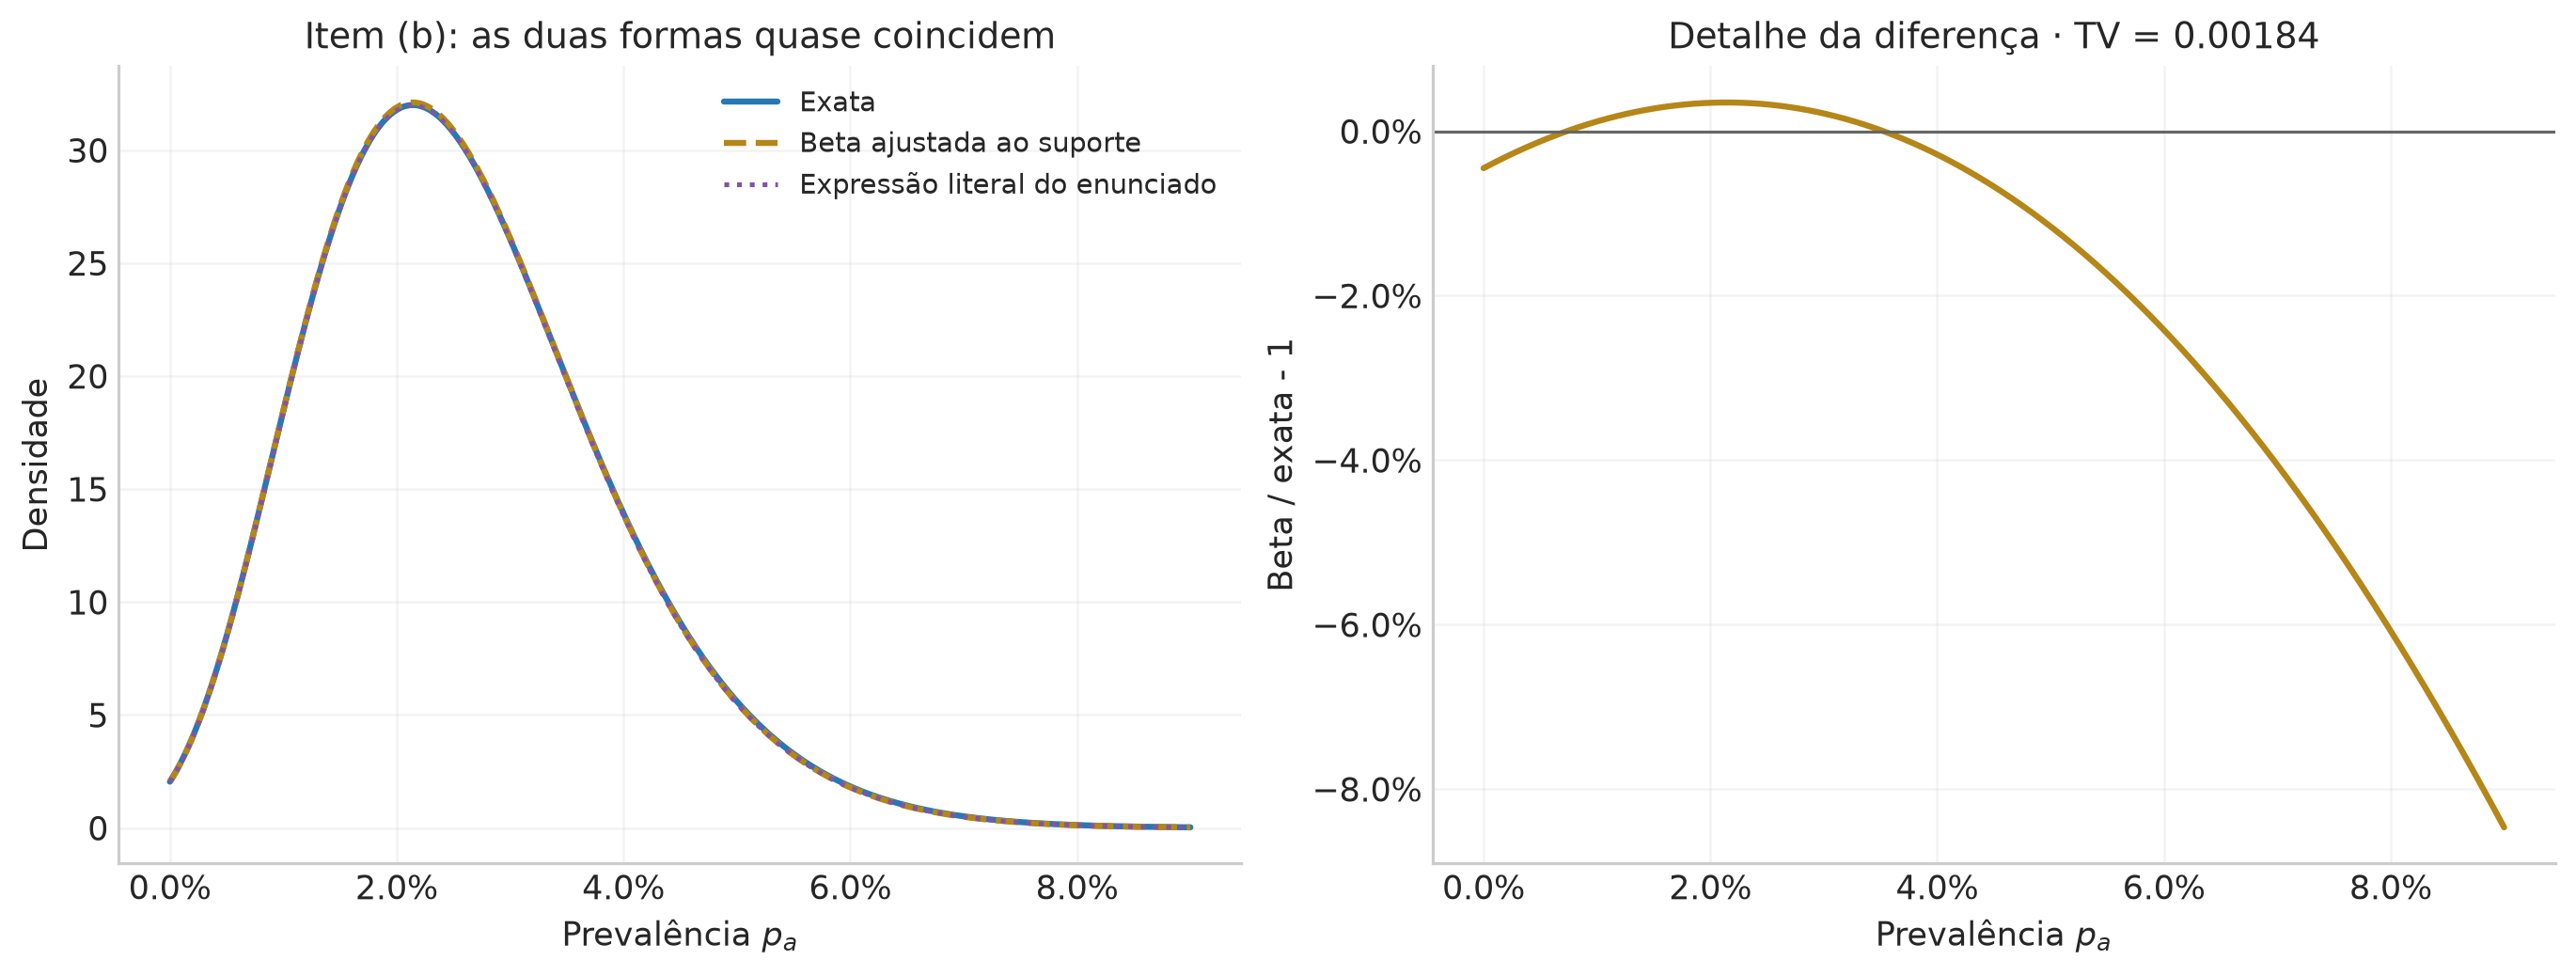

In [35]:
def q6_approx_posterior(n,k):
    """Beta proposta, deslocada e normalizada no suporte físico."""
    a,b=k+1,n*q6_h-k+1
    if a<=0 or b<=0:
        return None  # A família Beta requer ambos os parâmetros positivos.
    mass=float(beta_distribution.sf(q6_delta,a,b))
    def raw(p):
        p=np.asarray(p)
        return np.where((p>=0)&(p<=1),beta_distribution.pdf(p+q6_delta,a,b),0.)
    def pdf(p): return raw(p)/mass
    def cdf(p):
        t=np.clip(np.asarray(p)+q6_delta,q6_delta,1)
        return np.clip(q6_beta_mass(a,b,q6_delta,t)/mass,0,1)
    def ppf(u):
        u=np.clip(np.asarray(u),0,1)
        return np.clip(beta_distribution.isf((1-u)*mass,a,b)-q6_delta,0,1-q6_delta)
    tmom=[np.exp(betaln(a+j,b)-betaln(a,b))*beta_distribution.sf(q6_delta,a+j,b)/mass for j in (1,2)]
    variance=tmom[1]-tmom[0]**2
    return dict(a=a,b=b,mass=mass,raw=raw,pdf=pdf,cdf=cdf,ppf=ppf,
                mean=tmom[0]-q6_delta,var=variance,sd=np.sqrt(variance))

def q6_comparison(exact,approx):
    """TV por quadratura e diferença de CDF em malha adaptada às duas PDFs."""
    levels=np.array([1e-7,.001,.01,.1,.5,.9,.99,.999,1-1e-7])
    points=np.unique(np.r_[exact["ppf"](levels),approx["ppf"](levels),1-q6_delta])
    points=points[(points>0)&(points<1)]
    tv=.5*quad(lambda p:abs(float(exact["pdf"](p)-approx["pdf"](p))),0,1,
               epsabs=2e-10,epsrel=2e-8,points=points,limit=350)[0]
    grid=np.unique(np.r_[np.linspace(0,1,2001),exact["ppf"](np.linspace(.0001,.9999,1200)),
                         approx["ppf"](np.linspace(.0001,.9999,1200))])
    dcdf=np.max(np.abs(exact["cdf"](grid)-approx["cdf"](grid)))
    return tv,dcdf

q6_approx=q6_approx_posterior(q6_n,q6_k)
q6_tv,q6_dc=q6_comparison(q6_original,q6_approx)
q6_comp_rows=[]
for label,obj in [("Exata",q6_original),("Beta ajustada",q6_approx)]:
    ci=obj["ppf"](np.array([.025,.975]))
    q6_comp_rows.append([label,100*obj["mean"],100*obj["sd"],100*ci[0],100*ci[1]])
export_table("q6_b_comparacao",["PDF","Média (%)","Desvio (p.p.)","Q2,5 (%)","Q97,5 (%)"],q6_comp_rows,[0,6,6,6,6])
export_table("q6_b_erros",["Quantidade","Valor"],
             [["Massa física da Beta literal",q6_approx["mass"]],
              ["Distância de variação total",q6_tv],["Maior diferença de CDF na malha",q6_dc]], [0,10])

fig,axes=plt.subplots(1,2,figsize=(11.8,4.4),layout="constrained")
axes[0].plot(q6_grid,q6_original["pdf"](q6_grid),color=BLUE,label="Exata")
axes[0].plot(q6_grid,q6_approx["pdf"](q6_grid),color=GOLD,ls="--",label="Beta ajustada ao suporte")
axes[0].plot(q6_grid,q6_approx["raw"](q6_grid),color=PURPLE,ls=":",label="Expressão literal do enunciado",lw=1.6)
axes[0].set(xlabel=r"Prevalência $p_a$",ylabel="Densidade",title="Item (b): as duas formas quase coincidem")
axes[0].legend(fontsize=9)
q6_mask=q6_original["pdf"](q6_grid)>q6_original["pdf"](q6_grid).max()*1e-4
axes[1].plot(q6_grid[q6_mask],q6_approx["pdf"](q6_grid[q6_mask])/q6_original["pdf"](q6_grid[q6_mask])-1,color=GOLD,label="Diferença relativa de PDF")
axes[1].axhline(0,color=".4",lw=1)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(xlabel=r"Prevalência $p_a$",ylabel="Beta / exata - 1",title=f"Detalhe da diferença · TV = {q6_tv:.5f}")
for ax in axes: ax.xaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q6_b_exata_beta")

### Item (c) · O que muda ao alterar a amostra?

Vou explorar situações com interpretações diferentes, mantendo o teste, a prior e o modelo amostral. Em cada linha, recalculamos a posterior exata e a aproximação, incluindo a normalização física.

1. **Vigilância pequena:** 25 testes e zero positivos. A amostra fornece informação limitada e a posterior conserva uma cauda relevante de prevalências positivas.
2. **Uma semana com zero positivos:** 250 testes e zero positivos. A moda fica na fronteira $p_a=0$, enquanto o intervalo posterior quantifica prevalências ainda compatíveis com a amostra.
3. **No piso de falsos positivos:** 2.500 testes e 25 positivos. A fração observada coincide com $f=1\%$. A grande amostra concentra a prevalência junto da fronteira e torna a truncagem importante.
4. **Mesma fração, mais informação:** 2.500 testes e 70 positivos. Mantemos $k/n=2{,}8\%$ da questão original e aumentamos a informação sobre essa prevalência.
5. **Surto intenso:** 250 testes e 100 positivos. A prevalência favorecida é maior; a aproximação de baixa prevalência começa a estreitar a PDF de forma visível.
6. **Próximo da saturação:** 250 testes e 200 positivos. O parâmetro $\beta$ ainda é positivo, mas a distância entre as PDFs cresce bastante.
7. **Flutuação acima da sensibilidade:** 250 testes e 230 positivos. A fração $92\%$ supera $s=85\%$, que é o maior **valor esperado** de $q$ no modelo. Uma contagem acima da média máxima tem probabilidade binomial positiva. A posterior exata se concentra junto de $p_a=1$. Já a fórmula aproximada produz $\beta=-19$, fora do domínio da distribuição Beta.

Os cenários 5 a 7 são explorações matemáticas do alcance da aproximação. Eles ajudam a identificar as condições em que a substituição de $1-ht$ por $1-t$ perde precisão.

| Cenário | n | k | Média (%) | Q2,5 (%) | Q97,5 (%) | Beta: parâmetro b | Massa excluída (%) | TV |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| Original | 250 | 7 | 2,60022 | 0,50854 | 5,55265 | 204,0 | 0,40983 | 0,001838 |
| Vigilância pequena | 25 | 0 | 4,36508 | 0,11471 | 15,58951 | 22,0 | 23,16241 | 0,005006 |
| Semana sem positivos | 250 | 0 | 0,46769 | 0,01189 | 1,71945 | 211,0 | 92,00998 | 0,001138 |
| Piso de falsos positivos | 2500 | 25 | 0,21717 | 0,00822 | 0,63656 | 2076,0 | 44,80300 | 0,000657 |
| Mesma fração, amostra maior | 2500 | 70 | 2,18777 | 1,45677 | 3,00372 | 2031,0 | 0,00000 | 0,001382 |
| Surto intenso | 250 | 100 | 46,52305 | 39,42950 | 53,79420 | 111,0 | 0,00000 | 0,033385 |
| Próximo da saturação | 250 | 200 | 93,66334 | 87,59348 | 98,87263 | 11,0 | 0,00000 | 0,324040 |
| Acima da sensibilidade | 250 | 230 | 99,21409 | 97,20279 | 99,97920 | -19,0 | fora do domínio | fora do domínio |

| n | k | Média (%) | Q2,5 (%) | Q97,5 (%) | TV |
| :-- | :-- | :-- | :-- | :-- | :-- |
| 250 | 7 | 2,6002 | 0,5085 | 5,5526 | 0,00184 |
| 25 | 0 | 4,3651 | 0,1147 | 15,5895 | 0,00501 |
| 250 | 0 | 0,4677 | 0,0119 | 1,7194 | 0,00114 |
| 2500 | 25 | 0,2172 | 0,0082 | 0,6366 | 0,00066 |
| 2500 | 70 | 2,1878 | 1,4568 | 3,0037 | 0,00138 |
| 250 | 100 | 46,5231 | 39,4295 | 53,7942 | 0,03339 |
| 250 | 200 | 93,6633 | 87,5935 | 98,8726 | 0,32404 |
| 250 | 230 | 99,2141 | 97,2028 | 99,9792 | fora do domínio |

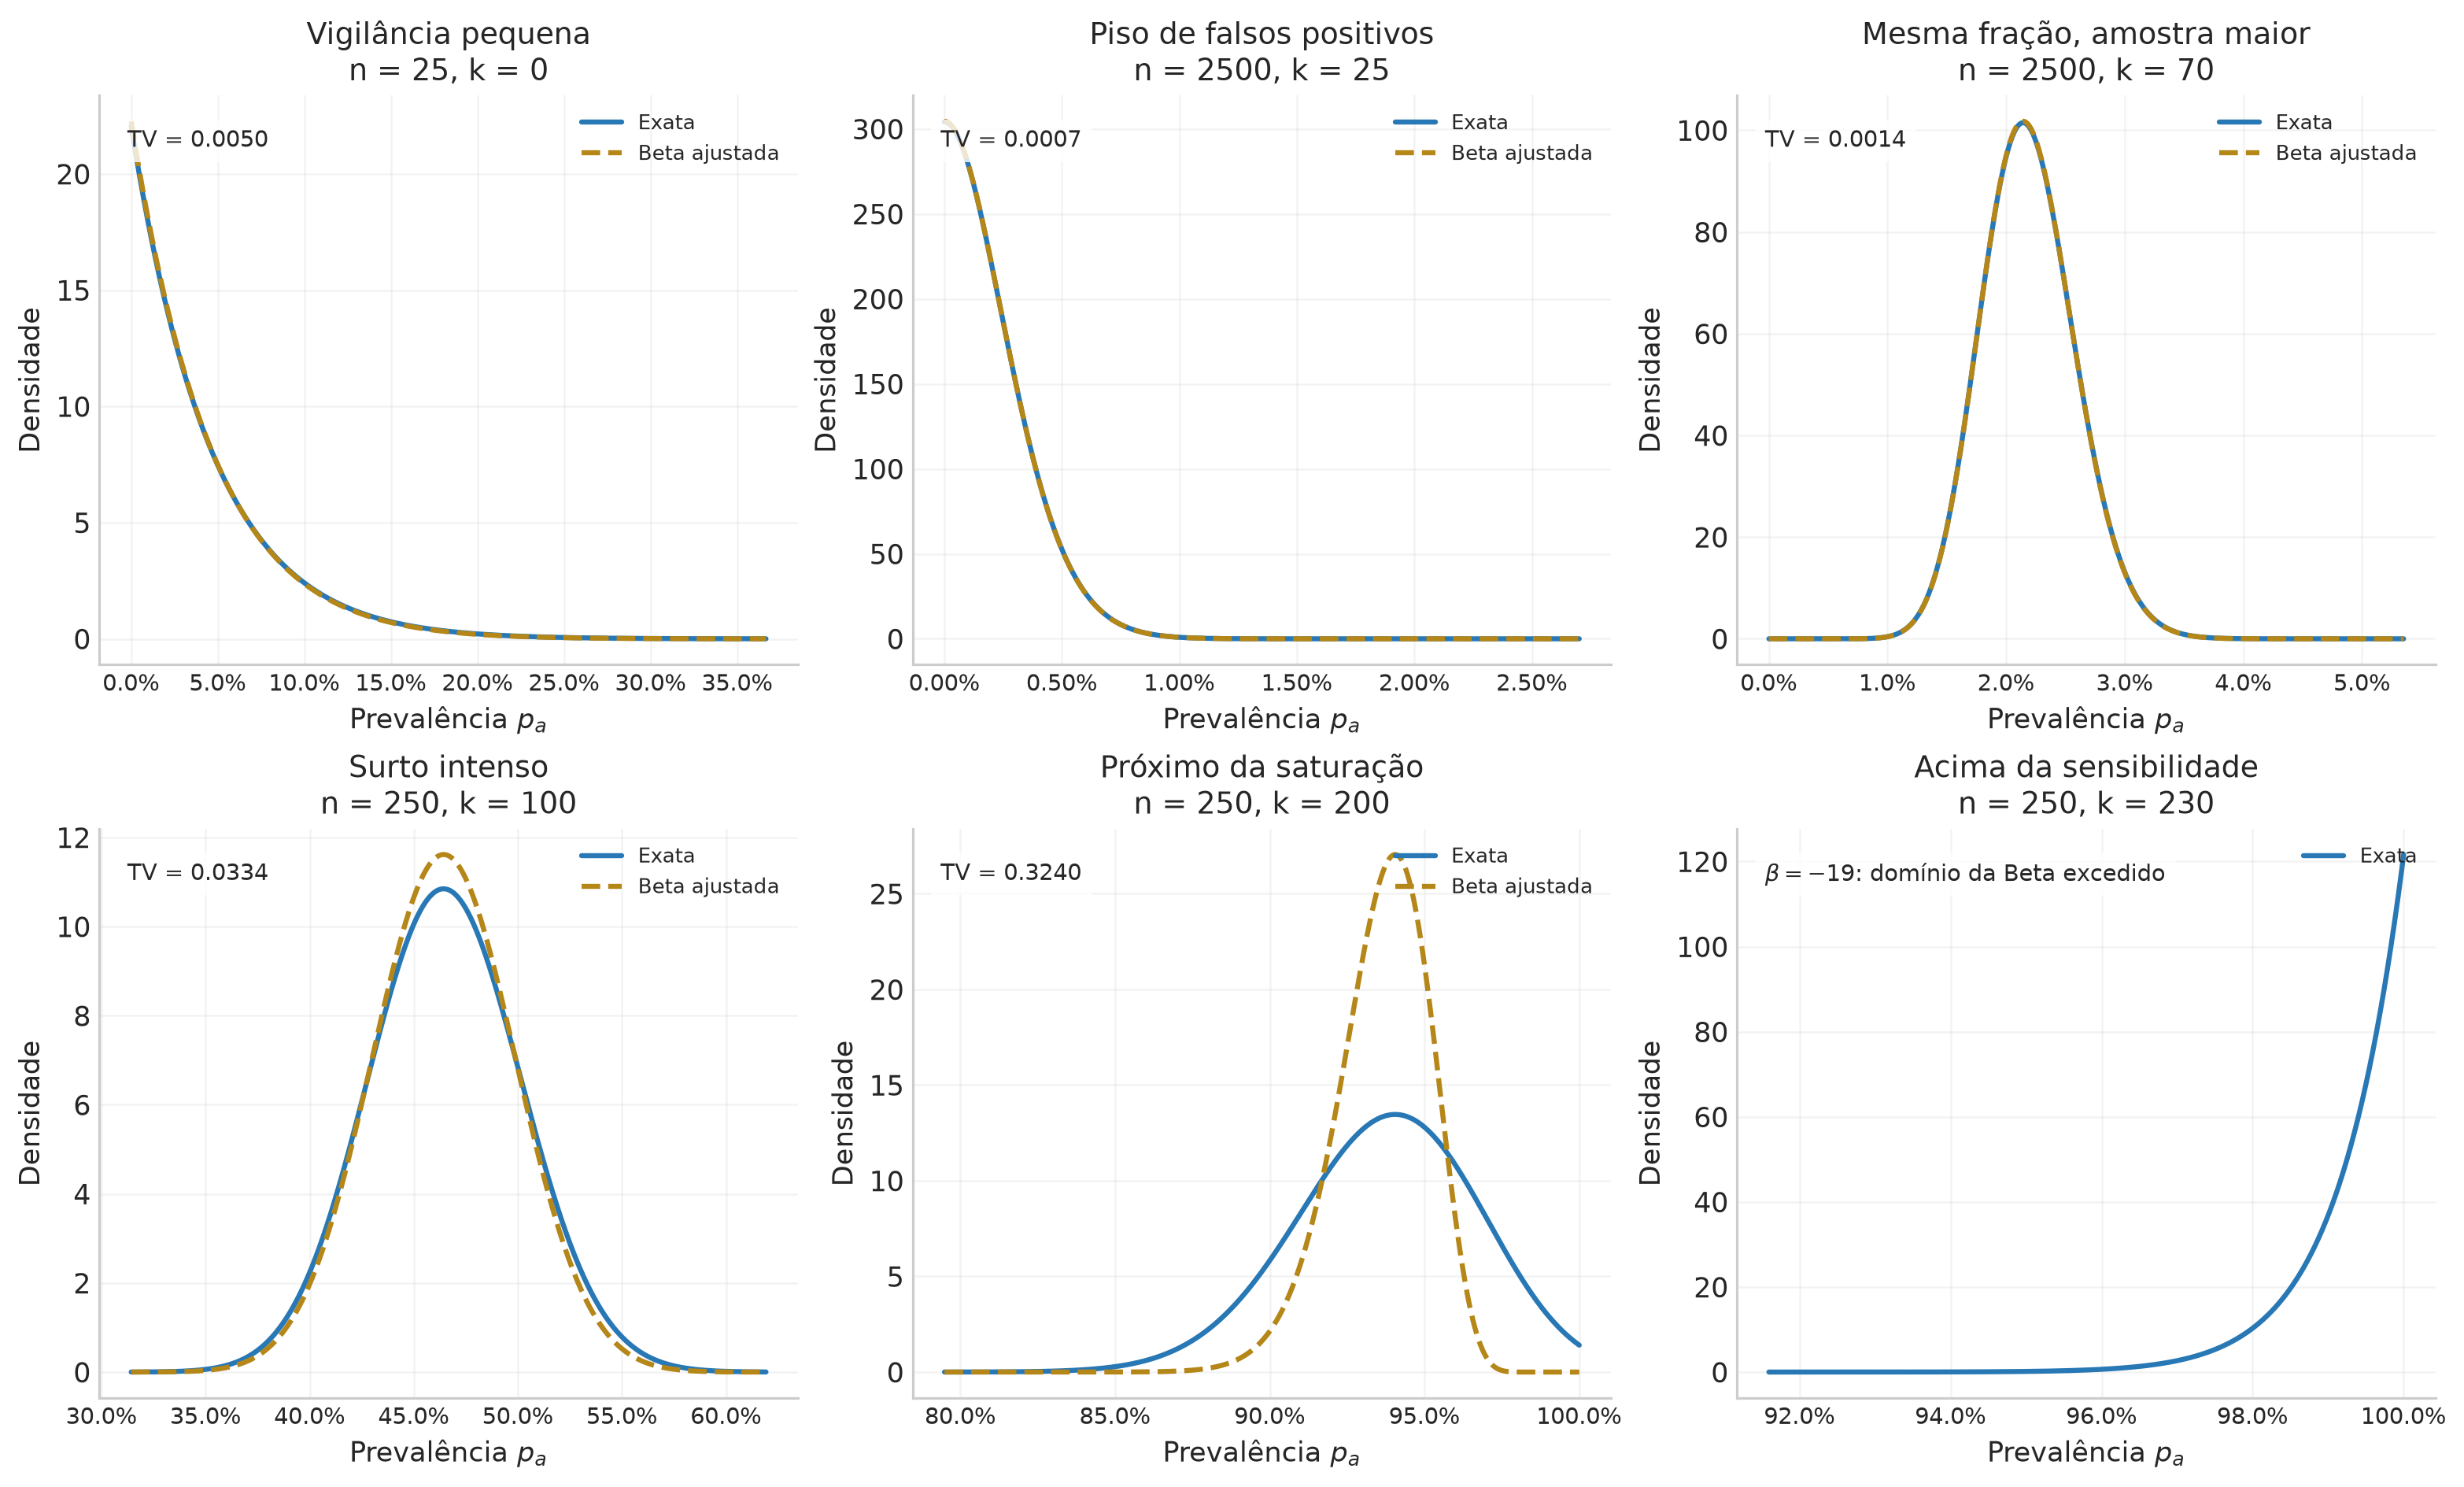

In [36]:
q6_scenarios=[
    ("Original",250,7),
    ("Vigilância pequena",25,0),
    ("Semana sem positivos",250,0),
    ("Piso de falsos positivos",2500,25),
    ("Mesma fração, amostra maior",2500,70),
    ("Surto intenso",250,100),
    ("Próximo da saturação",250,200),
    ("Acima da sensibilidade",250,230),
]
q6_cases=[]
q6_case_rows=[]
for label,n,k in q6_scenarios:
    ex=q6_exact_posterior(n,k)
    ap=q6_approx_posterior(n,k)
    tv,dc=(q6_comparison(ex,ap) if ap is not None else (np.nan,np.nan))
    q6_cases.append(dict(label=label,n=n,k=k,exact=ex,approx=ap,tv=tv,dcdf=dc))
    ci=ex["ppf"](np.array([.025,.975]))
    q6_case_rows.append([label,n,k,100*ex["mean"],100*ci[0],100*ci[1],n*q6_h-k+1,
                         100*(1-ap["mass"]) if ap else "fora do domínio",tv if ap else "fora do domínio"])
export_table("q6_c_cenarios",["Cenário","n","k","Média (%)","Q2,5 (%)","Q97,5 (%)","Beta: parâmetro b","Massa excluída (%)","TV"],
             q6_case_rows,[0,0,0,5,5,5,1,5,6])


export_table("q6_c_sintese",["n","k","Média (%)","Q2,5 (%)","Q97,5 (%)","TV"],
             [[item["n"],item["k"],100*item["exact"]["mean"],
               *list(100*item["exact"]["ppf"](np.array([.025,.975]))),
               item["tv"] if item["approx"] is not None else "fora do domínio"] for item in q6_cases],
             [0,0,4,4,4,5])

fig,axes=plt.subplots(2,3,figsize=(13.5,8.1),layout="constrained")
for ax,index in zip(axes.flat,[1,3,4,5,6,7]):
    item=q6_cases[index]; ex,ap=item["exact"],item["approx"]
    lower=max(0,float(ex["ppf"](.0001))-.02)
    upper=min(1,float(ex["ppf"](.9999))+.015)
    if ap is not None:
        lower=min(lower,max(0,float(ap["ppf"](.0001))-.02))
        upper=max(upper,min(1,float(ap["ppf"](.9999))+.015))
    p=np.linspace(lower,upper,1400)
    ax.plot(p,ex["pdf"](p),color=BLUE,label="Exata")
    if ap is not None:
        ax.plot(p,ap["pdf"](p),color=GOLD,ls="--",label="Beta ajustada")
        detail=f"TV = {item['tv']:.4f}"
    else:
        detail=r"$\beta=-19$: domínio da Beta excedido"
    ax.set(title=f"{item['label']}\nn = {item['n']}, k = {item['k']}",xlabel=r"Prevalência $p_a$",ylabel="Densidade")
    ax.text(.04,.94,detail,transform=ax.transAxes,va="top",fontsize=9,
            bbox=dict(facecolor="white",edgecolor="none",alpha=.8))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.tick_params(axis="x",labelsize=9)
    ax.legend(loc="upper right",fontsize=8)
save_figure(fig,"q6_c_cenarios")

### Duas fontes distintas de erro na expressão aproximada

O exemplo com zero positivos ajuda a separar dois efeitos. Para $n=250$, $k=0$, a Beta literal deslocada deixa cerca de **92%** da área em prevalências negativas. Depois da restrição e da normalização, sua forma na região física fica muito próxima da posterior exata: $d_{\rm TV}\simeq0{,}00114$. O problema principal nessa situação é a área que foi deslocada para fora do intervalo físico.

No cenário com $k=200$ positivos, a normalização física da Beta já é praticamente 1, mas a distância de variação total é aproximadamente **0,324**. Aqui, a diferença vem da forma aproximada da likelihood. A prevalência elevada leva $t$ para perto de 1 e aumenta o erro da aproximação no denominador. O painel abaixo percorre todas as contagens de uma amostra com $n=250$ para visualizar esses dois efeitos.

A condição para os parâmetros é

$$\alpha=k+1>0,\qquad\beta=nh-k+1>0
\quad\Longleftrightarrow\quad k<nh+1.$$

Além dessa condição algébrica, a qualidade da forma requer que a posterior ocupe valores pequenos de $t$. O crescimento da amostra reduz a incerteza; a qualidade relativa de uma aproximação também depende da região para a qual ela concentra. Por isso, uma amostra grande com prevalência elevada continua exigindo atenção à curvatura.

Por fim, $p_{\min}=f/h$ é o tamanho do deslocamento algébrico. A prevalência física admite $p_a=0$. A expressão $p_{\min}$ ganha esse nome no enunciado, mas sua função na conta é deslocar a variável da Beta.

A varredura completa está exportada em `tabelas/q6_c_varredura.csv` e `.tex`.

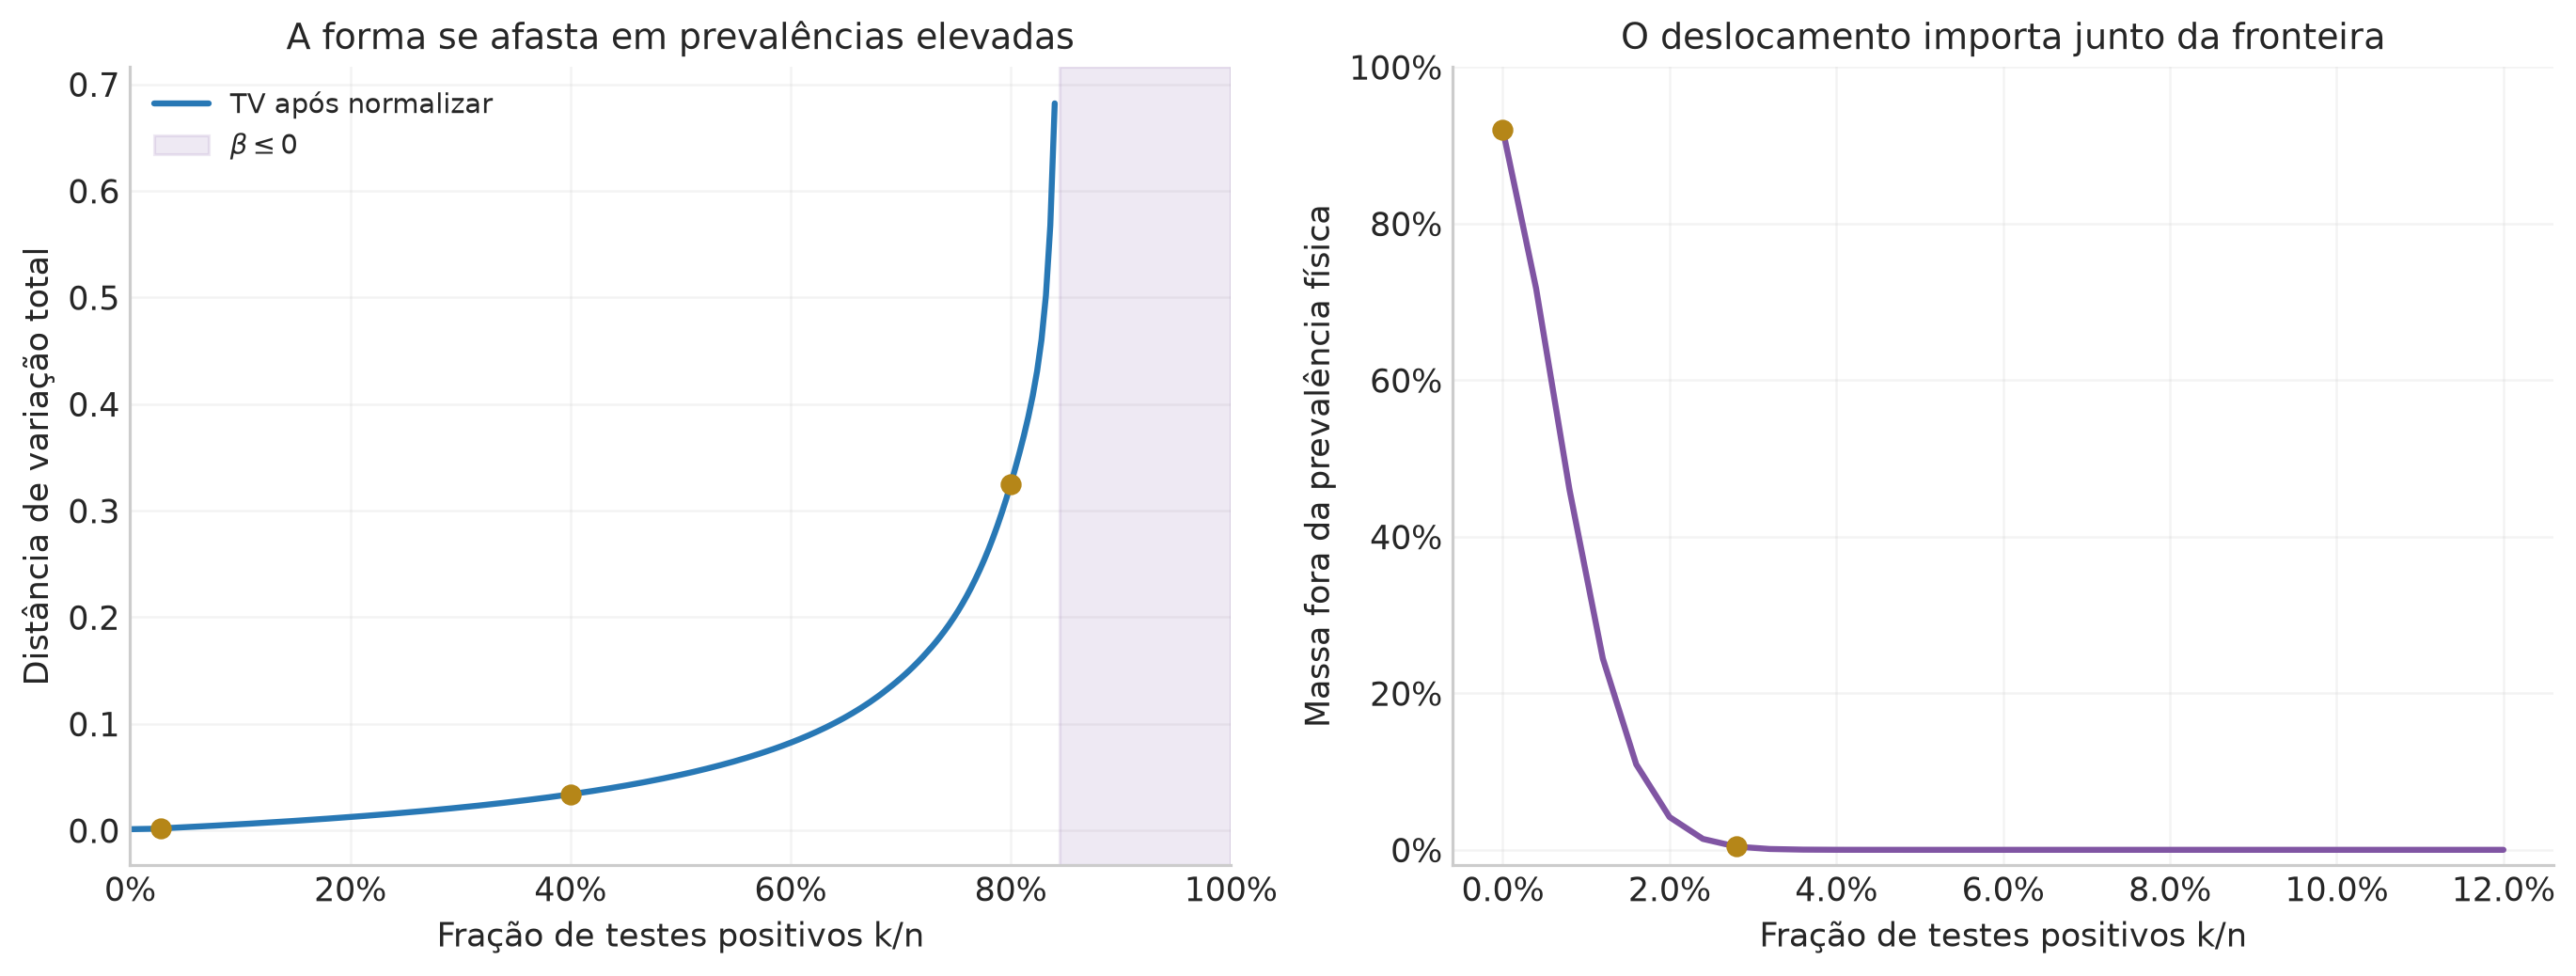

In [37]:
# Percorre as contagens sem repetir quadraturas adaptativas em cada ponto.
# A malha de quantis concentra a integração onde cada PDF possui massa.
q6_scan_k=np.arange(251)
q6_scan_tv=np.full(251,np.nan)
q6_scan_lost=np.full(251,np.nan)
for k in q6_scan_k:
    ex=q6_exact_posterior(250,int(k)); ap=q6_approx_posterior(250,int(k))
    if ap is not None:
        levels=np.linspace(1e-6,1-1e-6,1000)
        grid=np.unique(np.r_[0,1,1-q6_delta,ex["ppf"](levels),ap["ppf"](levels)])
        q6_scan_tv[k]=.5*np.trapezoid(np.abs(ex["pdf"](grid)-ap["pdf"](grid)),grid)
        q6_scan_lost[k]=1-ap["mass"]
with capture_output():
    export_table("q6_c_varredura",["k","Fração observada","TV por malha","Massa excluída"],
                 [[k,k/250,q6_scan_tv[k] if np.isfinite(q6_scan_tv[k]) else "fora do domínio",
                   q6_scan_lost[k] if np.isfinite(q6_scan_lost[k]) else "fora do domínio"] for k in q6_scan_k], [0,4,6,6])
display(Markdown("A varredura completa está exportada em `tabelas/q6_c_varredura.csv` e `.tex`."))
fig,axes=plt.subplots(1,2,figsize=(11.8,4.4),layout="constrained")
axes[0].plot(q6_scan_k/250,q6_scan_tv,color=BLUE,label="TV após normalizar")
axes[0].axvspan((250*q6_h+1)/250,1,color=PURPLE,alpha=.13,label=r"$\beta\leq0$")
axes[0].scatter([7/250,100/250,200/250],q6_scan_tv[[7,100,200]],color=GOLD,zorder=3)
axes[0].set(xlabel="Fração de testes positivos k/n",ylabel="Distância de variação total",title="A forma se afasta em prevalências elevadas",xlim=(0,1))
axes[0].legend(fontsize=9)
axes[1].plot(q6_scan_k[:31]/250,q6_scan_lost[:31],color=PURPLE)
axes[1].scatter([0,7/250],q6_scan_lost[[0,7]],color=GOLD,zorder=3)
axes[1].set(xlabel="Fração de testes positivos k/n",ylabel="Massa fora da prevalência física",title="O deslocamento importa junto da fronteira",ylim=(-.02,1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes: ax.xaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q6_c_erros_aproximacao")

### Item (d) · Duas cidades: primeiro definir a prevalência do estado

O desafio fornece uma segunda amostra de 250 testes, com $k_2=n_{{\rm yes},2}$ positivos, e deixa $k_2$, $\mathrm{pop}_1$ e $\mathrm{pop}_2$ como parâmetros. Vou manter a solução geral e depois escolher valores para ilustrá-la.

Começamos supondo que as duas cidades compõem a população que queremos resumir. Essa população pode ser um estado idealizado com duas cidades ou a união das duas cidades estudadas. Se houver outras cidades, acrescentaremos seus termos de população e prevalência ao final.

Escolher uma pessoa ao acaso nessa população leva à cidade $i$ com probabilidade proporcional ao seu tamanho. Definimos

$$w_i=\frac{\mathrm{pop}_i}{\mathrm{pop}_1+\mathrm{pop}_2},\qquad w_1+w_2=1.$$

Pela probabilidade total, a prevalência conjunta é

$$\boxed{p_E=w_1p_{a,1}+w_2p_{a,2}.}$$

Os pesos vêm das populações. Os tamanhos amostrais entram na precisão das inferências de cada cidade. Essa separação permite que uma cidade grande tenha um peso alto na prevalência estadual mesmo que ambas recebam 250 testes.

#### Construção da posterior conjunta

Assumimos os mesmos $f$ e $r$, amostras independentes condicionadas às prevalências e priors uniformes **independentes**:

$$\pi(p_{a,1},p_{a,2})=1,\qquad(p_{a,1},p_{a,2})\in[0,1]^2.$$

As prevalências podem ser distintas. A likelihood conjunta é

$$P(D_1,D_2\mid p_{a,1},p_{a,2})
=\prod_{i=1}^2\binom{n_i}{k_i}(f+hp_{a,i})^{k_i}(1-f-hp_{a,i})^{n_i-k_i}.$$

Com essas hipóteses, a normalização se separa e a posterior fatoriza:

$$p(p_{a,1},p_{a,2}\mid D_1,D_2)=p_1(p_{a,1}\mid D_1)p_2(p_{a,2}\mid D_2),$$

onde cada $p_i$ é a PDF exata do item (a), com $a_i=k_i+1$, $b_i=n_i-k_i+1$ e seu próprio fator $C_i$.

Podemos agora propagar **as duas distribuições**, conservando a incerteza de cada cidade.

### Da posterior conjunta à distribuição de p_E

Usamos a transformação $z=w_1u+w_2v$, com $u=p_{a,1}$, $v=p_{a,2}$ e $0<w_1,w_2<1$. A inversa é $v=(z-w_1u)/w_2$, e o jacobiano em módulo vale $1/w_2$. Integrando a outra coordenada,

$$\boxed{p_E(z\mid D_1,D_2)=\frac1{w_2}
\int_{L(z)}^{U(z)}p_1(u\mid D_1)
p_2\!\left(\frac{z-w_1u}{w_2}\middle|D_2\right)du,}$$

$$L(z)=\max\!\left(0,\frac{z-w_2}{w_1}\right),\qquad
U(z)=\min\!\left(1,\frac z{w_1}\right),\qquad0\leq z\leq1.$$

Os limites vêm de exigir simultaneamente $0\leq u\leq1$ e $0\leq v\leq1$. Esta é uma convolução de duas variáveis com escalas diferentes, construída com a mesma regra de transformação da questão 4.

A CDF tem uma expressão útil para conferir a integração:

$$F_E(z)=\int_0^1p_1(u)F_2\!\left(\frac{z-w_1u}{w_2}\right)du,$$

com $F_2(v)=0$ para $v\leq0$ e $F_2(v)=1$ para $v\geq1$.

Os momentos podem ser deduzidos diretamente. Pela linearidade da esperança e pela independência posterior assumida,

$$\boxed{\mathbb E[p_E\mid D]=w_1\mu_1+w_2\mu_2,\qquad
\operatorname{Var}(p_E\mid D)=w_1^2v_1+w_2^2v_2.}$$

Aqui $\mu_i=\mathbb E[p_{a,i}\mid D_i]$ e $v_i=\operatorname{Var}(p_{a,i}\mid D_i)$. Uma prior conjunta que correlacione as cidades acrescentaria $2w_1w_2\operatorname{Cov}(p_{a,1},p_{a,2}\mid D)$ à variância. A hipótese de independência deixa explícito por que esse termo se anula nesta solução.

#### Exemplo numérico declarado

Para tornar o desafio visual, escolho **apenas como ilustração**

$$k_2=2,\qquad\mathrm{pop}_1=100\,000,\qquad\mathrm{pop}_2=400\,000.$$

Assim, $w_1=0{,}2$ e $w_2=0{,}8$. Esses números completam o exemplo; a solução e o código aceitam outras contagens e populações. A primeira cidade conserva os dados originais $k_1=7$, $n_1=250$.

| Cidade | n | k | População ilustrativa | Peso | Média (%) | Q2,5 (%) | Q97,5 (%) |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| Cidade 1 | 250 | 7 | 100000 | 0,20 | 2,600219 | 0,508537 | 5,552646 |
| Cidade 2 | 250 | 2 | 400000 | 0,80 | 0,785736 | 0,025037 | 2,569158 |

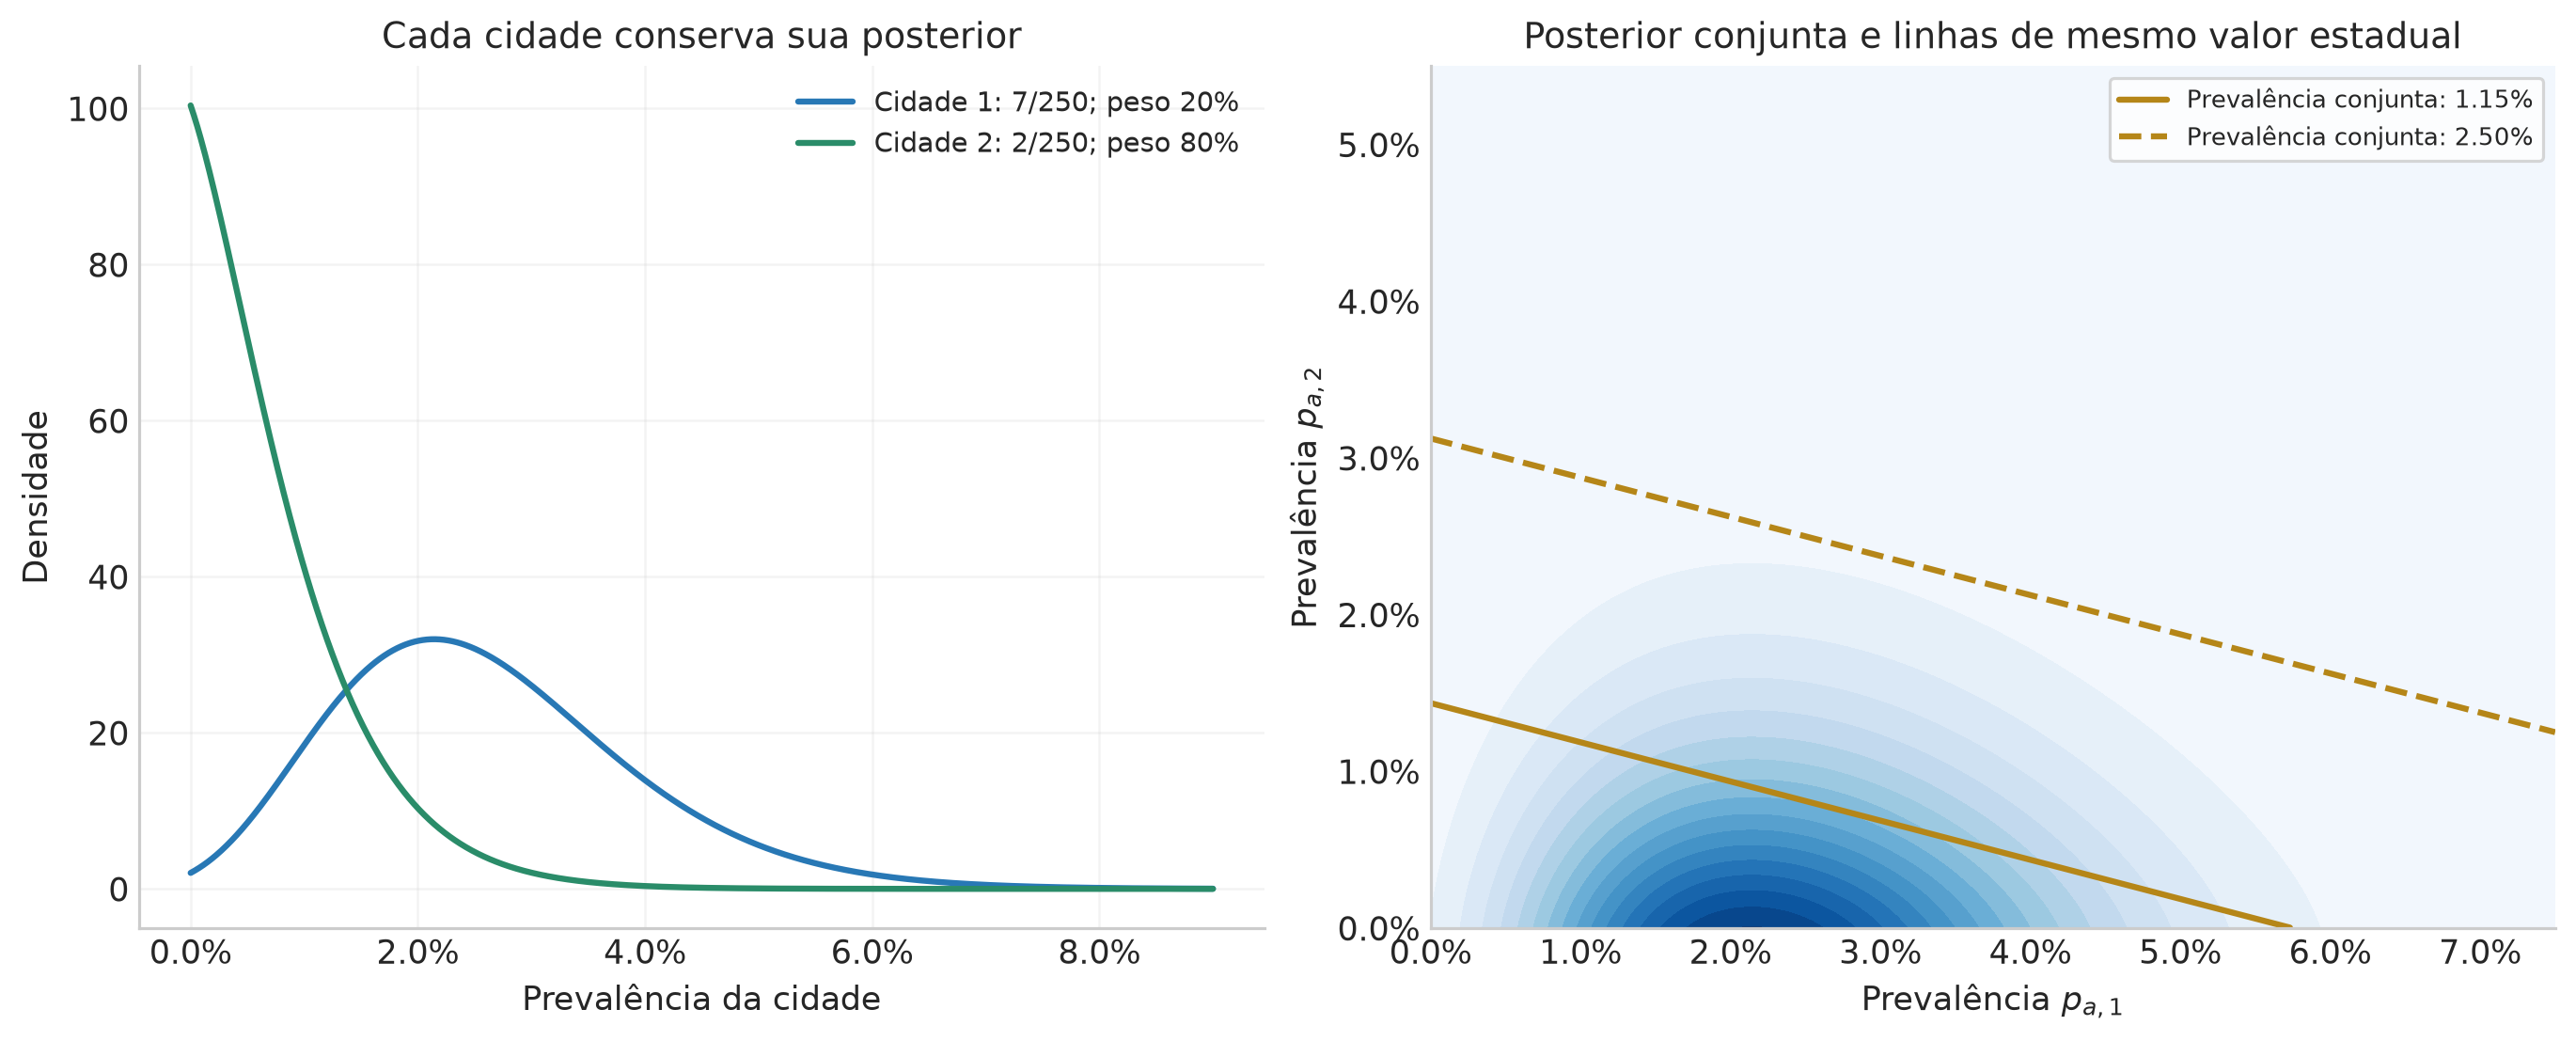

In [38]:
# Parâmetros ilustrativos do desafio. O enunciado deixa estes valores em aberto.
q6_k2=2
q6_pop1,q6_pop2=100_000,400_000
q6_w=q6_pop1/(q6_pop1+q6_pop2)
q6_city1=q6_original
q6_city2=q6_exact_posterior(250,q6_k2)
export_table("q6_d_cidades",["Cidade","n","k","População ilustrativa","Peso","Média (%)","Q2,5 (%)","Q97,5 (%)"],
             [[label,obj["n"],obj["k"],pop,w,100*obj["mean"],*list(100*obj["ppf"](np.array([.025,.975])))]
              for label,obj,pop,w in [("Cidade 1",q6_city1,q6_pop1,q6_w),("Cidade 2",q6_city2,q6_pop2,1-q6_w)]],
             [0,0,0,0,2,6,6,6])

fig,axes=plt.subplots(1,2,figsize=(11.8,4.7),layout="constrained")
p=np.linspace(0,.09,1200)
axes[0].plot(p,q6_city1["pdf"](p),color=BLUE,label="Cidade 1: 7/250; peso 20%")
axes[0].plot(p,q6_city2["pdf"](p),color=GREEN,label="Cidade 2: 2/250; peso 80%")
axes[0].set(xlabel="Prevalência da cidade",ylabel="Densidade",title="Cada cidade conserva sua posterior")
axes[0].legend(fontsize=9)
p1=np.linspace(0,.075,230);p2=np.linspace(0,.055,230)
joint=np.outer(q6_city2["pdf"](p2),q6_city1["pdf"](p1))
axes[1].contourf(p1,p2,joint,levels=18,cmap="Blues")
meanE=q6_w*q6_city1["mean"]+(1-q6_w)*q6_city2["mean"]
for z,style in [(meanE,"-"),(.025,"--")]:
    line=(z-q6_w*p1)/(1-q6_w)
    mask=(line>=0)&(line<=p2[-1])
    axes[1].plot(p1[mask],line[mask],color=GOLD,ls=style,lw=2,label=f"Prevalência conjunta: {100*z:.2f}%")
axes[1].set(xlabel=r"Prevalência $p_{a,1}$",ylabel=r"Prevalência $p_{a,2}$",title="Posterior conjunta e linhas de mesmo valor estadual")
axes[1].legend(fontsize=8,loc="upper right",facecolor="white",frameon=True)
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q6_d_cidades_conjunta")

### Calcular a convolução e conferir por outro caminho

Vamos calcular a distribuição estadual de três formas complementares, todas usando as posteriores exatas das cidades.

**Convolução em uma malha.** Para $A=w_1p_{a,1}$ e $B=w_2p_{a,2}$, calculamos a massa de cada célula por diferenças de CDF. Se a largura é $\Delta$, as massas são

$$m^A_j=F_1\!\left(\frac{(j+1)\Delta}{w_1}\right)
-F_1\!\left(\frac{j\Delta}{w_1}\right),$$

e analogamente para $B$. A massa da soma de dois índices é a convolução $\sum_jm^A_jm^B_{\ell-j}$. A FFT acelera essa soma. Usamos convolução linear com preenchimento interno, convertemos massa em densidade dividindo por $\Delta$ e refinamos a malha para conferir a precisão. Os pontos médios de cada célula somam para $(j+\ell+1)\Delta$, o que fixa o alinhamento do eixo.

**Quadratura direta.** Integramos as expressões de PDF e CDF acima em pontos selecionados, de forma independente da FFT.

**Monte Carlo posterior.** Sorteamos $p_{a,1}$ e $p_{a,2}$ de suas respectivas posteriores e calculamos $p_E=w_1p_{a,1}+w_2p_{a,2}$ a cada sorteio. Esse procedimento representa a incerteza das prevalências após os dados. O histograma deve acompanhar a convolução, com as flutuações esperadas de uma simulação finita.

| Peso cidade 1 | Peso cidade 2 | Média (%) | Desvio (%) | Q2,5 (%) | Mediana (%) | Q97,5 (%) |
| :-- | :-- | :-- | :-- | :-- | :-- | :-- |
| 0,20 | 0,80 | 1,148632 | 0,610872 | 0,300553 | 1,031466 | 2,652244 |
| 0,50 | 0,50 | 1,692977 | 0,737282 | 0,487287 | 1,614193 | 3,346705 |
| 0,80 | 0,20 | 2,237322 | 1,051373 | 0,541522 | 2,117736 | 4,613897 |

| Peso cidade 1 | Média (%) | Desvio (p.p.) | Q2,5 (%) | Q97,5 (%) |
| :-- | :-- | :-- | :-- | :-- |
| 0,20 | 1,14863 | 0,61087 | 0,30055 | 2,65224 |
| 0,50 | 1,69298 | 0,73728 | 0,48729 | 3,34670 |
| 0,80 | 2,23732 | 1,05137 | 0,54152 | 4,61390 |

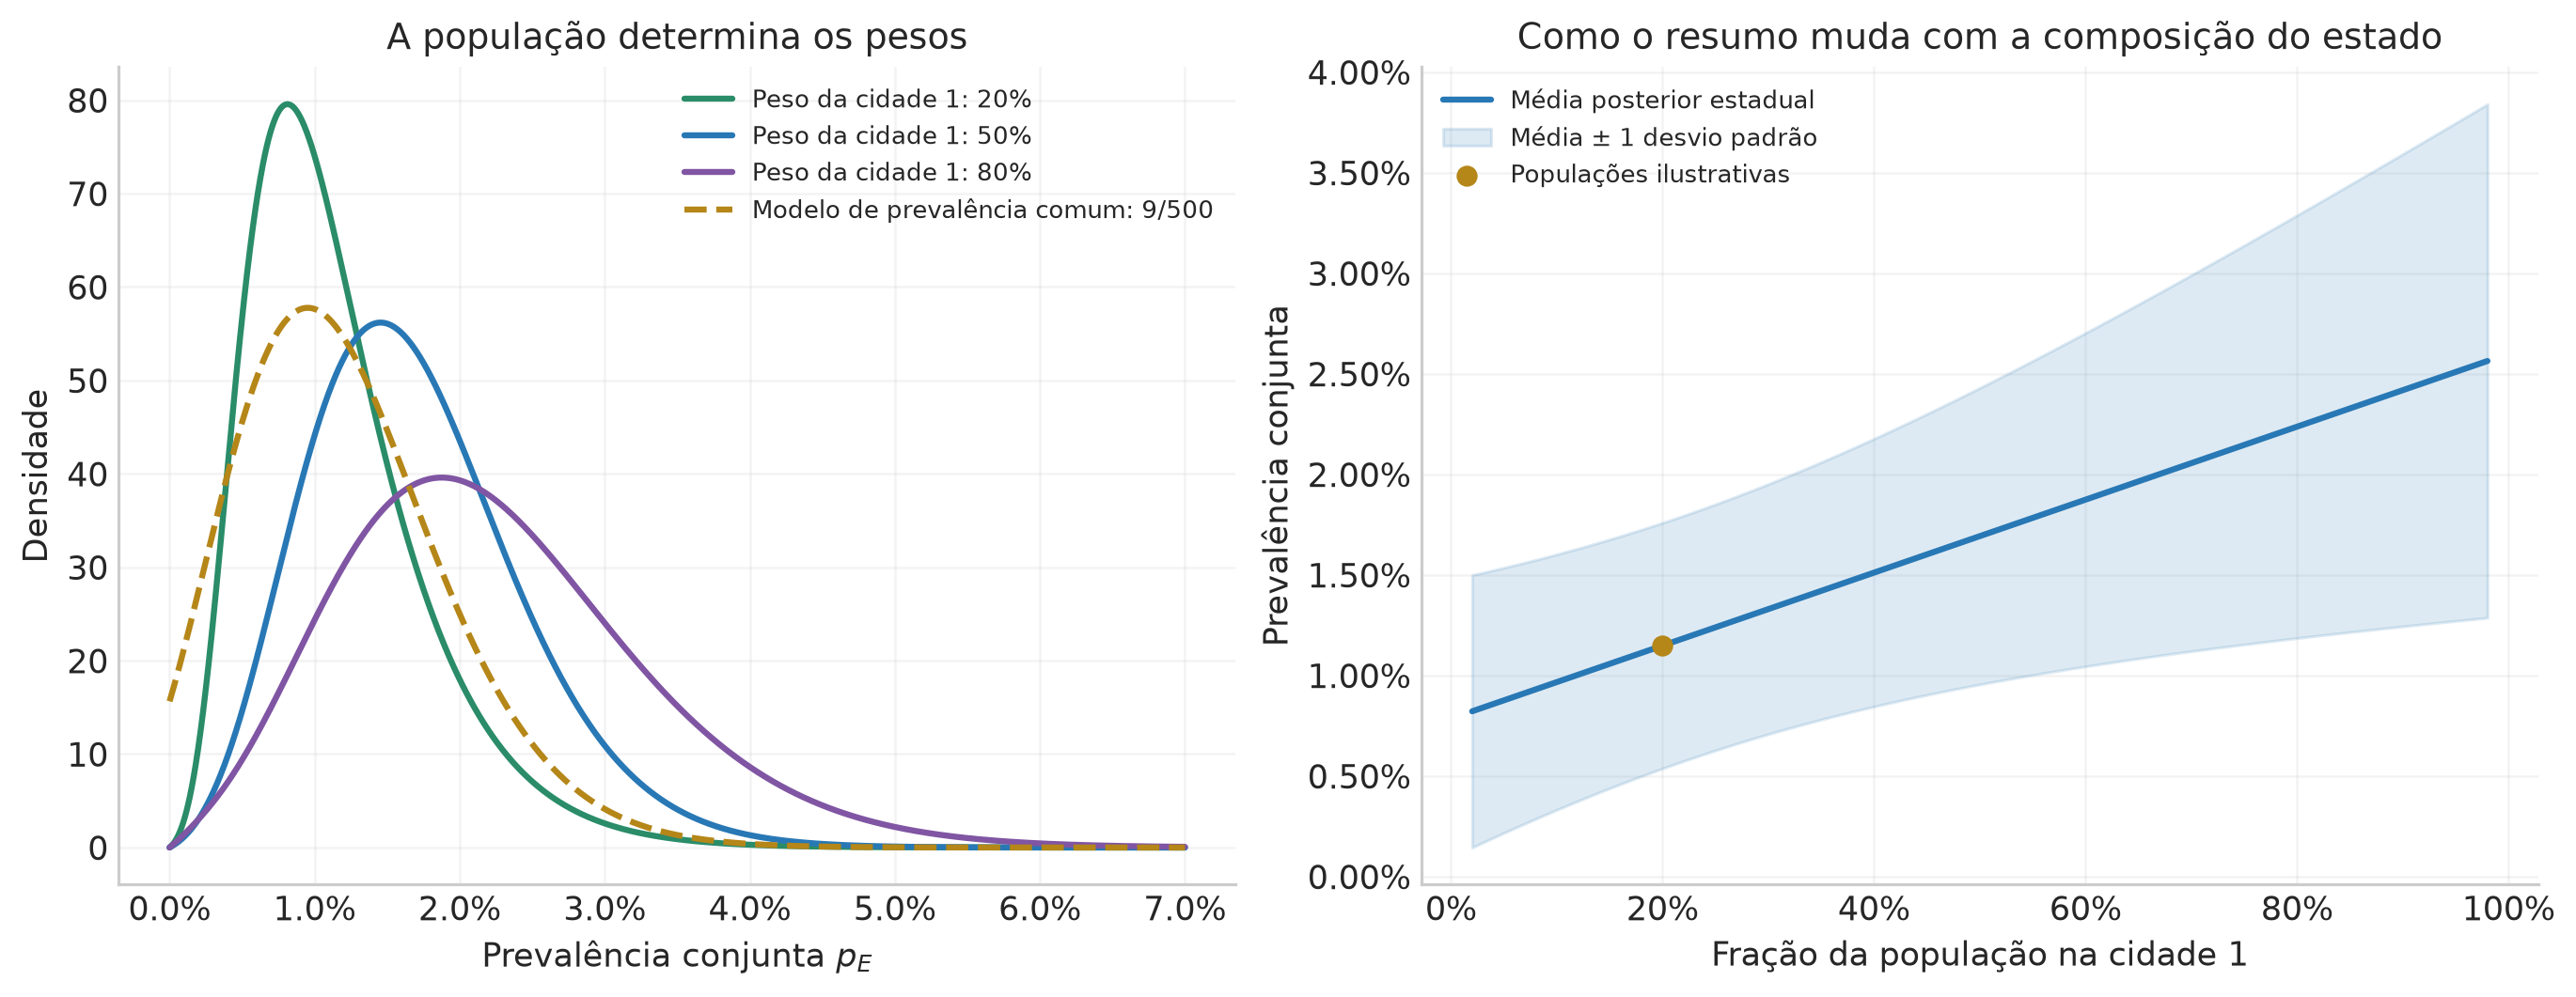

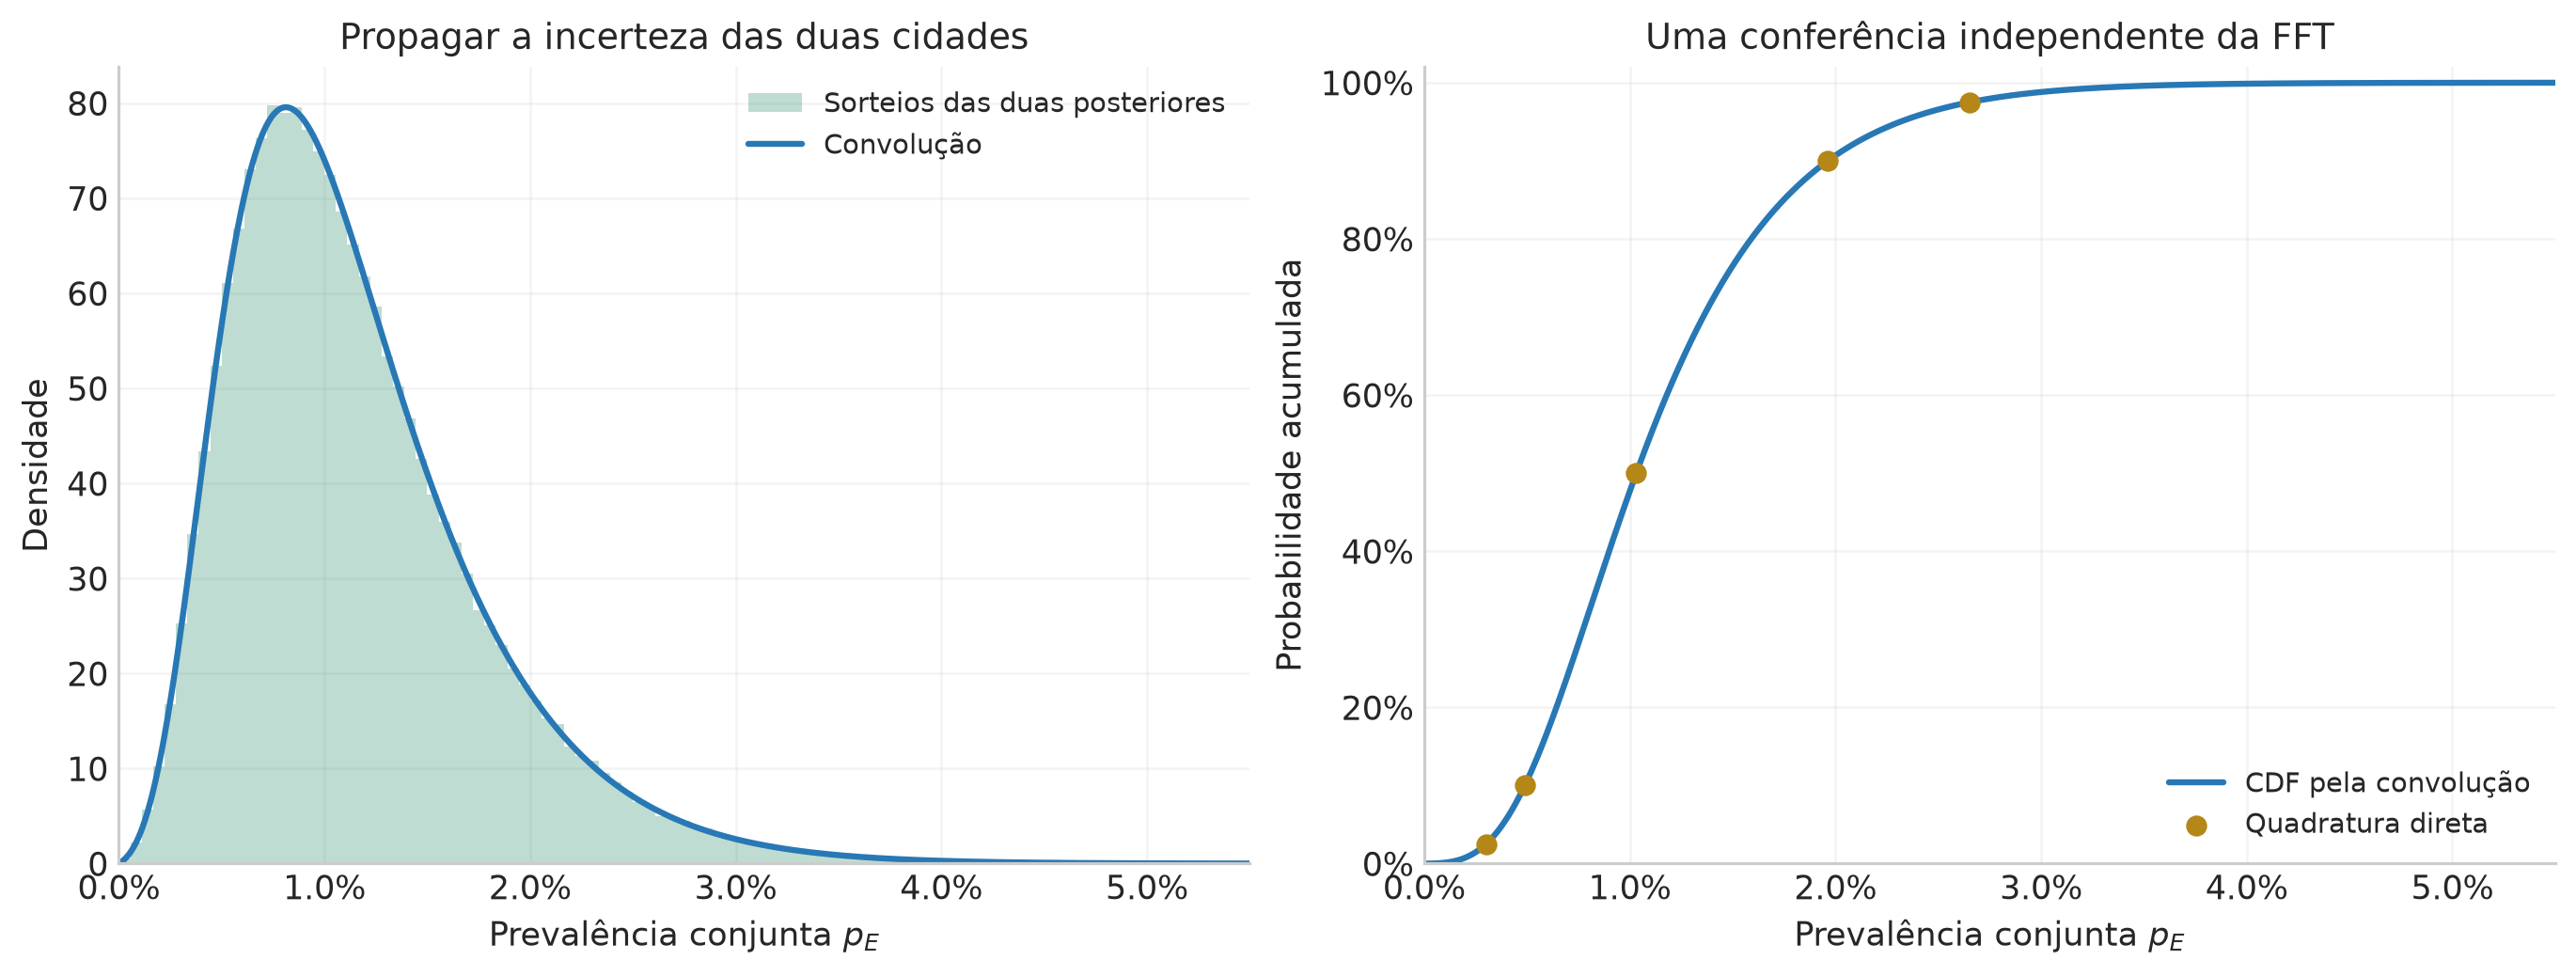

| Prevalência | PDF por quadratura | PDF por FFT | CDF por quadratura | CDF por FFT |
| :-- | :-- | :-- | :-- | :-- |
| 0,0030055 | 24,38702607 | 24,38705572 | 0,0249997024 | 0,0250000000 |
| 0,0048892 | 55,06315745 | 55,06313274 | 0,0999998634 | 0,1000000000 |
| 0,0103147 | 72,27655779 | 72,27654190 | 0,5000001951 | 0,5000000000 |
| 0,0196311 | 19,19978883 | 19,19979580 | 0,9000000739 | 0,9000000000 |
| 0,0265224 | 5,23041068 | 5,23041411 | 0,9750000271 | 0,9750000000 |

In [39]:
def q6_state_posterior(city1,city2,w1,J=100_000):
    """Convolução de massas de células; refinável por J."""
    if not 0<w1<1: raise ValueError("Escolha duas populações positivas.")
    # Alinha os dois suportes à malha. Nos exemplos, J*w1 é inteiro.
    j1=round(J*w1)
    if abs(j1/J-w1)>1e-12:
        raise ValueError("Escolha J que alinhe o peso à malha ou use a quadratura direta.")
    j2=J-j1; step=1/J
    e1=np.arange(j1+1)*step
    e2=np.arange(j2+1)*step
    m1=np.maximum(np.diff(city1["cdf"](e1/w1)),0)
    m2=np.maximum(np.diff(city2["cdf"](e2/(1-w1))),0)
    m1/=m1.sum(); m2/=m2.sum()
    masses=fftconvolve(m1,m2,mode="full")
    negative=float(-masses[masses<0].sum())
    if negative>1e-10: raise ArithmeticError("Resíduo negativo excessivo da FFT.")
    masses=np.maximum(masses,0);masses/=masses.sum()
    grid=np.arange(J+1)*step
    density=np.r_[0,masses/step,0]
    cdf=cumulative_trapezoid(density,grid,initial=0)
    density/=cdf[-1];cdf/=cdf[-1]
    mean=w1*city1["mean"]+(1-w1)*city2["mean"]
    variance=w1*w1*city1["var"]+(1-w1)**2*city2["var"]
    return dict(grid=grid,pdfgrid=density,cdfgrid=cdf,negative=negative,mean=mean,var=variance,
                pdf=lambda z:np.interp(z,grid,density,left=0,right=0),
                cdf=lambda z:np.interp(z,grid,cdf,left=0,right=1),
                ppf=lambda u:np.interp(u,cdf,grid),step=step,w=w1)

def q6_state_direct(z,city1,city2,w1):
    """PDF e CDF estaduais por quadratura adaptativa em p1."""
    w2=1-w1
    low=max(0,(z-w2)/w1);high=min(1,z/w1)
    if high<=low: return (0.,float(z>=1))
    # A parte u<low tem F2=1; a parte u>high tem F2=0.
    points=[float(v) for v in city1["ppf"](np.array([.001,.01,.1,.5,.9,.99,.999])) if low<v<high]
    pdf=quad(lambda u:float(city1["pdf"](u)*city2["pdf"]((z-w1*u)/w2)/w2),
             low,high,points=points,epsabs=1e-9,epsrel=1e-9,limit=250)[0]
    cdf=float(city1["cdf"](low))+quad(lambda u:float(city1["pdf"](u)*city2["cdf"]((z-w1*u)/w2)),
             low,high,points=points,epsabs=1e-11,epsrel=1e-9,limit=250)[0]
    return pdf,cdf

q6_states={w:q6_state_posterior(q6_city1,q6_city2,w) for w in (.2,.5,.8)}
q6_state=q6_states[q6_w]
q6_state_coarse=q6_state_posterior(q6_city1,q6_city2,q6_w,J=50_000)
q6_state_rows=[]
for w,obj in q6_states.items():
    ci=obj["ppf"](np.array([.025,.5,.975]))
    q6_state_rows.append([w,1-w,100*obj["mean"],100*np.sqrt(obj["var"]),100*ci[0],100*ci[1],100*ci[2]])
export_table("q6_d_estado",["Peso cidade 1","Peso cidade 2","Média (%)","Desvio (%)","Q2,5 (%)","Mediana (%)","Q97,5 (%)"],
             q6_state_rows,[2,2,6,6,6,6,6])


export_table("q6_d_sintese",["Peso cidade 1","Média (%)","Desvio (p.p.)","Q2,5 (%)","Q97,5 (%)"],
             [[row[0],row[2],row[3],row[4],row[6]] for row in q6_state_rows],[2,5,5,5,5])

q6_rng=np.random.default_rng(20261025)
q6_M=250_000
q6_city1_draws=q6_city1["ppf"](q6_rng.random(q6_M))
q6_city2_draws=q6_city2["ppf"](q6_rng.random(q6_M))
q6_state_draws=q6_w*q6_city1_draws+(1-q6_w)*q6_city2_draws
q6_pooled=q6_exact_posterior(500,q6_k+q6_k2)

fig,axes=plt.subplots(1,2,figsize=(11.8,4.5),layout="constrained")
p=np.linspace(0,.07,1600)
for (w,obj),color in zip(q6_states.items(),[GREEN,BLUE,PURPLE]):
    axes[0].plot(p,obj["pdf"](p),color=color,label=f"Peso da cidade 1: {w:.0%}")
axes[0].plot(p,q6_pooled["pdf"](p),ls="--",color=GOLD,label="Modelo de prevalência comum: 9/500")
axes[0].set(xlabel=r"Prevalência conjunta $p_E$",ylabel="Densidade",title="A população determina os pesos")
axes[0].legend(fontsize=8)
weights=np.linspace(.02,.98,120)
means=weights*q6_city1["mean"]+(1-weights)*q6_city2["mean"]
sds=np.sqrt(weights**2*q6_city1["var"]+(1-weights)**2*q6_city2["var"])
axes[1].plot(weights,means,color=BLUE,label="Média posterior estadual")
axes[1].fill_between(weights,means-sds,means+sds,color=BLUE,alpha=.15,label="Média ± 1 desvio padrão")
axes[1].scatter([q6_w],[q6_state["mean"]],color=GOLD,zorder=3,label="Populações ilustrativas")
axes[1].set(xlabel="Fração da população na cidade 1",ylabel="Prevalência conjunta",title="Como o resumo muda com a composição do estado")
axes[1].legend(fontsize=8)
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q6_d_prevalencia_estado")

fig,axes=plt.subplots(1,2,figsize=(11.8,4.4),layout="constrained")
# Pesos preservam a normalização global mesmo com um eixo de visualização curto.
q6_hist_edges=np.linspace(0,.055,100)
axes[0].hist(q6_state_draws,bins=q6_hist_edges,weights=np.full(q6_M,1/(q6_M*np.diff(q6_hist_edges)[0])),
             color=GREEN,alpha=.3,label="Sorteios das duas posteriores")
axes[0].plot(p,q6_state["pdf"](p),color=BLUE,label="Convolução")
axes[0].set(xlabel=r"Prevalência conjunta $p_E$",ylabel="Densidade",title="Propagar a incerteza das duas cidades",xlim=(0,.055))
axes[0].legend(fontsize=9)
axes[1].plot(p,q6_state["cdf"](p),color=BLUE,label="CDF pela convolução")
q6_zcheck=q6_state["ppf"](np.array([.025,.1,.5,.9,.975]))
q6_direct_values=np.array([q6_state_direct(z,q6_city1,q6_city2,q6_w) for z in q6_zcheck])
axes[1].scatter(q6_zcheck,q6_direct_values[:,1],color=GOLD,zorder=3,label="Quadratura direta")
axes[1].set(xlabel=r"Prevalência conjunta $p_E$",ylabel="Probabilidade acumulada",title="Uma conferência independente da FFT",xlim=(0,.055),ylim=(0,1.02))
axes[1].legend(fontsize=9)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes:ax.xaxis.set_major_formatter(PercentFormatter(1))
save_figure(fig,"q6_d_conferencia_estado")

export_table("q6_d_quadratura",["Prevalência","PDF por quadratura","PDF por FFT","CDF por quadratura","CDF por FFT"],
             [[z,vals[0],float(q6_state["pdf"](z)),vals[1],float(q6_state["cdf"](z))] for z,vals in zip(q6_zcheck,q6_direct_values)],
             [7,8,8,10,10])

### Interpretar o desafio e o modelo usado na comparação

Para as populações ilustrativas $100\,000$ e $400\,000$ e a segunda contagem escolhida $k_2=2$, a média posterior estadual é cerca de $1{,}149\%$. O cálculo usa 20% da média da primeira cidade e 80% da média da segunda; o intervalo central de credibilidade de 95% é aproximadamente $[0{,}3006\%;\ 2{,}6522\%]$, obtido da distribuição da soma ponderada.

A grade de FFT usa pesos alinhados à malha; o código documenta essa condição e permite refinar $J$. A expressão de quadratura aceita quaisquer pesos positivos que somem 1.

O gráfico também mostra o resultado de juntar $k_1+k_2=9$ positivos em $n_1+n_2=500$ testes sob **uma prevalência comum**. Essa curva corresponde à hipótese adicional $p_{a,1}=p_{a,2}$. O desafio permite prevalências distintas, por isso nossa resposta conserva os dois parâmetros e aplica a ponderação populacional ao final. As priors uniformes independentes das cidades induzem uma prior trapezoidal para a soma ponderada, triangular quando os pesos são iguais, pela própria convolução de duas uniformes. A curva com um parâmetro comum usa sua própria prior uniforme. A comparação envolve, portanto, tanto a estrutura de prevalências quanto as priors declaradas em cada modelo.

Podemos ver a diferença diretamente na esperança da contagem total:

$$\mathbb E[Y_1+Y_2\mid p_{a,1},p_{a,2}]
=(n_1+n_2)f+h(n_1p_{a,1}+n_2p_{a,2}).$$

Com $n_1=n_2$, a fração total de positivos se relaciona à média **com pesos amostrais** das prevalências. A prevalência estadual usa pesos populacionais $w_i$. Mesmo quando esses pesos coincidem, a distribuição da soma ponderada de duas prevalências inferidas deve ser construída a partir do modelo com dois parâmetros.

#### E se o estado tiver outras cidades?

Para $m$ cidades com dados, a extensão é

$$p_E=\sum_{i=1}^m w_ip_{a,i},\quad
\mathbb E[p_E\mid D]=\sum_iw_i\mu_i,\quad
\operatorname{Var}(p_E\mid D)=\sum_iw_i^2v_i,$$

sob a mesma independência posterior. A PDF pode ser obtida por convoluções sucessivas ou por sorteios independentes das posteriores.

Para um estado com uma população restante sem testes, definimos seu peso $w_R$ e prevalência $p_R$:

$$p_E=w_1p_{a,1}+w_2p_{a,2}+w_Rp_R,\qquad w_1+w_2+w_R=1.$$

O resumo de todo o estado passa a depender também de uma prior para $p_R$, de dados adicionais ou de uma hipótese de representatividade das cidades observadas. Essa formulação explicita qual informação falta e como sua incerteza entra no resultado. Para resolver o desafio com o conteúdo até o capítulo 6, bastam probabilidade total, Bayes, marginalização, transformações, convolução e Monte Carlo, todos usados acima.

| Quantidade | Valor |
| :-- | :-- |
| Chance de positivo no novo teste | 0,03184184 |
| Chance de doença após novo positivo | 0,69411384 |
| Positivos esperados em 250 novos testes | 7,96046001 |
| Positivos verdadeiros esperados | 5,52546548 |
| Falsos positivos esperados | 2,43499452 |
| Variância da contagem preditiva | 15,16236779 |

As 251 probabilidades preditivas estão exportadas em `tabelas/q6_extra_preditiva_completa.csv` e `.tex`.

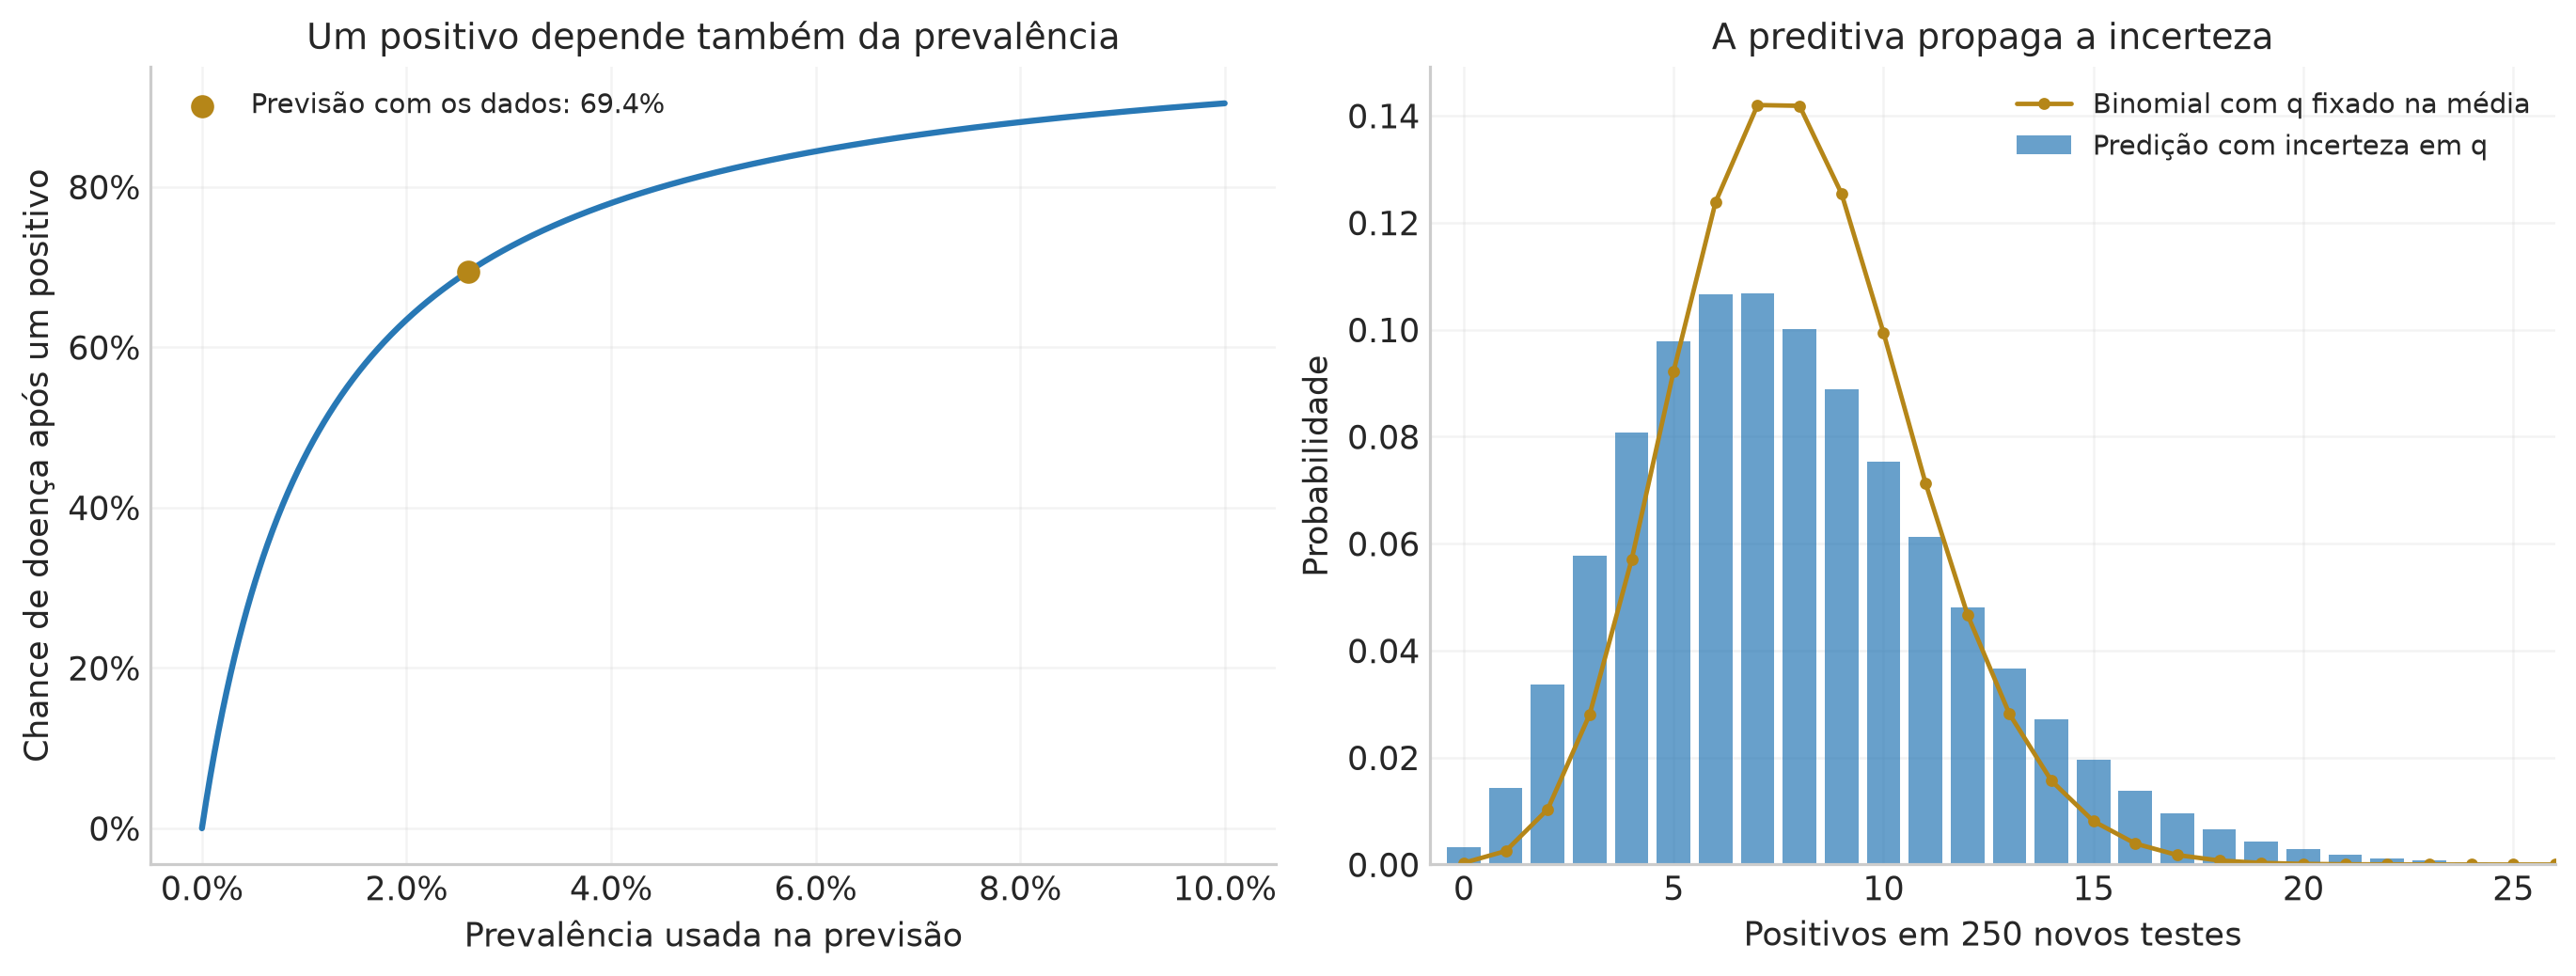

In [40]:
q6_mean_p=q6_original["mean"]
q6_mean_q=q6_f+q6_h*q6_mean_p
q6_new_ppv=q6_s*q6_mean_p/q6_mean_q
q6_m=250
q6_j=np.arange(q6_m+1)
q6_a,q6_b=q6_original["a"],q6_original["b"]
q6_future_mass=q6_beta_mass(q6_a+q6_j,q6_b+q6_m-q6_j,q6_f,q6_s)
with np.errstate(divide="ignore"):
    q6_future_log=(gammaln(q6_m+1)-gammaln(q6_j+1)-gammaln(q6_m-q6_j+1)
                   +betaln(q6_a+q6_j,q6_b+q6_m-q6_j)-betaln(q6_a,q6_b)
                   +np.log(q6_future_mass)-np.log(q6_original["mass"]))
q6_future=np.exp(q6_future_log)
q6_future_mean=q6_m*q6_mean_q
q6_qvar=q6_h**2*q6_original["var"]
q6_future_var=q6_m*(q6_mean_q*(1-q6_mean_q)-q6_qvar)+q6_m**2*q6_qvar
export_table("q6_extra_predicao",["Quantidade","Valor"],
             [["Chance de positivo no novo teste",q6_mean_q],
              ["Chance de doença após novo positivo",q6_new_ppv],
              ["Positivos esperados em 250 novos testes",q6_future_mean],
              ["Positivos verdadeiros esperados",q6_m*q6_s*q6_mean_p],
              ["Falsos positivos esperados",q6_m*q6_f*(1-q6_mean_p)],
              ["Variância da contagem preditiva",q6_future_var]],[0,8])
with capture_output():
    export_table("q6_extra_preditiva_completa",["Positivos novos","Probabilidade"],
                 list(zip(q6_j,q6_future)),[0,12])
display(Markdown("As 251 probabilidades preditivas estão exportadas em `tabelas/q6_extra_preditiva_completa.csv` e `.tex`."))
fig,axes=plt.subplots(1,2,figsize=(11.8,4.4),layout="constrained")
p=np.linspace(0,.1,1000)
axes[0].plot(p,q6_s*p/(q6_f+q6_h*p),color=BLUE)
axes[0].scatter([q6_mean_p],[q6_new_ppv],color=GOLD,s=45,zorder=3,
                label=f"Previsão com os dados: {q6_new_ppv:.1%}")
axes[0].set(xlabel="Prevalência usada na previsão",ylabel="Chance de doença após um positivo",title="Um positivo depende também da prevalência")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=9)
axes[1].bar(q6_j,q6_future,color=BLUE,alpha=.7,label="Predição com incerteza em q")
axes[1].plot(q6_j,binom.pmf(q6_j,q6_m,q6_mean_q),"o-",color=GOLD,ms=3,lw=1.5,label="Binomial com q fixado na média")
axes[1].set(xlabel="Positivos em 250 novos testes",ylabel="Probabilidade",title="A preditiva propaga a incerteza",xlim=(-.8,26))
axes[1].legend(fontsize=9)
save_figure(fig,"q6_extra_predicao")